<a href="https://colab.research.google.com/github/Vukhanhvan09/Nghien_cuu_feature_selection/blob/main/%C4%90%E1%BB%93_%C3%A1n_li%C3%AAn_ng%C3%A0nh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **A. Khám phá và tiền xử lý dữ liệu**

In [2]:
!pip install -q python-calamine

In [3]:
import os
import json
import zipfile
from pathlib import Path
from functools import partial
from itertools import combinations
from time import perf_counter
import numpy as np
import pandas as pd

# 3. Trực quan hóa và hiển thị
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# 4. Phân tích thống kê
from scipy.stats import spearmanr

# 5. Chia dữ liệu và Cross-Validation
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    cross_val_score
)
# 6. Tiền xử lý và xây dựng pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# 7. Mô hình
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, Lasso

# 8. Lựa chọn đặc trưng
from sklearn.feature_selection import (
    SelectKBest,
    f_regression,
    mutual_info_regression
)

# 9. Chỉ số đánh giá
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    get_scorer
)

# 10. Lưu và tải mô hình
import joblib

# 11. Google Colab
from google.colab import drive

# 12. Cấu hình chung
RANDOM_STATE = 42
N_JOBS = 1

RESULTS_DIR = Path("ket_qua_feature_selection")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Thư mục lưu các biểu đồ của Chương 3
EDA_FIGURE_DIR = RESULTS_DIR / "eda_figures"
EDA_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def save_eda_figure(fig, filename):
    """Lưu hình và hiển thị trong notebook."""
    fig.tight_layout()

    fig.savefig(
        EDA_FIGURE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

In [5]:
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/FeatureSelection/online+retail+ii.zip'

Mounted at /content/drive


In [6]:
extract_path = '/content/online_retail_ii'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Đã giải nén thành công!")

Đã giải nén thành công!


In [7]:
zip_path = '/content/drive/MyDrive/FeatureSelection/online+retail+ii.zip'

extract_path = '/content/online_retail_ii'

file_path = '/content/online_retail_ii/online_retail_II.xlsx'

## **I. Khám phá dữ liệu**

### 1.Đọc và tích hợp dữ liệu

In [8]:
df_2009 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010",
    engine="calamine"
)

print("Kích thước:", df_2009.shape)

df_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011",
    engine="calamine"
)

print("Kích thước:", df_2010.shape)

df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)
print("Kích thước dữ liệu:", df.shape)
df.head()

Kích thước: (525461, 8)
Kích thước: (541910, 8)
Kích thước dữ liệu: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Dữ liệu gồm hai giai đoạn 2009–2010 và 2010–2011. Sau khi tích hợp, thu được 1.067.371 dòng và 8 cột. Dữ liệu chứa thông tin về hóa đơn, sản phẩm, thời gian, số lượng, giá bán, khách hàng và quốc gia, phù hợp làm cơ sở để phân tích hành vi mua hàng. Tuy nhiên, chất lượng dữ liệu cần được kiểm tra trước khi thực hiện Feature Engineering.

### 2.Khám phá cấu trúc dữ liệu

In [9]:
df.info()
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [10]:
df.describe()


,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [11]:
df.describe(include="object")

,Invoice,StockCode,Description,Country
count,1067371,1067371,1062989,1067371
unique,53628,5305,5698,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1350,5829,5918,981330


Các thuộc tính có kiểu dữ liệu phù hợp với nội dung, đặc biệt **InvoiceDate** ở dạng thời gian và **Quantity**, **Price** ở dạng số. Thống kê mô tả cho thấy **Quantity**
và **Price** có độ biến động lớn, xuất hiện một số giá trị âm và rất lớn cần được kiểm tra. Customer ID và Description cũng chưa đầy đủ dữ liệu và sẽ được phân tích ở bước kiểm tra chất lượng dữ liệu.

### 3.Chất lượng dữ liệu

In [12]:
missing = df.isnull().sum()

missing_percent = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_table = pd.DataFrame({
    "Missing": missing,
    "Percentage": missing_percent
})

missing_table

,Missing,Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [13]:
df["Customer ID"].isnull().sum()

np.int64(243007)

 **Customer ID**  thiếu 22,77% dữ
liệu, đây là vấn đề quan trọng vì cột này dùng để xác định khách hàng. **Description** chỉ thiếu 0,41% trong khi các cột còn lại không có giá trị thiếu.


Có 243.007 giao dịch thiếu Customer ID, cho thấy một phần dữ liệu chưa xác định được khách hàng và cần được xem xét trước khi xây dựng đặc trưng khách hàng.

In [14]:
print("Số dòng trùng:", df.duplicated().sum())

df[df.duplicated()].head()

Số dòng trùng: 34335


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


Có 34,335 dòng trùng hoàn toàn, nếu giữ nguyên có thể sai lệch các thống kê về hành vi mua hàng. Vì vậy cần xử lý dữ liệu trùng trước khi xây dựng Feature

In [15]:
df["Quantity"].describe()

,Quantity
count,1.067371e+06
mean,9.938898e+00
std,1.727058e+02
min,-8.099500e+04
25%,1.000000e+00
50%,3.000000e+00
75%,1.000000e+01
max,8.099500e+04


In [16]:
print("Quantity <= 0:",
      (df["Quantity"] <= 0).sum())

print("Quantity < 0:",
      (df["Quantity"] < 0).sum())

print("Quantity = 0:",
      (df["Quantity"] == 0).sum())

Quantity <= 0: 22950
Quantity < 0: 22950
Quantity = 0: 0


In [17]:
df["Price"].describe()

,Price
count,1.067371e+06
mean,4.649388e+00
std,1.235531e+02
min,-5.359436e+04
25%,1.250000e+00
50%,2.100000e+00
75%,4.150000e+00
max,3.897000e+04


In [18]:
print("Price <= 0:",
      (df["Price"] <= 0).sum())

print("Price < 0:",
      (df["Price"] < 0).sum())

print("Price = 0:",
      (df["Price"] == 0).sum())

Price <= 0: 6207
Price < 0: 5
Price = 0: 6202


Có 22.950 dòng Quantity âm và 6.207 dòng Price ≤ 0. Đây là các giá trị bất thường đối với giao dịch bán hàng thông thường và cần được kiểm tra thêm, đặc biệt trong mối liên hệ với các invoice bị hủy.

In [19]:
df["Amount"]= df['Quantity'] * df['Price']
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Amount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [20]:
df[["Quantity", "Price", "Amount"]].describe(
    percentiles=[
        .01, .05, .25, .50, .75, .95, .99
    ]
)

,Quantity,Price,Amount
count,1.067371e+06,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00,1.806987e+01
std,1.727058e+02,1.235531e+02,2.924202e+02
min,-8.099500e+04,-5.359436e+04,-1.684696e+05
1%,-3.000000e+00,2.100000e-01,-7.950000e+00
5%,1.000000e+00,4.200000e-01,8.500000e-01
25%,1.000000e+00,1.250000e+00,3.750000e+00
50%,3.000000e+00,2.100000e+00,9.900000e+00
75%,1.000000e+01,4.150000e+00,1.770000e+01
95%,3.000000e+01,9.950000e+00,5.950000e+01


In [21]:
for col in ["Quantity", "Price", "Amount"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"{col}:")
    print("  Lower bound:", lower)
    print("  Upper bound:", upper)
    print("  Số outlier:", len(outliers))
    print("  Tỷ lệ:", round(len(outliers) / len(df) * 100, 2), "%")
    print()

Quantity:
  Lower bound: -12.5
  Upper bound: 23.5
  Số outlier: 116489
  Tỷ lệ: 10.91 %

Price:
  Lower bound: -3.1000000000000005
  Upper bound: 8.5
  Số outlier: 68105
  Tỷ lệ: 6.38 %

Amount:
  Lower bound: -17.175000000000004
  Upper bound: 38.62500000000001
  Số outlier: 90922
  Tỷ lệ: 8.52 %



IQR phát hiện outlier ở Quantity (10,91%), Price (6,38%) và Amount (8,52%). Các giá trị cực đoan chưa được xem là lỗi ngay vì có thể phản ánh hành vi mua hàng thực tế, do đó cần đánh giá nguyên nhân trước khi xử lý.

### 4.Kiểm tra giao dịch

In [22]:
df["Invoice"].astype(str).str.startswith("C").value_counts()

df["IsCancelled"] = (
    df["Invoice"].astype(str).str.startswith("C")
)
df["IsCancelled"].value_counts()

,count
IsCancelled,
False,1047877
True,19494


In [23]:
df["Invoice"].isnull().sum()

np.int64(0)

In [24]:
df["Invoice"].nunique()

53628

In [25]:
cancelled_invoice = (
    df["Invoice"].astype(str).str.startswith("C")
)

print(
    "Số dòng giao dịch bị hủy:",
    cancelled_invoice.sum()
)

print(
    "Số invoice bị hủy:",
    df.loc[cancelled_invoice, "Invoice"].nunique()
)

Số dòng giao dịch bị hủy: 19494
Số invoice bị hủy: 8292


Dữ liệu có 53.628 invoice khác nhau và không có giá trị thiếu ở cột Invoice. Có 19.494 dòng giao dịch được đánh dấu hủy (Invoice bắt đầu bằng "C"), tương ứng với 8.292 invoice bị hủy. Điều này cho thấy một invoice có thể gồm nhiều dòng sản phẩm; các giao dịch hủy cần được xem xét riêng vì có thể ảnh hưởng đến việc tính toán giá trị mua hàng của khách hàng.

### 5.khám phá khách hàng

In [26]:
print("Số Customer ID duy nhất:",
      df["Customer ID"].nunique())

print(
    df.groupby("Customer ID")["Invoice"].nunique().describe()
)

Số Customer ID duy nhất: 5942
count    5942.000000
mean        7.552339
std        15.972262
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max       510.000000
Name: Invoice, dtype: float64


Số invoice khác nhau giữa các khách hàng có sự chênh lệch đáng kể. Trung vị là 4 invoice/khách hàng, trong khi một số khách hàng có tới 510 invoice, cho thấy mức độ hoạt động của khách hàng không đồng đều.

In [27]:
invoice_customer = (
    df.groupby("Invoice")["Customer ID"]
      .nunique(dropna=True)
)

print(
    "Invoice có nhiều Customer ID:",
    (invoice_customer > 1).sum()
)

Invoice có nhiều Customer ID: 0


In [28]:
customer_products = (
    df.groupby("Customer ID")["StockCode"]
      .nunique()
)

customer_products.describe()

,StockCode
count,5942.000000
mean,81.324806
std,116.397649
min,1.000000
25%,18.000000
50%,44.000000
75%,102.000000
max,2557.000000


In [29]:
customer_spending = (
    df.groupby("Customer ID")["Amount"]
      .sum()
)

customer_spending.describe()

,Amount
count,5942.000000
mean,2801.799459
std,13973.922553
min,-25111.090000
25%,325.097500
50%,843.970000
75%,2182.005000
max,598215.220000


Tổng giá trị mua hàng có sự chênh lệch rất lớn giữa các khách hàng. Trung vị là 843,97, trong khi giá trị lớn nhất lên tới 598.215,22, cho thấy phân bố chi tiêu lệch mạnh và xuất hiện một số khách hàng có giá trị mua rất cao. Ngoài ra, giá trị âm cần được xem xét cùng với các giao dịch hủy trong bước xử lý dữ liệu.

In [30]:
customer_spending.quantile(
    [.01, .05, .25, .50, .75, .95, .99]
)

,Amount
0.01,-26.7795
0.05,94.5435
0.25,325.0975
0.50,843.9700
0.75,2182.0050
0.95,9087.2900
0.99,26484.1446


### 6.Khám phá thời gian

In [31]:
print(df["InvoiceDate"].dtype)

print("Min date:",
      df["InvoiceDate"].min())

print("Max date:",
      df["InvoiceDate"].max())

datetime64[ns]
Min date: 2009-12-01 07:45:00
Max date: 2011-12-09 12:50:00


In [32]:
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["DayOfWeek"] = df["InvoiceDate"].dt.dayofweek
df["Hour"] = df["InvoiceDate"].dt.hour
print("Số giao dịch theo năm:")
print(df["Year"].value_counts().sort_index())

print("\nSố giao dịch theo tháng:")
print(df["Month"].value_counts().sort_index())

print("\nSố giao dịch theo ngày trong tuần:")
print(df["DayOfWeek"].value_counts().sort_index())

print("\nSố giao dịch theo giờ:")
print(df["Hour"].value_counts().sort_index())

Số giao dịch theo năm:
Year
2009     45228
2010    522714
2011    499429
Name: count, dtype: int64

Số giao dịch theo tháng:
Month
1      66702
2      57095
3      78259
4      63973
5      72353
6      76857
7      72901
8      68590
9      92317
10    119840
11    162726
12    135758
Name: count, dtype: int64

Số giao dịch theo ngày trong tuần:
DayOfWeek
0    189084
1    196626
2    185051
3    203149
4    153803
5       402
6    139256
Name: count, dtype: int64

Số giao dịch theo giờ:
Hour
6         41
7       1127
8      15985
9      68324
10     93248
11    121780
12    159846
13    150308
14    141513
15    135309
16     94055
17     57549
18     16991
19      9089
20      2205
21         1
Name: count, dtype: int64


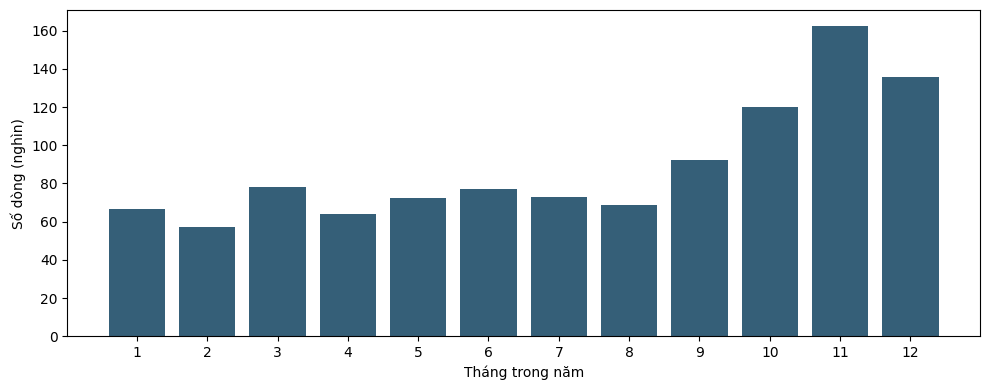

In [33]:
eda_month_counts = df["Month"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(eda_month_counts.index, eda_month_counts / 1000, color="#355F78")
ax.set(
    xlabel="Tháng trong năm",
    ylabel="Số dòng (nghìn)",
    xticks=range(1, 13)
)
fig.tight_layout()
fig.savefig("hinh_3_2_phan_bo_theo_thang.png", dpi=300, bbox_inches="tight")
plt.show()

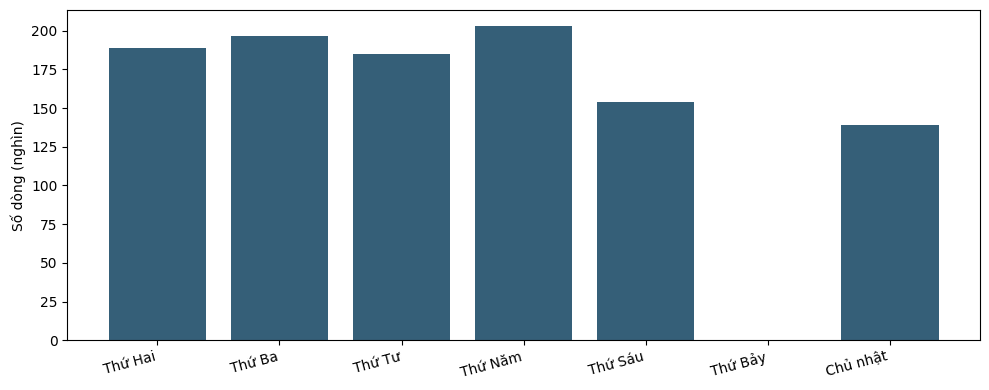

In [34]:
eda_day_counts = df["DayOfWeek"].value_counts().reindex(range(7), fill_value=0)
eda_day_labels = [
    "Thứ Hai", "Thứ Ba", "Thứ Tư", "Thứ Năm",
    "Thứ Sáu", "Thứ Bảy", "Chủ nhật"
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(eda_day_labels, eda_day_counts / 1000, color="#355F78")
ax.set(xlabel="", ylabel="Số dòng (nghìn)")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout()
fig.savefig("hinh_3_3_phan_bo_theo_ngay_trong_tuan.png",
            dpi=300, bbox_inches="tight")
plt.show()

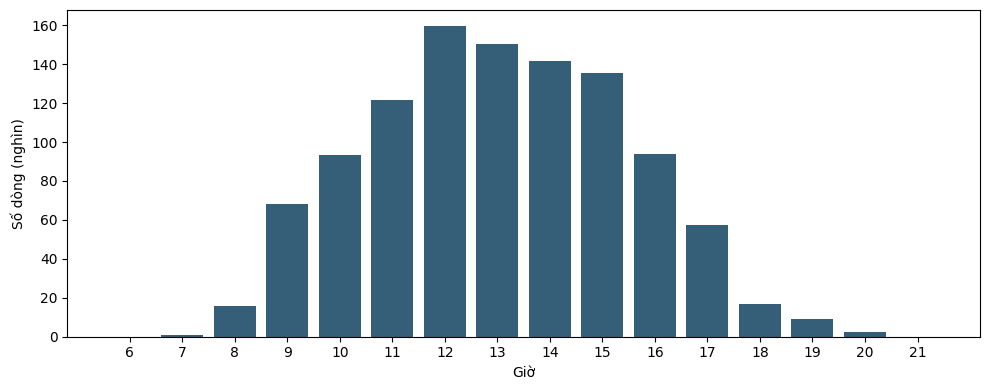

In [35]:
eda_hour_counts = df["Hour"].value_counts().reindex(range(6, 22), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(eda_hour_counts.index, eda_hour_counts / 1000, color="#355F78")
ax.set(xlabel="Giờ", ylabel="Số dòng (nghìn)", xticks=range(6, 22))
fig.tight_layout()
fig.savefig("hinh_3_4_phan_bo_theo_gio.png", dpi=300, bbox_inches="tight")
plt.show()

Dữ liệu có lịch sử giao dịch từ 01/12/2009 đến 09/12/2011, đủ để phân tích sự thay đổi hành vi mua hàng theo thời gian. Số giao dịch có sự biến động rõ rệt theo tháng và ngày trong tuần, đặc biệt tăng cao vào các tháng cuối năm, cho thấy khả năng tồn tại yếu tố mùa vụ. Giao dịch cũng tập trung trong một số khung giờ nhất định. Đây là cơ sở để xây dựng các Temporal Features như thời điểm mua hàng, tần suất mua và khoảng cách giữa các lần mua, từ đó hỗ trợ dự đoán tổng giá trị mua hàng của khách hàng trong 30 ngày tiếp theo.

In [36]:
df["InvoiceDate"].isnull().sum()

np.int64(0)

In [37]:
df["InvoiceDate"].describe()

,InvoiceDate
count,1067371
mean,2011-01-02 21:13:55.394028544
min,2009-12-01 07:45:00
25%,2010-07-09 09:46:00
50%,2010-12-07 15:28:00
75%,2011-07-22 10:23:00
max,2011-12-09 12:50:00


In [38]:
df["InvoiceDate"].dt.date.nunique()

604

In [39]:
invoice_date = (
    df.groupby("Invoice")["InvoiceDate"]
      .nunique()
)

print(
    "Invoice có nhiều InvoiceDate:",
    (invoice_date > 1).sum()
)

Invoice có nhiều InvoiceDate: 83


InvoiceDate không có giá trị thiếu và dữ liệu ghi nhận giao dịch trong 604 ngày, trải dài từ 01/12/2009 đến 09/12/2011. Đây là nguồn dữ liệu quan trọng để tổng hợp giao dịch theo khoảng thời gian dự đoán và xây dựng các Temporal Features phục vụ dự đoán tổng giá trị mua hàng trong 30 ngày tiếp theo. Ngoài ra, có 83 invoice xuất hiện với nhiều giá trị thời gian, cần được kiểm tra khi xử lý dữ liệu theo khoảng thời gian dự đoán.

### 7.Khám phá sản phẩm

In [40]:
df["StockCode"].nunique()

5305

In [41]:
df["StockCode"].value_counts().head(20)

,count
StockCode,
85123A,5829
22423,4424
85099B,4216
21212,3318
20725,3259
84879,2960
47566,2768
21232,2747
22197,2549


In [42]:
df["Description"].isnull().sum()

np.int64(4382)

In [43]:
df["Description"].nunique()

5698

In [44]:
df["Description"].str.len().describe()

,Description
count,1.062985e+06
mean,2.667740e+01
std,5.461788e+00
min,1.000000e+00
25%,2.300000e+01
50%,2.700000e+01
75%,3.100000e+01
max,3.500000e+01


In [45]:
stock_description = (
    df.groupby("StockCode")["Description"]
      .nunique(dropna=True)
)

stock_description.describe()

print(
    "StockCode có nhiều Description:",
    (stock_description > 1).sum()
)

StockCode có nhiều Description: 1232


Dữ liệu có 5.305 mã sản phẩm khác nhau, cho thấy danh mục sản phẩm khá đa dạng và hành vi lựa chọn sản phẩm giữa các khách hàng có thể khác nhau. Một số sản phẩm xuất hiện với tần suất cao, cho thấy mức độ tập trung nhất định trong giao dịch. Ngoài ra, Description còn thiếu dữ liệu và có 1.232 StockCode có nhiều Description khác nhau, vì vậy cần kiểm tra và cân nhắc cách chuẩn hóa thông tin sản phẩm trước khi sử dụng Description để xây dựng Feature.

### 8.Khám phá quốc gia

In [46]:
df["Country"].nunique()

43

In [47]:
df["Country"].value_counts().head(20)

,count
Country,
United Kingdom,981330
EIRE,17866
Germany,17624
France,14330
Netherlands,5140
Spain,3811
Switzerland,3189
Belgium,3123
Portugal,2620


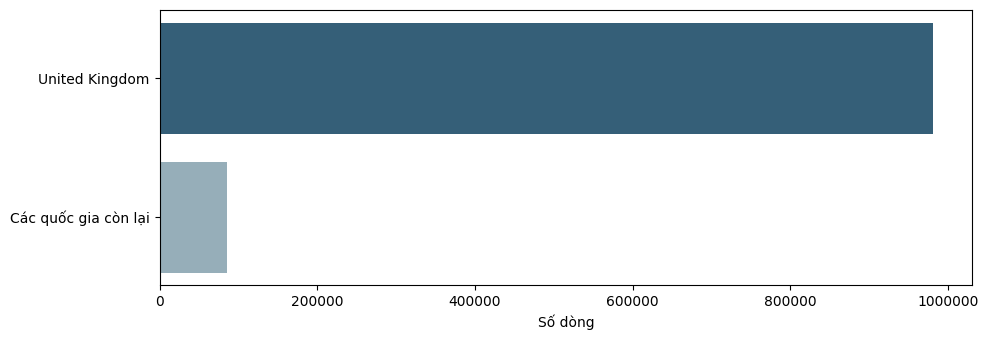

In [48]:
eda_uk_count = df["Country"].eq("United Kingdom").sum()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(
    ["United Kingdom", "Các quốc gia còn lại"],
    [eda_uk_count, len(df) - eda_uk_count],
    color=["#355F78", "#96AEB9"]
)
ax.invert_yaxis()
ax.set_xlabel("Số dòng")
ax.ticklabel_format(axis="x", style="plain")
fig.tight_layout()
fig.savefig("hinh_3_5_muc_tap_trung_theo_quoc_gia.png",
            dpi=300, bbox_inches="tight")
plt.show()

Dữ liệu gồm 43 quốc gia, cho thấy có sự đa dạng về mặt địa lý. Tuy nhiên, giao dịch tập trung rất mạnh tại United Kingdom (981.330 giao dịch), trong khi các quốc gia khác có số lượng thấp hơn đáng kể. Country có thể được xem xét như một Feature để phản ánh yếu tố địa lý, sau đó Feature Selection sẽ đánh giá mức độ đóng góp của đặc trưng này đối với việc dự đoán Future Spending theo khoảng thời gian dự đoán.

### 9.Correlation / Dependency

In [49]:
numeric_cols = [
    "Quantity",
    "Price",
    "Amount"
]

correlation = df[numeric_cols].corr()

correlation

,Quantity,Price,Amount
Quantity,1.000000,-0.001319,0.762623
Price,-0.001319,1.000000,0.061029
Amount,0.762623,0.061029,1.000000


In [50]:
numeric_cols = ["Quantity", "Price", "Amount"]
correlation = df[numeric_cols].corr()
correlation

,Quantity,Price,Amount
Quantity,1.000000,-0.001319,0.762623
Price,-0.001319,1.000000,0.061029
Amount,0.762623,0.061029,1.000000


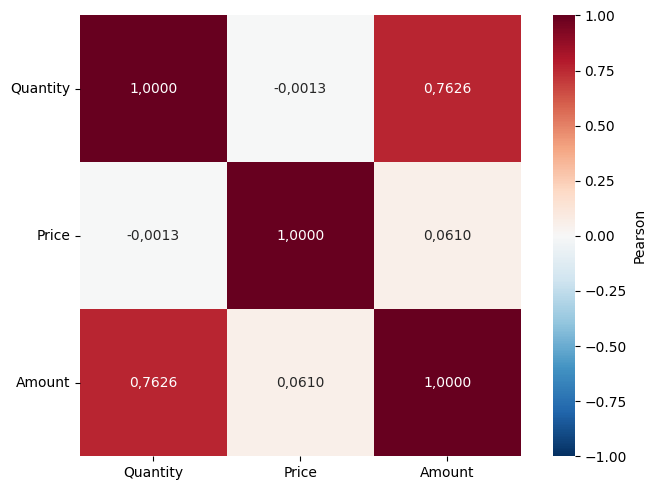

In [51]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=correlation.map(lambda x: f"{x:.4f}".replace(".", ",")),
    fmt="", cmap="RdBu_r", vmin=-1, vmax=1,
    square=True, cbar_kws={"label": "Pearson"}, ax=ax
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig("hinh_3_6_tuong_quan_pearson.png",
            dpi=300, bbox_inches="tight")
plt.show()

Quantity và Amount có tương quan khá cao (0,763), phù hợp với mối quan hệ Amount = Quantity × Price. Trong khi đó, Quantity và Price gần như không có tương quan tuyến tính (-0,001), còn Price và Amount có tương quan yếu (0,061). Kết quả này giúp nhận diện mối quan hệ giữa các biến và là cơ sở tham khảo khi xây dựng và lựa chọn Feature.

### 10.Tổng kết EDA

Qua quá trình khám phá dữ liệu, bộ dữ liệu **Online Retail II** đã được kiểm tra về cấu trúc, chất lượng dữ liệu, giao dịch, khách hàng, thời gian, sản phẩm và quốc gia.

EDA cho thấy dữ liệu tồn tại một số vấn đề cần xử lý trước khi xây dựng Feature, gồm:

* **Thiếu Customer ID:** một số giao dịch không xác định được khách hàng, trong khi đồ án cần xây dựng đặc trưng ở cấp độ khách hàng.
* **Duplicate:** tồn tại các bản ghi trùng lặp, có thể làm sai lệch kết quả tổng hợp giao dịch.
* **Quantity ≤ 0 và Cancelled Invoice:** xuất hiện các giao dịch có dấu hiệu hủy/trả hàng, cần được phân biệt với giao dịch mua hàng thông thường.
* **Price ≤ 0:** xuất hiện các giá trị giá không hợp lệ hoặc bất thường, cần kiểm tra và xử lý.
* **Outlier:** Quantity và Amount có một số giá trị rất lớn. Các giá trị này không được loại bỏ máy móc vì có thể phản ánh hành vi mua hàng thực tế.
* **Dữ liệu theo thời gian:** InvoiceDate cần được chuẩn hóa để phục vụ xây dựng đặc trưng thời gian và phân chia dữ liệu quá khứ – tương lai.

### Kết luận

Các phát hiện trên là cơ sở để thực hiện **tiền xử lý dữ liệu**. Mục tiêu của bước tiếp theo là tạo ra một tập dữ liệu **sạch, nhất quán và phù hợp với bài toán**, đồng thời bảo toàn những thông tin có ý nghĩa về hành vi khách hàng.

Sau khi dữ liệu được làm sạch, dữ liệu sẽ được chuyển sang **Feature Engineering** để xây dựng các đặc trưng **RFM, Temporal và Behavioral** phục vụ cho bước **Feature Selection** và dự đoán **Future Spending**.


## **II. Tiền xử lý dữ liệu**

## 1.Tạo bản sao dữ liệu

Tạo một bản sao của dataset sau EDA để thực hiện tiền xử lý mà không làm thay đổi dữ liệu gốc.

In [52]:
df_clean = df.copy()
print("Kích thước dữ liệu gốc:       ", df.shape)
print("Kích thước df_clean:          ", df_clean.shape)

Kích thước dữ liệu gốc:        (1067371, 14)
Kích thước df_clean:           (1067371, 14)


## 2.Loại bỏ các bản ghi trùng lặp

In [53]:
duplicate_count = df_clean.duplicated().sum()

print("Số bản ghi trùng lặp:", duplicate_count)
print("Tỷ lệ duplicate: {:.2f}%".format(
    duplicate_count / len(df_clean) * 100
))

Số bản ghi trùng lặp: 34335
Tỷ lệ duplicate: 3.22%


EDA cho thấy dataset tồn tại các bản ghi trùng lặp hoàn toàn. Nếu giữ lại, cùng một giao dịch có thể được tính nhiều lần khi tổng hợp dữ liệu và xây dựng các đặc trưng hành vi khách hàng.

Do đó, các bản ghi trùng lặp hoàn toàn được loại bỏ để mỗi giao dịch chỉ được xem xét một lần trong các bước xử lý tiếp theo.

In [54]:
rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

duplicates_removed = rows_before - len(df_clean)

print("Số dòng trước khi xử lý :", rows_before)
print("Số duplicate đã loại bỏ :", duplicates_removed)
print("Số dòng sau khi xử lý   :", len(df_clean))

Số dòng trước khi xử lý : 1067371
Số duplicate đã loại bỏ : 34335
Số dòng sau khi xử lý   : 1033036


In [55]:
# Kiểm tra duplicate còn lại
remaining_duplicates = df_clean.duplicated().sum()

print("Số duplicate còn lại:", remaining_duplicates)
print("Số dòng hiện tại:", len(df_clean))

Số duplicate còn lại: 0
Số dòng hiện tại: 1033036


## 3.Xử lý Customer ID thiếu

In [56]:
missing_customer_id = df_clean["Customer ID"].isna().sum()
missing_customer_pct = missing_customer_id / len(df_clean) * 100

print("Số giao dịch thiếu Customer ID:", missing_customer_id)
print("Tỷ lệ thiếu Customer ID: {:.2f}%".format(missing_customer_pct))

Số giao dịch thiếu Customer ID: 235151
Tỷ lệ thiếu Customer ID: 22.76%


In [57]:
rows_before = len(df_clean)

df_clean = df_clean.dropna(subset=["Customer ID"]).copy()

rows_removed = rows_before - len(df_clean)

print("Số dòng trước khi xử lý :", rows_before)
print("Số dòng thiếu Customer ID đã loại bỏ :", rows_removed)
print("Số dòng sau khi xử lý   :", len(df_clean))

Số dòng trước khi xử lý : 1033036
Số dòng thiếu Customer ID đã loại bỏ : 235151
Số dòng sau khi xử lý   : 797885


Customer ID là thuộc tính cần thiết để xác định giao dịch thuộc về khách hàng nào. Vì mục tiêu của đồ án là phân tích hành vi và xây dựng các đặc trưng ở cấp độ khách hàng, những giao dịch không có Customer ID không thể được gán cho một khách hàng cụ thể. Do đó, các giao dịch thiếu Customer ID được loại bỏ.

In [58]:
remaining_missing_customer_id = df_clean["Customer ID"].isna().sum()

print("Số Customer ID còn thiếu:", remaining_missing_customer_id)
print("Số dòng hiện tại:", len(df_clean))

Số Customer ID còn thiếu: 0
Số dòng hiện tại: 797885


Kết quả kiểm tra cho thấy không còn giao dịch thiếu Customer ID, xác nhận bước xử lý đã được thực hiện thành công.

## 4.Giao dịch không phải purchase



### 4.1 Xác định Cancelled Invoice

Trong dataset, các hóa đơn có mã Invoice bắt đầu bằng ký tự C được đánh dấu là giao dịch bị hủy. Các giao dịch này cần được phân biệt với giao dịch mua hàng thông thường để tránh đưa giá trị của giao dịch hủy vào quá trình tổng hợp hành vi khách hàng.

In [59]:
cancelled_mask = df_clean["Invoice"].astype(str).str.startswith("C")

cancelled_count = cancelled_mask.sum()
cancelled_pct = cancelled_count / len(df_clean) * 100

print("Số giao dịch Cancelled:", cancelled_count)
print("Tỷ lệ Cancelled: {:.2f}%".format(cancelled_pct))

Số giao dịch Cancelled: 18390
Tỷ lệ Cancelled: 2.30%


In [60]:
negative_quantity_mask = df_clean["Quantity"] < 0

negative_quantity_count = negative_quantity_mask.sum()

print("Số giao dịch có Quantity < 0:",
      negative_quantity_count)

Số giao dịch có Quantity < 0: 18390


### 4.2 Kiểm tra mối quan hệ Cancelled và Quantity < 0

In [61]:
# Bảng kiểm tra mối quan hệ
cancelled_quantity_check = pd.crosstab(
    cancelled_mask,
    negative_quantity_mask
)

cancelled_quantity_check.index = [
    "Không Cancelled",
    "Cancelled"
]

cancelled_quantity_check.columns = [
    "Quantity >= 0",
    "Quantity < 0"
]

print("Mối quan hệ giữa Cancelled Invoice và Quantity âm:")
display(cancelled_quantity_check)


# Kiểm tra tỷ lệ Quantity âm trong Cancelled
cancelled_negative = (
    cancelled_mask & negative_quantity_mask
).sum()

cancelled_positive_or_zero = (
    cancelled_mask & ~negative_quantity_mask
).sum()

print("\nCancelled + Quantity < 0 :", cancelled_negative)
print("Cancelled + Quantity >= 0:", cancelled_positive_or_zero)

print(
    "Tỷ lệ Cancelled có Quantity < 0: {:.2f}%".format(
        cancelled_negative / cancelled_mask.sum() * 100
    )
)

Mối quan hệ giữa Cancelled Invoice và Quantity âm:


,Quantity >= 0,Quantity < 0
Không Cancelled,779495,0
Cancelled,0,18390



Cancelled + Quantity < 0 : 18390
Cancelled + Quantity >= 0: 0
Tỷ lệ Cancelled có Quantity < 0: 100.00%


### 4.3 Loại bỏ Cancelled

In [62]:
rows_before = len(df_clean)

df_clean = df_clean.loc[~cancelled_mask].copy()

cancelled_removed = rows_before - len(df_clean)

print("Số dòng trước khi xử lý :", rows_before)
print("Số giao dịch Cancelled đã loại bỏ :", cancelled_removed)
print("Số dòng sau khi xử lý   :", len(df_clean))

Số dòng trước khi xử lý : 797885
Số giao dịch Cancelled đã loại bỏ : 18390
Số dòng sau khi xử lý   : 779495


### 4.4 Kiểm tra sau xử lý

In [63]:
cancelled_remaining = (
    df_clean["Invoice"].astype(str).str.startswith("C")
).sum()

negative_quantity_remaining = (
    df_clean["Quantity"] < 0
).sum()

print("Số Cancelled còn lại:", cancelled_remaining)
print("Số Quantity < 0 còn lại:", negative_quantity_remaining)

Số Cancelled còn lại: 0
Số Quantity < 0 còn lại: 0


Kết quả kiểm tra cho thấy các giao dịch được xác định là Cancelled đều có Quantity < 0. Điều này cho thấy trong dataset hiện tại, trạng thái hóa đơn bị hủy có mối quan hệ rõ ràng với các giao dịch có số lượng âm.

Do đó, việc loại bỏ các giao dịch Cancelled đồng thời loại bỏ được các giao dịch có Quantity < 0 trong dữ liệu này.

### 4.5 Kiểm tra Price < 0

In [64]:
# Kiểm tra các giao dịch có Price < 0
negative_price_mask = df_clean["Price"] < 0

negative_price_count = negative_price_mask.sum()
negative_price_pct = negative_price_count / len(df_clean) * 100

print("Số giao dịch có Price < 0:", negative_price_count)
print("Tỷ lệ Price < 0: {:.2f}%".format(negative_price_pct))

Số giao dịch có Price < 0: 0
Tỷ lệ Price < 0: 0.00%


## 5.Kiểm tra Price = 0

Kiểm tra các giao dịch có giá bằng 0 để xác định đây có phải là dữ liệu không hợp lệ hay là các giao dịch đặc biệt cần được giữ lại.


In [65]:
zero_price_mask = df_clean["Price"] == 0

zero_price_count = zero_price_mask.sum()
zero_price_pct = zero_price_count / len(df_clean) * 100

print("Số giao dịch có Price = 0:", zero_price_count)
print("Tỷ lệ Price = 0: {:.2f}%".format(zero_price_pct))

Số giao dịch có Price = 0: 70
Tỷ lệ Price = 0: 0.01%


In [66]:
# Xem các giao dịch có Price = 0
df_zero_price = df_clean[df_clean["Price"] == 0].copy()

df_zero_price.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Amount,IsCancelled,Year,Month,DayOfWeek,Hour
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom,0.0,False,2009,12,2,13
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom,0.0,False,2009,12,3,11
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom,0.0,False,2009,12,0,16
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom,0.0,False,2009,12,1,15
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom,0.0,False,2009,12,1,15
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,2009-12-15 13:49:00,0.0,15070.0,United Kingdom,0.0,False,2009,12,1,13
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,2009-12-18 14:22:00,0.0,18071.0,United Kingdom,0.0,False,2009,12,4,14
47126,493761,79320,FLAMINGO LIGHTS,24,2010-01-06 14:54:00,0.0,14258.0,United Kingdom,0.0,False,2010,1,2,14
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,2010-01-08 10:43:00,0.0,12417.0,Belgium,0.0,False,2010,1,4,10
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,2010-01-15 12:43:00,0.0,16858.0,United Kingdom,0.0,False,2010,1,4,12


In [67]:
# Kiểm tra StockCode của các giao dịch có Price = 0

zero_price_stockcode = (
    df_zero_price["StockCode"]
    .value_counts()
    .reset_index()
)

zero_price_stockcode.columns = ["StockCode", "Count"]

zero_price_stockcode

,StockCode,Count
0,M,7
1,22065,2
2,TEST001,2
3,22423,2
4,48185,1
...,...,...
56,22437,1
57,22089,1
58,22464,1
59,23407,1


In [68]:
# Kiểm tra Description của các giao dịch có Price = 0

zero_price_description = (
    df_zero_price["Description"]
    .value_counts()
    .reset_index()
)

zero_price_description.columns = ["Description", "Count"]

zero_price_description

,Description,Count
0,Manual,7
1,CHRISTMAS PUDDING TRINKET POT,2
2,This is a test product.,2
3,REGENCY CAKESTAND 3 TIER,2
4,DOOR MAT FAIRY CAKE,1
...,...,...
56,SET OF 9 BLACK SKULL BALLOONS,1
57,PAPER BUNTING VINTAGE PAISLEY,1
58,HANGING METAL HEART LANTERN,1
59,SET OF 2 TRAYS HOME SWEET HOME,1


In [69]:
# Kiểm tra các giao dịch Price = 0 có phải Manual hoặc Test hay không

special_zero_price = df_zero_price[
    df_zero_price["StockCode"].astype(str).isin(["M", "TEST001"])
]

print("Số dòng Price = 0 thuộc Manual/Test:", len(special_zero_price))
print("Số dòng Price = 0 còn lại:", len(df_zero_price) - len(special_zero_price))

Số dòng Price = 0 thuộc Manual/Test: 9
Số dòng Price = 0 còn lại: 61


Các dòng có Price = 0 được kiểm tra riêng. Sản phẩm thật có giá bằng 0 được giữ để
phản ánh hoạt động mua/nhận hàng; giao dịch thử nghiệm và các dòng phi sản phẩm
được xử lý theo chính sách. Việc giữ Price = 0 không đồng nghĩa với giữ mã TEST. Số lượng và giá trị chi tiết được lưu trong bảng audit.

Loại các mã phí, điều chỉnh, Manual và thử nghiệm để phân tích chi tiêu
sản phẩm. Các mã sản phẩm thật như PADS và SP1002 được giữ lại.
Chính sách này được áp dụng cho cả dữ liệu tạo đặc trưng và FutureSpending.

In [70]:
# Các mã cần loại khỏi dữ liệu sản phẩm
special_codes = [
    'POST', 'DOT', 'C2', 'BANK CHARGES', 'M', 'D',
    'ADJUST', 'ADJUST2', 'TEST001', 'TEST002'
]

# Giữ cấu hình để lưu cùng kết quả thí nghiệm
SPECIAL_CODE_POLICY = {
    code: ('excluded', 'Loại khỏi phạm vi chi tiêu sản phẩm')
    for code in special_codes
}

# Chuẩn hóa mã sản phẩm
df_clean['StockCode'] = (
    df_clean['StockCode'].astype(str).str.strip().str.upper()
)

# Tách các dòng cần loại và giữ các dòng sản phẩm
special_mask = df_clean['StockCode'].isin(special_codes)
removed_special_rows = df_clean.loc[special_mask].copy()
df_clean = df_clean.loc[~special_mask].copy()

# Kiểm tra và loại trùng sau chuẩn hóa
normalized_duplicates_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

# Bảng thống kê dùng để lưu kết quả
special_code_audit = (
    removed_special_rows.groupby('StockCode')
    .agg(Rows=('StockCode', 'size'), Amount=('Amount', 'sum'))
    .reset_index()
)

print('Số dòng mã đặc biệt đã loại:', len(removed_special_rows))
print('Số dòng trùng đã loại:', normalized_duplicates_removed)
print('Số dòng sản phẩm còn lại:', len(df_clean))

Số dòng mã đặc biệt đã loại: 2838
Số dòng trùng đã loại: 0
Số dòng sản phẩm còn lại: 776657


## 6.Tính lại Amount

Amount=Quantity×Price


In [71]:
# Tính lại tổng giá trị của từng dòng giao dịch
df_clean["Amount"] = df_clean["Quantity"] * df_clean["Price"]

# Hiển thị một số dòng để kiểm tra
df_clean[["Quantity", "Price", "Amount"]].head()

,Quantity,Price,Amount
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


Amount được tính theo Quantity × Price để biểu diễn giá trị của từng dòng giao dịch, làm cơ sở cho việc xây dựng các đặc trưng về giá trị mua hàng và Future Spending.

## 7.Kiểm tra sau xử lý

In [72]:
# Kiểm tra lại các vấn đề dữ liệu sau preprocessing

print("Số dòng dữ liệu:", len(df_clean))
print("Số duplicate:", df_clean.duplicated().sum())
print("Số Customer ID thiếu:", df_clean["Customer ID"].isna().sum())
print("Số Invoice bị Cancelled:", df_clean["Invoice"].astype(str).str.startswith("C").sum())
print("Số Quantity < 0:", (df_clean["Quantity"] < 0).sum())
print("Số Price < 0:", (df_clean["Price"] < 0).sum())
print("Số Amount bị thiếu:", df_clean["Amount"].isna().sum())

Số dòng dữ liệu: 776657
Số duplicate: 0
Số Customer ID thiếu: 0
Số Invoice bị Cancelled: 0
Số Quantity < 0: 0
Số Price < 0: 0
Số Amount bị thiếu: 0


In [73]:
# Kiểm tra kiểu dữ liệu sau preprocessing
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 776657 entries, 0 to 1067369
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      776657 non-null  object        
 1   StockCode    776657 non-null  object        
 2   Description  776657 non-null  object        
 3   Quantity     776657 non-null  int64         
 4   InvoiceDate  776657 non-null  datetime64[ns]
 5   Price        776657 non-null  float64       
 6   Customer ID  776657 non-null  float64       
 7   Country      776657 non-null  object        
 8   Amount       776657 non-null  float64       
 9   IsCancelled  776657 non-null  bool          
 10  Year         776657 non-null  int32         
 11  Month        776657 non-null  int32         
 12  DayOfWeek    776657 non-null  int32         
 13  Hour         776657 non-null  int32         
dtypes: bool(1), datetime64[ns](1), float64(3), int32(4), int64(1), object(4)
memory usage: 7

InvoiceDate được lưu ở dạng datetime, các biến số như Quantity, Price và Amount ở dạng số, trong khi các thuộc tính định danh và phân loại được lưu ở dạng phù hợp.

In [74]:
# Kiểm tra giá trị thiếu của toàn bộ dataset sau preprocessing

missing_after_preprocessing = df_clean.isnull().sum()
total_missing = missing_after_preprocessing.sum()

print("Tổng số giá trị thiếu:", total_missing)

Tổng số giá trị thiếu: 0


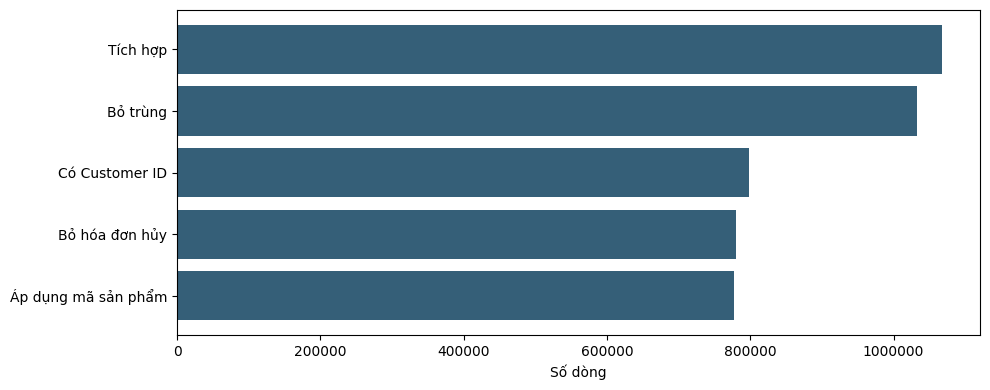

In [75]:
eda_after_duplicates = len(df) - duplicates_removed
eda_after_customer = eda_after_duplicates - missing_customer_id
eda_after_cancelled = eda_after_customer - cancelled_removed

eda_steps = [
    "Tích hợp", "Bỏ trùng", "Có Customer ID",
    "Bỏ hóa đơn hủy", "Áp dụng mã sản phẩm"
]
eda_counts = [
    len(df), eda_after_duplicates, eda_after_customer,
    eda_after_cancelled, len(df_clean)
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(eda_steps, eda_counts, color="#355F78")
ax.invert_yaxis()
ax.set_xlabel("Số dòng")
ax.ticklabel_format(axis="x", style="plain")
fig.tight_layout()
fig.savefig("hinh_3_7_quy_mo_qua_cac_buoc_lam_sach.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 8.Kết luận tiền xử lý dữ liệu

Đã loại bản ghi trùng, giao dịch thiếu Customer ID, giao dịch hủy/trả và các mã phi
sản phẩm/thử nghiệm theo bảng chính sách. Sản phẩm thật có Price = 0 được giữ.
`Amount = Quantity × Price` biểu diễn giá trị dòng sản phẩm. Bảng kiểm tra bên trên
ghi số dòng thực tế sau xử lý, giá trị thiếu và tính hợp lệ của dữ liệu.

Toàn bộ đặc trưng và target ở các phần sau được tính lại từ dữ liệu đã áp dụng
cùng chính sách, do đó không sử dụng lại số liệu mô hình của phiên bản trước.

# **B. Xây dựng các đặc trưng (Feature Engineering).**

Chuyển dữ liệu giao dịch thành các đặc trưng mô tả hành vi mua hàng của từng khách hàng theo từng thời điểm dự đoán.


## 1.Xác định khung thời gian

### 1.1 Xác định Cut-off Date

Chọn thời điểm Cut-off Date để phân tách dữ liệu lịch sử dùng cho việc xây dựng đặc trưng và dữ liệu giao dịch trong 30 ngày tiếp theo dùng để xác định giá trị mua hàng tương lai của khách hàng.

In [76]:
max_date = df_clean["InvoiceDate"].max()

FUTURE_WINDOW_DAYS = 30

cutoff_date = max_date - pd.Timedelta(
    days=FUTURE_WINDOW_DAYS
)

print("Ngày giao dịch cuối cùng :", max_date)
print("Cut-off Date             :", cutoff_date)
print("Khoảng cách               :", max_date - cutoff_date)


Ngày giao dịch cuối cùng : 2011-12-09 12:50:00
Cut-off Date             : 2011-11-09 12:50:00
Khoảng cách               : 30 days 00:00:00


### 1.2 Observation Window

In [77]:
observation_df = df_clean[
    df_clean["InvoiceDate"] <= cutoff_date
].copy()

print("Kích thước Observation Window:", observation_df.shape)

print(
    "Ngày giao dịch đầu tiên:",
    observation_df["InvoiceDate"].min()
)

print(
    "Ngày giao dịch cuối cùng:",
    observation_df["InvoiceDate"].max()
)

Kích thước Observation Window: (712637, 14)
Ngày giao dịch đầu tiên: 2009-12-01 07:45:00
Ngày giao dịch cuối cùng: 2011-11-09 12:49:00


### 1.3 Future Window - Future Window là 30 ngày sau Cut-off, dùng để tạo Target y.

In [78]:
future_end = cutoff_date + pd.Timedelta(
    days=FUTURE_WINDOW_DAYS
)

future_df = df_clean[
    (df_clean["InvoiceDate"] > cutoff_date) &
    (df_clean["InvoiceDate"] <= future_end)
].copy()

print("Kích thước Future Window:", future_df.shape)

print(
    "Ngày giao dịch đầu tiên:",
    future_df["InvoiceDate"].min()
)

print(
    "Ngày giao dịch cuối cùng:",
    future_df["InvoiceDate"].max()
)

Kích thước Future Window: (64020, 14)
Ngày giao dịch đầu tiên: 2011-11-09 13:12:00
Ngày giao dịch cuối cùng: 2011-12-09 12:50:00


### 1.4 Kiểm tra Data Leakage

In [79]:
max_observation = observation_df["InvoiceDate"].max()
min_future = future_df["InvoiceDate"].min()

print("Observation kết thúc :", max_observation)
print("Future bắt đầu       :", min_future)

if max_observation < min_future:
    print("✓ Không có giao dịch bị chồng lấn giữa Observation và Future.")
else:
    print("✗ Có nguy cơ Data Leakage!")

Observation kết thúc : 2011-11-09 12:49:00
Future bắt đầu       : 2011-11-09 13:12:00
✓ Không có giao dịch bị chồng lấn giữa Observation và Future.


### Kết luận

Observation Window dùng giao dịch có InvoiceDate ≤ cutoff; Future Window dùng cutoff < InvoiceDate ≤ cutoff + 30 ngày. Số dòng và mốc thời gian thực tế được in ở các bảng phía trên. X chỉ dùng dữ liệu Observation; y dùng dữ liệu Future của khách hàng đã có trong Observation. Việc không chồng lấn thời gian là một kiểm tra cần thiết, không phải bằng chứng bao quát mọi dạng data leakage.

## 2.RFM

### 2.1 Recency - Khách mua gần đây không?
Khách hàng mua lần cuối cách Cut-off bao nhiêu ngày?

In [80]:
# Tìm ngày/giờ mua hàng gần nhất của mỗi khách hàng
last_purchase = (
    observation_df
    .groupby("Customer ID")["InvoiceDate"]
    .max()
    .reset_index(name="LastPurchaseDate")
)

# Tính số ngày từ lần mua cuối đến Cut-off Date
last_purchase["Recency"] = (
    cutoff_date - last_purchase["LastPurchaseDate"]
).dt.days

# Chỉ giữ các cột cần thiết
recency = last_purchase[
    ["Customer ID", "Recency"]
].copy()

# Kiểm tra kết quả
print("Số khách hàng:", recency["Customer ID"].nunique())
print("Recency nhỏ nhất:", recency["Recency"].min())
print("Recency lớn nhất:", recency["Recency"].max())

display(recency.head(10))

Số khách hàng: 5691
Recency nhỏ nhất: 0
Recency lớn nhất: 708


,Customer ID,Recency
0,12346.0,295
1,12347.0,9
2,12348.0,44
3,12349.0,377
4,12350.0,279
5,12351.0,344
6,12352.0,5
7,12353.0,173
8,12354.0,201
9,12355.0,183


In [81]:
# Kiểm tra Recency có giá trị âm hay không

negative_recency = (
    recency["Recency"] < 0
).sum()

print("Số khách hàng có Recency âm:", negative_recency)

Số khách hàng có Recency âm: 0


In [82]:
display(
    recency.sort_values("Recency").head(10)
)

,Customer ID,Recency
2736,15208.0,0
47,12395.0,0
1625,14051.0,0
4092,16618.0,0
1688,14116.0,0
4130,16656.0,0
2684,15153.0,0
2666,15134.0,0
5046,17611.0,0
3533,16041.0,0


In [83]:
display(
    recency.sort_values("Recency", ascending=False).head(10)
)

,Customer ID,Recency
5028,17592.0,708
4516,17056.0,707
4547,17087.0,707
1116,13526.0,707
3332,15833.0,707
5242,17818.0,707
2210,14654.0,707
2514,14980.0,706
5041,17606.0,706
5328,17909.0,706


In [244]:
# Kiểm tra khách hàng có Recency nhỏ nhất

customer_id = (
    recency
    .sort_values("Recency")
    .iloc[0]["Customer ID"]
)

print("Customer ID:", customer_id)

display(
    observation_df[
        observation_df["Customer ID"] == customer_id
    ][
        ["Customer ID", "Invoice", "InvoiceDate", "Amount"]
    ]
    .sort_values("InvoiceDate", ascending=False)
    .head()
)

Customer ID: 15208.0


,Customer ID,Invoice,InvoiceDate,Amount
974967,15208.0,575131,2011-11-08 14:39:00,17.7
974966,15208.0,575131,2011-11-08 14:39:00,16.5
974965,15208.0,575131,2011-11-08 14:39:00,16.5
974964,15208.0,575131,2011-11-08 14:39:00,10.2
974963,15208.0,575131,2011-11-08 14:39:00,19.8


Recency phản ánh số ngày kể từ lần mua gần nhất của khách hàng đến Cut-off Date. Feature này mô tả mức độ gần đây của hoạt động mua hàng và là một thành phần cốt lõi của RFM.

### 2.2 Frequency - tần suất mua hàng

Frequency = số Invoice duy nhất mà khách hàng đã thực hiện trong Observation Window.

In [85]:
frequency = (
    observation_df
    .groupby("Customer ID")["Invoice"]
    .nunique()
    .reset_index(name="Frequency")
)

print("Số khách hàng:", frequency["Customer ID"].nunique())

display(frequency.head(10))

Số khách hàng: 5691


,Customer ID,Frequency
0,12346.0,3
1,12347.0,7
2,12348.0,5
3,12349.0,2
4,12350.0,1
5,12351.0,1
6,12352.0,9
7,12353.0,2
8,12354.0,1
9,12355.0,2


Frequency phản ánh số Invoice duy nhất mà khách hàng đã thực hiện trong Observation Window. Feature này thể hiện mức độ thường xuyên mua hàng và bổ sung cho Recency và Monetary trong việc mô tả hành vi khách hàng.

### 2.3. MONETARY - Giá trị mua hàng

In [86]:
monetary = (
    observation_df
    .groupby("Customer ID")["Amount"]
    .sum()
    .reset_index(name="Monetary")
)

print("Số khách hàng:", monetary["Customer ID"].nunique())

display(monetary.head(10))

Số khách hàng: 5691


,Customer ID,Monetary
0,12346.0,77352.96
1,12347.0,4696.71
2,12348.0,1658.40
3,12349.0,2221.14
4,12350.0,294.40
5,12351.0,300.93
6,12352.0,1729.54
7,12353.0,406.76
8,12354.0,1079.40
9,12355.0,947.61


Monetary phản ánh tổng giá trị mua hàng của mỗi khách hàng trong Observation Window. Feature này đo lường quy mô chi tiêu và hoàn thiện ba khía cạnh cốt lõi của RFM: gần đây, tần suất và giá trị mua hàng.

### 2.4. TẠO BẢNG RFM

In [87]:
rfm = (
    recency
    .merge(
        frequency,
        on="Customer ID",
        how="inner"
    )
    .merge(
        monetary,
        on="Customer ID",
        how="inner"
    )
)

print("Kích thước RFM:", rfm.shape)

display(rfm.head(10))

Kích thước RFM: (5691, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346.0,295,3,77352.96
1,12347.0,9,7,4696.71
2,12348.0,44,5,1658.40
3,12349.0,377,2,2221.14
4,12350.0,279,1,294.40
5,12351.0,344,1,300.93
6,12352.0,5,9,1729.54
7,12353.0,173,2,406.76
8,12354.0,201,1,1079.40
9,12355.0,183,2,947.61


In [88]:
# KIỂM TRA RFM

print("Số khách hàng:", rfm["Customer ID"].nunique())
print("Số dòng:", len(rfm))

print("\nMissing:")
print(rfm.isnull().sum())

print("\nDuplicate Customer ID:")
print(rfm["Customer ID"].duplicated().sum())

print("\nThống kê RFM:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

Số khách hàng: 5691
Số dòng: 5691

Missing:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

Duplicate Customer ID:
0

Thống kê RFM:


,Recency,Frequency,Monetary
count,5691.000000,5691.000000,5691.000000
mean,201.000527,5.951502,2766.595879
std,198.227111,12.010398,13648.761464
min,0.000000,1.000000,2.900000
25%,29.000000,1.000000,325.555000
50%,124.000000,3.000000,818.290000
75%,357.500000,6.000000,2136.760000
max,708.000000,335.000000,569215.420000


Ba feature Recency, Frequency và Monetary tạo thành nhóm RFM, mô tả lần lượt mức độ gần đây, tần suất và quy mô chi tiêu của khách hàng. Đây là nhóm đặc trưng nền tảng để kết hợp với các đặc trưng Temporal và Behavioral ở các bước tiếp theo.

### Kết luận RFM

Recency, Frequency và Monetary được tính từ cùng Observation Window trên các dòng sản phẩm hợp lệ. Các bảng kiểm tra phía trên ghi số khách hàng, miền giá trị và tính duy nhất của Customer ID. Monetary là giá trị mua sản phẩm theo chính sách đã nêu, không phải chi tiêu ròng sau hoàn trả.

## 3.Temporal Feature

Khách hàng mua hàng vào thời điểm nào và chu kỳ mua hàng của họ như thế nào?

### 3.1 AveragePurchaseHour - Giờ mua hàng trung bình

In [89]:
observation_df["PurchaseHour"] = (
    observation_df["InvoiceDate"].dt.hour
)

display(
    observation_df[
        ["Customer ID", "InvoiceDate", "PurchaseHour"]
    ].head(10)
)

,Customer ID,InvoiceDate,PurchaseHour
0,13085.0,2009-12-01 07:45:00,7
1,13085.0,2009-12-01 07:45:00,7
2,13085.0,2009-12-01 07:45:00,7
3,13085.0,2009-12-01 07:45:00,7
4,13085.0,2009-12-01 07:45:00,7
5,13085.0,2009-12-01 07:45:00,7
6,13085.0,2009-12-01 07:45:00,7
7,13085.0,2009-12-01 07:45:00,7
8,13085.0,2009-12-01 07:46:00,7
9,13085.0,2009-12-01 07:46:00,7


In [90]:
invoice_time = (
    observation_df.groupby(['Customer ID', 'Invoice'], as_index=False)['InvoiceDate']
    .min().sort_values(['Customer ID', 'InvoiceDate'])
)
invoice_time['PurchaseHour'] = invoice_time['InvoiceDate'].dt.hour
average_purchase_hour = invoice_time.groupby('Customer ID')['PurchaseHour'].mean().reset_index(name='AveragePurchaseHour')
display(average_purchase_hour.head(10))

,Customer ID,AveragePurchaseHour
0,12346.0,12.000000
1,12347.0,12.142857
2,12348.0,13.200000
3,12349.0,10.500000
4,12350.0,16.000000
5,12351.0,15.000000
6,12352.0,13.333333
7,12353.0,14.500000
8,12354.0,13.000000
9,12355.0,12.000000


In [91]:
print(
    average_purchase_hour["AveragePurchaseHour"].describe()
)
print(
    "Min:",
    average_purchase_hour["AveragePurchaseHour"].min()
)

print(
    "Max:",
    average_purchase_hour["AveragePurchaseHour"].max()
)

count    5691.000000
mean       12.632988
std         1.759079
min         7.000000
25%        11.600000
50%        12.500000
75%        13.696154
max        20.000000
Name: AveragePurchaseHour, dtype: float64
Min: 7.0
Max: 20.0


AveragePurchaseHour phản ánh giờ mua hàng trung bình của mỗi khách hàng trong Observation Window. Feature được tính ở cấp độ Invoice, đảm bảo mỗi lần mua chỉ được tính một lần thay vì bị ảnh hưởng bởi số lượng sản phẩm trong hóa đơn. Feature này bổ sung thông tin về thói quen mua hàng theo thời gian trong ngày.

### 3.2 PreferredDayOfWeek - Ngày trong tuần

In [92]:
observation_df["DayOfWeek"] = (
    observation_df["InvoiceDate"].dt.dayofweek
)

display(
    observation_df[
        ["Customer ID", "InvoiceDate", "DayOfWeek"]
    ].head(10)
)

,Customer ID,InvoiceDate,DayOfWeek
0,13085.0,2009-12-01 07:45:00,1
1,13085.0,2009-12-01 07:45:00,1
2,13085.0,2009-12-01 07:45:00,1
3,13085.0,2009-12-01 07:45:00,1
4,13085.0,2009-12-01 07:45:00,1
5,13085.0,2009-12-01 07:45:00,1
6,13085.0,2009-12-01 07:45:00,1
7,13085.0,2009-12-01 07:45:00,1
8,13085.0,2009-12-01 07:46:00,1
9,13085.0,2009-12-01 07:46:00,1


In [93]:
invoice_day = invoice_time[['Customer ID', 'Invoice', 'InvoiceDate']].copy()
invoice_day['DayOfWeek'] = invoice_day['InvoiceDate'].dt.dayofweek
preferred_day = invoice_day.groupby('Customer ID')['DayOfWeek'].agg(lambda x: x.mode().iloc[0]).reset_index(name='PreferredDayOfWeek')
display(preferred_day.head(10))

,Customer ID,PreferredDayOfWeek
0,12346.0,1
1,12347.0,1
2,12348.0,1
3,12349.0,3
4,12350.0,2
5,12351.0,0
6,12352.0,1
7,12353.0,2
8,12354.0,3
9,12355.0,0


In [94]:
print(
    preferred_day["PreferredDayOfWeek"].value_counts().sort_index()
)

PreferredDayOfWeek
0    1198
1    1181
2    1066
3    1088
4     551
5       1
6     606
Name: count, dtype: int64


PreferredDayOfWeek phản ánh ngày trong tuần có số hóa đơn mua hàng nhiều nhất của mỗi khách hàng trong Observation Window. Mỗi hóa đơn được tính một lần, với thời điểm hóa đơn là InvoiceDate sớm nhất.

Ngày trong tuần được mã hóa từ 0 (thứ Hai) đến 6 (Chủ nhật). Nếu nhiều ngày có cùng số hóa đơn cao nhất, chọn ngày có mã nhỏ nhất để bảo đảm kết quả xác định và có thể tái lập. Đây là quy tắc xử lý đồng tần suất, không có nghĩa khách hàng ưu tiên ngày được chọn hơn các ngày đồng tần suất còn lại.

### 3.3 ActiveMonths - Số tháng hoạt động

In [95]:
observation_df["PurchaseMonth"] = (
    observation_df["InvoiceDate"].dt.to_period("M")
)

active_months = (
    observation_df
    .groupby("Customer ID")["PurchaseMonth"]
    .nunique()
    .reset_index(name="ActiveMonths")
)

display(
    active_months.head(10)
)

,Customer ID,ActiveMonths
0,12346.0,3
1,12347.0,7
2,12348.0,5
3,12349.0,2
4,12350.0,1
5,12351.0,1
6,12352.0,5
7,12353.0,2
8,12354.0,1
9,12355.0,2


In [96]:
print(active_months["ActiveMonths"].describe())

count    5691.000000
mean        4.182569
std         4.311617
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max        24.000000
Name: ActiveMonths, dtype: float64


ActiveMonths phản ánh số tháng mà khách hàng có phát sinh giao dịch trong Observation Window. Feature này thể hiện mức độ duy trì hoạt động mua hàng theo thời gian.

### 3.4 AverageInterpurchaseTime - Khoảng cách giữa các lần mua

In [97]:
# mỗi Customer ID–Invoice có một dòng, lấy InvoiceDate sớm nhất.
purchase_dates = (
    invoice_time[
        ["Customer ID", "Invoice", "InvoiceDate"]
    ]
    .sort_values(["Customer ID", "InvoiceDate"])
    .copy()
)

# Kiểm tra mỗi hóa đơn chỉ được tính là một lần mua
assert not purchase_dates.duplicated(
    ["Customer ID", "Invoice"]
).any()

# Khoảng cách giữa hai lần mua liên tiếp, đơn vị ngày
purchase_dates["InterpurchaseTime"] = (
    purchase_dates
    .groupby("Customer ID")["InvoiceDate"]
    .diff()
    .dt.total_seconds()
    .div(86400)
)

print("Số lần mua duy nhất:", len(purchase_dates))
display(purchase_dates.head(10))

Số lần mua duy nhất: 33870


,Customer ID,Invoice,InvoiceDate,InterpurchaseTime
0,12346.0,499763,2010-03-02 13:08:00,NaN
1,12346.0,513774,2010-06-28 13:53:00,118.031250
2,12346.0,541431,2011-01-18 10:01:00,203.838889
3,12347.0,529924,2010-10-31 14:20:00,NaN
4,12347.0,537626,2010-12-07 14:57:00,37.025694
5,12347.0,542237,2011-01-26 14:30:00,49.981250
6,12347.0,549222,2011-04-07 10:43:00,70.842361
7,12347.0,556201,2011-06-09 13:01:00,63.095833
8,12347.0,562032,2011-08-02 08:48:00,53.824306
9,12347.0,573511,2011-10-31 12:25:00,90.150694


In [98]:
average_interpurchase = (
    purchase_dates
    .groupby("Customer ID")["InterpurchaseTime"]
    .mean()
    .reset_index(
        name="AverageInterpurchaseTime"
    )
)
print(
    "Số khách hàng:",
    average_interpurchase["Customer ID"].nunique()
)

print(
    "Số dòng:",
    len(average_interpurchase)
)

display(
    average_interpurchase.head(10)
)

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,AverageInterpurchaseTime
0,12346.0,160.935069
1,12347.0,60.820023
2,12348.0,90.731597
3,12349.0,181.793750
4,12350.0,NaN
5,12351.0,NaN
6,12352.0,44.522309
7,12353.0,204.210417
8,12354.0,NaN
9,12355.0,353.076389


In [99]:
print(
    average_interpurchase[
        "AverageInterpurchaseTime"
    ].describe()
)
print(
    "Số giá trị âm:",
    (
        average_interpurchase[
            "AverageInterpurchaseTime"
        ] < 0
    ).sum()
)

count    4001.000000
mean      100.117431
std        93.292519
min         0.000000
25%        39.824959
50%        72.864323
75%       126.588056
max       687.068750
Name: AverageInterpurchaseTime, dtype: float64
Số giá trị âm: 0


AverageInterpurchaseTime phản ánh khoảng thời gian trung bình giữa các lần mua của khách hàng. Feature này mô tả nhịp độ và chu kỳ mua hàng của khách hàng

### 3.5 PurchaseTrend - Xu hướng chi tiêu theo các tháng đã hoàn tất

Chỉ dùng các tháng kết thúc trước cutoff. Tháng chứa cutoff bị loại vì chưa được
quan sát đủ; không bổ sung dữ liệu tương lai để hoàn tất tháng. Với mỗi khách hàng,
bắt đầu từ tháng có giao dịch sản phẩm đầu tiên và điền 0 cho tháng không mua.
Hệ số góc có đơn vị giá trị chi tiêu/tháng. Khách có dưới hai tháng quan sát hợp lệ
được giữ NaN để imputer học cách xử lý trong từng fold huấn luyện.

In [100]:
cutoff_month = cutoff_date.to_period("M")
last_complete_month = cutoff_month - 1

# Chỉ lấy dữ liệu của các tháng đã hoàn tất
trend_observation_df = observation_df.loc[
    observation_df["InvoiceDate"].dt.to_period("M")
    < cutoff_month
].copy()

# Kiểm tra ranh giới thời gian
assert (
    trend_observation_df["InvoiceDate"].dt.to_period("M")
    <= last_complete_month
).all()

assert (
    trend_observation_df["InvoiceDate"] <= cutoff_date
).all()

# Tổng chi tiêu theo khách hàng và tháng
monthly_spending = (
    trend_observation_df
    .assign(
        YearMonth=(
            trend_observation_df["InvoiceDate"]
            .dt.to_period("M")
        )
    )
    .groupby(
        ["Customer ID", "YearMonth"]
    )["Amount"]
    .sum()
    .reset_index()
)

print(
    "Tháng đầy đủ cuối dùng tính trend:",
    last_complete_month
)

display(monthly_spending.head(10))

Tháng đầy đủ cuối dùng tính trend: 2011-10


,Customer ID,YearMonth,Amount
0,12346.0,2010-03,27.05
1,12346.0,2010-06,142.31
2,12346.0,2011-01,77183.60
3,12347.0,2010-10,611.53
4,12347.0,2010-12,711.79
5,12347.0,2011-01,475.39
6,12347.0,2011-04,636.25
7,12347.0,2011-06,382.52
8,12347.0,2011-08,584.91
9,12347.0,2011-10,1294.32


In [101]:
monthly_frames = []

for customer_id, group in monthly_spending.groupby("Customer ID"):
    months = pd.period_range(
        start=group["YearMonth"].min(),
        end=last_complete_month,
        freq="M"
    )
    customer_months = pd.DataFrame({
        "Customer ID": customer_id,
        "YearMonth": months
    })

    monthly_frames.append(customer_months)

monthly_index = pd.concat(
    monthly_frames,
    ignore_index=True
)

monthly_spending_full = monthly_index.merge(
    monthly_spending,
    on=["Customer ID", "YearMonth"],
    how="left",
    validate="one_to_one"
)

monthly_spending_full["Amount"] = (
    monthly_spending_full["Amount"].fillna(0)
)

assert (
    monthly_spending_full["YearMonth"].max()
    == last_complete_month
)

display(monthly_spending_full.head(15))

,Customer ID,YearMonth,Amount
0,12346.0,2010-03,27.05
1,12346.0,2010-04,0.00
2,12346.0,2010-05,0.00
3,12346.0,2010-06,142.31
4,12346.0,2010-07,0.00
5,12346.0,2010-08,0.00
6,12346.0,2010-09,0.00
7,12346.0,2010-10,0.00
8,12346.0,2010-11,0.00
9,12346.0,2010-12,0.00


In [102]:
def calculate_purchase_trend(group):
    group = group.sort_values("YearMonth")

    # Chưa đủ hai tháng để tính xu hướng
    if len(group) < 2:
        return np.nan

    x = np.arange(len(group), dtype=float)
    y = group["Amount"].to_numpy(dtype=float)

    return float(np.polyfit(x, y, 1)[0])

# Tính xu hướng và số tháng quan sát của từng khách hàng
trend_records = []

for customer_id, group in monthly_spending_full.groupby("Customer ID"):
    trend_records.append({
        "Customer ID": customer_id,
        "PurchaseTrend": calculate_purchase_trend(group),
        "TrendObservedMonths": len(group)
    })

# Ghép lại toàn bộ khách hàng trong Observation Window
trend_details = (
    observation_df[["Customer ID"]]
    .drop_duplicates()
    .merge(
        pd.DataFrame(trend_records),
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )
)

trend_details["TrendObservedMonths"] = (
    trend_details["TrendObservedMonths"]
    .fillna(0)
    .astype(int)
)

# Tạo bảng PurchaseTrend
purchase_trend = trend_details[
    ["Customer ID", "PurchaseTrend"]
].copy()

# Kiểm tra khách hàng chưa đủ hai tháng
assert (
    purchase_trend.loc[
        trend_details["TrendObservedMonths"] < 2,
        "PurchaseTrend"
    ]
    .isna()
    .all()
)

# Kiểm tra khách hàng đã đủ hai tháng
assert (
    purchase_trend.loc[
        trend_details["TrendObservedMonths"] >= 2,
        "PurchaseTrend"
    ]
    .notna()
    .all()
)

# Kiểm tra đủ số lượng khách hàng
assert (
    purchase_trend["Customer ID"].nunique()
    == observation_df["Customer ID"].nunique()
)

print(
    "Số khách hàng:",
    len(purchase_trend)
)

print(
    "Khách chưa đủ hai tháng đầy đủ:",
    purchase_trend["PurchaseTrend"].isna().sum()
)

display(trend_details.head(10))

Số khách hàng: 5691
Khách chưa đủ hai tháng đầy đủ: 279


,Customer ID,PurchaseTrend,TrendObservedMonths
0,13085.0,-19.101443,23
1,13078.0,-17.172372,23
2,15362.0,-3.975208,23
3,18102.0,-109.389585,23
4,12682.0,-9.058429,23
5,18087.0,-29.260652,23
6,13635.0,0.741818,23
7,14110.0,-2.505603,23
8,17519.0,-12.323923,23
9,13758.0,-27.544377,23


In [103]:
print(purchase_trend["PurchaseTrend"].describe())

print(
    "Số PurchaseTrend > 0:",
    (purchase_trend["PurchaseTrend"] > 0).sum()
)

print(
    "Số PurchaseTrend < 0:",
    (purchase_trend["PurchaseTrend"] < 0).sum()
)

print(
    "Số PurchaseTrend = 0:",
    (purchase_trend["PurchaseTrend"] == 0).sum()
)

count    5412.000000
mean      -29.429434
std       202.124210
min     -7983.300000
25%       -17.679461
50%        -6.804823
75%        -2.244312
max      7847.450000
Name: PurchaseTrend, dtype: float64
Số PurchaseTrend > 0: 748
Số PurchaseTrend < 0: 4664
Số PurchaseTrend = 0: 0


In [104]:
display(
    purchase_trend.sort_values(
        "PurchaseTrend",
        ascending=False
    ).head(10)
)

display(
    purchase_trend.sort_values(
        "PurchaseTrend",
        ascending=True
    ).head(10)
)

,Customer ID,PurchaseTrend
5217,14096.0,7847.450000
3485,17450.0,909.039385
2939,12415.0,902.456642
5262,14432.0,774.910000
5399,17813.0,670.260000
5268,16360.0,553.480000
5216,17183.0,448.100000
4371,13098.0,435.360970
176,14646.0,411.708478
5192,15801.0,394.755000


,Customer ID,PurchaseTrend
4950,15098.0,-7983.300
5311,12752.0,-4366.780
5173,12688.0,-2436.905
5341,12906.0,-1936.590
5329,14887.0,-1862.000
5352,16240.0,-1824.790
5303,15947.0,-1708.240
4331,15749.0,-1646.020
5317,14164.0,-1631.770
5258,17317.0,-1455.540


In [105]:
print(
    "Số Customer:",
    purchase_trend["Customer ID"].nunique()
)

print(
    "Số missing:",
    purchase_trend["PurchaseTrend"].isna().sum()
)

Số Customer: 5691
Số missing: 279


In [106]:
# So sánh Future Window 7, 14 và 30 ngày

max_date = df_clean["InvoiceDate"].max()

results = []

for days in [7, 14, 30]:
    cutoff = max_date - pd.Timedelta(days=days)

    obs = df_clean[
        df_clean["InvoiceDate"] <= cutoff
    ]

    future = df_clean[
        df_clean["InvoiceDate"] > cutoff
    ]

    customers = pd.Index(obs["Customer ID"].unique())

    spending = (
        future.groupby("Customer ID")["Amount"]
        .sum()
        .reindex(customers, fill_value=0)
    )

    results.append({
        "Future Window": f"{days} days",
        "Customers": len(customers),
        "Positive Customers": (spending > 0).sum(),
        "Zero Customers": (spending == 0).sum(),
        "Zero Rate (%)": round(
            (spending == 0).mean() * 100, 2
        ),
        "Mean Spending": round(spending.mean(), 2),
        "Median Spending": round(spending.median(), 2)
    })

window_comparison = pd.DataFrame(results)

display(window_comparison)

,Future Window,Customers,Positive Customers,Zero Customers,Zero Rate (%),Mean Spending,Median Spending
0,7 days,5831,483,5348,91.72,73.17,0.0
1,14 days,5799,828,4971,85.72,111.44,0.0
2,30 days,5691,1486,4205,73.89,218.09,0.0


Nhóm khảo sát ba khoảng thời gian dự đoán gồm **7, 14 và 30 ngày** để xem xét phân phối của biến mục tiêu `FutureSpending`. Tỷ lệ khách hàng có chi tiêu bằng 0 lần lượt là **91,72%, 85,72% và 73,89%**.

Nhóm lựa chọn **Future Window 30 ngày** làm phạm vi nghiên cứu dự đoán chi tiêu tương lai. Trong các phương án khảo sát, cửa sổ này ghi nhận tỷ lệ khách hàng phát sinh chi tiêu cao nhất. Tuy nhiên, kết quả này chỉ mô tả phân phối target, chưa chứng minh khoảng dự đoán 30 ngày mang lại hiệu quả dự đoán tốt nhất.

Do **73,89% khách hàng vẫn có FutureSpending bằng 0**, nhóm sử dụng các baseline **DummyRegressor mean, DummyRegressor median và Ridge Regression**, kết hợp các chỉ số MAE, MSE, RMSE và R² để đánh giá khả năng dự đoán trước khi so sánh các phương pháp Feature Selection.

### Kết luận

Nhóm **Temporal Features** bổ sung thông tin về thời điểm mua hàng, mức độ duy trì hoạt động và chu kỳ mua của **5.691 khách hàng**, gồm:

- **AveragePurchaseHour:** Giờ mua hàng trung bình tính ở cấp độ hóa đơn, dao động từ **7–20 giờ**.
- **PreferredDayOfWeek:** Ngày trong tuần khách hàng mua hàng thường xuyên nhất, xác định từ các hóa đơn trong Observation Window.
- **ActiveMonths:** Số tháng có phát sinh giao dịch, dao động từ **1–24 tháng**.
- **AverageInterpurchaseTime:** Khoảng thời gian trung bình giữa các lần mua, không có giá trị âm. Có **1.690 khách hàng** chỉ có một lần mua nên chưa xác định được khoảng cách giữa các lần mua; các trường hợp này được giữ **NaN**.
- **PurchaseTrend:** Hệ số xu hướng chi tiêu theo tháng, chỉ sử dụng các tháng đã hoàn tất đến **tháng 10/2011**. Tháng chứa cutoff được loại khỏi phép tính vì chưa được quan sát đầy đủ; các tháng không mua hàng trong khoảng quan sát của từng khách hàng được điền chi tiêu bằng 0. Có **748 khách hàng có hệ số dương**, **4.664 khách hàng có hệ số âm** và **279 khách hàng chưa đủ hai tháng quan sát hợp lệ**, được giữ **NaN**.

Các giá trị thiếu của **AverageInterpurchaseTime** và **PurchaseTrend** phản ánh việc khách hàng chưa có đủ lịch sử để tính các đặc trưng tương ứng. Chúng được giữ nguyên ở bước Feature Engineering và được xử lý bằng **median imputation trong pipeline mô hình**. Khi đánh giá bằng Cross-Validation, trung vị được học riêng từ training fold; khi huấn luyện trên toàn bộ Train, trung vị được học từ Train và áp dụng cho Test.

Toàn bộ Temporal Features chỉ sử dụng dữ liệu trong **Observation Window**, không sử dụng giao dịch thuộc **Future Window**. Năm đặc trưng này được kết hợp với nhóm RFM và Behavioral để tạo thành bộ **14 đặc trưng ứng viên**, phục vụ đánh giá và lựa chọn đặc trưng trong phần C.

## 4.Behavioral Feature giúp mô tả phong cách/thói quen mua hàng của khách hàng ví dụ như cách khách hàng thực hiện mua hàng chứ không chỉ mua bao nhiêu tiền.
mô tả cách thức và thói quen mua hàng của từng khách hàng, bổ sung cho RFM (mua bao nhiêu/gần đây/tần suất) và Temporal Features (mua khi nào).

### 4.1 AverageOrderValue: Một invoice trung bình có giá trị bao nhiêu?

In [107]:
average_order_value = (
    monetary
    .merge(
        frequency,
        on="Customer ID",
        how="inner"
    )
)

average_order_value["AverageOrderValue"] = (
    average_order_value["Monetary"]
    / average_order_value["Frequency"]
)

average_order_value = average_order_value[
    ["Customer ID", "AverageOrderValue"]
]

print(
    "Số khách hàng:",
    average_order_value["Customer ID"].nunique()
)

print(
    "Số dòng:",
    len(average_order_value)
)

display(
    average_order_value.head(10)
)

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,AverageOrderValue
0,12346.0,25784.320000
1,12347.0,670.958571
2,12348.0,331.680000
3,12349.0,1110.570000
4,12350.0,294.400000
5,12351.0,300.930000
6,12352.0,192.171111
7,12353.0,203.380000
8,12354.0,1079.400000
9,12355.0,473.805000


In [108]:
print("=== KIỂM TRA AVERAGE ORDER VALUE ===")

print(
    "Số khách hàng:",
    average_order_value["Customer ID"].nunique()
)

print(
    "Số dòng:",
    len(average_order_value)
)

print(
    "Số missing:",
    average_order_value["AverageOrderValue"].isna().sum()
)

print(
    "Số Customer ID trùng:",
    average_order_value["Customer ID"].duplicated().sum()
)

print(
    "Số giá trị <= 0:",
    (
        average_order_value["AverageOrderValue"] <= 0
    ).sum()
)

=== KIỂM TRA AVERAGE ORDER VALUE ===
Số khách hàng: 5691
Số dòng: 5691
Số missing: 0
Số Customer ID trùng: 0
Số giá trị <= 0: 0


In [109]:
display(
    average_order_value["AverageOrderValue"].describe()
)

,AverageOrderValue
count,5691.000000
mean,373.583266
std,616.443965
min,2.900000
25%,176.496000
50%,280.386667
75%,416.212500
max,25784.320000


In [110]:
display(
    average_order_value
    .sort_values(
        "AverageOrderValue",
        ascending=False
    )
    .head(10)
)

,Customer ID,AverageOrderValue
0,12346.0,25784.320000
3254,15749.0,14844.766667
2630,15098.0,13305.500000
1270,13687.0,11880.840000
5462,18052.0,10877.180000
230,12590.0,9341.260000
11,12357.0,8718.830000
1479,13902.0,6804.652000
66,12415.0,6303.544091
4896,17450.0,5343.386190


AverageOrderValue được xây dựng ở cấp độ khách hàng từ dữ liệu trong Observation Window, bằng tổng giá trị mua hàng chia cho số hóa đơn duy nhất của mỗi khách hàng. Đặc trưng phản ánh giá trị mua hàng trung bình trên mỗi hóa đơn, bổ sung cho Monetary về quy mô của một lần mua.

AverageOrderValue không sử dụng giao dịch thuộc Future Window để tính giá trị đầu vào. Việc kiểm soát data leakage trong toàn bộ quy trình còn phụ thuộc vào cách chia dữ liệu, fit tiền xử lý và lựa chọn đặc trưng ở phần C.

### 4.2 AverageQuantityPerInvoice: Mỗi lần mua khách hàng thường mua bao nhiêu sản phẩm?

In [111]:
# Bước 1: Tính tổng Quantity của từng Invoice
invoice_quantity = (
    observation_df
    .groupby(["Customer ID", "Invoice"])["Quantity"]
    .sum()
    .reset_index(name="InvoiceQuantity")
)

# Bước 2: Tính Quantity trung bình trên mỗi Invoice của từng khách hàng
average_quantity_per_invoice = (
    invoice_quantity
    .groupby("Customer ID")["InvoiceQuantity"]
    .mean()
    .reset_index(name="AverageQuantityPerInvoice")
)

print("Số khách hàng:", average_quantity_per_invoice["Customer ID"].nunique())
print("Số dòng:", len(average_quantity_per_invoice))

display(average_quantity_per_invoice.head(10))

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,AverageQuantityPerInvoice
0,12346.0,24746.333333
1,12347.0,396.428571
2,12348.0,540.800000
3,12349.0,495.500000
4,12350.0,196.000000
5,12351.0,261.000000
6,12352.0,79.333333
7,12353.0,106.000000
8,12354.0,530.000000
9,12355.0,271.500000


In [112]:
print("=== KIỂM TRA AVERAGE QUANTITY PER INVOICE ===")

print("Số khách hàng:",
      average_quantity_per_invoice["Customer ID"].nunique())

print("Số dòng:",
      len(average_quantity_per_invoice))

print("Số Customer ID trùng:",
      average_quantity_per_invoice["Customer ID"].duplicated().sum())

print("Số missing:",
      average_quantity_per_invoice["AverageQuantityPerInvoice"].isna().sum())

print("Số giá trị <= 0:",
      (average_quantity_per_invoice["AverageQuantityPerInvoice"] <= 0).sum())

print("Giá trị nhỏ nhất:",
      average_quantity_per_invoice["AverageQuantityPerInvoice"].min())

print("Giá trị lớn nhất:",
      average_quantity_per_invoice["AverageQuantityPerInvoice"].max())

=== KIỂM TRA AVERAGE QUANTITY PER INVOICE ===
Số khách hàng: 5691
Số dòng: 5691
Số Customer ID trùng: 0
Số missing: 0
Số giá trị <= 0: 0
Giá trị nhỏ nhất: 1.0
Giá trị lớn nhất: 87167.0


In [113]:
display(
    average_quantity_per_invoice["AverageQuantityPerInvoice"]
    .describe()
)

,AverageQuantityPerInvoice
count,5691.000000
mean,250.969585
std,1392.420827
min,1.000000
25%,91.273649
50%,154.800000
75%,261.366667
max,87167.000000


In [114]:
display(
    average_quantity_per_invoice
    .sort_values("AverageQuantityPerInvoice", ascending=False)
    .head(10)
)

,Customer ID,AverageQuantityPerInvoice
1270,13687.0,87167.000000
1479,13902.0,44119.200000
0,12346.0,24746.333333
5462,18052.0,17766.000000
1847,14277.0,14780.500000
5356,17940.0,6081.857143
3254,15749.0,6009.333333
5655,18251.0,4404.333333
230,12590.0,4282.000000
66,12415.0,4027.681818


In [115]:
customer_test = (
    average_quantity_per_invoice
    .sort_values("AverageQuantityPerInvoice", ascending=False)
    .iloc[0]["Customer ID"]
)

print("Customer ID được kiểm tra:", customer_test)

display(
    invoice_quantity[
        invoice_quantity["Customer ID"] == customer_test
    ].sort_values("InvoiceQuantity", ascending=False)
)

calculated_value = (
    invoice_quantity[
        invoice_quantity["Customer ID"] == customer_test
    ]["InvoiceQuantity"]
    .mean()
)

print("AverageQuantityPerInvoice tính lại:",
      calculated_value)

Customer ID được kiểm tra: 13687.0


,Customer ID,Invoice,InvoiceQuantity
7450,13687.0,524174,87167


AverageQuantityPerInvoice tính lại: 87167.0


AverageQuantityPerInvoice được xây dựng ở cấp độ khách hàng từ **Observation Window**. Với mỗi khách hàng, nhóm tính tổng `Quantity` của từng Invoice, sau đó lấy trung bình giữa các Invoice. Nhờ đó, mỗi hóa đơn có trọng số như nhau khi tính số lượng sản phẩm trung bình trong một lần mua.

Kết quả kiểm tra cho thấy feature có **5.691 khách hàng và 5.691 dòng dữ liệu**, không có Customer ID trùng, không có giá trị thiếu và tất cả giá trị đều lớn hơn 0.

Feature phản ánh **quy mô mua hàng trung bình trên mỗi hóa đơn**. Khi kết hợp với Frequency, đặc trưng này giúp phân biệt khách hàng mua thường xuyên với số lượng nhỏ và khách hàng mua số lượng lớn trong mỗi đơn.

AverageQuantityPerInvoice chỉ sử dụng giao dịch thuộc Observation Window, không sử dụng dữ liệu Future Window, và được đưa vào tập đặc trưng ứng viên cho Feature Selection.

### 4.3 AveragePrice: Khách hàng thường mua sản phẩm ở mức giá như thế nào?

In [116]:
average_price = (
    observation_df
    .groupby("Customer ID")["Price"]
    .mean()
    .reset_index(name="AveragePrice")
)

print("Số khách hàng:", average_price["Customer ID"].nunique())
print("Số dòng:", len(average_price))

display(average_price.head(10))

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,AveragePrice
0,12346.0,6.816000
1,12347.0,2.564123
2,12348.0,0.697826
3,12349.0,4.253400
4,12350.0,1.581250
5,12351.0,2.355238
6,12352.0,3.878000
7,12353.0,2.628333
8,12354.0,4.503793
9,12355.0,3.069429


In [117]:
print("=== KIỂM TRA AVERAGE PRICE ===")

print("Số khách hàng:",
      average_price["Customer ID"].nunique())

print("Số dòng:",
      len(average_price))

print("Số Customer ID trùng:",
      average_price["Customer ID"].duplicated().sum())

print("Số missing:",
      average_price["AveragePrice"].isna().sum())

print("Số giá trị <= 0:",
      (average_price["AveragePrice"] <= 0).sum())

print("Giá trị nhỏ nhất:",
      average_price["AveragePrice"].min())

print("Giá trị lớn nhất:",
      average_price["AveragePrice"].max())

=== KIỂM TRA AVERAGE PRICE ===
Số khách hàng: 5691
Số dòng: 5691
Số Customer ID trùng: 0
Số missing: 0
Số giá trị <= 0: 0
Giá trị nhỏ nhất: 0.15133333333333335
Giá trị lớn nhất: 434.65000000000003


In [118]:
display(
    average_price["AveragePrice"].describe()
)

,AveragePrice
count,5691.000000
mean,3.420760
std,7.171118
min,0.151333
25%,2.257511
50%,2.890278
75%,3.731014
max,434.650000


In [119]:
display(
    average_price
    .sort_values("AveragePrice", ascending=False)
    .head(10)
)

,Customer ID,AveragePrice
2630,15098.0,434.650000
1045,13452.0,208.316667
3029,15510.0,125.000000
5638,18233.0,110.000000
711,13096.0,69.950000
2363,14816.0,66.475000
1756,14185.0,59.733333
5632,18227.0,56.375000
556,12934.0,41.670000
1660,14086.0,39.950000


In [120]:
price_check = (
    observation_df
    .groupby("Customer ID")["Price"]
    .agg(
        MinPrice="min",
        MaxPrice="max",
        MeanPrice="mean"
    )
    .reset_index()
)

price_check = price_check.merge(
    average_price,
    on="Customer ID",
    how="inner"
)

price_check["Difference"] = (
    price_check["MeanPrice"] -
    price_check["AveragePrice"]
)

display(price_check.head(10))

print(
    "Số trường hợp Difference khác 0:",
    (price_check["Difference"].abs() > 1e-10).sum()
)

,Customer ID,MinPrice,MaxPrice,MeanPrice,AveragePrice,Difference
0,12346.0,1.04,7.49,6.816000,6.816000,0.0
1,12347.0,0.25,12.75,2.564123,2.564123,0.0
2,12348.0,0.29,1.45,0.697826,0.697826,0.0
3,12349.0,0.42,34.95,4.253400,4.253400,0.0
4,12350.0,0.85,2.95,1.581250,1.581250,0.0
5,12351.0,0.42,12.75,2.355238,2.355238,0.0
6,12352.0,0.65,12.75,3.878000,3.878000,0.0
7,12353.0,0.42,9.95,2.628333,2.628333,0.0
8,12354.0,0.42,16.95,4.503793,4.503793,0.0
9,12355.0,0.42,12.75,3.069429,3.069429,0.0


Số trường hợp Difference khác 0: 0


AveragePrice được xây dựng ở cấp độ khách hàng bằng trung bình `Price` trên các dòng sản phẩm trong **Observation Window**. Đây là trung bình theo dòng dữ liệu, không có trọng số theo Quantity.

Kết quả kiểm tra cho thấy feature có **5.691 khách hàng và 5.691 dòng dữ liệu**, không có Customer ID trùng, không có giá trị thiếu và tất cả giá trị đều lớn hơn 0. AveragePrice dao động từ khoảng **0,1513 đến 434,65**.

Feature mô tả mức giá trung bình của các dòng sản phẩm khách hàng đã mua, bổ sung thông tin cho Monetary và AverageOrderValue. Đặc trưng chỉ sử dụng giao dịch thuộc Observation Window, không sử dụng dữ liệu Future Window.

AveragePrice được đưa vào nhóm **Behavioral Features** để tiếp tục đánh giá mức độ đóng góp trong quá trình Feature Selection và dự đoán FutureSpending.

### 4.4 TotalQuantity: Tổng số sản phẩm khách hàng đã mua.

In [121]:
total_quantity = (
    observation_df
    .groupby("Customer ID")["Quantity"]
    .sum()
    .reset_index(name="TotalQuantity")
)

print("Số khách hàng:", total_quantity["Customer ID"].nunique())
print("Số dòng:", len(total_quantity))

display(total_quantity.head(10))

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,TotalQuantity
0,12346.0,74239
1,12347.0,2775
2,12348.0,2704
3,12349.0,991
4,12350.0,196
5,12351.0,261
6,12352.0,714
7,12353.0,212
8,12354.0,530
9,12355.0,543


In [122]:
print("=== KIỂM TRA TOTAL QUANTITY ===")

print("Số khách hàng:",
      total_quantity["Customer ID"].nunique())

print("Số dòng:",
      len(total_quantity))

print("Số Customer ID trùng:",
      total_quantity["Customer ID"].duplicated().sum())

print("Số missing:",
      total_quantity["TotalQuantity"].isna().sum())

print("Số giá trị <= 0:",
      (total_quantity["TotalQuantity"] <= 0).sum())

print("Giá trị nhỏ nhất:",
      total_quantity["TotalQuantity"].min())

print("Giá trị lớn nhất:",
      total_quantity["TotalQuantity"].max())

=== KIỂM TRA TOTAL QUANTITY ===
Số khách hàng: 5691
Số dòng: 5691
Số Customer ID trùng: 0
Số missing: 0
Số giá trị <= 0: 0
Giá trị nhỏ nhất: 1
Giá trị lớn nhất: 344176


In [123]:
display(
    total_quantity["TotalQuantity"].describe()
)

,TotalQuantity
count,5691.000000
mean,1711.885609
std,8571.900868
min,1.000000
25%,180.000000
50%,463.000000
75%,1272.000000
max,344176.000000


In [124]:
display(
    total_quantity
    .sort_values("TotalQuantity", ascending=False)
    .head(10)
)

,Customer ID,TotalQuantity
2202,14646.0,344176
1479,13902.0,220596
1277,13694.0,182571
5511,18102.0,178755
1727,14156.0,160649
2450,14911.0,133294
4952,17511.0,106153
1868,14298.0,99912
4158,16684.0,98950
1847,14277.0,88683


In [125]:
total_quantity_check = (
    observation_df
    .groupby("Customer ID")["Quantity"]
    .sum()
    .reset_index(name="CalculatedTotalQuantity")
)

total_quantity_check = total_quantity_check.merge(
    total_quantity,
    on="Customer ID",
    how="inner"
)

total_quantity_check["Difference"] = (
    total_quantity_check["CalculatedTotalQuantity"]
    - total_quantity_check["TotalQuantity"]
)

print(
    "Số trường hợp Difference khác 0:",
    (total_quantity_check["Difference"] != 0).sum()
)

display(total_quantity_check.head(10))

Số trường hợp Difference khác 0: 0


,Customer ID,CalculatedTotalQuantity,TotalQuantity,Difference
0,12346.0,74239,74239,0
1,12347.0,2775,2775,0
2,12348.0,2704,2704,0
3,12349.0,991,991,0
4,12350.0,196,196,0
5,12351.0,261,261,0
6,12352.0,714,714,0
7,12353.0,212,212,0
8,12354.0,530,530,0
9,12355.0,543,543,0


TotalQuantity phản ánh tổng số lượng sản phẩm mà khách hàng đã mua trong Observation Window. Feature này mô tả quy mô mua hàng theo số lượng và bổ sung cho các đặc trưng về tần suất và giá trị chi tiêu.

### 4.5 UniqueProducts: Khách hàng đã mua bao nhiêu loại sản phẩm khác nhau?

In [126]:
unique_products = (
    observation_df
    .groupby("Customer ID")["StockCode"]
    .nunique()
    .reset_index(name="UniqueProducts")
)

print("Số khách hàng:", unique_products["Customer ID"].nunique())
print("Số dòng:", len(unique_products))

display(unique_products.head(10))

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,UniqueProducts
0,12346.0,25
1,12347.0,123
2,12348.0,24
3,12349.0,89
4,12350.0,16
5,12351.0,21
6,12352.0,68
7,12353.0,23
8,12354.0,58
9,12355.0,35


In [127]:
print("=== KIỂM TRA UNIQUE PRODUCTS ===")

print("Số khách hàng:",
      unique_products["Customer ID"].nunique())

print("Số dòng:",
      len(unique_products))

print("Số Customer ID trùng:",
      unique_products["Customer ID"].duplicated().sum())

print("Số missing:",
      unique_products["UniqueProducts"].isna().sum())

print("Số giá trị <= 0:",
      (unique_products["UniqueProducts"] <= 0).sum())

print("Giá trị nhỏ nhất:",
      unique_products["UniqueProducts"].min())

print("Giá trị lớn nhất:",
      unique_products["UniqueProducts"].max())

=== KIỂM TRA UNIQUE PRODUCTS ===
Số khách hàng: 5691
Số dòng: 5691
Số Customer ID trùng: 0
Số missing: 0
Số giá trị <= 0: 0
Giá trị nhỏ nhất: 1
Giá trị lớn nhất: 2440


In [128]:
display(
    unique_products["UniqueProducts"].describe()
)

,UniqueProducts
count,5691.000000
mean,78.872079
std,111.832073
min,1.000000
25%,19.000000
50%,43.000000
75%,97.000000
max,2440.000000


In [129]:
# Top 10 khách hàng có số lượng sản phẩm khác nhau cao nhất

display(
    unique_products
    .sort_values("UniqueProducts", ascending=False)
    .head(10)
)

,Customer ID,UniqueProducts
2450,14911.0,2440
5264,17841.0,2065
375,12748.0,2044
1727,14156.0,1408
1868,14298.0,1370
2163,14606.0,1236
2202,14646.0,932
1669,14096.0,915
1277,13694.0,877
2064,14505.0,852


In [130]:
unique_products_check = (
    observation_df
    .groupby("Customer ID")["StockCode"]
    .nunique()
    .reset_index(name="CalculatedUniqueProducts")
)

unique_products_check = unique_products_check.merge(
    unique_products,
    on="Customer ID",
    how="inner"
)

unique_products_check["Difference"] = (
    unique_products_check["CalculatedUniqueProducts"]
    - unique_products_check["UniqueProducts"]
)

print(
    "Số trường hợp Difference khác 0:",
    (unique_products_check["Difference"] != 0).sum()
)

display(unique_products_check.head(10))

Số trường hợp Difference khác 0: 0


,Customer ID,CalculatedUniqueProducts,UniqueProducts,Difference
0,12346.0,25,25,0
1,12347.0,123,123,0
2,12348.0,24,24,0
3,12349.0,89,89,0
4,12350.0,16,16,0
5,12351.0,21,21,0
6,12352.0,68,68,0
7,12353.0,23,23,0
8,12354.0,58,58,0
9,12355.0,35,35,0


UniqueProducts phản ánh số lượng StockCode khác nhau mà khách hàng đã mua trong Observation Window. Feature này thể hiện phạm vi sản phẩm khách hàng tiếp cận và bổ sung cho TotalQuantity về khía cạnh đa dạng sản phẩm.

### 4.6 ProductDiversity: Mức độ đa dạng hay tập trung trong danh mục sản phẩm khách hàng mua.

In [131]:
# Tổng Quantity theo từng khách hàng và từng sản phẩm
customer_product_quantity = (
    observation_df
    .groupby(["Customer ID", "StockCode"])["Quantity"]
    .sum()
    .reset_index(name="ProductQuantity")
)

# Tính tổng Quantity của từng khách hàng
customer_total_quantity = (
    customer_product_quantity
    .groupby("Customer ID")["ProductQuantity"]
    .transform("sum")
)

# Tỷ trọng Quantity của từng sản phẩm trong tổng Quantity
customer_product_quantity["ProductShare"] = (
    customer_product_quantity["ProductQuantity"]
    / customer_total_quantity
)

# Số loại sản phẩm khác nhau của từng khách hàng
customer_product_count = (
    customer_product_quantity
    .groupby("Customer ID")["StockCode"]
    .nunique()
)

# Tính Shannon Entropy
customer_product_quantity["EntropyTerm"] = (
    customer_product_quantity["ProductShare"]
    * np.log(customer_product_quantity["ProductShare"])
)

entropy = (
    customer_product_quantity
    .groupby("Customer ID")["EntropyTerm"]
    .sum()
    .mul(-1)
)

# Chuẩn hóa Entropy về [0, 1]
product_diversity = (
    entropy
    / np.log(customer_product_count)
).reset_index(name="ProductDiversity")

# Trường hợp khách hàng chỉ mua 1 loại sản phẩm
product_diversity["ProductDiversity"] = (
    product_diversity["ProductDiversity"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .clip(0, 1)
)

print("Số khách hàng:", product_diversity["Customer ID"].nunique())
print("Số dòng:", len(product_diversity))

display(product_diversity.head(10))

Số khách hàng: 5691
Số dòng: 5691


,Customer ID,ProductDiversity
0,12346.0,0.001227
1,12347.0,0.906199
2,12348.0,0.937560
3,12349.0,0.901794
4,12350.0,0.987833
5,12351.0,0.922055
6,12352.0,0.949157
7,12353.0,0.974495
8,12354.0,0.903323
9,12355.0,0.869843


In [132]:
print("=== KIỂM TRA PRODUCT DIVERSITY ===")

print("Số khách hàng:",
      product_diversity["Customer ID"].nunique())

print("Số dòng:",
      len(product_diversity))

print("Số Customer ID trùng:",
      product_diversity["Customer ID"].duplicated().sum())

print("Số missing:",
      product_diversity["ProductDiversity"].isna().sum())

print("Số giá trị < 0:",
      (product_diversity["ProductDiversity"] < 0).sum())

print("Số giá trị > 1:",
      (product_diversity["ProductDiversity"] > 1).sum())

print("Giá trị nhỏ nhất:",
      product_diversity["ProductDiversity"].min())

print("Giá trị lớn nhất:",
      product_diversity["ProductDiversity"].max())

=== KIỂM TRA PRODUCT DIVERSITY ===
Số khách hàng: 5691
Số dòng: 5691
Số Customer ID trùng: 0
Số missing: 0
Số giá trị < 0: 0
Số giá trị > 1: 0
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 1.0


In [133]:
display(
    product_diversity["ProductDiversity"].describe()
)

,ProductDiversity
count,5691.000000
mean,0.860505
std,0.156530
min,0.000000
25%,0.849947
50%,0.904178
75%,0.934503
max,1.000000


In [134]:
display(
    product_diversity
    .sort_values("ProductDiversity", ascending=False)
    .head(10)
)

,Customer ID,ProductDiversity
3651,16162.0,1.0
3106,15593.0,1.0
626,13009.0,1.0
67,12416.0,1.0
3369,15871.0,1.0
3835,16349.0,1.0
3986,16505.0,1.0
4025,16548.0,1.0
3930,16446.0,1.0
3987,16506.0,1.0


In [135]:
print("=== DIVERSITY THẤP ===")

low_diversity_customers = (
    product_diversity
    .sort_values("ProductDiversity", ascending=True)
    .head(5)
)

display(low_diversity_customers)


print("=== DIVERSITY CAO ===")

high_diversity_customers = (
    product_diversity
    .sort_values("ProductDiversity", ascending=False)
    .head(5)
)

display(high_diversity_customers)

=== DIVERSITY THẤP ===


,Customer ID,ProductDiversity
5180,17752.0,0.0
5677,18273.0,0.0
5175,17747.0,0.0
3927,16443.0,0.0
1124,13535.0,0.0


=== DIVERSITY CAO ===


,Customer ID,ProductDiversity
3651,16162.0,1.0
3106,15593.0,1.0
626,13009.0,1.0
67,12416.0,1.0
3369,15871.0,1.0


ProductDiversity phản ánh mức độ phân bố hay tập trung lượng mua giữa các sản phẩm của khách hàng. Feature này bổ sung cho UniqueProducts bằng cách xem xét không chỉ số loại sản phẩm mà còn cách lượng mua được phân bổ giữa các sản phẩm.

## 5.TARGET (y) – Future Spending



Target `FutureSpending` được xác định là tổng giá trị `Amount` mà mỗi khách hàng phát sinh trong **Future Window 30 ngày sau Cut-off Date**.

Target được tính hoàn toàn từ `future_df`, trong khi tập khách hàng mục tiêu được lấy từ Observation Window nhằm bảo đảm mỗi khách hàng đều có một giá trị `y`.

Những khách hàng không phát sinh chi tiêu trong Future Window được gán `FutureSpending = 0`.

Việc sử dụng Future Window 30 ngày được lựa chọn sau khi so sánh các khoảng thời gian 7, 14 và 30 ngày, nhằm giảm tỷ lệ khách hàng có giá trị mục tiêu bằng 0 và tạo điều kiện thuận lợi hơn cho việc đánh giá các mô hình Regression.

In [136]:
# Tổng chi tiêu của mỗi khách hàng trong Future Window
future_spending = (
    future_df
    .groupby("Customer ID")["Amount"]
    .sum()
    .reset_index(name="FutureSpending")
)

display(
    future_spending.head(10)
)

print("Số khách hàng có phát sinh giao dịch trong Future Window:",
      future_spending["Customer ID"].nunique())

print("Số dòng:",
      len(future_spending))

,Customer ID,FutureSpending
0,12347.0,224.82
1,12349.0,1457.55
2,12356.0,58.35
3,12358.0,523.20
4,12362.0,475.04
5,12364.0,295.32
6,12367.0,150.90
7,12374.0,622.93
8,12375.0,187.20
9,12380.0,896.39


Số khách hàng có phát sinh giao dịch trong Future Window: 1648
Số dòng: 1648


In [137]:
# Population khách hàng được xác định từ Observation Window
customer_population = (
    observation_df[["Customer ID"]]
    .drop_duplicates()
    .sort_values("Customer ID")
    .reset_index(drop=True)
)

print("Số khách hàng trong Observation Window:",
      len(customer_population))

display(
    customer_population.head(10)
)

Số khách hàng trong Observation Window: 5691


,Customer ID
0,12346.0
1,12347.0
2,12348.0
3,12349.0
4,12350.0
5,12351.0
6,12352.0
7,12353.0
8,12354.0
9,12355.0


In [138]:
# Ghép Future Spending vào toàn bộ population
target_df = customer_population.merge(
    future_spending,
    on="Customer ID",
    how="left"
)

# Khách hàng không mua trong Future Window có Future Spending = 0
target_df["FutureSpending"] = (
    target_df["FutureSpending"]
    .fillna(0)
)

display(
    target_df.head(10)
)

,Customer ID,FutureSpending
0,12346.0,0.00
1,12347.0,224.82
2,12348.0,0.00
3,12349.0,1457.55
4,12350.0,0.00
5,12351.0,0.00
6,12352.0,0.00
7,12353.0,0.00
8,12354.0,0.00
9,12355.0,0.00


In [139]:
print("=== KIỂM TRA TARGET Y ===")

print("Số khách hàng:", len(target_df))

print(
    "Số Customer ID trùng:",
    target_df["Customer ID"].duplicated().sum()
)

print(
    "Số missing FutureSpending:",
    target_df["FutureSpending"].isna().sum()
)

print(
    "Số giá trị < 0:",
    (target_df["FutureSpending"] < 0).sum()
)

print(
    "Số khách hàng có FutureSpending = 0:",
    (target_df["FutureSpending"] == 0).sum()
)

print(
    "Số khách hàng có FutureSpending > 0:",
    (target_df["FutureSpending"] > 0).sum()
)

print(
    "Giá trị nhỏ nhất:",
    target_df["FutureSpending"].min()
)

print(
    "Giá trị lớn nhất:",
    target_df["FutureSpending"].max()
)

=== KIỂM TRA TARGET Y ===
Số khách hàng: 5691
Số Customer ID trùng: 0
Số missing FutureSpending: 0
Số giá trị < 0: 0
Số khách hàng có FutureSpending = 0: 4205
Số khách hàng có FutureSpending > 0: 1486
Giá trị nhỏ nhất: 0.0
Giá trị lớn nhất: 168469.6


In [140]:
# Kiểm tra tổng FutureSpending sau khi tạo target
target_total = target_df["FutureSpending"].sum()

# Tính lại độc lập từ Future Window nhưng chỉ giữ khách hàng
# đã tồn tại trong Observation Window
population_ids = set(customer_population["Customer ID"])

future_total_for_population = (
    future_df[
        future_df["Customer ID"].isin(population_ids)
    ]["Amount"].sum()
)

print("Tổng FutureSpending trong target:",
      target_total)

print("Tổng Amount trong Future Window của population:",
      future_total_for_population)

print(
    "Sai lệch:",
    abs(target_total - future_total_for_population)
)

Tổng FutureSpending trong target: 1241137.02
Tổng Amount trong Future Window của population: 1241137.02
Sai lệch: 0.0


In [141]:
target_ids = set(target_df["Customer ID"])
population_ids = set(customer_population["Customer ID"])

print(
    "Khách hàng ngoài population:",
    len(target_ids - population_ids)
)

Khách hàng ngoài population: 0


In [142]:
display(
    target_df["FutureSpending"].describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

,FutureSpending
count,5691.000000
mean,218.087686
std,2425.634525
min,0.000000
1%,0.000000
5%,0.000000
25%,0.000000
50%,0.000000
75%,93.610000
95%,822.330000


In [143]:
print("=== KHÁCH HÀNG KHÔNG MUA TRONG FUTURE WINDOW ===")

display(
    target_df[
        target_df["FutureSpending"] == 0
    ].head(10)
)

print("\n=== KHÁCH HÀNG CÓ MUA TRONG FUTURE WINDOW ===")

display(
    target_df[
        target_df["FutureSpending"] > 0
    ]
    .sort_values(
        "FutureSpending",
        ascending=False
    )
    .head(10)
)

=== KHÁCH HÀNG KHÔNG MUA TRONG FUTURE WINDOW ===


,Customer ID,FutureSpending
0,12346.0,0.0
2,12348.0,0.0
4,12350.0,0.0
5,12351.0,0.0
6,12352.0,0.0
7,12353.0,0.0
8,12354.0,0.0
9,12355.0,0.0
11,12357.0,0.0
13,12359.0,0.0



=== KHÁCH HÀNG CÓ MUA TRONG FUTURE WINDOW ===


,Customer ID,FutureSpending
3930,16446.0,168469.60
2202,14646.0,32466.52
1669,14096.0,29959.16
2450,14911.0,26092.70
4896,17450.0,20362.03
1662,14088.0,12888.76
5511,18102.0,11771.62
4952,17511.0,11336.00
4838,17389.0,10100.30
375,12748.0,9235.09


Target **`FutureSpending`** được xây dựng ở cấp độ khách hàng bằng tổng **`Amount`** của các dòng sản phẩm trong **30 ngày sau Cut-off Date**.

Population gồm **5.691 khách hàng** đã xuất hiện trong Observation Window. Trong đó:

- **1.486 khách hàng (26,11%)** có `FutureSpending > 0`.
- **4.205 khách hàng (73,89%)** có `FutureSpending = 0`.

Kết quả kiểm tra cho thấy target không có giá trị thiếu, không có giá trị âm và không có Customer ID trùng.

Tổng `FutureSpending` đạt **1.241.137,02**, khớp hoàn toàn với tổng `Amount` trong Future Window khi chỉ xét khách hàng thuộc population, với **sai lệch bằng 0**. Khách hàng mới chỉ xuất hiện trong Future Window không thuộc phạm vi dự đoán này.

Các feature đầu vào được tạo từ Observation Window, còn target được tổng hợp riêng từ Future Window, giúp hạn chế việc đưa thông tin giao dịch tương lai vào đặc trưng.

Do **73,89% khách hàng có target bằng 0**, quá trình đánh giá cần đối chiếu với cả Dummy mean và Dummy median, đồng thời xem xét MAE, MSE, RMSE và R² để đánh giá chất lượng dự đoán.

## 6.Ghép X và Y

In [144]:
# Danh sách 14 feature đã xây dựng trong Observation Window
feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "AveragePurchaseHour",
    "PreferredDayOfWeek",
    "ActiveMonths",
    "AverageInterpurchaseTime",
    "PurchaseTrend",
    "AverageOrderValue",
    "AverageQuantityPerInvoice",
    "AveragePrice",
    "TotalQuantity",
    "UniqueProducts",
    "ProductDiversity"
]

# Bắt đầu từ danh sách khách hàng trong Observation Window
X = customer_population.copy()

# Các bảng feature đã được xây dựng ở các bước trước
feature_tables = [
    rfm,
    average_purchase_hour,
    preferred_day,
    active_months,
    average_interpurchase,
    purchase_trend,
    average_order_value,
    average_quantity_per_invoice,
    average_price,
    total_quantity,
    unique_products,
    product_diversity
]

# Ghép lần lượt các feature theo Customer ID
for table in feature_tables:
    X = X.merge(
        table,
        on="Customer ID",
        how="left",
        validate="one_to_one"
    )

# y = FutureSpending
y = target_df[
    ["Customer ID", "FutureSpending"]
].copy()

# Ghép X và y thành dataset cuối cùng
dataset_final = X.merge(
    y,
    on="Customer ID",
    how="inner",
    validate="one_to_one"
)

print("=== KẾT QUẢ GHÉP X VÀ y ===")

print("Số khách hàng:", dataset_final["Customer ID"].nunique())
print("Số dòng:", len(dataset_final))
print("Số feature:", len(feature_columns))
print("Số cột toàn bộ:", len(dataset_final.columns))

display(dataset_final.head())

=== KẾT QUẢ GHÉP X VÀ y ===
Số khách hàng: 5691
Số dòng: 5691
Số feature: 14
Số cột toàn bộ: 16


,Customer ID,Recency,Frequency,Monetary,AveragePurchaseHour,PreferredDayOfWeek,ActiveMonths,AverageInterpurchaseTime,PurchaseTrend,AverageOrderValue,AverageQuantityPerInvoice,AveragePrice,TotalQuantity,UniqueProducts,ProductDiversity,FutureSpending
0,12346.0,295,3,77352.96,12.000000,1,3,160.935069,56.255353,25784.320000,24746.333333,6.816000,74239,25,0.001227,0.00
1,12347.0,9,7,4696.71,12.142857,1,7,60.820023,16.088407,670.958571,396.428571,2.564123,2775,123,0.906199,224.82
2,12348.0,44,5,1658.40,13.200000,1,5,90.731597,-11.175560,331.680000,540.800000,0.697826,2704,24,0.937560,0.00
3,12349.0,377,2,2221.14,10.500000,3,2,181.793750,-22.937789,1110.570000,495.500000,4.253400,991,89,0.901794,1457.55
4,12350.0,279,1,294.40,16.000000,2,1,NaN,-19.626667,294.400000,196.000000,1.581250,196,16,0.987833,0.00


Toàn bộ **14 candidate features** được ghép với target `FutureSpending` ở cấp độ khách hàng, tạo thành dataset cuối gồm **5.691 dòng và 16 cột**: 1 Customer ID, 14 feature và 1 target.

Mỗi dòng tương ứng với một khách hàng đã xuất hiện trong Observation Window. Các feature được xây dựng từ dữ liệu lịch sử, trong khi target phản ánh tổng giá trị mua hàng trong **30 ngày tiếp theo**.

Dataset này sẽ được sử dụng làm đầu vào cho phần C – **Nghiên cứu Feature Selection**.

## 7.Kiểm tra Data Leakage

In [145]:
# Dùng biến riêng để không phụ thuộc vào X, y đã bị gán lại ở phần C
X_check = dataset_final[
    ["Customer ID"] + feature_columns
].copy()

y_check = dataset_final[
    ["Customer ID", "FutureSpending"]
].copy()

observation_ids = set(observation_df["Customer ID"])
x_ids = set(X_check["Customer ID"])
y_ids = set(y_check["Customer ID"])

# Kiểm tra ranh giới thời gian
observation_end = observation_df["InvoiceDate"].max()
future_start = future_df["InvoiceDate"].min()

no_time_overlap = observation_end < future_start

print("[1] KIỂM TRA RANH GIỚI THỜI GIAN")
print("Observation Window kết thúc:", observation_end)
print("Future Window bắt đầu:", future_start)
print("Không overlap:", no_time_overlap)

# Kiểm tra tập khách hàng của X
x_from_observation = x_ids.issubset(observation_ids)

print("\n[2] KIỂM TRA TẬP KHÁCH HÀNG CỦA X")
print("Số khách hàng trong Observation:", len(observation_ids))
print("Số khách hàng trong X:", len(x_ids))
print(
    "Customer ID của X thuộc tập khách hàng Observation:",
    x_from_observation
)

# Thống kê khách hàng Future và target
print("\n[3] THỐNG KÊ KHÁCH HÀNG FUTURE VÀ TARGET")
print(
    "Số khách hàng có giao dịch Future:",
    future_df["Customer ID"].nunique()
)
print(
    "Số khách hàng có FutureSpending > 0:",
    (y_check["FutureSpending"] > 0).sum()
)

# Kiểm tra tính nhất quán X–y
xy_same_customers = x_ids == y_ids
same_rows = len(X_check) == len(y_check)

unique_customer_ids = (
    not X_check["Customer ID"].duplicated().any()
    and not y_check["Customer ID"].duplicated().any()
)

same_customer_order = (
    X_check["Customer ID"].reset_index(drop=True)
    .equals(y_check["Customer ID"].reset_index(drop=True))
)

print("\n[4] KIỂM TRA GHÉP X–y")
print("X và y cùng tập khách hàng:", xy_same_customers)
print("Số dòng X:", len(X_check))
print("Số dòng y:", len(y_check))
print("X và y cùng số dòng:", same_rows)
print("Customer ID không trùng:", unique_customer_ids)
print("Thứ tự Customer ID khớp nhau:", same_customer_order)

# Kiểm tra target không xuất hiện trong X
target_not_in_x = "FutureSpending" not in X_check.columns

print("\n[5] KIỂM TRA TARGET KHÔNG LỌT VÀO X")
print("Target không nằm trong X:", target_not_in_x)

# Tổng hợp
checks = [
    no_time_overlap,
    x_from_observation,
    xy_same_customers,
    same_rows,
    unique_customer_ids,
    same_customer_order,
    target_not_in_x
]

print(
    "\nKIỂM TRA THỜI GIAN VÀ TÍNH NHẤT QUÁN X–y:",
    "ĐẠT" if all(checks) else "CẦN KIỂM TRA"
)

[1] KIỂM TRA RANH GIỚI THỜI GIAN
Observation Window kết thúc: 2011-11-09 12:49:00
Future Window bắt đầu: 2011-11-09 13:12:00
Không overlap: True

[2] KIỂM TRA TẬP KHÁCH HÀNG CỦA X
Số khách hàng trong Observation: 5691
Số khách hàng trong X: 5691
Customer ID của X thuộc tập khách hàng Observation: True

[3] THỐNG KÊ KHÁCH HÀNG FUTURE VÀ TARGET
Số khách hàng có giao dịch Future: 1648
Số khách hàng có FutureSpending > 0: 1486

[4] KIỂM TRA GHÉP X–y
X và y cùng tập khách hàng: True
Số dòng X: 5691
Số dòng y: 5691
X và y cùng số dòng: True
Customer ID không trùng: True
Thứ tự Customer ID khớp nhau: True

[5] KIỂM TRA TARGET KHÔNG LỌT VÀO X
Target không nằm trong X: True

KIỂM TRA THỜI GIAN VÀ TÍNH NHẤT QUÁN X–y: ĐẠT


## 8.Kiểm tra chất lượng Feature

In [146]:
# Danh sách 14 feature chính thức
feature_columns = [
    "Recency",
    "Frequency",
    "Monetary",
    "AveragePurchaseHour",
    "PreferredDayOfWeek",
    "ActiveMonths",
    "AverageInterpurchaseTime",
    "PurchaseTrend",
    "AverageOrderValue",
    "AverageQuantityPerInvoice",
    "AveragePrice",
    "TotalQuantity",
    "UniqueProducts",
    "ProductDiversity"
]
# Kiểm tra cấu trúc

print("\n[1] CẤU TRÚC DATASET")

print("Số khách hàng:",
      dataset_final["Customer ID"].nunique())

print("Số dòng:",
      len(dataset_final))

print("Số feature:",
      len(feature_columns))

print("Số cột toàn bộ:",
      len(dataset_final.columns))

print("\nDanh sách 14 feature:")
for i, col in enumerate(feature_columns, 1):
    print(f"{i:2}. {col}")

# Kiểm tra Customer ID

print("\n[2] CUSTOMER ID")

print(
    "Customer ID trùng:",
    dataset_final["Customer ID"].duplicated().sum()
)

print(
    "Customer ID missing:",
    dataset_final["Customer ID"].isna().sum()
)

# Kiểm tra Missing của 14 feature

print("\n[3] MISSING VALUES CỦA 14 FEATURE")

missing_features = (
    dataset_final[feature_columns]
    .isna()
    .sum()
)

display(
    missing_features.to_frame(
        name="Missing"
    )
)

# 4. Kiểm tra Inf

print("\n[4] GIÁ TRỊ VÔ CỰC")

inf_counts = (
    np.isinf(
        dataset_final[feature_columns]
        .select_dtypes(include=np.number)
    )
    .sum()
)

display(
    inf_counts.to_frame(
        name="Inf"
    )
)

# Kiểm tra một số điều kiện hợp lệ

print("\n[5] KIỂM TRA GIÁ TRỊ BẤT THƯỜNG")

print(
    "Recency < 0:",
    (dataset_final["Recency"] < 0).sum()
)

print(
    "Frequency <= 0:",
    (dataset_final["Frequency"] <= 0).sum()
)

print(
    "Monetary < 0:",
    (dataset_final["Monetary"] < 0).sum()
)

print(
    "AveragePurchaseHour ngoài [0, 23]:",
    (
        (dataset_final["AveragePurchaseHour"] < 0)
        |
        (dataset_final["AveragePurchaseHour"] > 23)
    ).sum()
)

print(
    "PreferredDayOfWeek ngoài [0, 6]:",
    (
        (dataset_final["PreferredDayOfWeek"] < 0)
        |
        (dataset_final["PreferredDayOfWeek"] > 6)
    ).sum()
)

print(
    "ActiveMonths <= 0:",
    (dataset_final["ActiveMonths"] <= 0).sum()
)

print(
    "AverageInterpurchaseTime < 0:",
    (dataset_final["AverageInterpurchaseTime"] < 0).sum()
)

print(
    "ProductDiversity < 0:",
    (dataset_final["ProductDiversity"] < 0).sum()
)

print(
    "ProductDiversity > 1:",
    (dataset_final["ProductDiversity"] > 1).sum()
)

# Kiểm tra Target

print("\n[6] TARGET — FUTURESPENDING")

print(
    "FutureSpending missing:",
    dataset_final["FutureSpending"].isna().sum()
)

print(
    "FutureSpending < 0:",
    (dataset_final["FutureSpending"] < 0).sum()
)

print(
    "FutureSpending = 0:",
    (dataset_final["FutureSpending"] == 0).sum()
)

print(
    "FutureSpending > 0:",
    (dataset_final["FutureSpending"] > 0).sum()
)

print(
    "Số khách hàng khớp Observation Window:",
    dataset_final["Customer ID"].nunique()
    == observation_df["Customer ID"].nunique()
)

print(
    "Số dòng khớp Customer Population:",
    len(dataset_final) == len(customer_population)
)

print(
    "Đủ 14 feature:",
    len(feature_columns) == 14
)

print(
    "Không trùng Customer ID:",
    dataset_final["Customer ID"].duplicated().sum() == 0
)

print(
    "Target không missing:",
    dataset_final["FutureSpending"].isna().sum() == 0
)

print(
    "Target không âm:",
    (dataset_final["FutureSpending"] < 0).sum() == 0
)

print(
    "\nFEATURE QUALITY CHECK: HOÀN TẤT"
)


[1] CẤU TRÚC DATASET
Số khách hàng: 5691
Số dòng: 5691
Số feature: 14
Số cột toàn bộ: 16

Danh sách 14 feature:
 1. Recency
 2. Frequency
 3. Monetary
 4. AveragePurchaseHour
 5. PreferredDayOfWeek
 6. ActiveMonths
 7. AverageInterpurchaseTime
 8. PurchaseTrend
 9. AverageOrderValue
10. AverageQuantityPerInvoice
11. AveragePrice
12. TotalQuantity
13. UniqueProducts
14. ProductDiversity

[2] CUSTOMER ID
Customer ID trùng: 0
Customer ID missing: 0

[3] MISSING VALUES CỦA 14 FEATURE


,Missing
Recency,0
Frequency,0
Monetary,0
AveragePurchaseHour,0
PreferredDayOfWeek,0
ActiveMonths,0
AverageInterpurchaseTime,1690
PurchaseTrend,279
AverageOrderValue,0
AverageQuantityPerInvoice,0



[4] GIÁ TRỊ VÔ CỰC


,Inf
Recency,0
Frequency,0
Monetary,0
AveragePurchaseHour,0
PreferredDayOfWeek,0
ActiveMonths,0
AverageInterpurchaseTime,0
PurchaseTrend,0
AverageOrderValue,0
AverageQuantityPerInvoice,0



[5] KIỂM TRA GIÁ TRỊ BẤT THƯỜNG
Recency < 0: 0
Frequency <= 0: 0
Monetary < 0: 0
AveragePurchaseHour ngoài [0, 23]: 0
PreferredDayOfWeek ngoài [0, 6]: 0
ActiveMonths <= 0: 0
AverageInterpurchaseTime < 0: 0
ProductDiversity < 0: 0
ProductDiversity > 1: 0

[6] TARGET — FUTURESPENDING
FutureSpending missing: 0
FutureSpending < 0: 0
FutureSpending = 0: 4205
FutureSpending > 0: 1486
Số khách hàng khớp Observation Window: True
Số dòng khớp Customer Population: True
Đủ 14 feature: True
Không trùng Customer ID: True
Target không missing: True
Target không âm: True

FEATURE QUALITY CHECK: HOÀN TẤT


## Kết luận

Từ dữ liệu giao dịch sau tiền xử lý, nghiên cứu đã xây dựng bộ đặc trưng ở cấp độ khách hàng từ **Observation Window** và biến mục tiêu `FutureSpending` từ **Future Window 30 ngày**.

Bộ dữ liệu cuối cùng gồm **5.691 khách hàng với 14 candidate features**, thuộc ba nhóm:

- **RFM:** Recency, Frequency, Monetary.
- **Temporal:** AveragePurchaseHour, PreferredDayOfWeek, ActiveMonths, AverageInterpurchaseTime, PurchaseTrend.
- **Behavioral:** AverageOrderValue, AverageQuantityPerInvoice, AveragePrice, TotalQuantity, UniqueProducts, ProductDiversity.

Target `FutureSpending` được xác định cho cùng **5.691 khách hàng**, trong đó **1.486 khách hàng (26,11%) có chi tiêu dương** và **4.205 khách hàng (73,89%) có chi tiêu bằng 0** trong Future Window. Giá trị chi tiêu được tính từ các dòng sản phẩm sau khi áp dụng chính sách xử lý mã đặc biệt và loại giao dịch hủy/trả.

Các kiểm tra cho thấy Observation Window và Future Window không chồng lấn; đặc trưng đầu vào chỉ sử dụng dữ liệu lịch sử, còn target được tổng hợp riêng từ dữ liệu tương lai. Dataset không có Customer ID trùng, không có giá trị vô cực và đáp ứng các điều kiện hợp lệ đã kiểm tra.

Hai đặc trưng có giá trị thiếu gồm:

- **AverageInterpurchaseTime: 1.690 giá trị**, do khách hàng chưa đủ hai lần mua.
- **PurchaseTrend: 279 giá trị**, do khách hàng chưa đủ hai tháng quan sát hợp lệ. Đặc trưng này chỉ sử dụng các tháng đã hoàn tất đến **tháng 10/2011**, loại tháng chứa cutoff chưa được quan sát đầy đủ.

Các giá trị thiếu được giữ nguyên tại giai đoạn Feature Engineering và sẽ được xử lý bằng median imputation trong pipeline. Trung vị được học từ dữ liệu huấn luyện của từng fold nhằm hạn chế Data Leakage.

Do **73,89% khách hàng có FutureSpending bằng 0**, nghiên cứu cần đối chiếu các baseline Dummy mean, Dummy median và Ridge Regression, kết hợp MAE, MSE, RMSE và R² để đánh giá khả năng dự đoán.

Bộ **14 candidate features** được sử dụng làm đầu vào cho phần C — **Nghiên cứu Feature Selection**.

# **C. Nghiên cứu chính (Feature selection)**

## 1.Chuẩn bị dữ liệu cho Feature Selection

### 1.1 Xác định X, Y và 14 candidate features

In [147]:
# Danh sách 14 candidate features từ Phần B
candidate_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AveragePurchaseHour",
    "PreferredDayOfWeek",
    "ActiveMonths",
    "AverageInterpurchaseTime",
    "PurchaseTrend",
    "AverageOrderValue",
    "AverageQuantityPerInvoice",
    "AveragePrice",
    "TotalQuantity",
    "UniqueProducts",
    "ProductDiversity"
]

# Biến mục tiêu
target_column = "FutureSpending"

# Kiểm tra các cột cần thiết
required_columns = ["Customer ID"] + candidate_features + [target_column]

assert all(col in dataset_final.columns for col in required_columns), \
    "Dataset thiếu cột cần thiết"

# Tạo bản sao dữ liệu phục vụ Feature Selection
fs_data = dataset_final[required_columns].copy()

# Tách đặc trưng đầu vào và biến mục tiêu
X = fs_data[candidate_features].copy()
y = fs_data[target_column].copy()

# Giữ Customer ID riêng để đối chiếu
customer_ids = fs_data["Customer ID"].copy()

print("=== THÔNG TIN DỮ LIỆU ===")
print("Số khách hàng:", len(fs_data))
print("Số candidate features:", X.shape[1])
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

display(X.head())

=== THÔNG TIN DỮ LIỆU ===
Số khách hàng: 5691
Số candidate features: 14
Kích thước X: (5691, 14)
Kích thước y: (5691,)


,Recency,Frequency,Monetary,AveragePurchaseHour,PreferredDayOfWeek,ActiveMonths,AverageInterpurchaseTime,PurchaseTrend,AverageOrderValue,AverageQuantityPerInvoice,AveragePrice,TotalQuantity,UniqueProducts,ProductDiversity
0,295,3,77352.96,12.000000,1,3,160.935069,56.255353,25784.320000,24746.333333,6.816000,74239,25,0.001227
1,9,7,4696.71,12.142857,1,7,60.820023,16.088407,670.958571,396.428571,2.564123,2775,123,0.906199
2,44,5,1658.40,13.200000,1,5,90.731597,-11.175560,331.680000,540.800000,0.697826,2704,24,0.937560
3,377,2,2221.14,10.500000,3,2,181.793750,-22.937789,1110.570000,495.500000,4.253400,991,89,0.901794
4,279,1,294.40,16.000000,2,1,NaN,-19.626667,294.400000,196.000000,1.581250,196,16,0.987833


In [148]:
# Kiểm tra dữ liệu đầu vào

print("=== KIỂM TRA DỮ LIỆU ===")

print("Số feature:", len(candidate_features))
print("Số Customer ID trùng:", customer_ids.duplicated().sum())
print("Số Customer ID thiếu:", customer_ids.isna().sum())
print("Target thiếu:", y.isna().sum())

assert X.shape[1] == 14, "Số feature không đúng"
assert not customer_ids.duplicated().any(), "Có khách hàng trùng"
assert customer_ids.notna().all(), "Customer ID bị thiếu"
assert y.notna().all(), "Target bị thiếu"

print("\nDữ liệu đầu vào hợp lệ.")


=== KIỂM TRA DỮ LIỆU ===
Số feature: 14
Số Customer ID trùng: 0
Số Customer ID thiếu: 0
Target thiếu: 0

Dữ liệu đầu vào hợp lệ.


Bộ dữ liệu sau Feature Engineering gồm **5.691 khách hàng và 14 đặc trưng ứng viên**. Biến mục tiêu `FutureSpending` được tách riêng, trong khi `Customer ID` chỉ dùng để định danh.

Kết quả kiểm tra cho thấy không có mã khách hàng trùng lặp hoặc bị thiếu và biến mục tiêu không có giá trị thiếu. Toàn bộ 14 đặc trưng được giữ nguyên để phục vụ xây dựng baseline và so sánh các phương pháp Feature Selection.

### 1.2 Kiểm tra missing, kiểu dữ liệu, Inf và target

In [149]:
data_quality = pd.DataFrame({
    "Data Type": X.dtypes.astype(str),
    "Missing Count": X.isna().sum(),
    "Missing (%)": (X.isna().mean() * 100).round(2)
})

print("=== KIỂM TRA MISSING VALUES VÀ KIỂU DỮ LIỆU ===")
display(data_quality)

print("Tổng số giá trị thiếu:", X.isna().sum().sum())

# Kiểm tra các feature có phải kiểu dữ liệu số
non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("Features không phải kiểu số:", non_numeric)

=== KIỂM TRA MISSING VALUES VÀ KIỂU DỮ LIỆU ===


,Data Type,Missing Count,Missing (%)
Recency,int64,0,0.0
Frequency,int64,0,0.0
Monetary,float64,0,0.0
AveragePurchaseHour,float64,0,0.0
PreferredDayOfWeek,int32,0,0.0
ActiveMonths,int64,0,0.0
AverageInterpurchaseTime,float64,1690,29.7
PurchaseTrend,float64,279,4.9
AverageOrderValue,float64,0,0.0
AverageQuantityPerInvoice,float64,0,0.0


Tổng số giá trị thiếu: 1969
Features không phải kiểu số: []


In [150]:
print("=== KIỂM TRA TARGET ===")

print("Data type:", y.dtype)
print("Missing values:", y.isna().sum())
print("Infinite values:", np.isinf(y).sum())
print("Negative values:", (y < 0).sum())
print("Zero values:", (y == 0).sum())
print("Zero ratio (%):", round((y == 0).mean() * 100, 2))

print("\n=== THỐNG KÊ MÔ TẢ TARGET ===")
display(y.describe().to_frame(name="FutureSpending"))


=== KIỂM TRA TARGET ===
Data type: float64
Missing values: 0
Infinite values: 0
Negative values: 0
Zero values: 4205
Zero ratio (%): 73.89

=== THỐNG KÊ MÔ TẢ TARGET ===


,FutureSpending
count,5691.000000
mean,218.087686
std,2425.634525
min,0.000000
25%,0.000000
50%,0.000000
75%,93.610000
max,168469.600000


In [151]:
# Tính lại các biến cần thiết
non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()

inf_count = pd.Series(
    np.isinf(X.select_dtypes(include=[np.number])).sum(),
    name="Inf Count"
)

quality_summary = pd.DataFrame({
    "Check": [
        "Number of samples",
        "Number of features",
        "Features with missing values",
        "Non-numeric features",
        "Features containing Inf",
        "Target missing values",
        "Target Inf values",
        "Target negative values",
        "Target zero ratio (%)"
    ],
    "Result": [
        len(X),
        X.shape[1],
        (X.isna().sum() > 0).sum(),
        len(non_numeric),
        (inf_count > 0).sum(),
        y.isna().sum(),
        np.isinf(y).sum(),
        (y < 0).sum(),
        round((y == 0).mean() * 100, 2)
    ]
})

display(quality_summary)

,Check,Result
0,Number of samples,5691.00
1,Number of features,14.00
2,Features with missing values,2.00
3,Non-numeric features,0.00
4,Features containing Inf,0.00
5,Target missing values,0.00
6,Target Inf values,0.00
7,Target negative values,0.00
8,Target zero ratio (%),73.89


Kết quả kiểm tra cho thấy cả **14 đặc trưng** đều có kiểu dữ liệu số và không chứa giá trị Inf. Hai đặc trưng có giá trị thiếu là **AverageInterpurchaseTime: 1.690 giá trị (29,70%)** và **PurchaseTrend: 279 giá trị (4,90%)**, cần được xử lý trong preprocessing pipeline.

Biến mục tiêu `FutureSpending` không có giá trị thiếu, vô hạn hoặc âm. Tuy nhiên, **73,89% quan sát có giá trị bằng 0** và phân phối lệch phải mạnh. Đây là đặc điểm cần lưu ý khi lựa chọn baseline và đánh giá hiệu quả dự đoán của mô hình.

### 1.3	Chia train/test 80/20

In [152]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    customer_ids,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("=== KÍCH THƯỚC DỮ LIỆU SAU KHI CHIA ===")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTrain ratio:", round(len(X_train) / len(X) * 100, 2), "%")
print("Test ratio :", round(len(X_test) / len(X) * 100, 2), "%")

=== KÍCH THƯỚC DỮ LIỆU SAU KHI CHIA ===
X_train: (4552, 14)
X_test : (1139, 14)
y_train: (4552,)
y_test : (1139,)

Train ratio: 79.99 %
Test ratio : 20.01 %


In [153]:
print("=== KIỂM TRA TRAIN/TEST ===")

# Kiểm tra Customer ID không trùng giữa hai tập
overlap = set(id_train).intersection(set(id_test))

print("Customer ID trùng giữa Train/Test:", len(overlap))

# Kiểm tra số lượng mẫu
print("Tổng số mẫu sau khi chia:", len(X_train) + len(X_test))

# Kiểm tra danh sách đặc trưng
print("Số feature Train:", X_train.shape[1])
print("Số feature Test :", X_test.shape[1])

# Kiểm tra index tương ứng giữa X và y
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert len(overlap) == 0, "Có Customer ID xuất hiện ở cả hai tập"
assert len(X_train) + len(X_test) == len(X), "Số mẫu không khớp"
assert X_train.columns.equals(X_test.columns), "Feature không nhất quán"

print("\nTất cả kiểm tra đều đạt.")

=== KIỂM TRA TRAIN/TEST ===
Customer ID trùng giữa Train/Test: 0
Tổng số mẫu sau khi chia: 5691
Số feature Train: 14
Số feature Test : 14

Tất cả kiểm tra đều đạt.


In [154]:
target_comparison = pd.DataFrame({
    "Train": [
        len(y_train),
        (y_train == 0).mean() * 100,
        y_train.mean(),
        y_train.median(),
        y_train.std(),
        y_train.max()
    ],
    "Test": [
        len(y_test),
        (y_test == 0).mean() * 100,
        y_test.mean(),
        y_test.median(),
        y_test.std(),
        y_test.max()
    ]
}, index=[
    "Number of samples",
    "Zero target (%)",
    "Mean",
    "Median",
    "Standard deviation",
    "Maximum"
])

print("=== SO SÁNH PHÂN PHỐI TARGET ===")
display(target_comparison.round(2))

=== SO SÁNH PHÂN PHỐI TARGET ===


,Train,Test
Number of samples,4552.00,1139.00
Zero target (%),73.44,75.68
Mean,232.21,161.67
Median,0.00,0.00
Standard deviation,2666.51,989.83
Maximum,168469.60,29959.16


In [155]:
missing_comparison = pd.DataFrame({
    "Train Missing": X_train.isna().sum(),
    "Train Missing (%)": X_train.isna().mean() * 100,
    "Test Missing": X_test.isna().sum(),
    "Test Missing (%)": X_test.isna().mean() * 100
})

print("=== MISSING VALUES TRONG TRAIN/TEST ===")
display(missing_comparison[
    (missing_comparison["Train Missing"] > 0) |
    (missing_comparison["Test Missing"] > 0)
].round(2))

=== MISSING VALUES TRONG TRAIN/TEST ===


,Train Missing,Train Missing (%),Test Missing,Test Missing (%)
AverageInterpurchaseTime,1356,29.79,334,29.32
PurchaseTrend,232,5.10,47,4.13


Dữ liệu được chia theo tỷ lệ **Train/Test 80/20**, thu được **4.552 mẫu Train và 1.139 mẫu Test**, với 14 đặc trưng và không có khách hàng trùng giữa hai tập.

Tỷ lệ `FutureSpending = 0` lần lượt là **73,44% ở Train và 75,68% ở Test**. Tỷ lệ missing values giữa hai tập tương đối gần nhau. Tuy nhiên, phân phối target vẫn có sự chênh lệch về giá trị trung bình và cực đại, cần lưu ý khi diễn giải kết quả đánh giá.

Phép chia được giữ cố định với **random_state = 42** để bảo đảm tính nhất quán khi so sánh các phương pháp Feature Selection. Đây là phép chia theo khách hàng tại cùng một cutoff, chưa đánh giá khả năng dự đoán ở các giai đoạn thời gian khác.

### 1.4	Xây dựng Preprocessing Pipeline (Imputation và Scaling).

In [156]:
preprocessor = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )
    ),
    ("scaler", StandardScaler())
])

print("=== PREPROCESSING PIPELINE ===")
print(preprocessor)

=== PREPROCESSING PIPELINE ===
Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('scaler', StandardScaler())])


In [157]:
# Chỉ học tham số từ tập Train
X_train_processed = preprocessor.fit_transform(X_train)

# Áp dụng tham số đã học cho tập Test
X_test_processed = preprocessor.transform(X_test)

# Chuyển về DataFrame để giữ tên features và index
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=X_train.columns,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=X_test.columns,
    index=X_test.index
)

print("=== KÍCH THƯỚC SAU PREPROCESSING ===")
print("X_train_processed:", X_train_processed.shape)
print("X_test_processed :", X_test_processed.shape)

display(X_train_processed.head())

=== KÍCH THƯỚC SAU PREPROCESSING ===
X_train_processed: (4552, 14)
X_test_processed : (1139, 14)


,Recency,Frequency,Monetary,AveragePurchaseHour,PreferredDayOfWeek,ActiveMonths,AverageInterpurchaseTime,PurchaseTrend,AverageOrderValue,AverageQuantityPerInvoice,AveragePrice,TotalQuantity,UniqueProducts,ProductDiversity
43,1.182702,-0.083340,-0.041651,-1.276544,-0.101543,-0.276421,-0.527781,0.036968,0.130684,-0.047343,0.135316,-0.094756,0.691335,0.285914
3567,-0.897383,0.155054,-0.068111,-0.293552,0.451357,0.182299,-0.869369,0.541626,-0.217582,-0.065541,-0.105925,-0.060191,-0.071723,-0.009538
3838,-0.973115,-0.401199,-0.180085,-2.644184,-0.101543,-0.735140,-0.248600,0.130898,-0.266455,-0.072326,-0.227620,-0.176579,-0.565977,0.812355
3944,-0.796408,-0.321735,-0.159876,-0.934634,-1.207344,-0.735140,-1.032317,-2.747484,-0.188663,0.074173,-0.255820,-0.113425,0.283792,-0.246335
4983,0.804046,-0.242270,-0.130847,0.964867,2.110059,-0.735140,-1.145620,-0.038378,-0.093149,-0.077122,0.007241,-0.148202,0.006317,0.193977


In [158]:
print("=== KIỂM TRA SAU PREPROCESSING ===")

print("Train missing:", X_train_processed.isna().sum().sum())
print("Test missing :", X_test_processed.isna().sum().sum())

print("Train Inf:", np.isinf(X_train_processed.to_numpy()).sum())
print("Test Inf :", np.isinf(X_test_processed.to_numpy()).sum())

print("\n=== THỐNG KÊ SAU SCALING (TRAIN) ===")

scaling_check = pd.DataFrame({
    "Mean": X_train_processed.mean(),
    "Std": X_train_processed.std(ddof=0)
})

display(scaling_check.round(4))

assert X_train_processed.shape == X_train.shape
assert X_test_processed.shape == X_test.shape

assert np.isfinite(X_train_processed.to_numpy()).all()
assert np.isfinite(X_test_processed.to_numpy()).all()

print("\nPreprocessing hoàn tất và hợp lệ.")

=== KIỂM TRA SAU PREPROCESSING ===
Train missing: 0
Test missing : 0
Train Inf: 0
Test Inf : 0

=== THỐNG KÊ SAU SCALING (TRAIN) ===


,Mean,Std
Recency,-0.0,1.0
Frequency,0.0,1.0
Monetary,-0.0,1.0
AveragePurchaseHour,0.0,1.0
PreferredDayOfWeek,-0.0,1.0
ActiveMonths,0.0,1.0
AverageInterpurchaseTime,0.0,1.0
PurchaseTrend,-0.0,1.0
AverageOrderValue,0.0,1.0
AverageQuantityPerInvoice,-0.0,1.0



Preprocessing hoàn tất và hợp lệ.


In [159]:
imputer = preprocessor.named_steps["imputer"]

imputation_summary = pd.DataFrame({
    "Feature": X_train.columns,
    "Missing in Train": X_train.isna().sum().values,
    "Train Median": imputer.statistics_
})

display(
    imputation_summary[
        imputation_summary["Missing in Train"] > 0
    ].round(4)
)

,Feature,Missing in Train,Train Median
6,AverageInterpurchaseTime,1356,71.9010
7,PurchaseTrend,232,-6.8299


Preprocessing Pipeline sử dụng **Median Imputation và StandardScaler**, với các tham số được học từ tập Train và áp dụng cho tập Test. Hai đặc trưng có giá trị thiếu được điền bằng trung vị tương ứng là **71,9010** (`AverageInterpurchaseTime`) và **−6,8299** (`PurchaseTrend`).

Sau tiền xử lý, cả Train và Test đều giữ nguyên **14 đặc trưng**, không còn giá trị thiếu hoặc Inf. Các đặc trưng trong Train có trung bình xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1.

Khi thực hiện Cross-Validation, pipeline được fit lại trong từng training fold. Vì vậy, trung vị và tham số chuẩn hóa được học riêng từ training fold, không dùng các thống kê của toàn bộ Train để xử lý trước khi chia fold.

### 1.5	Kiểm tra tính nhất quán và chốt dữ liệu

In [160]:
# Kiểm tra tính toàn vẹn của dữ liệu

print("=== DATA INTEGRITY CHECK ===")

# Kiểm tra kích thước dữ liệu
assert X_train_processed.shape == X_train.shape
assert X_test_processed.shape == X_test.shape

# Kiểm tra tên và thứ tự features
assert X_train_processed.columns.equals(X_train.columns)
assert X_test_processed.columns.equals(X_test.columns)

# Kiểm tra index
assert X_train_processed.index.equals(X_train.index)
assert X_test_processed.index.equals(X_test.index)

# Kiểm tra X và y tương ứng
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

# Kiểm tra Customer ID
assert len(set(id_train) & set(id_test)) == 0

# Kiểm tra số lượng mẫu
assert len(X_train) + len(X_test) == len(X)

print("Train shape:", X_train_processed.shape)
print("Test shape :", X_test_processed.shape)
print("Number of features:", X_train_processed.shape[1])
print("Customer ID overlap: 0")
print("\nData integrity: PASSED")

=== DATA INTEGRITY CHECK ===
Train shape: (4552, 14)
Test shape : (1139, 14)
Number of features: 14
Customer ID overlap: 0

Data integrity: PASSED


In [161]:
# Kiểm tra chất lượng dữ liệu

print("=== DATA QUALITY CHECK ===")

for name, data in [
    ("Train", X_train_processed),
    ("Test", X_test_processed)
]:
    values = data.to_numpy()

    missing = data.isna().sum().sum()
    inf_count = np.isinf(values).sum()
    finite = np.isfinite(values).all()

    print(f"\n{name}:")
    print("Missing values:", missing)
    print("Infinite values:", inf_count)
    print("All values finite:", finite)

    assert missing == 0
    assert inf_count == 0
    assert finite

# Kiểm tra target
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_test.to_numpy()).all()
assert (y_train >= 0).all()
assert (y_test >= 0).all()

print("\nData quality: PASSED")

=== DATA QUALITY CHECK ===

Train:
Missing values: 0
Infinite values: 0
All values finite: True

Test:
Missing values: 0
Infinite values: 0
All values finite: True

Data quality: PASSED


In [162]:
# Kiểm tra preprocessing fit trên Train

print("=== PREPROCESSING CONSISTENCY CHECK ===")

imputer = preprocessor.named_steps["imputer"]
scaler = preprocessor.named_steps["scaler"]

# Median học từ Train
expected_medians = X_train.median().to_numpy()

assert np.allclose(
    imputer.statistics_,
    expected_medians
), "Imputer statistics không khớp với Train"

# Kiểm tra dữ liệu sau imputation
X_train_imputed = imputer.transform(X_train)

# Mean và variance được scaler học từ Train
assert np.allclose(
    scaler.mean_,
    X_train_imputed.mean(axis=0)
)

assert np.allclose(
    scaler.var_,
    X_train_imputed.var(axis=0)
)

# Kiểm tra Test được transform bằng pipeline hiện tại
X_test_check = preprocessor.transform(X_test)

assert np.allclose(
    X_test_processed.to_numpy(),
    X_test_check
)

print("Imputer statistics: PASSED")
print("Scaler statistics : PASSED")
print("Test transformation: PASSED")
print("\nPreprocessing consistency: PASSED")

=== PREPROCESSING CONSISTENCY CHECK ===
Imputer statistics: PASSED
Scaler statistics : PASSED
Test transformation: PASSED

Preprocessing consistency: PASSED


In [163]:
# Kiểm tra tính tái lập của Train/Test split
X_train_check, X_test_check, y_train_check, y_test_check = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

assert X_train_check.index.equals(X_train.index)
assert X_test_check.index.equals(X_test.index)

assert y_train_check.equals(y_train)
assert y_test_check.equals(y_test)

print("=== REPRODUCIBILITY CHECK ===")
print("Train split: PASSED")
print("Test split : PASSED")
print("Random state: 42")
print("\nReproducibility: PASSED")

=== REPRODUCIBILITY CHECK ===
Train split: PASSED
Test split : PASSED
Random state: 42

Reproducibility: PASSED


In [164]:
# Tổng hợp kết quả chuẩn bị dữ liệu

final_summary = pd.DataFrame({
    "Component": [
        "Total samples",
        "Train samples",
        "Test samples",
        "Candidate features",
        "Target",
        "Train/Test split",
        "Random state",
        "Imputation",
        "Scaling",
        "Train missing after preprocessing",
        "Test missing after preprocessing",
        "Train/Test customer overlap"
    ],
    "Result": [
        len(X),
        len(X_train),
        len(X_test),
        X.shape[1],
        y.name,
        "80/20",
        42,
        "Median",
        "StandardScaler",
        X_train_processed.isna().sum().sum(),
        X_test_processed.isna().sum().sum(),
        len(set(id_train) & set(id_test))
    ]
})

print("=== FINAL DATA PREPARATION SUMMARY ===")
display(final_summary)

print("\nData preparation ready for baseline evaluation.")

=== FINAL DATA PREPARATION SUMMARY ===


,Component,Result
0,Total samples,5691
1,Train samples,4552
2,Test samples,1139
3,Candidate features,14
4,Target,FutureSpending
5,Train/Test split,80/20
6,Random state,42
7,Imputation,Median
8,Scaling,StandardScaler
9,Train missing after preprocessing,0



Data preparation ready for baseline evaluation.


Các kiểm tra cuối cùng đều đạt yêu cầu: dữ liệu giữ nguyên số mẫu và **14 đặc trưng**, không còn missing values hoặc Inf sau tiền xử lý. Preprocessing Pipeline sử dụng các thống kê học từ tập Train để biến đổi tập Test. Phép chia Train/Test có khả năng tái lập với **random_state = 42**.

Khi chạy Cross-Validation, pipeline được fit lại trong từng training fold để hạn chế Data Leakage. Dữ liệu đã sẵn sàng cho quá trình xây dựng baseline và thực hiện Feature Selection.

## 2.Baseline với toàn bộ Features

### 2.1 Xác định cấu hình và mô hình baseline.


In [165]:
# Xác định mô hình baseline

# Mô hình tham chiếu
dummy_baseline = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("model", DummyRegressor(strategy="mean"))
])

# Mô hình tham chiếu bổ sung
dummy_median_baseline = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("model", DummyRegressor(strategy="median"))
])

# Mô hình baseline chính
ridge_baseline = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("model", Ridge(alpha=1.0))
])

print("=== BASELINE CONFIGURATION ===")
print("Candidate features:", X_train.shape[1])
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Preprocessing: Median Imputation + StandardScaler")
print("Reference models: DummyRegressor (mean and median)")
print("Main model: Ridge (alpha=1.0)")
print("Feature Selection: Not applied")

print("\n=== MAIN BASELINE PIPELINE ===")
print(ridge_baseline)

=== BASELINE CONFIGURATION ===
Candidate features: 14
Training samples: 4552
Test samples: 1139
Preprocessing: Median Imputation + StandardScaler
Reference models: DummyRegressor (mean and median)
Main model: Ridge (alpha=1.0)
Feature Selection: Not applied

=== MAIN BASELINE PIPELINE ===
Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('imputer',
                                  SimpleImputer(keep_empty_features=True,
                                                strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('model', Ridge())])


In [166]:
# Kiểm tra cấu hình baseline

assert X_train.shape[1] == 14
assert X_test.shape[1] == 14

assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert "Customer ID" not in X_train.columns
assert "FutureSpending" not in X_train.columns

assert ridge_baseline.named_steps["model"].alpha == 1.0

print("=== BASELINE VALIDATION ===")
print("14 candidate features: PASSED")
print("Train/Test consistency: PASSED")
print("Customer ID excluded: PASSED")
print("Target excluded from X: PASSED")
print("Model configuration: PASSED")

=== BASELINE VALIDATION ===
14 candidate features: PASSED
Train/Test consistency: PASSED
Customer ID excluded: PASSED
Target excluded from X: PASSED
Model configuration: PASSED


Baseline được thiết lập với toàn bộ **14 đặc trưng**, sử dụng **Ridge Regression (`alpha=1.0`)** làm mô hình chính và hai mô hình **DummyRegressor (`mean`, `median`)** làm mốc tham chiếu.

Preprocessing được tích hợp trực tiếp vào pipeline để các tham số tiền xử lý chỉ được học từ dữ liệu huấn luyện của từng lần fit. Ở giai đoạn này, chưa áp dụng Feature Selection hoặc tối ưu siêu tham số.

### 2.2 Đánh giá baseline bằng 5-Fold Cross_Validation

In [167]:
# Thiết lập 5-Fold Cross-Validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("=== CROSS-VALIDATION CONFIGURATION ===")
print("Number of folds:", cv.n_splits)
print("Shuffle:", cv.shuffle)
print("Random state:", cv.random_state)
print("Metrics:", list(scoring.keys()))

=== CROSS-VALIDATION CONFIGURATION ===
Number of folds: 5
Shuffle: True
Random state: 42
Metrics: ['MAE', 'MSE', 'RMSE', 'R2']


In [168]:
# Các mô hình cần đánh giá
baseline_models = {
    "DummyRegressor": dummy_baseline,
    "DummyMedian": dummy_median_baseline,
    "Ridge": ridge_baseline
}

cv_results = []
fold_results = []

for model_name, model in baseline_models.items():

    # Chạy CV một lần cho mỗi mô hình
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=N_JOBS,
        error_score="raise"
    )

    # Chuyển các chỉ số sai số về giá trị dương
    mae_values = -scores["test_MAE"]
    mse_values = -scores["test_MSE"]
    rmse_values = -scores["test_RMSE"]
    r2_values = scores["test_R2"]

    # Kết quả trung bình và độ lệch chuẩn giữa các fold
    cv_results.append({
        "Model": model_name,
        "MAE": mae_values.mean(),
        "MSE": mse_values.mean(),
        "RMSE": rmse_values.mean(),
        "R2": r2_values.mean(),
        "MAE Std": mae_values.std(ddof=0),
        "MSE Std": mse_values.std(ddof=0),
        "RMSE Std": rmse_values.std(ddof=0),
        "R2 Std": r2_values.std(ddof=0)
    })

    # Lưu kết quả chi tiết từng fold từ cùng lần chạy
    for i in range(cv.n_splits):
        fold_results.append({
            "Model": model_name,
            "Fold": i + 1,
            "MAE": mae_values[i],
            "MSE": mse_values[i],
            "RMSE": rmse_values[i],
            "R2": r2_values[i]
        })

# Bảng tổng hợp kết quả CV
baseline_cv_results = pd.DataFrame(cv_results)

print("=== 5-FOLD CROSS-VALIDATION RESULTS ===")
display(baseline_cv_results.round(4))

# Bảng kết quả từng fold
baseline_fold_results = pd.DataFrame(fold_results)

print("\n=== CROSS-VALIDATION RESULTS BY FOLD ===")
display(baseline_fold_results.round(4))

# Thống kê riêng các fold của Ridge
ridge_fold_metrics = baseline_fold_results.loc[
    baseline_fold_results["Model"] == "Ridge",
    ["MAE", "MSE", "RMSE", "R2"]
]

ridge_fold_summary = pd.DataFrame({
    "mean": ridge_fold_metrics.mean(),
    "std": ridge_fold_metrics.std(ddof=0),
    "min": ridge_fold_metrics.min(),
    "max": ridge_fold_metrics.max()
}).T

print("\n=== RIDGE FOLD SUMMARY ===")
display(ridge_fold_summary.round(4))

=== 5-FOLD CROSS-VALIDATION RESULTS ===


,Model,MAE,MSE,RMSE,R2,MAE Std,MSE Std,RMSE Std,R2 Std
0,DummyRegressor,353.9006,7.107066e+06,1906.8654,-0.0024,53.7772,1.217403e+07,1863.0432,0.0020
1,DummyMedian,232.1873,7.158708e+06,1924.8915,-0.0400,63.4855,1.219972e+07,1858.3597,0.0253
2,Ridge,294.4401,6.860254e+06,1752.6631,0.2781,48.4836,1.226613e+07,1946.3879,0.3212



=== CROSS-VALIDATION RESULTS BY FOLD ===


,Model,Fold,MAE,MSE,RMSE,R2
0,DummyRegressor,1,317.4895,5.150528e+05,717.6718,-0.0056
1,DummyRegressor,2,458.2695,3.143985e+07,5607.1253,-0.0008
2,DummyRegressor,3,317.4087,1.416496e+06,1190.1665,-0.0019
3,DummyRegressor,4,323.7701,5.770985e+05,759.6700,-0.0034
4,DummyRegressor,5,352.5650,1.586828e+06,1259.6935,-0.0000
5,DummyMedian,1,189.2575,5.479883e+05,740.2623,-0.0699
6,DummyMedian,2,355.8585,3.154259e+07,5616.2791,-0.0040
7,DummyMedian,3,190.4439,1.450041e+06,1204.1764,-0.0257
8,DummyMedian,4,196.6948,6.138175e+05,783.4651,-0.0673
9,DummyMedian,5,228.6819,1.639104e+06,1280.2749,-0.0330



=== RIDGE FOLD SUMMARY ===


,MAE,MSE,RMSE,R2
mean,294.4401,6.860254e+06,1752.6631,0.2781
std,48.4836,1.226613e+07,1946.3879,0.3212
min,242.6985,1.739016e+05,417.0151,-0.1835
max,381.9415,3.137078e+07,5600.9628,0.6605


Kết quả **5-Fold Cross-Validation** cho thấy Ridge Regression vượt DummyRegressor (`mean`) trên cả bốn chỉ số, với **MAE giảm 16,80%**, **RMSE giảm 8,09%** và **R² trung bình đạt 0,2781**.

Tuy nhiên, Ridge có **MAE = 294,44**, cao hơn **DummyRegressor (`median`) với MAE = 232,19**. Vì vậy, Ridge cải thiện kết quả so với Dummy mean nhưng chưa vượt mốc tham chiếu median về MAE. Mô hình vẫn đạt RMSE thấp hơn và R² cao hơn so với cả hai mô hình Dummy.

Độ lệch chuẩn RMSE và R² giữa các fold tương đối lớn, cho thấy kết quả dự đoán chưa ổn định. Điều này có thể chịu ảnh hưởng từ phân phối target lệch phải và một số giá trị chi tiêu cực lớn. Các kết quả trên được giữ làm mốc để đánh giá hiệu quả của Feature Selection.

### 2.3 Huấn luyện và đánh giá trên Test.

In [169]:
# Huấn luyện baseline trên toàn bộ Train

# Tạo bản sao độc lập của từng pipeline
dummy_fitted = clone(dummy_baseline)
dummy_median_fitted = clone(dummy_median_baseline)
ridge_fitted = clone(ridge_baseline)

# Huấn luyện trên toàn bộ tập Train
dummy_fitted.fit(X_train, y_train)
dummy_median_fitted.fit(X_train, y_train)
ridge_fitted.fit(X_train, y_train)

print("=== BASELINE TRAINING ===")
print("Training samples:", len(X_train))
print("Number of features:", X_train.shape[1])
print("DummyRegressor (mean): FITTED")
print("DummyRegressor (median): FITTED")
print("Ridge Regression: FITTED")

=== BASELINE TRAINING ===
Training samples: 4552
Number of features: 14
DummyRegressor (mean): FITTED
DummyRegressor (median): FITTED
Ridge Regression: FITTED


In [170]:
# Đánh giá baseline trên Test

# Dự đoán bằng ba mô hình
y_pred_dummy = dummy_fitted.predict(X_test)
y_pred_median = dummy_median_fitted.predict(X_test)
y_pred_ridge = ridge_fitted.predict(X_test)

# Hàm đánh giá
def evaluate_regression(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

# Lưu dự đoán để dùng khi phân tích sai số
baseline_predictions = {
    "DummyRegressor": y_pred_dummy,
    "DummyMedian": y_pred_median,
    "Ridge": y_pred_ridge
}

# Tổng hợp kết quả Test
baseline_test_results = pd.DataFrame([
    {
        "Model": "DummyRegressor",
        **evaluate_regression(y_test, y_pred_dummy)
    },
    {
        "Model": "DummyMedian",
        **evaluate_regression(y_test, y_pred_median)
    },
    {
        "Model": "Ridge",
        **evaluate_regression(y_test, y_pred_ridge)
    }
])

print("=== BASELINE TEST RESULTS ===")
display(baseline_test_results.round(4))

# Chuẩn bị kết quả CV
cv_comparison = baseline_cv_results[
    ["Model", "MAE", "MSE", "RMSE", "R2"]
].copy()

cv_comparison["Dataset"] = "5-Fold CV"

# Chuẩn bị kết quả Test
test_comparison = baseline_test_results.copy()
test_comparison["Dataset"] = "Test"

# Ghép kết quả CV và Test
comparison_results = pd.concat(
    [cv_comparison, test_comparison],
    ignore_index=True
)

comparison_results = comparison_results[
    ["Model", "Dataset", "MAE", "MSE", "RMSE", "R2"]
]

print("\n=== CROSS-VALIDATION VS TEST ===")
display(comparison_results.round(4))

# Kiểm tra kết quả dự đoán Ridge
assert len(y_pred_ridge) == len(y_test)
assert np.isfinite(y_pred_ridge).all()

print("\n=== RIDGE PREDICTION VALIDATION ===")
print("Predictions:", len(y_pred_ridge))
print("NaN predictions:", np.isnan(y_pred_ridge).sum())
print("Inf predictions:", np.isinf(y_pred_ridge).sum())
print("Negative predictions:", (y_pred_ridge < 0).sum())
print("Prediction validation: PASSED")

=== BASELINE TEST RESULTS ===


,Model,MAE,MSE,RMSE,R2
0,DummyRegressor,294.7021,9.838727e+05,991.9036,-0.0051
1,DummyMedian,161.6678,1.005034e+06,1002.5137,-0.0267
2,Ridge,239.5096,7.132639e+05,844.5495,0.2714



=== CROSS-VALIDATION VS TEST ===


,Model,Dataset,MAE,MSE,RMSE,R2
0,DummyRegressor,5-Fold CV,353.9006,7.107066e+06,1906.8654,-0.0024
1,DummyMedian,5-Fold CV,232.1873,7.158708e+06,1924.8915,-0.0400
2,Ridge,5-Fold CV,294.4401,6.860254e+06,1752.6631,0.2781
3,DummyRegressor,Test,294.7021,9.838727e+05,991.9036,-0.0051
4,DummyMedian,Test,161.6678,1.005034e+06,1002.5137,-0.0267
5,Ridge,Test,239.5096,7.132639e+05,844.5495,0.2714



=== RIDGE PREDICTION VALIDATION ===
Predictions: 1139
NaN predictions: 0
Inf predictions: 0
Negative predictions: 172
Prediction validation: PASSED


Trên **Test Set**, Ridge Regression đạt **MAE = 239,51**, **RMSE = 844,55** và **R² = 0,2714**, vượt DummyRegressor (`mean`) trên cả bốn chỉ số. Tuy nhiên, MAE của Ridge vẫn cao hơn DummyRegressor (`median`), với **MAE = 161,67**.

So với trung bình 5-Fold Cross-Validation, sai số MAE và RMSE trên Test thấp hơn, trong khi R² thấp hơn nhẹ so với mức **0,2781** của CV. Sự khác biệt này có thể liên quan đến phân phối chi tiêu và các giá trị cực trị giữa các tập dữ liệu.

Mô hình không tạo ra dự đoán NaN/Inf nhưng có **172 dự đoán âm (15,10%)**, phản ánh hạn chế của Ridge khi dự đoán biến mục tiêu không âm. Các dự đoán được giữ nguyên làm baseline; việc lựa chọn cấu hình Feature Selection tiếp theo chỉ sử dụng kết quả CV trên Train.

### 2.4 Phân tích kết quả dự đoán

In [171]:
y_actual = y_test.to_numpy()
y_pred = np.asarray(y_pred_ridge)

residuals = y_actual - y_pred
absolute_errors = np.abs(residuals)
squared_errors = residuals ** 2

residual_summary = pd.Series({
    "Mean Residual": residuals.mean(),
    "Median Residual": np.median(residuals),
    "Median Absolute Error": np.median(absolute_errors),
    "95th Percentile Absolute Error": np.percentile(
        absolute_errors, 95
    ),
    "Max Absolute Error": absolute_errors.max()
})

top10_error_share = (
    np.sort(squared_errors)[-10:].sum()
    / squared_errors.sum()
    * 100
)

print("=== RIDGE ERROR ANALYSIS ===")
display(residual_summary.to_frame("Value").round(4))

print(
    "Top 10 contribution to total squared error:",
    round(top10_error_share, 2), "%"
)

=== RIDGE ERROR ANALYSIS ===


,Value
Mean Residual,-34.3091
Median Residual,-93.5846
Median Absolute Error,151.9610
95th Percentile Absolute Error,552.6309
Max Absolute Error,24984.4303


Top 10 contribution to total squared error: 89.54 %


In [172]:
baseline_group_errors = []

# Chia khách hàng thành hai nhóm theo target
target_groups = [
    ("Target = 0", y_test == 0),
    ("Target > 0", y_test > 0)
]

for model_name, prediction in baseline_predictions.items():

    for group_label, mask in target_groups:
        assert mask.any()

        # Lấy giá trị thực tế và dự đoán của nhóm
        group_actual = y_test.loc[mask]
        group_prediction = prediction[mask.to_numpy()]

        # Tính sai số cho từng nhóm
        baseline_group_errors.append({
            "Model": model_name,
            "Group": group_label,
            "Samples": int(mask.sum()),
            "MAE": mean_absolute_error(
                group_actual,
                group_prediction
            ),
            "RMSE": root_mean_squared_error(
                group_actual,
                group_prediction
            )
        })

baseline_group_errors = pd.DataFrame(
    baseline_group_errors
)

print("=== BASELINE ERRORS BY TARGET GROUP ===")
display(baseline_group_errors.round(4))

=== BASELINE ERRORS BY TARGET GROUP ===


,Model,Group,Samples,MAE,RMSE
0,DummyRegressor,Target = 0,862,232.2050,232.2050
1,DummyRegressor,Target > 0,277,489.1874,1969.2150
2,DummyMedian,Target = 0,862,0.0000,0.0000
3,DummyMedian,Target > 0,277,664.7641,2032.8826
4,Ridge,Target = 0,862,177.8737,295.8357
5,Ridge,Target > 0,277,431.3152,1631.1127


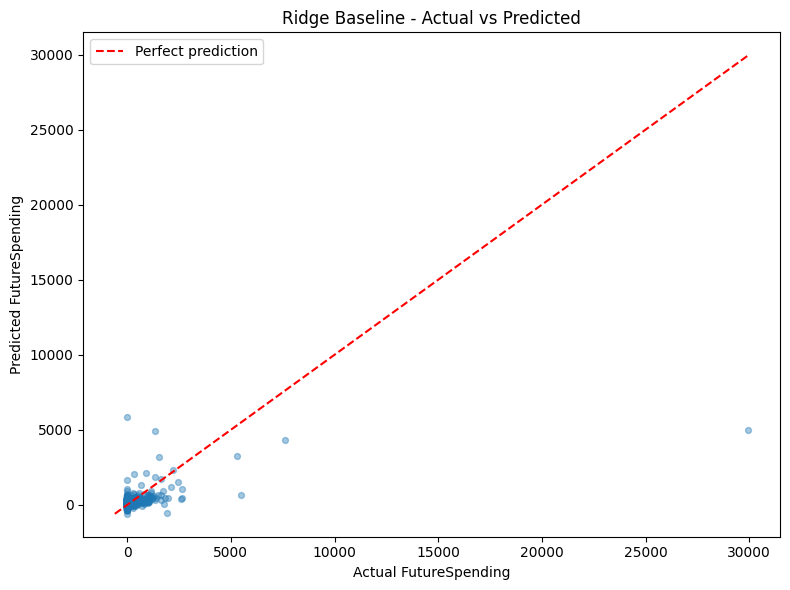

In [173]:
# Actual vs Predicted
plt.figure(figsize=(8, 6))

plt.scatter(
    y_actual,
    y_pred,
    alpha=0.4,
    s=18
)

plot_min = min(y_actual.min(), y_pred.min())
plot_max = max(y_actual.max(), y_pred.max())

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual FutureSpending")
plt.ylabel("Predicted FutureSpending")
plt.title("Ridge Baseline - Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

Phân tích sai số của Ridge Regression cho thấy **Mean Residual = −34,31** và **Median Residual = −93,58**. Với residual được tính bằng **giá trị thực tế trừ giá trị dự đoán**, các kết quả âm cho thấy mô hình có xu hướng dự đoán cao hơn thực tế trên Test Set.

**Median Absolute Error đạt 151,96**, trong khi sai số tuyệt đối lớn nhất lên tới **24.984,43**, cho thấy sự chênh lệch lớn giữa sai số điển hình và sai số cực trị.

Đáng chú ý, chỉ **10 quan sát, tương đương 0,88% Test Set**, đóng góp **89,54% tổng squared error**. Vì vậy, MSE và RMSE chịu ảnh hưởng mạnh từ một số ít dự đoán có sai số rất lớn. Kết quả cần được xem xét cùng MAE và bảng sai số riêng của hai nhóm khách hàng có chi tiêu bằng 0 và lớn hơn 0.

### 2.5 Lưu baseline làm mốc so sánh Feature Selection

In [174]:
# Lưu cấu hình Baseline
baseline_config = {
    "Model": "Ridge",
    "Alpha": ridge_fitted.named_steps["model"].alpha,

    "Reference Models": [
        "DummyRegressor (mean)",
        "DummyRegressor (median)"
    ],

    "Feature Selection": "None",
    "Number of Features": X_train.shape[1],
    "Features": X_train.columns.tolist(),
    "Target": y_train.name,

    "Train Samples": len(X_train),
    "Test Samples": len(X_test),
    "Test Size": 0.20,
    "Random State": RANDOM_STATE,

    "CV Strategy": "KFold",
    "CV Folds": cv.n_splits,
    "CV Shuffle": cv.shuffle,
    "CV Random State": cv.random_state,

    "Imputation": "Median",
    "Scaling": "StandardScaler"
}

# Hiển thị bảng cấu hình
config_table = pd.DataFrame([
    {
        "Parameter": parameter,
        "Value": value
    }
    for parameter, value in baseline_config.items()
])

print("=== BASELINE CONFIGURATION ===")
display(config_table)

=== BASELINE CONFIGURATION ===


,Parameter,Value
0,Model,Ridge
1,Alpha,1.0
2,Reference Models,"[DummyRegressor (mean), DummyRegressor (median)]"
3,Feature Selection,None
4,Number of Features,14
5,Features,"[Recency, Frequency, Monetary, AveragePurchase..."
6,Target,FutureSpending
7,Train Samples,4552
8,Test Samples,1139
9,Test Size,0.2


In [175]:
# Tổng hợp kết quả Baseline

ridge_cv = baseline_cv_results.loc[
    baseline_cv_results["Model"] == "Ridge"
].iloc[0]

ridge_test = baseline_test_results.loc[
    baseline_test_results["Model"] == "Ridge"
].iloc[0]

baseline_performance = pd.DataFrame([
    {
        "Model": "Ridge",
        "Dataset": "5-Fold CV",
        "Features": baseline_config["Number of Features"],
        "MAE": ridge_cv["MAE"],
        "MSE": ridge_cv["MSE"],
        "RMSE": ridge_cv["RMSE"],
        "R2": ridge_cv["R2"]
    },
    {
        "Model": "Ridge",
        "Dataset": "Test",
        "Features": baseline_config["Number of Features"],
        "MAE": ridge_test["MAE"],
        "MSE": ridge_test["MSE"],
        "RMSE": ridge_test["RMSE"],
        "R2": ridge_test["R2"]
    }
])

print("=== OFFICIAL RIDGE BASELINE ===")
display(baseline_performance.round(4))

=== OFFICIAL RIDGE BASELINE ===


,Model,Dataset,Features,MAE,MSE,RMSE,R2
0,Ridge,5-Fold CV,14,294.4401,6.860254e+06,1752.6631,0.2781
1,Ridge,Test,14,239.5096,7.132639e+05,844.5495,0.2714


In [176]:
# Tạo thư mục lưu kết quả Baseline
output_dir = RESULTS_DIR / "baseline_results"
output_dir.mkdir(parents=True, exist_ok=True)

# Lưu cấu hình mô hình
with (output_dir / "baseline_config.json").open(
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        baseline_config,
        f,
        indent=4,
        ensure_ascii=False
    )

# Các bảng kết quả cần lưu
result_tables = {
    "baseline_cv_results.csv": baseline_cv_results,
    "baseline_test_results.csv": baseline_test_results,
    "baseline_performance.csv": baseline_performance,
    "baseline_fold_results.csv": baseline_fold_results,
    "baseline_group_errors.csv": baseline_group_errors
}

for filename, table in result_tables.items():
    table.to_csv(
        output_dir / filename,
        index=False
    )

# Các pipeline đã huấn luyện
fitted_pipelines = {
    "dummy_mean_pipeline.joblib": dummy_fitted,
    "dummy_median_pipeline.joblib": dummy_median_fitted,
    "ridge_baseline_pipeline.joblib": ridge_fitted
}

for filename, pipeline in fitted_pipelines.items():
    joblib.dump(
        pipeline,
        output_dir / filename
    )

# Hiển thị các file đã lưu
print("=== SAVED BASELINE ARTIFACTS ===")
print("Thư mục:", output_dir)

for filename in sorted(os.listdir(output_dir)):
    print(filename)

=== SAVED BASELINE ARTIFACTS ===
Thư mục: ket_qua_feature_selection/baseline_results
baseline_config.json
baseline_cv_results.csv
baseline_fold_results.csv
baseline_group_errors.csv
baseline_performance.csv
baseline_test_results.csv
dummy_mean_pipeline.joblib
dummy_median_pipeline.joblib
ridge_baseline_pipeline.joblib


In [177]:
# Kiểm tra kết quả đã lưu

# Đọc lại cấu hình
with open(
    os.path.join(output_dir, "baseline_config.json"),
    "r",
    encoding="utf-8"
) as f:
    loaded_config = json.load(f)

# Đọc lại kết quả
loaded_performance = pd.read_csv(
    os.path.join(output_dir, "baseline_performance.csv")
)

# Đọc lại pipeline
loaded_pipeline = joblib.load(
    os.path.join(output_dir, "ridge_baseline_pipeline.joblib")
)

# Kiểm tra cấu hình
assert loaded_config == baseline_config
assert loaded_config["Number of Features"] == X_train.shape[1]
assert loaded_config["Features"] == X_train.columns.tolist()

# Kiểm tra kết quả
pd.testing.assert_frame_equal(
    loaded_performance,
    baseline_performance,
    check_exact=False,
    rtol=1e-10,
    atol=1e-10
)

# Kiểm tra khả năng tái tạo dự đoán
loaded_predictions = loaded_pipeline.predict(X_test)

assert np.allclose(
    loaded_predictions,
    y_pred_ridge
)

print("=== BASELINE VERIFICATION ===")
print("Configuration: PASSED")
print("Performance results: PASSED")
print("Model predictions: PASSED")

=== BASELINE VERIFICATION ===
Configuration: PASSED
Performance results: PASSED
Model predictions: PASSED


In [178]:
# Chỉ sử dụng Cross-Validation để lựa chọn phương pháp

feature_selection_comparison = pd.DataFrame([{
    "Method": "Baseline (No FS)",
    "Model": "Ridge",
    "Selected Features": baseline_config["Number of Features"],
    "CV MAE": ridge_cv["MAE"],
    "CV RMSE": ridge_cv["RMSE"],
    "CV R2": ridge_cv["R2"]
}])

display(feature_selection_comparison.round(4))

feature_selection_comparison.to_csv(
    os.path.join(
        output_dir,
        "feature_selection_comparison.csv"
    ),
    index=False
)

,Method,Model,Selected Features,CV MAE,CV RMSE,CV R2
0,Baseline (No FS),Ridge,14,294.4401,1752.6631,0.2781


Baseline **Ridge Regression** sử dụng toàn bộ **14 đặc trưng** đã được huấn luyện, đánh giá và lưu thành công. Mô hình đạt **MAE = 239,51**, **RMSE = 844,55** và **R² = 0,2714** trên Test Set.

Hai mô hình **Dummy mean và Dummy median** được lưu cùng Ridge để đối chiếu kết quả. Trong đó, Dummy median là mốc tham chiếu cần xem xét khi đánh giá MAE của dữ liệu có nhiều giá trị chi tiêu bằng 0.

Cấu hình mô hình, kết quả Cross-Validation và pipeline đã được kiểm tra, tạo mốc tham chiếu cố định cho các phương pháp Feature Selection tiếp theo. Việc lựa chọn cấu hình Feature Selection chỉ sử dụng CV trên Train.

## 3.Phân tích đặc trưng trước Feature Selection

### 3.1 Phân tích tương quan giữa các dặc trưng

=== INTER-FEATURE SPEARMAN CORRELATION ===
Number of features: 14


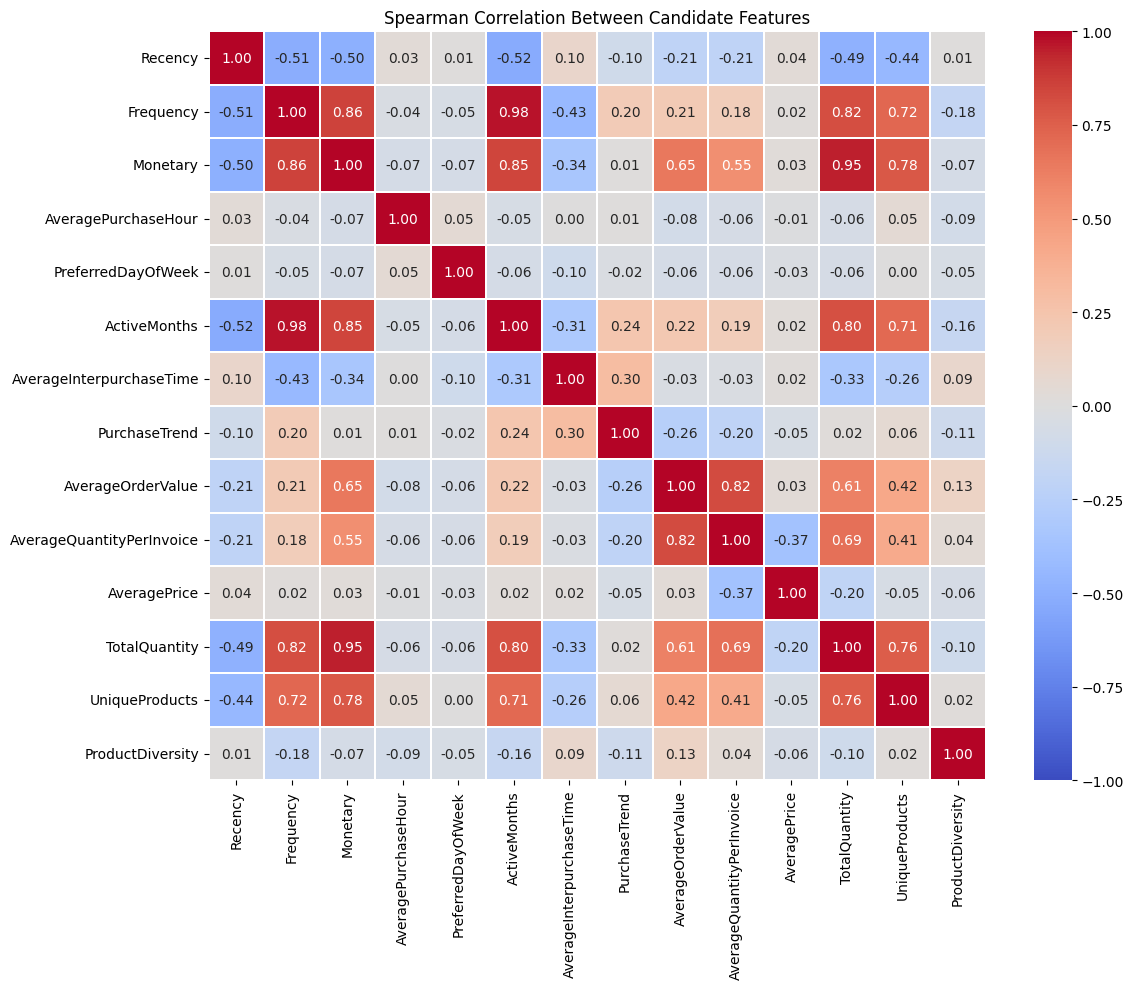

In [179]:
# Tính tương quan trên Train
feature_corr = X_train.corr(method="spearman")

print("=== INTER-FEATURE SPEARMAN CORRELATION ===")
print("Number of features:", feature_corr.shape[0])

plt.figure(figsize=(12, 10))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3
)

plt.title("Spearman Correlation Between Candidate Features")
plt.tight_layout()
plt.show()

In [180]:
corr_threshold = 0.8

upper_mask = np.triu(
    np.ones(feature_corr.shape, dtype=bool),
    k=1
)

strong_corr_pairs = (
    feature_corr
    .where(upper_mask)
    .stack()
    .reset_index()
)

strong_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Spearman Correlation"
]

strong_corr_pairs = strong_corr_pairs[
    strong_corr_pairs["Spearman Correlation"].abs()
    >= corr_threshold
].copy()

strong_corr_pairs["Absolute Correlation"] = (
    strong_corr_pairs["Spearman Correlation"].abs()
)

strong_corr_pairs = strong_corr_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
).reset_index(drop=True)

print("=== STRONGLY CORRELATED FEATURE PAIRS ===")
print("Threshold: |rho| >= 0.8")
print("Number of pairs:", len(strong_corr_pairs))

display(strong_corr_pairs.round(4))

=== STRONGLY CORRELATED FEATURE PAIRS ===
Threshold: |rho| >= 0.8
Number of pairs: 7


,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
0,Frequency,ActiveMonths,0.9765,0.9765
1,Monetary,TotalQuantity,0.9456,0.9456
2,Frequency,Monetary,0.8566,0.8566
3,Monetary,ActiveMonths,0.8466,0.8466
4,AverageOrderValue,AverageQuantityPerInvoice,0.8247,0.8247
5,Frequency,TotalQuantity,0.8157,0.8157
6,ActiveMonths,TotalQuantity,0.8047,0.8047


Phân tích Spearman trên tập Train phát hiện **7 cặp đặc trưng có tương quan mạnh (|ρ| ≥ 0,8)**, nổi bật là **Frequency–ActiveMonths (0,9765)** và **Monetary–TotalQuantity (0,9456)**.

Nhóm Frequency, Monetary, ActiveMonths và TotalQuantity có tương quan cao, cho thấy khả năng chồng lặp thông tin giữa các đặc trưng phản ánh mức độ hoạt động mua hàng.

Kết quả cung cấp cơ sở để nghiên cứu khả năng giảm dư thừa thông qua Feature Selection. Tuy nhiên, tương quan cao chưa đủ để quyết định loại một đặc trưng; hiệu quả cần được đánh giá bằng thực nghiệm. **Chưa có đặc trưng nào bị loại bỏ tại bước này.**

### 3.2 Phân tích quan hệ giữa đặc trưng và target

=== FEATURE–TARGET SPEARMAN CORRELATION ===


,Feature,Spearman with FutureSpending,Absolute Spearman,Valid Pairs,Missing Pairs
0,Recency,-0.3986,0.3986,4552,0
1,Frequency,0.3875,0.3875,4552,0
2,ActiveMonths,0.3815,0.3815,4552,0
3,Monetary,0.3807,0.3807,4552,0
4,TotalQuantity,0.3778,0.3778,4552,0
5,UniqueProducts,0.3577,0.3577,4552,0
6,AverageInterpurchaseTime,-0.3031,0.3031,3196,1356
7,AverageOrderValue,0.1659,0.1659,4552,0
8,AverageQuantityPerInvoice,0.1592,0.1592,4552,0
9,PurchaseTrend,0.0992,0.0992,4320,232


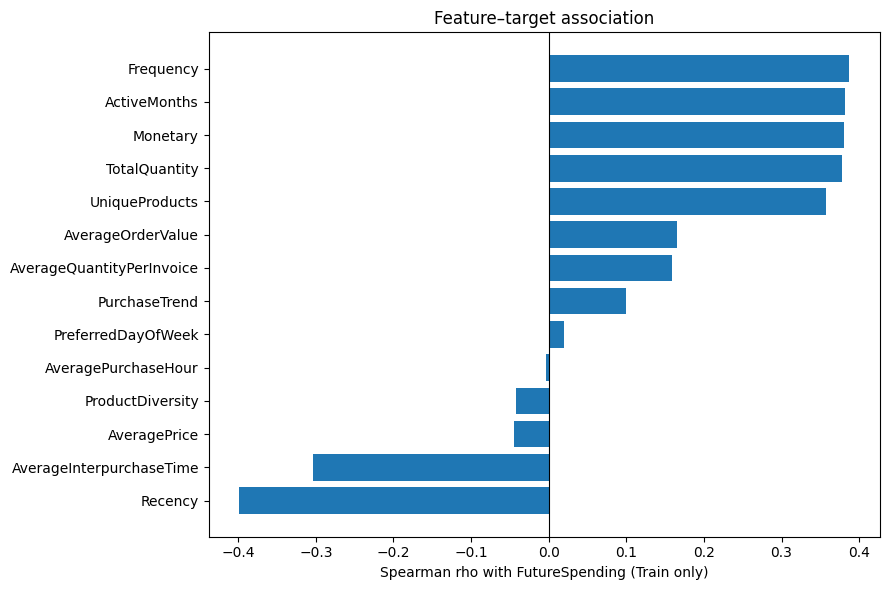

In [181]:
# 1. Tính tương quan từng feature với target trên Train
feature_target_rows = []

for feature in X_train.columns:

    # Chỉ giữ các cặp có đủ dữ liệu
    valid = (
        X_train[feature].notna()
        & y_train.notna()
    )

    rho, _ = spearmanr(
        X_train.loc[valid, feature],
        y_train.loc[valid]
    )

    feature_target_rows.append({
        "Feature": feature,
        "Spearman with FutureSpending": rho,
        "Absolute Spearman": abs(rho),
        "Valid Pairs": int(valid.sum()),
        "Missing Pairs": int((~valid).sum())
    })

# 2. Tạo bảng và sắp xếp theo độ mạnh tương quan
feature_target_corr = (
    pd.DataFrame(feature_target_rows)
    .sort_values(
        "Absolute Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)

# 3. Kiểm tra số feature và số cặp dữ liệu
assert len(feature_target_corr) == X_train.shape[1]

assert (
    feature_target_corr["Valid Pairs"]
    + feature_target_corr["Missing Pairs"]
    == len(X_train)
).all()

print("=== FEATURE–TARGET SPEARMAN CORRELATION ===")
display(feature_target_corr.round(4))


# 4. Vẽ biểu đồ tương quan
plot_data = feature_target_corr.sort_values(
    "Spearman with FutureSpending"
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Spearman with FutureSpending"]
)

plt.axvline(
    0,
    color="black",
    linewidth=0.8
)

plt.xlabel("Spearman rho with FutureSpending (Train only)")
plt.title("Feature–target association")
plt.tight_layout()


# 5. Lưu biểu đồ và bảng kết quả
plt.savefig(
    RESULTS_DIR / "feature_target_correlation.png",
    dpi=150
)

plt.show()

feature_target_corr.to_csv(
    RESULTS_DIR / "feature_target_correlation.csv",
    index=False
)

Spearman mô tả liên hệ đơn điệu; dấu dương/âm thể hiện chiều liên hệ với chi tiêu
tương lai. Target có nhiều số 0 nên có nhiều hạng đồng mức. Bảng ghi số cặp hợp lệ
vì các feature thiếu được loại theo từng cặp, không điền NaN bằng 0. Biến ngày trong
tuần là mã phân loại; tương quan của mã 0–6 chỉ có tính mô tả. Tương quan nhỏ không
đủ kết luận feature vô ích hoặc không có quan hệ phi tuyến. Không loại feature từ
bảng này; lựa chọn được thực hiện lại trong từng CV training fold.

## 4.Các phương pháp Feature Selection

### 4.1 Filter Methods - Phương pháp lọc

Trong nhóm **Filter Methods**, nghiên cứu sử dụng hai phương pháp:

- **F-test Regression:** Đánh giá mức độ liên hệ tuyến tính giữa từng đặc trưng và `FutureSpending`.
- **Mutual Information Regression:** Đánh giá mức độ phụ thuộc thống kê, bao gồm cả quan hệ phi tuyến.

Hai phương pháp sử dụng **SelectKBest** để khảo sát số lượng đặc trưng **k từ 1 đến 14**. Hiệu quả được đánh giá bằng **Ridge Regression (`alpha=1.0`) và 5-Fold Cross-Validation trên tập Train**, sử dụng cùng cấu hình baseline.

Cấu hình được lựa chọn theo **MAE trung bình CV thấp nhất**; MSE, RMSE và R² được báo cáo bổ sung. Tiền xử lý và lựa chọn đặc trưng được thực hiện trong pipeline của từng training fold. **Tập Test không tham gia quá trình lựa chọn k.**

In [182]:
# Cấu hình thực nghiệm (Experiment Configuration)

# Số lượng đặc trưng cần khảo sát
n_features = X_train.shape[1]
k_values = list(range(1, n_features + 1))

# Dùng cùng alpha với Ridge baseline
ridge_alpha = ridge_baseline.named_steps["model"].alpha


# Xác định biến rời rạc cho Mutual Information
discrete_features = (
    X_train.columns == "PreferredDayOfWeek"
)

# Khai báo các phương pháp Filter
filter_methods = {
    "F-test": f_regression,

    "Mutual Information": partial(
        mutual_info_regression,
        discrete_features=discrete_features,
        random_state=RANDOM_STATE
    )
}

# Xây dựng Pipeline cho Filter Methods
def build_filter_pipeline(method, k):
    return Pipeline(steps=[
        (
            "imputer",
            SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )
        ),
        (
            "selector",
            SelectKBest(
                score_func=filter_methods[method],
                k=k
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            Ridge(alpha=ridge_alpha)
        )
    ])

# Hiển thị cấu hình thực nghiệm
filter_config = pd.DataFrame({
    "Parameter": [
        "Filter Methods",
        "Candidate Features",
        "Selected Features (k)",
        "Evaluation Model",
        "Ridge Alpha",
        "Cross-Validation",
        "CV Random State",
        "MI Random State",
        "Discrete Feature (MI)",
        "Selection Criterion",
        "Evaluation Metrics",
        "Dataset"
    ],

    "Value": [
        ", ".join(filter_methods.keys()),
        n_features,
        f"{min(k_values)} - {max(k_values)}",
        "Ridge Regression",
        ridge_alpha,
        f"{cv.n_splits}-Fold KFold",
        cv.random_state,
        RANDOM_STATE,
        "PreferredDayOfWeek",
        "Minimum mean CV MAE",
        ", ".join(scoring.keys()),
        "Train only"
    ]
})

print("=== FILTER METHODS CONFIGURATION ===")
display(filter_config)

=== FILTER METHODS CONFIGURATION ===


,Parameter,Value
0,Filter Methods,"F-test, Mutual Information"
1,Candidate Features,14
2,Selected Features (k),1 - 14
3,Evaluation Model,Ridge Regression
4,Ridge Alpha,1.0
5,Cross-Validation,5-Fold KFold
6,CV Random State,42
7,MI Random State,42
8,Discrete Feature (MI),PreferredDayOfWeek
9,Selection Criterion,Minimum mean CV MAE


In [183]:
# Chuẩn bị nơi lưu kết quả
filter_results = []
filter_fold_rows = []

# Giữ cùng các fold cho mọi phương pháp và giá trị k
filter_cv_splits = list(cv.split(X_train, y_train))

filter_search_start = perf_counter()

for method in filter_methods:

    for k in k_values:
        pipeline = build_filter_pipeline(method, k)

        # Đo thời gian đánh giá cấu hình hiện tại
        start = perf_counter()

        scores = cross_validate(
            estimator=pipeline,
            X=X_train,
            y=y_train,
            cv=filter_cv_splits,
            scoring=scoring,
            n_jobs=N_JOBS,
            error_score="raise"
        )

        cv_seconds = perf_counter() - start

        result = {
            "Method": method,
            "k": k,
            "CV Wall Seconds": cv_seconds,
            "Mean Fit Seconds": scores["fit_time"].mean(),
            "Mean Score Seconds": scores["score_time"].mean()
        }

        # Giữ các giá trị metric của từng fold
        fold_metric_values = {}

        for metric in scoring:
            values = scores[f"test_{metric}"]

            # Chuyển các chỉ số sai số về giá trị dương
            if metric in ["MAE", "MSE", "RMSE"]:
                values = -values

            fold_metric_values[metric] = values

            # Tổng hợp trung bình và độ lệch chuẩn
            result[metric] = values.mean()
            result[f"{metric}_std"] = values.std(ddof=0)

        filter_results.append(result)

        # Lưu kết quả chi tiết từng fold
        for fold_index in range(len(filter_cv_splits)):
            fold_result = {
                "Method": method,
                "k": k,
                "Fold": fold_index + 1,
                "Fit Seconds": scores["fit_time"][fold_index],
                "Score Seconds": scores["score_time"][fold_index]
            }

            for metric, values in fold_metric_values.items():
                fold_result[metric] = values[fold_index]

            filter_fold_rows.append(fold_result)

# Tổng thời gian khảo sát tất cả cấu hình
filter_search_seconds = (
    perf_counter() - filter_search_start
)

# Tạo các bảng kết quả
filter_results_df = pd.DataFrame(filter_results)

filter_fold_results = pd.DataFrame(filter_fold_rows)

# Kiểm tra đủ số cấu hình và số kết quả fold
expected_configs = len(filter_methods) * len(k_values)

assert len(filter_results_df) == expected_configs

assert (
    len(filter_fold_results)
    == expected_configs * cv.n_splits
)

# Hiển thị kết quả
print("=== FILTER CROSS-VALIDATION RESULTS ===")
display(filter_results_df.round(4))

print("Số cấu hình đã đánh giá:", len(filter_results_df))
print("Số kết quả từng fold:", len(filter_fold_results))

print(
    "Tổng thời gian khảo sát (giây):",
    round(filter_search_seconds, 3)
)

=== FILTER CROSS-VALIDATION RESULTS ===


,Method,k,CV Wall Seconds,Mean Fit Seconds,Mean Score Seconds,MAE,MAE_std,MSE,MSE_std,RMSE,RMSE_std,R2,R2_std
0,F-test,1,0.0903,0.0117,0.0056,276.0972,56.9963,6.753349e+06,1.230829e+07,1713.3791,1953.8886,0.3474,0.2006
1,F-test,2,0.0887,0.0114,0.0056,270.7879,58.7554,6.665786e+06,1.235859e+07,1662.9455,1974.9426,0.4062,0.2255
2,F-test,3,0.0944,0.0120,0.0059,256.3655,57.1648,6.671534e+06,1.236220e+07,1659.7795,1979.0569,0.4219,0.2324
3,F-test,4,0.0864,0.0110,0.0055,257.8396,56.7308,6.676585e+06,1.236217e+07,1662.4870,1978.0601,0.4184,0.2313
4,F-test,5,0.0867,0.0111,0.0055,266.1034,54.1069,6.664342e+06,1.236252e+07,1655.3114,1980.9812,0.4272,0.2371
5,F-test,6,0.0876,0.0113,0.0055,262.6730,54.7535,6.659994e+06,1.236258e+07,1652.2147,1982.4683,0.4314,0.2404
6,F-test,7,0.0868,0.0111,0.0055,264.3006,55.6364,6.667521e+06,1.235277e+07,1658.9033,1978.7776,0.4214,0.2381
7,F-test,8,0.0862,0.0110,0.0055,264.7548,54.6146,6.667177e+06,1.235054e+07,1659.4659,1978.2189,0.4206,0.2367
8,F-test,9,0.0895,0.0114,0.0058,281.0150,50.7497,6.671901e+06,1.234669e+07,1663.9573,1975.6385,0.4132,0.2336
9,F-test,10,0.1055,0.0133,0.0069,284.5212,50.1041,6.675652e+06,1.235136e+07,1666.0546,1974.8200,0.4108,0.2281


Số cấu hình đã đánh giá: 28
Số kết quả từng fold: 140
Tổng thời gian khảo sát (giây): 28.238


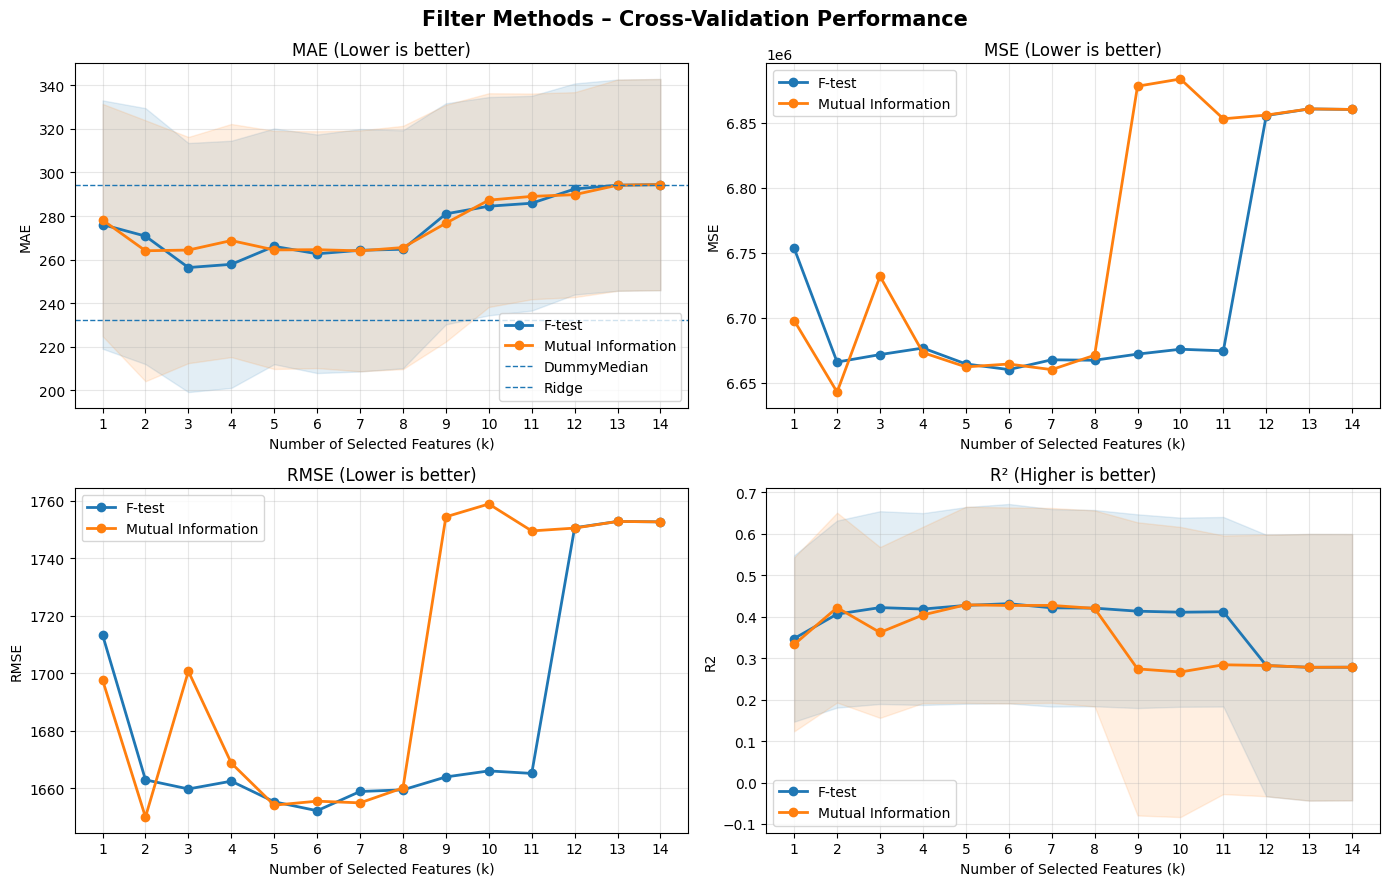

In [184]:
# Trực quan hóa hiệu suất Cross-Validation
metrics = {
    "MAE": "MAE (Lower is better)",
    "MSE": "MSE (Lower is better)",
    "RMSE": "RMSE (Lower is better)",
    "R2": "R² (Higher is better)"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, (metric, title) in zip(axes, metrics.items()):
    for method, group in filter_results_df.groupby("Method"):
        group = group.sort_values("k")

        x = group["k"].to_numpy()
        mean = group[metric].to_numpy()
        std = group[f"{metric}_std"].to_numpy()

        line, = ax.plot(
            x, mean,
            marker="o",
            linewidth=2,
            label=method
        )

        # Chỉ hiển thị vùng độ lệch chuẩn cho MAE và R²
        if metric in ["MAE", "R2"]:
            ax.fill_between(
                x,
                mean - std,
                mean + std,
                color=line.get_color(),
                alpha=0.12
            )

    if metric == 'MAE':
        for baseline_name in ['DummyMedian', 'Ridge']:
            value = baseline_cv_results.loc[baseline_cv_results['Model']==baseline_name, 'MAE'].iloc[0]
            ax.axhline(value, linestyle='--', linewidth=1, label=baseline_name)
    ax.set_title(title)
    ax.set_xlabel("Number of Selected Features (k)")
    ax.set_ylabel(metric)
    ax.set_xticks(k_values)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Filter Methods – Cross-Validation Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(RESULTS_DIR/'filter_cv_performance.png', dpi=150)
plt.show()

**Nhận xét:**

Kết quả 5-Fold Cross-Validation cho thấy cả F-test và Mutual Information đều có các cấu hình sử dụng ít đặc trưng đạt hiệu quả tốt hơn so với sử dụng toàn bộ 14 đặc trưng.

Theo tiêu chí **MAE trung bình thấp nhất**:

- **F-test đạt tốt nhất tại k = 3**, với MAE = **256,3655**.
- **Mutual Information đạt tốt nhất tại k = 7**, với MAE = **264,0290**.

Các chỉ số khác không nhất thiết đạt tối ưu tại cùng k. F-test đạt RMSE thấp nhất và R² cao nhất tại **k = 6**. Mutual Information đạt RMSE thấp nhất tại **k = 2**, còn R² cao nhất tại **k = 5**. Vì vậy, nghiên cứu giữ MAE làm tiêu chí lựa chọn đã xác định trước.

Khi tăng số đặc trưng, đặc biệt từ k = 9 trở đi, hiệu quả nhìn chung giảm so với các cấu hình tốt nhất. Tuy nhiên, độ biến động giữa các fold vẫn lớn. Riêng Mutual Information, MAE tại **k = 2 (264,0683)** rất gần với **k = 7**, nên chưa nên diễn giải k = 7 là cấu hình vượt trội rõ rệt.

Cả hai phương pháp cải thiện MAE so với Ridge đầy đủ nhưng **chưa vượt Dummy median**, có MAE trung bình CV = **232,1873**.

In [185]:
# 1. Chọn k tốt nhất theo MAE
# Nếu MAE bằng nhau, ưu tiên số đặc trưng ít hơn
optimal_filter_results = (
    filter_results_df
    .sort_values(["MAE", "k"])
    .drop_duplicates(
        subset="Method",
        keep="first"
    )
    .reset_index(drop=True)
)

# 2. Lấy kết quả dùng toàn bộ đặc trưng
full_feature_results = (
    filter_results_df.loc[
        filter_results_df["k"] == n_features,
        ["Method", "MAE", "RMSE", "R2"]
    ]
    .rename(columns={
        "MAE": "Full MAE",
        "RMSE": "Full RMSE",
        "R2": "Full R2"
    })
)

# Ghép cấu hình được chọn với cấu hình đầy đủ
filter_comparison = optimal_filter_results.merge(
    full_feature_results,
    on="Method",
    validate="one_to_one"
)

# 3. Lấy MAE trung bình CV của Dummy median
median_cv_mae = float(
    baseline_cv_results.loc[
        baseline_cv_results["Model"] == "DummyMedian",
        "MAE"
    ].iloc[0]
)

# 4. Mức cải thiện so với cấu hình đầy đủ
filter_comparison["MAE Improvement (%)"] = (
    (
        filter_comparison["Full MAE"]
        - filter_comparison["MAE"]
    )
    / filter_comparison["Full MAE"]
    * 100
)

filter_comparison["RMSE Improvement (%)"] = (
    (
        filter_comparison["Full RMSE"]
        - filter_comparison["RMSE"]
    )
    / filter_comparison["Full RMSE"]
    * 100
)

filter_comparison["R2 Improvement"] = (
    filter_comparison["R2"]
    - filter_comparison["Full R2"]
)


# 5. Mức cải thiện MAE so với Dummy median
filter_comparison["MAE vs Median Improvement (%)"] = (
    (
        median_cv_mae
        - filter_comparison["MAE"]
    )
    / median_cv_mae
    * 100
)

# 6. Tỷ lệ giảm số đặc trưng
filter_comparison["Feature Reduction (%)"] = (
    (
        n_features
        - filter_comparison["k"]
    )
    / n_features
    * 100
)

# 7. Hiển thị bảng tổng hợp
comparison_summary = (
    filter_comparison[[
        "Method",
        "k",
        "MAE",
        "MAE_std",
        "RMSE",
        "R2",
        "Feature Reduction (%)",
        "MAE Improvement (%)",
        "MAE vs Median Improvement (%)",
        "RMSE Improvement (%)",
        "R2 Improvement"
    ]]
    .rename(columns={
        "k": "Optimal k",
        "MAE": "CV MAE",
        "MAE_std": "MAE Std",
        "RMSE": "CV RMSE",
        "R2": "CV R²"
    })
)
print("=== OPTIMAL K SELECTION & PERFORMANCE COMPARISON ===")
display(comparison_summary.round(4))

=== OPTIMAL K SELECTION & PERFORMANCE COMPARISON ===


,Method,Optimal k,CV MAE,MAE Std,CV RMSE,CV R²,Feature Reduction (%),MAE Improvement (%),MAE vs Median Improvement (%),RMSE Improvement (%),R2 Improvement
0,F-test,3,256.3655,57.1648,1659.7795,0.4219,78.5714,12.9312,-10.4132,5.2996,0.1438
1,Mutual Information,7,264.0290,55.2778,1654.9486,0.4272,50.0000,10.3285,-13.7138,5.5752,0.1491


**Nhận xét:**

Kết quả Cross-Validation cho thấy số lượng đặc trưng đạt MAE thấp nhất khác nhau giữa hai phương pháp:

- **F-test:** Tốt nhất tại **k = 3**, với **MAE = 256,3655**, cải thiện **12,93%** so với sử dụng toàn bộ 14 đặc trưng.
- **Mutual Information:** Tốt nhất tại **k = 7**, với **MAE = 264,0290**, cải thiện **10,33%**.

Tại các cấu hình được chọn, F-test có MAE thấp hơn, trong khi Mutual Information có RMSE thấp hơn và R² cao hơn. Tuy nhiên, kết quả giữa các fold vẫn biến động và cả hai cấu hình đều **chưa vượt Dummy median về MAE**.

Riêng Mutual Information, MAE tại k = 2 rất gần với k = 7, nên kết quả chưa thể hiện lợi thế rõ rệt của việc giữ nhiều đặc trưng hơn.

**Kết luận:** Theo tiêu chí MAE trung bình CV thấp nhất trong khoảng khảo sát **1–14 đặc trưng**, lựa chọn **k = 3 cho F-test** và **k = 7 cho Mutual Information** để tiếp tục xác định và phân tích các đặc trưng được chọn.

In [186]:
# Chuẩn bị nơi lưu kết quả
filter_rankings = []
selected_features = {}
fitted_filter_pipelines = {}
filter_stage_timings = []

for method in filter_methods:

    # Lấy k đã chọn bằng Cross-Validation
    optimal_k = int(
        optimal_filter_results.loc[
            optimal_filter_results["Method"] == method,
            "k"
        ].iloc[0]
    )

    pipeline = build_filter_pipeline(method, optimal_k)

    # Fit từng bước để đo riêng thời gian
    start = perf_counter()

    train_imputed = (
        pipeline.named_steps["imputer"]
        .fit_transform(X_train)
    )

    imputation_seconds = perf_counter() - start


    # Chọn đặc trưng
    start = perf_counter()

    selected_train = (
        pipeline.named_steps["selector"]
        .fit_transform(train_imputed, y_train)
    )

    selection_seconds = perf_counter() - start

    # Chuẩn hóa các đặc trưng được chọn
    start = perf_counter()

    scaled_train = (
        pipeline.named_steps["scaler"]
        .fit_transform(selected_train)
    )

    scaling_seconds = perf_counter() - start

    # Huấn luyện Ridge
    start = perf_counter()

    pipeline.named_steps["model"].fit(
        scaled_train,
        y_train
    )

    regression_fit_seconds = perf_counter() - start

    # Đo dự đoán trên Train, chưa sử dụng Test
    start = perf_counter()

    train_prediction = pipeline.predict(X_train)

    train_predict_seconds = perf_counter() - start

    assert np.isfinite(train_prediction).all()

    # Giữ pipeline đã huấn luyện để lưu sau
    fitted_filter_pipelines[method] = pipeline

    # Lưu thời gian từng giai đoạn
    method_search_seconds = filter_results_df.loc[
        filter_results_df["Method"] == method,
        "CV Wall Seconds"
    ].sum()

    filter_stage_timings.append({
        "Method": method,
        "k": optimal_k,
        "Search CV Seconds": method_search_seconds,
        "Imputation Seconds": imputation_seconds,
        "Selection Seconds": selection_seconds,
        "Scaling Seconds": scaling_seconds,
        "Regression Fit Seconds": regression_fit_seconds,
        "Predict Train Seconds": train_predict_seconds,
        "Predict Samples": len(X_train)
    })

    # Xếp hạng đặc trưng trên toàn bộ Train
    selector = pipeline.named_steps["selector"]

    ranking = pd.DataFrame({
        "Feature": X_train.columns,
        "Score": selector.scores_,
        "Selected": selector.get_support()
    })

    ranking["Rank"] = (
        ranking["Score"]
        .rank(
            ascending=False,
            method="first"
        )
        .astype(int)
    )

    ranking = (
        ranking
        .sort_values("Rank")
        .reset_index(drop=True)
    )

    ranking.insert(0, "Method", method)
    filter_rankings.append(ranking)

    # Danh sách đặc trưng được chọn
    selected_features[method] = ranking.loc[
        ranking["Selected"],
        "Feature"
    ].tolist()

# Tổng hợp bảng xếp hạng
filter_ranking_df = pd.concat(
    filter_rankings,
    ignore_index=True
)

ranking_comparison = (
    filter_ranking_df
    .pivot(
        index="Feature",
        columns="Method",
        values="Rank"
    )
    .sort_values(["F-test", "Mutual Information"])
)

print("=== FEATURE RANKING (ALL 14 FEATURES) ===")
display(ranking_comparison)

# Dùng Series để hỗ trợ số feature khác nhau
top_features_comparison = pd.DataFrame({
    method: pd.Series(features)
    for method, features in selected_features.items()
})

top_features_comparison.index = range(
    1,
    len(top_features_comparison) + 1
)

top_features_comparison.index.name = "Rank"

print("\n=== SELECTED FEATURES ===")
display(top_features_comparison.fillna("—"))

# Các đặc trưng được cả hai phương pháp lựa chọn
common_features = (
    set(selected_features["F-test"])
    & set(selected_features["Mutual Information"])
)

print("\nCommon selected features:", len(common_features))
print("Features:", sorted(common_features))

# Tổng hợp thời gian
filter_timing_df = pd.DataFrame(filter_stage_timings)

print("\n=== FILTER COMPUTATIONAL COST ===")
display(filter_timing_df.round(6))

=== FEATURE RANKING (ALL 14 FEATURES) ===


Method,F-test,Mutual Information
Feature,,
Monetary,1,1
TotalQuantity,2,2
Frequency,3,3
UniqueProducts,4,6
ActiveMonths,5,4
AverageOrderValue,6,8
Recency,7,7
AverageInterpurchaseTime,8,5
AveragePurchaseHour,9,10



=== SELECTED FEATURES ===


,F-test,Mutual Information
Rank,,
1,Monetary,Monetary
2,TotalQuantity,TotalQuantity
3,Frequency,Frequency
4,—,ActiveMonths
5,—,AverageInterpurchaseTime
6,—,UniqueProducts
7,—,Recency



Common selected features: 3
Features: ['Frequency', 'Monetary', 'TotalQuantity']

=== FILTER COMPUTATIONAL COST ===


,Method,k,Search CV Seconds,Imputation Seconds,Selection Seconds,Scaling Seconds,Regression Fit Seconds,Predict Train Seconds,Predict Samples
0,F-test,3,1.262362,0.009923,0.001652,0.000771,0.001196,0.002891,4552
1,Mutual Information,7,26.968494,0.007353,0.386580,0.001595,0.002115,0.004119,4552


**Nhận xét:**

Kết quả xếp hạng trên toàn bộ Train cho thấy **Monetary** giữ vị trí cao nhất ở cả F-test và Mutual Information, phản ánh mối liên hệ thống kê nổi bật giữa chi tiêu trong quá khứ và `FutureSpending`.

Các tập đặc trưng được lựa chọn gồm:

- **F-test, k = 3:** `Monetary`, `TotalQuantity`, `Frequency`.
- **Mutual Information, k = 7:** `Monetary`, `TotalQuantity`, `Frequency`, `ActiveMonths`, `AverageInterpurchaseTime`, `UniqueProducts`, `Recency`.

Hai phương pháp có **3 đặc trưng chung** là `Monetary`, `TotalQuantity` và `Frequency`. Toàn bộ tập đặc trưng của F-test nằm trong tập được Mutual Information lựa chọn.

Mutual Information giữ thêm các đặc trưng mô tả mức độ duy trì hoạt động, khoảng cách giữa các lần mua, phạm vi sản phẩm và mức độ gần đây của lần mua. Tuy nhiên, việc giữ nhiều đặc trưng hơn chưa đủ để kết luận phương pháp này dự đoán tốt hơn.

**Kết luận:** Hai tập đặc trưng được xác định bằng cách fit trên toàn bộ Train sau khi chọn k qua Cross-Validation. Chúng được lưu để phục vụ các bước so sánh tiếp theo; mức độ ổn định của việc lựa chọn cần được xem xét qua từng fold.

**Tổng kết:**

Thực nghiệm **Filter Methods** đã đánh giá hai phương pháp **F-test và Mutual Information** với số lượng đặc trưng **từ 1 đến 14**, sử dụng **Ridge Regression (`alpha=1.0`) và 5-Fold Cross-Validation trên Train**. Cấu hình được lựa chọn theo MAE trung bình CV thấp nhất.

**Kết quả chính:**

| Phương pháp | k được chọn | CV MAE | Cải thiện MAE so với Ridge đủ 14 feature | Giảm số feature |
|---|---:|---:|---:|---:|
| F-test | 3 | 256,3655 | 12,93% | 78,57% |
| Mutual Information | 7 | 264,0290 | 10,33% | 50,00% |

Các đặc trưng được lựa chọn khi fit trên toàn bộ Train gồm:

- **F-test:** `Monetary`, `TotalQuantity`, `Frequency`.
- **Mutual Information:** `Monetary`, `TotalQuantity`, `Frequency`, `ActiveMonths`, `AverageInterpurchaseTime`, `UniqueProducts`, `Recency`.

Hai phương pháp có **3 đặc trưng chung** là `Monetary`, `TotalQuantity` và `Frequency`. F-test tạo tập đặc trưng nhỏ hơn và đạt MAE thấp hơn tại các cấu hình được chọn.

Tuy nhiên, cả hai phương pháp **chưa vượt Dummy median về MAE**, với mốc tham chiếu **232,1873**. Kết quả giữa các fold vẫn biến động đáng kể, đặc biệt ở RMSE. Ngoài ra, MAE của Mutual Information tại k = 2 gần với k = 7, nên lợi thế của việc giữ thêm đặc trưng chưa rõ rệt.

**Kết luận:** Filter Methods giúp giảm số đặc trưng và cải thiện MAE so với Ridge đầy đủ trong thực nghiệm hiện tại. Các cấu hình được chọn là tốt nhất theo MAE trong lưới khảo sát, chưa phải bộ đặc trưng tối ưu cuối cùng. Chúng sẽ tiếp tục được so sánh với Wrapper Methods, Embedded Methods và phương pháp đề xuất trước khi chốt cấu hình kiểm chứng trên Test.

### 4.2 Wrapper Methods - Phương pháp bao

Wrapper đánh giá tập đặc trưng thông qua mô hình Ridge. Nghiên cứu khảo sát **RFE (loại dần)** và **SFS forward (thêm dần)** với k = 1–14, cùng alpha, các fold ngoài và các chỉ số như Filter. Chọn k theo MAE trung bình CV thấp nhất; nếu bằng nhau, ưu tiên k nhỏ hơn.

RFE loại đặc trưng có trị tuyệt đối hệ số Ridge nhỏ nhất sau chuẩn hóa. SFS chọn đặc trưng bổ sung theo MAE của CV nội bộ 5 fold. Tiền xử lý của SFS được đặt trong mô hình đánh giá ứng viên để học lại trên từng training fold nội bộ. Khi k = 14, đây là cấu hình đầy đủ, không thực hiện lựa chọn.

Mỗi đường đi được xây dựng một lần trên mỗi training fold ngoài và dùng lại cho các k. Validation fold ngoài không tham gia xây dựng đường đi. **Không dùng Test trong mục này.** CV ngoài dùng để khảo sát và chọn k, vì vậy kết quả tốt nhất có thể lạc quan do lựa chọn cấu hình; kiểm chứng cuối cùng được thực hiện sau khi chốt phương pháp.

In [187]:
# Cấu hình thực nghiệm

wrapper_methods = ["RFE", "SFS"]
wrapper_features = X_train.columns.tolist()
wrapper_k_values = list(range(1, len(wrapper_features) + 1))
wrapper_alpha = ridge_baseline.named_steps["model"].alpha
wrapper_outer_splits = list(cv.split(X_train, y_train))
wrapper_inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
wrapper_dir = Path(RESULTS_DIR) / "wrapper_results"
wrapper_dir.mkdir(parents=True, exist_ok=True)
assert X_train.index.equals(y_train.index)
assert X_train.columns.is_unique
assert np.isfinite(y_train.to_numpy()).all()

# Giữ cột rỗng để tên đặc trưng luôn khớp với hệ số.
def wrapper_regressor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=wrapper_alpha))
    ])

def wrapper_prediction_pipeline(features):
    return Pipeline([
        ("columns", ColumnTransformer(
            [("selected", "passthrough", list(features))], remainder="drop")),
        ("regression", wrapper_regressor())
    ])

wrapper_config = pd.DataFrame({
    "Parameter": ["Methods", "Candidate features", "k", "Model", "Alpha",
                  "Outer CV", "SFS inner CV", "Selection", "Dataset"],
    "Value": [", ".join(wrapper_methods), len(wrapper_features),
              f"1–{len(wrapper_features)} (full set: no selection)", "Ridge",
              wrapper_alpha, f"{cv.n_splits} folds; same splits as Filter",
              "5-fold shuffled KFold", "Minimum mean CV MAE; ties: smaller k", "Train only"]
})
display(wrapper_config)


,Parameter,Value
0,Methods,"RFE, SFS"
1,Candidate features,14
2,k,1–14 (full set: no selection)
3,Model,Ridge
4,Alpha,1.0
5,Outer CV,5 folds; same splits as Filter
6,SFS inner CV,5-fold shuffled KFold
7,Selection,Minimum mean CV MAE; ties: smaller k
8,Dataset,Train only


In [188]:
# Thứ tự cột gốc quyết định khi điểm/hệ số bằng nhau.
def wrapper_path(method, X_fit, y_fit):
    start = perf_counter()
    features = X_fit.columns.tolist()
    paths = {len(features): features.copy()}
    elapsed = {len(features): 0.0}
    trace = []
    if method == "RFE":
        kept = features.copy()
        while len(kept) > 1:
            model = wrapper_regressor().fit(X_fit[kept], y_fit)
            importance = np.abs(model.named_steps["model"].coef_)
            removed = kept.pop(int(np.argmin(importance)))
            paths[len(kept)] = kept.copy()
            elapsed[len(kept)] = perf_counter() - start
            trace.append({"k": len(kept), "Action": "Removed", "Feature": removed})
    elif method == "SFS":
        kept = []
        inner_splits = list(wrapper_inner_cv.split(X_fit, y_fit))
        while len(kept) < len(features) - 1:
            candidates = []
            for feature in features:
                if feature in kept:
                    continue
                trial = kept + [feature]
                score = cross_val_score(
                    wrapper_regressor(), X_fit[trial], y_fit,
                    cv=inner_splits, scoring="neg_mean_absolute_error",
                    n_jobs=N_JOBS, error_score="raise").mean()
                candidates.append((score, feature))
            best_score, best_feature = max(candidates, key=lambda pair: pair[0])
            kept.append(best_feature)
            paths[len(kept)] = kept.copy()
            elapsed[len(kept)] = perf_counter() - start
            trace.append({"k": len(kept), "Action": "Added", "Feature": best_feature,
                          "Inner CV MAE": -best_score})
    else:
        raise ValueError(method)
    assert set(paths) == set(wrapper_k_values)
    return paths, elapsed, trace, perf_counter() - start


In [189]:
# CV ngoài: học đường đi trên training fold, đánh giá trên validation fold
wrapper_fold_rows, wrapper_support_rows, wrapper_search_rows = [], [], []
wrapper_search_start = perf_counter()
for fold, (train_idx, valid_idx) in enumerate(wrapper_outer_splits, 1):
    X_fit, X_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]
    for method in wrapper_methods:
        paths, path_seconds, trace, search_seconds = wrapper_path(method, X_fit, y_fit)
        wrapper_search_rows.append({"Method": method, "Fold": fold,
                                    "Path Search Seconds": search_seconds})
        for k in wrapper_k_values:
            features = paths[k]
            pipeline = wrapper_prediction_pipeline(features)
            start = perf_counter()
            pipeline.fit(X_fit, y_fit)
            fit_seconds = perf_counter() - start
            row = {"Method": method, "k": k, "Fold": fold,
                   "Selection Path Seconds": path_seconds[k],
                   "Fit Seconds": fit_seconds}
            start = perf_counter()
            for metric, scorer in scoring.items():
                score_fn = get_scorer(scorer) if isinstance(scorer, str) else scorer
                value = score_fn(pipeline, X_valid, y_valid)
                row[metric] = -value if metric in ["MAE", "MSE", "RMSE"] else value
            row["Score Seconds"] = perf_counter() - start
            wrapper_fold_rows.append(row)
            for feature in features:
                wrapper_support_rows.append({"Method": method, "k": k,
                                             "Fold": fold, "Feature": feature})
        print(f"Completed fold {fold}/{cv.n_splits}: {method}", flush=True)
wrapper_search_seconds = perf_counter() - wrapper_search_start
wrapper_fold_results = pd.DataFrame(wrapper_fold_rows)
wrapper_support_df = pd.DataFrame(wrapper_support_rows)
wrapper_search_df = pd.DataFrame(wrapper_search_rows)
wrapper_results_df = wrapper_fold_results.groupby(["Method", "k"], as_index=False).agg(
    **{name: (metric, func) for metric in scoring
       for name, func in [(metric, "mean"), (metric + "_std", lambda x: x.std(ddof=0))]},
    **{"Mean Fit Seconds": ("Fit Seconds", "mean"),
       "Mean Score Seconds": ("Score Seconds", "mean")})
assert len(wrapper_results_df) == len(wrapper_methods) * len(wrapper_k_values)
assert len(wrapper_fold_results) == len(wrapper_results_df) * cv.n_splits
# k đầy đủ phải cho cùng kết quả ở cả hai phương pháp.
full_rows = wrapper_fold_results.loc[wrapper_fold_results.k == len(wrapper_features)]
for metric in scoring:
    full_pivot = full_rows.pivot(index="Fold", columns="Method", values=metric)
    assert np.allclose(full_pivot["RFE"], full_pivot["SFS"])
display(wrapper_results_df.round(4))
print("Total wrapper search wall seconds:", round(wrapper_search_seconds, 3))


Completed fold 1/5: RFE
Completed fold 1/5: SFS
Completed fold 2/5: RFE
Completed fold 2/5: SFS
Completed fold 3/5: RFE
Completed fold 3/5: SFS
Completed fold 4/5: RFE
Completed fold 4/5: SFS
Completed fold 5/5: RFE
Completed fold 5/5: SFS


,Method,k,MAE,MAE_std,MSE,MSE_std,RMSE,RMSE_std,R2,R2_std,Mean Fit Seconds,Mean Score Seconds
0,RFE,1,276.0972,56.9963,6.753349e+06,1.230829e+07,1713.3791,1953.8886,0.3474,0.2006,0.0052,0.0161
1,RFE,2,259.6997,55.2847,6.746426e+06,1.231899e+07,1702.2963,1961.7882,0.3704,0.2210,0.0052,0.0158
2,RFE,3,265.7874,54.7668,6.738917e+06,1.231424e+07,1698.7248,1962.9698,0.3738,0.2286,0.0055,0.0163
3,RFE,4,276.3776,51.9387,6.939369e+06,1.223495e+07,1781.3090,1940.6975,0.2301,0.3958,0.0059,0.0162
4,RFE,5,277.3925,51.8413,6.876191e+06,1.226865e+07,1755.2360,1948.1627,0.2739,0.3421,0.0061,0.0170
5,RFE,6,283.4382,50.0136,6.880202e+06,1.226117e+07,1758.6594,1946.1036,0.2676,0.3434,0.0067,0.0170
6,RFE,7,288.7565,51.3434,6.877247e+06,1.225942e+07,1757.6930,1946.2176,0.2686,0.3439,0.0072,0.0176
7,RFE,8,290.4463,49.5555,6.882696e+06,1.226132e+07,1759.6439,1945.8543,0.2657,0.3456,0.0074,0.0182
8,RFE,9,290.5699,49.3877,6.880927e+06,1.225880e+07,1758.4356,1946.4920,0.2676,0.3488,0.0077,0.0181
9,RFE,10,291.9909,49.0738,6.883597e+06,1.225830e+07,1760.9371,1944.9159,0.2624,0.3473,0.0083,0.0173


Total wrapper search wall seconds: 35.806


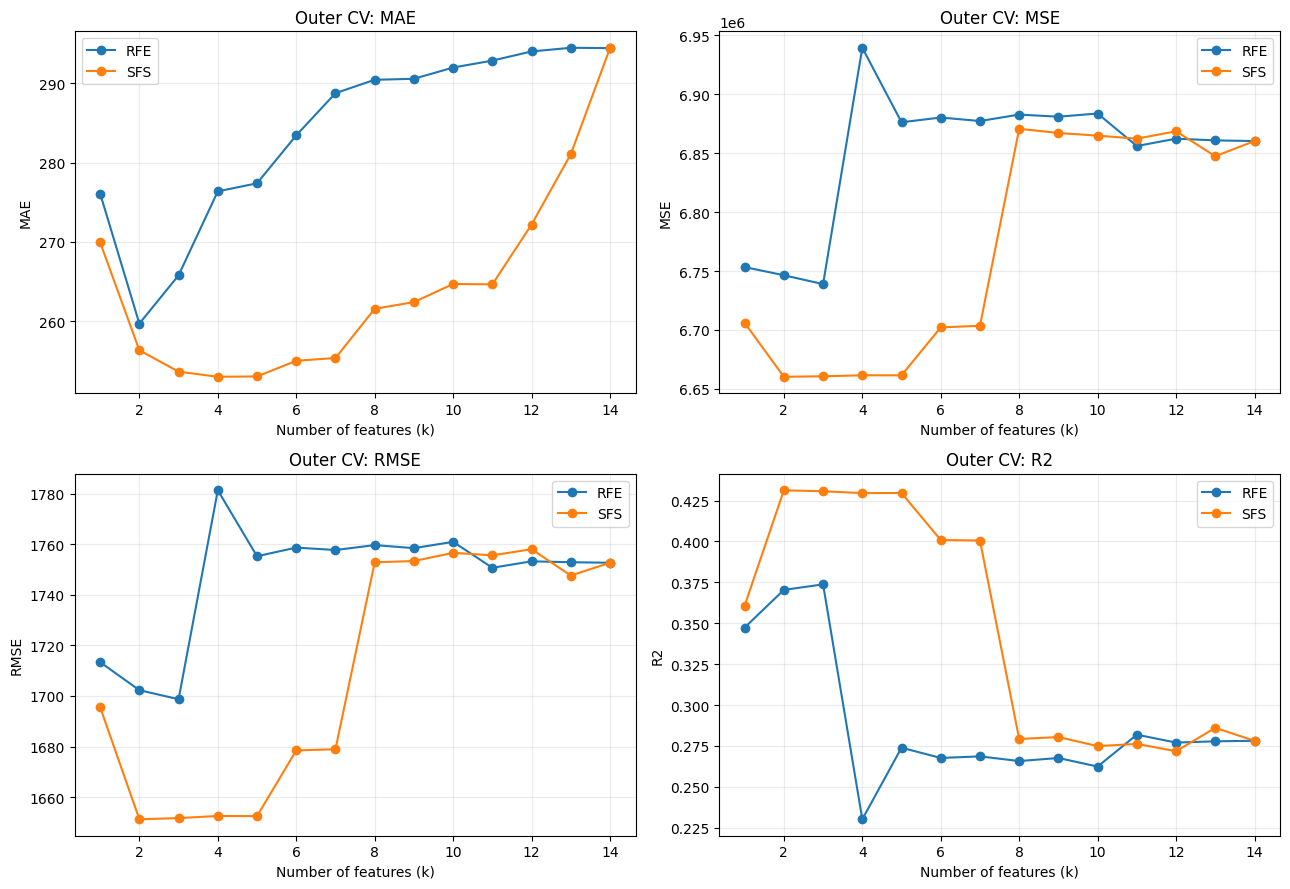

In [190]:
# Biểu đồ các chỉ số theo k
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, ["MAE", "MSE", "RMSE", "R2"]):
    for method in wrapper_methods:
        data = wrapper_results_df.loc[wrapper_results_df.Method == method].sort_values("k")
        ax.plot(data.k, data[metric], marker="o", label=method)
    ax.set(xlabel="Number of features (k)", ylabel=metric, title=f"Outer CV: {metric}")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.savefig(wrapper_dir / "wrapper_cv_performance.png", dpi=150)
plt.show()

Biểu đồ thể hiện sự thay đổi của các chỉ số MAE, MSE, RMSE và R² theo số lượng đặc trưng được lựa chọn (k) của hai phương pháp RFE và SFS.

Kết quả cho thấy hiệu quả dự đoán không nhất thiết tăng khi bổ sung thêm đặc trưng. Việc lựa chọn một tập đặc trưng phù hợp có thể giúp giảm sai số so với sử dụng toàn bộ 14 đặc trưng.

Do đó, số lượng đặc trưng tối ưu được xác định dựa trên MAE trung bình của 5-Fold Cross-Validation, thay vì ưu tiên tập đặc trưng có kích thước lớn nhất.

In [191]:
#Chọn k theo MAE và so sánh mốc tham chiếu
optimal_wrapper_results = (wrapper_results_df.sort_values(["MAE", "k"])
                           .drop_duplicates("Method").reset_index(drop=True))
full = wrapper_results_df.loc[wrapper_results_df.k == len(wrapper_features),
                              ["Method", "MAE", "RMSE", "R2"]].rename(
    columns={m: "Full " + m for m in ["MAE", "RMSE", "R2"]})
wrapper_comparison = optimal_wrapper_results.merge(full, on="Method", validate="one_to_one")
median_cv_mae = float(baseline_cv_results.loc[
    baseline_cv_results.Model == "DummyMedian", "MAE"].iloc[0])
wrapper_comparison["MAE Improvement (%)"] = 100 * (1 - wrapper_comparison.MAE / wrapper_comparison["Full MAE"])
wrapper_comparison["MAE vs Median Improvement (%)"] = 100 * (1 - wrapper_comparison.MAE / median_cv_mae)
wrapper_comparison["Feature Reduction (%)"] = 100 * (1 - wrapper_comparison.k / len(wrapper_features))
display(wrapper_comparison.round(4))
print("Giá trị cải thiện âm nghĩa là kém hơn mốc so sánh.")


,Method,k,MAE,MAE_std,MSE,MSE_std,RMSE,RMSE_std,R2,R2_std,Mean Fit Seconds,Mean Score Seconds,Full MAE,Full RMSE,Full R2,MAE Improvement (%),MAE vs Median Improvement (%),Feature Reduction (%)
0,SFS,4,252.9966,57.4917,6.661564e+06,1.235867e+07,1652.5797,1982.5601,0.4296,0.2416,0.0060,0.0165,294.4401,1752.6631,0.2781,14.0753,-8.9623,71.4286
1,RFE,2,259.6997,55.2847,6.746426e+06,1.231899e+07,1702.2963,1961.7882,0.3704,0.2210,0.0052,0.0158,294.4401,1752.6631,0.2781,11.7988,-11.8492,85.7143


Giá trị cải thiện âm nghĩa là kém hơn mốc so sánh.


In [192]:
# Fit trên toàn bộ Train sau khi chốt k; giữ pipeline và đặc trưng
fitted_wrapper_pipelines, wrapper_selected_features = {}, {}
wrapper_final_timings, wrapper_trace_rows = [], []
for row in optimal_wrapper_results.itertuples(index=False):
    method, k = row.Method, int(row.k)
    paths, elapsed, trace, path_total = wrapper_path(method, X_train, y_train)
    features = paths[k]
    pipeline = wrapper_prediction_pipeline(features)
    start = perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    prediction = pipeline.predict(X_train)
    predict_seconds = perf_counter() - start
    assert np.isfinite(prediction).all()
    assert len(features) == k
    fitted_wrapper_pipelines[method] = pipeline
    wrapper_selected_features[method] = features
    wrapper_final_timings.append({"Method": method, "k": k,
        "Full Path Search Seconds": path_total,
        "Selected k Path Seconds": elapsed[k], "Final Fit Seconds": fit_seconds,
        "Predict Train Seconds": predict_seconds, "Predict Samples": len(X_train)})
    wrapper_trace_rows.extend(dict(Method=method, **item) for item in trace)
wrapper_timing_df = pd.DataFrame(wrapper_final_timings)
wrapper_trace_df = pd.DataFrame(wrapper_trace_rows)
selected_table = pd.DataFrame({m: pd.Series(fs) for m, fs in wrapper_selected_features.items()})
selected_table.index = selected_table.index + 1
selected_table.index.name = "Position (not a common importance rank)"
display(selected_table.fillna("—"))
display(wrapper_timing_df.round(6))
common_wrapper_features = sorted(set(wrapper_selected_features["RFE"]) & set(wrapper_selected_features["SFS"]))
print("Common selected features:", common_wrapper_features)

,SFS,RFE
Position (not a common importance rank),,
1,Frequency,Frequency
2,Monetary,Monetary
3,Recency,—
4,AverageInterpurchaseTime,—


,Method,k,Full Path Search Seconds,Selected k Path Seconds,Final Fit Seconds,Predict Train Seconds,Predict Samples
0,SFS,4,5.677001,2.436718,0.006504,0.002869,4552
1,RFE,2,0.107146,0.101406,0.005693,0.002649,4552


Common selected features: ['Frequency', 'Monetary']


 Nhận xét kết quả RFE, SFS và so sánh hai phương pháp

**1. Phương pháp RFE (Recursive Feature Elimination)**

Kết quả thực nghiệm cho thấy RFE đạt hiệu quả dự đoán tốt nhất tại **k = 2**, với MAE trung bình bằng **259.6997**, RMSE bằng **1702.2963** và R² bằng **0.3704**.

So với mô hình sử dụng toàn bộ 14 đặc trưng (MAE = 294.4401), RFE giúp **giảm MAE 11.80%**, đồng thời giảm **85.71% số lượng đặc trưng**.

Kết quả cho thấy RFE có khả năng loại bỏ các đặc trưng ít phù hợp, giúp đơn giản hóa mô hình mà vẫn cải thiện hiệu quả dự đoán so với cấu hình đầy đủ.

**2. Phương pháp SFS Forward (Sequential Forward Selection)**

Phương pháp SFS đạt MAE thấp nhất tại **k = 4**, với MAE trung bình bằng **252.9966**, RMSE bằng **1652.5797** và R² bằng **0.4296**.

So với mô hình sử dụng toàn bộ 14 đặc trưng, SFS giúp **giảm MAE 14.08%** và giảm **71.43% số lượng đặc trưng**.

Kết quả cho thấy phương pháp bổ sung đặc trưng tuần tự có thể tìm được tổ hợp đặc trưng phù hợp, giúp cải thiện hiệu quả dự đoán của Ridge Regression.

**3. So sánh RFE và SFS**

- **Về hiệu quả dự đoán:** SFS đạt MAE thấp hơn RFE khoảng **2.58%**, đồng thời có RMSE thấp hơn và R² cao hơn.
- **Về số lượng đặc trưng:** RFE chỉ sử dụng 2 đặc trưng, trong khi SFS sử dụng 4 đặc trưng. Do đó, RFE có ưu thế về khả năng giảm số chiều dữ liệu.
- **Về mức độ cải thiện:** SFS cải thiện MAE 14.08%, cao hơn mức 11.80% của RFE khi so sánh với cấu hình sử dụng toàn bộ 14 đặc trưng.

Tuy nhiên, cả hai phương pháp đều có MAE cao hơn mô hình tham chiếu Dummy median (MAE = 232.1873), cho thấy hiệu quả dự đoán vẫn còn hạn chế.

**Kết luận:** Trong phạm vi thực nghiệm Wrapper Methods, **SFS với 4 đặc trưng đạt hiệu quả dự đoán tốt nhất theo MAE**, trong khi **RFE với 2 đặc trưng có ưu thế về khả năng giảm số chiều**. Sự chênh lệch kết quả giữa hai phương pháp chưa đủ để khẳng định khác biệt có ý nghĩa thống kê.

In [193]:
# Độ ổn định tại k đã chọn: tần suất theo fold và Jaccard
wrapper_stability_rows, wrapper_jaccard_rows = [], []
for row in optimal_wrapper_results.itertuples(index=False):
    method, k = row.Method, int(row.k)
    support = wrapper_support_df.loc[(wrapper_support_df.Method == method) & (wrapper_support_df.k == k)]
    counts = support.groupby("Feature").Fold.nunique()
    for feature in wrapper_features:
        count = int(counts.get(feature, 0))
        wrapper_stability_rows.append({"Method": method, "k": k, "Feature": feature,
            "Selected Folds": count, "Selection Frequency": count / cv.n_splits})
    sets = {f: set(g.Feature) for f, g in support.groupby("Fold")}
    for a, b in combinations(sorted(sets), 2):
        wrapper_jaccard_rows.append({"Method": method, "Fold A": a, "Fold B": b,
            "Jaccard": len(sets[a] & sets[b]) / len(sets[a] | sets[b])})
wrapper_stability_df = pd.DataFrame(wrapper_stability_rows)
wrapper_jaccard_df = pd.DataFrame(wrapper_jaccard_rows)
display(wrapper_stability_df.sort_values(["Method", "Selection Frequency"], ascending=[True, False]))
display(wrapper_jaccard_df.groupby("Method").Jaccard.agg(["mean", "min", "max"]))


,Method,k,Feature,Selected Folds,Selection Frequency
15,RFE,2,Frequency,4,0.8
16,RFE,2,Monetary,4,0.8
25,RFE,2,TotalQuantity,2,0.4
14,RFE,2,Recency,0,0.0
17,RFE,2,AveragePurchaseHour,0,0.0
18,RFE,2,PreferredDayOfWeek,0,0.0
19,RFE,2,ActiveMonths,0,0.0
20,RFE,2,AverageInterpurchaseTime,0,0.0
21,RFE,2,PurchaseTrend,0,0.0
22,RFE,2,AverageOrderValue,0,0.0


,mean,min,max
Method,,,
RFE,0.533333,0.333333,1.0
SFS,0.594286,0.142857,1.0


Độ ổn định của RFE và SFS được đánh giá thông qua tần suất lựa chọn đặc trưng trên 5 fold và chỉ số Jaccard, nhằm xác định mức độ nhất quán của các tập đặc trưng được lựa chọn khi dữ liệu huấn luyện thay đổi.

1. Phương pháp RFE

Với số lượng đặc trưng tối ưu k = 2, kết quả cho thấy:

Frequency và Monetary đều được lựa chọn trong 4/5 fold (80%).

TotalQuantity được lựa chọn trong 2/5 fold (40%).

Jaccard trung bình đạt 0.5333, dao động từ 0.3333 đến 1.0.

Kết quả cho thấy RFE có xu hướng ưu tiên hai đặc trưng Frequency và Monetary. Tuy nhiên, tập đặc trưng được lựa chọn vẫn có sự thay đổi giữa các fold, cho thấy độ ổn định chưa tuyệt đối.

2. Phương pháp SFS Forward

Với số lượng đặc trưng tối ưu k = 4, kết quả cho thấy:

Frequency được lựa chọn trong 5/5 fold (100%).

Recency, Monetary và AverageInterpurchaseTime đều được lựa chọn trong 4/5 fold (80%).

Các đặc trưng AverageQuantityPerInvoice, AveragePrice và TotalQuantity chỉ xuất hiện trong 1/5 fold (20%).

Jaccard trung bình đạt 0.5943, dao động từ 0.1429 đến 1.0.

Kết quả cho thấy SFS lựa chọn tương đối nhất quán nhóm đặc trưng Frequency, Recency, Monetary và AverageInterpurchaseTime. Tuy nhiên, giá trị Jaccard thấp nhất là 0.1429 cho thấy vẫn tồn tại những cặp fold có sự khác biệt đáng kể về tập đặc trưng được lựa chọn.

3. So sánh độ ổn định giữa RFE và SFS

Jaccard trung bình: SFS đạt 0.5943, cao hơn RFE (0.5333), cho thấy mức độ tương đồng trung bình giữa các tập đặc trưng của SFS cao hơn.

Jaccard thấp nhất: RFE đạt 0.3333, cao hơn SFS (0.1429), cho thấy SFS có sự biến động lớn hơn ở một số cặp fold.

Tần suất lựa chọn: SFS có Frequency xuất hiện trong toàn bộ 5 fold, trong khi RFE không có đặc trưng nào được lựa chọn ở cả 5 fold.

Kết luận: SFS có độ ổn định trung bình cao hơn RFE theo chỉ số Jaccard, đồng thời xác định được nhóm đặc trưng xuất hiện thường xuyên qua các fold. Tuy nhiên, cả hai phương pháp đều chịu ảnh hưởng từ sự thay đổi của dữ liệu huấn luyện. Vì vậy, kết quả lựa chọn đặc trưng cần được xem xét kết hợp với hiệu quả dự đoán và chi phí tính toán, thay vì chỉ dựa trên độ ổn định.

In [194]:
# So sánh Filter–Wrapper và lưu toàn bộ kết quả
# Tổng hợp kết quả Filter và Wrapper
filter_wrapper_comparison = pd.concat([
    optimal_filter_results.assign(Family="Filter"),
    optimal_wrapper_results.assign(Family="Wrapper")
], ignore_index=True)

# Hiển thị bảng so sánh
display(
    filter_wrapper_comparison[
        ["Family", "Method", "k", "MAE", "MAE_std", "RMSE", "R2"]
    ].sort_values("MAE").round(4)
)
# Tổng hợp các bảng kết quả Wrapper
wrapper_tables = {
    "configuration": wrapper_config,
    "cv_results": wrapper_results_df,
    "fold_results": wrapper_fold_results,
    "fold_features": wrapper_support_df,
    "outer_path_timings": wrapper_search_df,
    "optimal_results": wrapper_comparison,
    "final_timings": wrapper_timing_df,
    "full_train_path": wrapper_trace_df,
    "stability": wrapper_stability_df,
    "jaccard": wrapper_jaccard_df,
    "filter_wrapper_comparison": filter_wrapper_comparison
}
# Lưu các bảng kết quả thành CSV
for name, table in wrapper_tables.items():
    table.to_csv(wrapper_dir / f"{name}.csv", index=False)

# Lưu danh sách đặc trưng được lựa chọn
(wrapper_dir / "selected_features.json").write_text(
    json.dumps(
        wrapper_selected_features,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

# Lưu và kiểm tra các mô hình Wrapper
for method, pipeline in fitted_wrapper_pipelines.items():
    target = wrapper_dir / f"{method.lower()}_pipeline.joblib"

    joblib.dump(pipeline, target)

    # Kiểm tra mô hình sau khi tải lại
    loaded = joblib.load(target)

    probe = X_train.iloc[:min(20, len(X_train))]

    assert np.allclose(
        pipeline.predict(probe),
        loaded.predict(probe)
    )

print("Saved Wrapper results:", wrapper_dir)


,Family,Method,k,MAE,MAE_std,RMSE,R2
2,Wrapper,SFS,4,252.9966,57.4917,1652.5797,0.4296
0,Filter,F-test,3,256.3655,57.1648,1659.7795,0.4219
3,Wrapper,RFE,2,259.6997,55.2847,1702.2963,0.3704
1,Filter,Mutual Information,7,264.0290,55.2778,1654.9486,0.4272


Saved Wrapper results: ket_qua_feature_selection/wrapper_results


In [195]:
# Tạo và lưu file summary.md cho Wrapper Methods
# Tổng hợp kết quả Filter–Wrapper
summary_df = (
    filter_wrapper_comparison[
        ["Family", "Method", "k", "MAE", "MAE_std", "RMSE", "R2"]
    ]
    .sort_values("MAE")
    .round(4)
)

# Chuyển bảng kết quả sang Markdown
summary_text = (
    "# Kết quả thực nghiệm Filter–Wrapper\n\n"
    "## Bảng so sánh các phương pháp\n\n"
    + summary_df.to_markdown(index=False)
    + "\n"
)

# Lưu file summary.md
summary_path = wrapper_dir / "summary.md"

summary_path.write_text(
    summary_text,
    encoding="utf-8"
)

# Kiểm tra kết quả
print("Đã lưu file:", summary_path)
display(summary_df)


Đã lưu file: ket_qua_feature_selection/wrapper_results/summary.md


,Family,Method,k,MAE,MAE_std,RMSE,R2
2,Wrapper,SFS,4,252.9966,57.4917,1652.5797,0.4296
0,Filter,F-test,3,256.3655,57.1648,1659.7795,0.4219
3,Wrapper,RFE,2,259.6997,55.2847,1702.2963,0.3704
1,Filter,Mutual Information,7,264.0290,55.2778,1654.9486,0.4272


**Lưu ý về chi phí và diễn giải:** SFS có CV nội bộ nên thường tốn nhiều lần fit hơn RFE. Thời gian tìm toàn bộ đường đi được đo riêng và không được cộng lặp lại cho mỗi k. Thời gian fit cuối bao gồm điền thiếu, chuẩn hóa và Ridge; thời gian dự đoán đo trên Train, không phải đánh giá chất lượng trên Train. SFS có thứ tự thêm và RFE có thứ tự loại; hai thứ tự này không phải cùng một thang điểm quan trọng đặc trưng. Nếu k đầy đủ được chọn thì không có giảm đặc trưng.


Tổng kết thực nghiệm Wrapper Methods

Thực nghiệm Wrapper Methods đã đánh giá hai phương pháp **Recursive Feature Elimination (RFE)** và **Sequential Forward Selection (SFS)** bằng mô hình Ridge Regression với 5-Fold Cross-Validation trên tập Train.

**Kết quả chính:**

- **SFS:** Đạt kết quả tốt nhất tại **k = 4**, với MAE = **252.9966** (độ lệch chuẩn 57.4917), RMSE = 1652.5797 và R² = 0.4296. MAE giảm **14.08%** so với mô hình sử dụng toàn bộ 14 đặc trưng, nhưng vẫn cao hơn Dummy median **8.96%**. Các đặc trưng được lựa chọn gồm `Frequency`, `Monetary`, `Recency` và `AverageInterpurchaseTime`.

- **RFE:** Đạt kết quả tốt nhất tại **k = 2**, với MAE = **259.6997** (độ lệch chuẩn 55.2847), RMSE = 1702.2963 và R² = 0.3704. MAE giảm **11.80%** so với mô hình sử dụng toàn bộ 14 đặc trưng, nhưng vẫn cao hơn Dummy median **11.85%**. Các đặc trưng được lựa chọn gồm `Frequency` và `Monetary`.

**Diễn giải:**

- SFS đạt MAE thấp hơn RFE khoảng **2.58%**, cho thấy hiệu quả dự đoán tốt hơn theo MAE trong phạm vi thực nghiệm. Trong khi đó, RFE có ưu thế về khả năng giảm số lượng đặc trưng.
- MAE và RMSE càng thấp thể hiện sai số dự đoán càng nhỏ, trong khi R² càng cao thể hiện khả năng giải thích biến thiên của biến mục tiêu càng tốt.
- Độ lệch chuẩn MAE phản ánh mức độ biến động kết quả giữa các fold, không phải khoảng tin cậy.
- Các tập đặc trưng được fit trên toàn bộ Train phục vụ diễn giải và lưu mô hình; chất lượng dự đoán được báo cáo thông qua Cross-Validation.
- Tần suất lựa chọn đặc trưng và chỉ số Jaccard phản ánh độ ổn định giữa các fold, chưa đủ để chứng minh sự khác biệt có ý nghĩa thống kê.

**Kết luận:**

Trong nhóm Wrapper Methods, **SFS với 4 đặc trưng đạt MAE thấp nhất**, trong khi **RFE với 2 đặc trưng giúp giảm số chiều dữ liệu nhiều hơn**. Tuy nhiên, cả hai phương pháp đều chưa vượt qua mô hình tham chiếu Dummy median theo MAE.

Kết quả sẽ tiếp tục được so sánh với Filter Methods, Embedded Methods và phương pháp Hybrid Feature Selection đề xuất trước khi lựa chọn cấu hình kiểm chứng cuối cùng. Tập Test không được sử dụng trong quá trình lựa chọn phương pháp hoặc tối ưu đặc trưng.

### 4.3 Embedded

cấu hình Embedded

In [196]:
#  Lasso Selection + Ridge Regression
embedded_features = X_train.columns.tolist()

# Các giá trị alpha cần thử nghiệm cho Lasso
embedded_alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]

# Dùng cùng alpha của Ridge baseline để so sánh
embedded_ridge_alpha = ridge_baseline.named_steps["model"].alpha

embedded_cv_splits = list(cv.split(X_train, y_train))

embedded_dir = Path(RESULTS_DIR) / "embedded_results"
embedded_dir.mkdir(parents=True, exist_ok=True)

embedded_config = pd.DataFrame({
    "Parameter": [
        "Embedded selector",
        "Evaluation model",
        "Candidate features",
        "Lasso alpha candidates",
        "Ridge alpha",
        "Cross-validation",
        "Selection criterion"
    ],
    "Value": [
        "Lasso Regression",
        "Ridge Regression",
        len(embedded_features),
        str(embedded_alphas),
        embedded_ridge_alpha,
        f"{cv.n_splits}-Fold Cross-Validation",
        "Minimum mean CV MAE"
    ]
})

display(embedded_config)

,Parameter,Value
0,Embedded selector,Lasso Regression
1,Evaluation model,Ridge Regression
2,Candidate features,14
3,Lasso alpha candidates,"[0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]"
4,Ridge alpha,1.0
5,Cross-validation,5-Fold Cross-Validation
6,Selection criterion,Minimum mean CV MAE


Phương pháp Embedded sử dụng Lasso Regression để lựa chọn đặc trưng, sau đó dùng Ridge Regression (alpha=1.0) để đánh giá trên các đặc trưng được chọn. Lasso được khảo sát với 7 giá trị alpha từ 0.001 đến 100 trên 14 đặc trưng ban đầu, đánh giá bằng 5-Fold Cross-Validation trên tập Train, sử dụng cùng cấu hình baseline.

Cấu hình được lựa chọn theo MAE trung bình CV thấp nhất; độ lệch chuẩn của các chỉ số được tính theo độ lệch chuẩn tổng thể giữa 5 fold (ddof=0) để thống nhất cách tổng hợp kết quả CV.

Cross-Validation và lựa chọn đặc trưng

In [197]:
# Đánh giá Lasso Selection + Ridge trên từng fold
embedded_cv_records = []
embedded_support_records = []

for alpha in embedded_alphas:
    for fold, (train_idx, val_idx) in enumerate(
        embedded_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Chỉ fit preprocessing trên training fold để tránh leakage
        fold_preprocessor = clone(preprocessor)
        X_fold_train_scaled = fold_preprocessor.fit_transform(
            X_fold_train
        )
        X_fold_val_scaled = fold_preprocessor.transform(
            X_fold_val
        )

        # Lasso lựa chọn đặc trưng
        lasso_selector = Lasso(
            alpha=alpha,
            max_iter=20000,
            tol=1e-4
        )
        lasso_selector.fit(X_fold_train_scaled, y_fold_train)

        selected_mask = np.abs(lasso_selector.coef_) > 1e-8

        # Không tự động chọn đặc trưng thay thế
        if not selected_mask.any():
            raise ValueError(
                f"Lasso không chọn được đặc trưng nào "
                f"tại alpha={alpha}, fold={fold}. "
                "Hãy kiểm tra lại các giá trị alpha."
            )

        selected_count = int(selected_mask.sum())

        # Lưu tần suất lựa chọn cho từng đặc trưng ở từng fold
        for feature, selected in zip(
            embedded_features, selected_mask
        ):
            embedded_support_records.append({
                "Alpha": alpha,
                "Fold": fold,
                "Feature": feature,
                "Selected": int(selected)
            })

        # Ridge được đánh giá trên đúng các đặc trưng Lasso đã chọn
        ridge_model = Ridge(alpha=embedded_ridge_alpha)
        ridge_model.fit(
            X_fold_train_scaled[:, selected_mask],
            y_fold_train
        )
        y_pred = ridge_model.predict(
            X_fold_val_scaled[:, selected_mask]
        )

        mse = mean_squared_error(y_fold_val, y_pred)
        embedded_cv_records.append({
            "Alpha": alpha,
            "Fold": fold,
            "k": selected_count,
            "MAE": mean_absolute_error(y_fold_val, y_pred),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2_score(y_fold_val, y_pred)
        })

embedded_cv_df = pd.DataFrame(embedded_cv_records)
embedded_support_df = pd.DataFrame(embedded_support_records)

display(embedded_cv_df.round(4))


,Alpha,Fold,k,MAE,MSE,RMSE,R2
0,0.001,1,14,242.6985,1.739016e+05,417.0151,0.6605
1,0.001,2,14,381.9415,3.137078e+07,5600.9628,0.0014
2,0.001,3,14,304.5594,1.673182e+06,1293.5154,-0.1835
3,0.001,4,14,259.9945,3.653562e+05,604.4470,0.3647
4,0.001,5,14,283.0066,7.180449e+05,847.3753,0.5475
5,0.010,1,14,242.6985,1.739016e+05,417.0151,0.6605
6,0.010,2,14,381.9415,3.137078e+07,5600.9628,0.0014
7,0.010,3,14,304.5594,1.673182e+06,1293.5154,-0.1835
8,0.010,4,14,259.9945,3.653562e+05,604.4470,0.3647
9,0.010,5,14,283.0066,7.180449e+05,847.3753,0.5475


Kết quả Cross-Validation được tổng hợp trong bảng embedded_cv_df, thể hiện số lượng đặc trưng được lựa chọn (k) cùng các chỉ số MAE, MSE, RMSE và R² tại từng giá trị alpha trên mỗi fold. Số lượng đặc trưng được giữ lại phản ánh mức độ rút gọn dữ liệu đầu vào của Lasso, trong khi các chỉ số đánh giá cho biết ảnh hưởng của tập đặc trưng đó đến khả năng dự đoán của Ridge.

Khi alpha thay đổi, mức phạt của Lasso thay đổi theo, từ đó có thể làm thay đổi số lượng đặc trưng được lựa chọn và kết quả dự đoán. Cần đối chiếu đồng thời kết quả giữa các fold để đánh giá mức độ ổn định của mô hình, thay vì chỉ dựa vào một fold hoặc giả định rằng alpha càng lớn thì MAE càng thấp.

Trong trường hợp Lasso không lựa chọn được đặc trưng nào ở một fold, chương trình sẽ thông báo lỗi rõ ràng và dừng thực hiện. Cách xử lý này giúp tránh việc tự động lựa chọn đặc trưng thay thế, bảo đảm kết quả phản ánh đúng hoạt động của thuật toán.

tổng hợp kết quả và chọn alpha tốt nhất

In [198]:
# Tổng hợp hiệu suất qua các fold
# ddof=0: độ lệch chuẩn tổng thể, thống nhất với Baseline, Filter,
# Wrapper và Hybrid.
embedded_results_df = (
    embedded_cv_df
    .groupby("Alpha")
    .agg(
        k=("k", "mean"),
        MAE=("MAE", "mean"),
        MAE_std=("MAE", lambda x: x.std(ddof=0)),
        MSE=("MSE", "mean"),
        MSE_std=("MSE", lambda x: x.std(ddof=0)),
        RMSE=("RMSE", "mean"),
        RMSE_std=("RMSE", lambda x: x.std(ddof=0)),
        R2=("R2", "mean"),
        R2_std=("R2", lambda x: x.std(ddof=0))
    )
    .reset_index()
)

embedded_results_df["Feature Reduction (%)"] = (
    100 * (
        1 - embedded_results_df["k"]
        / len(embedded_features)
    )
)

# Chọn alpha theo MAE CV trung bình thấp nhất
embedded_results_df = (
    embedded_results_df
    .sort_values(["MAE", "k", "Alpha"])
    .reset_index(drop=True)
)

best_embedded_alpha = float(
    embedded_results_df.iloc[0]["Alpha"]
)

print("=== EMBEDDED CROSS-VALIDATION RESULTS ===")
display(embedded_results_df.round(4))
print("Best Lasso alpha:", best_embedded_alpha)


=== EMBEDDED CROSS-VALIDATION RESULTS ===


,Alpha,k,MAE,MAE_std,MSE,MSE_std,RMSE,RMSE_std,R2,R2_std,Feature Reduction (%)
0,100.000,2.8,254.8915,57.8648,6.631016e+06,1.238197e+07,1633.8457,1990.3678,0.4506,0.2478,80.0000
1,50.000,6.0,278.7570,48.9004,6.646616e+06,1.237861e+07,1644.5199,1985.4899,0.4347,0.2438,57.1429
2,10.000,11.6,292.5726,48.5660,6.854438e+06,1.226808e+07,1750.3294,1946.9939,0.2824,0.3160,17.1429
3,1.000,13.8,294.4343,48.4731,6.860361e+06,1.226634e+07,1752.6727,1946.4068,0.2781,0.3212,1.4286
4,0.001,14.0,294.4401,48.4836,6.860254e+06,1.226613e+07,1752.6631,1946.3879,0.2781,0.3212,0.0000
5,0.010,14.0,294.4401,48.4836,6.860254e+06,1.226613e+07,1752.6631,1946.3879,0.2781,0.3212,0.0000
6,0.100,14.0,294.4401,48.4836,6.860254e+06,1.226613e+07,1752.6631,1946.3879,0.2781,0.3212,0.0000


Best Lasso alpha: 100.0


Kết quả tổng hợp cho thấy khi alpha tăng, số lượng đặc trưng được lựa chọn có xu hướng giảm, đồng thời MAE trung bình cũng được cải thiện. Với alpha từ 0.001 đến 0.1, mô hình sử dụng toàn bộ 14 đặc trưng và đạt MAE = 294.4401.

Khi alpha tăng lên 50, số đặc trưng trung bình giảm còn 6 và MAE giảm xuống 278.7570. Kết quả tốt nhất đạt được tại alpha = 100, với trung bình 2.8 đặc trưng, MAE = 254.8915, RMSE = 1633.8457 và R² = 0.4506. Tỷ lệ giảm đặc trưng đạt 80% so với ban đầu.

Như vậy, alpha = 100 được lựa chọn làm cấu hình tốt nhất do đạt MAE trung bình thấp nhất trong các giá trị được thử nghiệm, đồng thời giúp giảm đáng kể số lượng đặc trưng đầu vào.

Biểu đồ MAE theo Alpha - Embedded

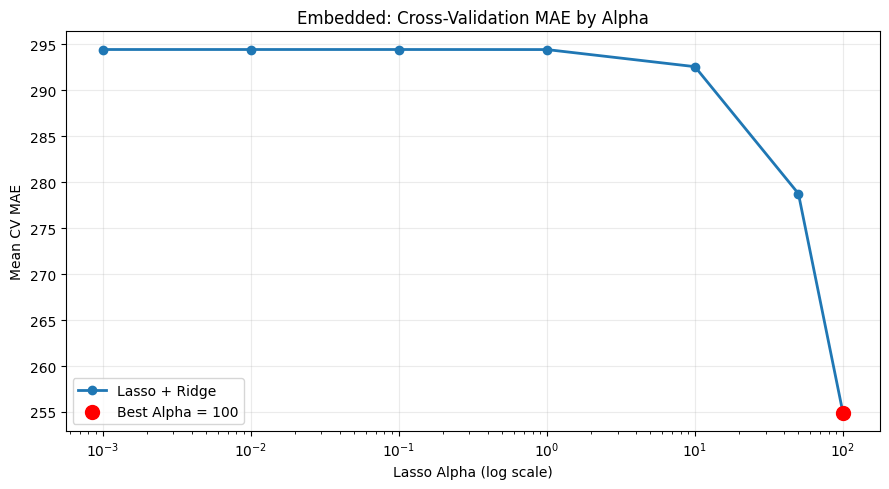

In [199]:
# Sắp xếp Alpha tăng dần để vẽ đúng thứ tự
plot_data = embedded_results_df.sort_values("Alpha")

plt.figure(figsize=(9, 5))

plt.plot(
    plot_data["Alpha"],
    plot_data["MAE"],
    marker="o",
    linewidth=2,
    label="Lasso + Ridge"
)

# Đánh dấu Alpha có MAE trung bình thấp nhất
best_row = embedded_results_df.loc[
    embedded_results_df["Alpha"] == best_embedded_alpha
].iloc[0]

plt.scatter(
    best_row["Alpha"],
    best_row["MAE"],
    color="red",
    s=100,
    zorder=5,
    label=f'Best Alpha = {best_embedded_alpha:g}'
)

plt.xscale("log")
plt.xlabel("Lasso Alpha (log scale)")
plt.ylabel("Mean CV MAE")
plt.title("Embedded: Cross-Validation MAE by Alpha")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    embedded_dir / "embedded_alpha_mae.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


Biểu đồ cho thấy MAE trung bình có xu hướng giảm khi giá trị alpha của Lasso tăng. Trong khoảng alpha từ 0.001 đến 1, MAE gần như không thay đổi, cho thấy mức điều chuẩn nhỏ chưa tạo ra sự khác biệt đáng kể trong việc lựa chọn đặc trưng.

Khi alpha tăng từ 10 đến 100, MAE giảm rõ rệt và đạt giá trị thấp nhất tại alpha = 100. Điều này cho thấy việc loại bỏ các đặc trưng ít đóng góp có thể giúp cải thiện hiệu quả dự đoán. Tuy nhiên, xu hướng này chỉ được ghi nhận trong phạm vi các giá trị alpha đã thử nghiệm.

Đánh giá độ ổn định của đặc trưng

In [200]:
best_support = embedded_support_df[
    embedded_support_df["Alpha"] == best_embedded_alpha
]

embedded_stability_df = (
    best_support
    .groupby("Feature", as_index=False)["Selected"]
    .sum()
    .rename(columns={"Selected": "Selected Folds"})
)

embedded_stability_df["Selection Frequency"] = (
    embedded_stability_df["Selected Folds"]
    / cv.n_splits
)

embedded_stability_df = (
    embedded_stability_df
    .sort_values(
        ["Selection Frequency", "Feature"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

print("=== FEATURE SELECTION STABILITY ===")
display(embedded_stability_df)

=== FEATURE SELECTION STABILITY ===


,Feature,Selected Folds,Selection Frequency
0,Frequency,5,1.0
1,Monetary,5,1.0
2,TotalQuantity,4,0.8
3,ActiveMonths,0,0.0
4,AverageInterpurchaseTime,0,0.0
5,AverageOrderValue,0,0.0
6,AveragePrice,0,0.0
7,AveragePurchaseHour,0,0.0
8,AverageQuantityPerInvoice,0,0.0
9,PreferredDayOfWeek,0,0.0


Kết quả đánh giá độ ổn định tại alpha = 100 cho thấy hai đặc trưng Frequency và Monetary được lựa chọn trong cả 5 fold, đạt tần suất 100%. Đặc trưng TotalQuantity xuất hiện trong 4/5 fold, tương ứng 80%.

Trong khi đó, 11 đặc trưng còn lại không được lựa chọn ở bất kỳ fold nào. Kết quả này cho thấy Lasso có xu hướng ưu tiên các đặc trưng liên quan trực tiếp đến tần suất mua hàng, tổng giá trị chi tiêu và số lượng sản phẩm đã mua.

Nhìn chung, các đặc trưng được lựa chọn có độ ổn định tương đối cao giữa các fold, đặc biệt là Frequency và Monetary. Đây là những đặc trưng có thể đóng vai trò quan trọng trong việc dự đoán mức chi tiêu tương lai của khách hàng.

Huấn luyện mô hình cuối cùng và đánh giá Test Set

In [201]:
# Fit preprocessing và Lasso trên toàn bộ Train
# Test chỉ được dùng để đánh giá cuối cùng

embedded_final_preprocessor = clone(preprocessor)
X_train_emb_scaled = (
    embedded_final_preprocessor.fit_transform(X_train)
)
X_test_emb_scaled = (
    embedded_final_preprocessor.transform(X_test)
)

embedded_final_lasso = Lasso(
    alpha=best_embedded_alpha,
    max_iter=20000,
    tol=1e-4
)
embedded_final_lasso.fit(X_train_emb_scaled, y_train)

embedded_final_mask = (
    np.abs(embedded_final_lasso.coef_) > 1e-8
)

# Áp dụng cùng quy tắc như Cross-Validation: không tự chọn biến thay thế
if not embedded_final_mask.any():
    raise ValueError(
        f"Lasso không chọn được đặc trưng nào trên toàn bộ Train "
        f"tại alpha={best_embedded_alpha}. "
        "Hãy kiểm tra lại các giá trị alpha."
    )

embedded_selected_features = [
    feature
    for feature, keep in zip(
        embedded_features, embedded_final_mask
    )
    if keep
]

# Huấn luyện Ridge trên các đặc trưng đã chọn
embedded_final_ridge = Ridge(
    alpha=embedded_ridge_alpha
)
embedded_final_ridge.fit(
    X_train_emb_scaled[:, embedded_final_mask],
    y_train
)

# Dự đoán trên Test và đo thời gian riêng cho bước predict
start = perf_counter()
y_pred_embedded_test = embedded_final_ridge.predict(
    X_test_emb_scaled[:, embedded_final_mask]
)
embedded_test_predict_seconds = perf_counter() - start

# Đánh giá trên Test
embedded_test_metrics = {
    "MAE": mean_absolute_error(y_test, y_pred_embedded_test),
    "MSE": mean_squared_error(y_test, y_pred_embedded_test),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, y_pred_embedded_test)
    ),
    "R2": r2_score(y_test, y_pred_embedded_test)
}

embedded_test_results = pd.DataFrame([{
    "Method": "Lasso selection + Ridge",
    "Alpha": best_embedded_alpha,
    "Selected Features": len(embedded_selected_features),
    "Total Features": len(embedded_features),
    "Feature Reduction (%)": (
        100 * (
            1 - len(embedded_selected_features)
            / len(embedded_features)
        )
    ),
    **embedded_test_metrics,
    "Test Predict Seconds": embedded_test_predict_seconds
}])

print("=== SELECTED FEATURES ===")
display(pd.DataFrame({
    "Selected Feature": embedded_selected_features
}))

print("=== EMBEDDED TEST RESULTS ===")
display(embedded_test_results.round(4))


=== SELECTED FEATURES ===


,Selected Feature
0,Frequency
1,Monetary
2,TotalQuantity


=== EMBEDDED TEST RESULTS ===


,Method,Alpha,Selected Features,Total Features,Feature Reduction (%),MAE,MSE,RMSE,R2,Test Predict Seconds
0,Lasso selection + Ridge,100.0,3,14,78.5714,213.842,877452.9739,936.7246,0.1036,0.0004


Sau khi lựa chọn alpha = 100 theo MAE trung bình CV thấp nhất trong lưới khảo sát, Lasso được fit lại trên toàn bộ Train và chọn 3 đặc trưng: Frequency, Monetary và TotalQuantity. Số đặc trưng giảm từ 14 xuống 3, tương ứng 78,57%. Đây là số biến của lần fit toàn Train, khác với mức trung bình 2,8 biến qua 5 fold CV.

Trên Test, Ridge sử dụng các đặc trưng đã chọn đạt MAE = 213,8420, RMSE = 936,7246 và R² = 0,1036. So với Ridge đầy đủ, MAE thấp hơn nhưng RMSE cao hơn và R² thấp hơn, cho thấy lợi ích của việc rút gọn chưa đồng nhất giữa các chỉ số. MAE vẫn cao hơn Dummy median, đạt 161,6678.

R² trên Test thấp hơn R² trung bình CV = 0,4506. Chênh lệch này cho thấy kết quả thay đổi giữa các tập đánh giá, nhưng chưa đủ để kết luận nguyên nhân hoặc khẳng định overfitting. Tập Test hiện tại đã được xem trong quá trình phân tích; các kết quả này được dùng để mô tả chất lượng dự đoán, không dùng để lựa chọn lại alpha hoặc đặc trưng.

So sánh Embedded với Filter và Wrapper

In [202]:
# So sánh bằng MAE Cross-Validation, không dùng Test

embedded_best_cv_row = embedded_results_df.iloc[0]

embedded_cv_summary = pd.DataFrame([{
    "Family": "Embedded",
    "Method": "Lasso selection + Ridge",
    "k": embedded_best_cv_row["k"],
    "MAE": embedded_best_cv_row["MAE"],
    "MAE_std": embedded_best_cv_row["MAE_std"],
    "RMSE": embedded_best_cv_row["RMSE"],
    "R2": embedded_best_cv_row["R2"]
}])

embedded_comparison_parts = [embedded_cv_summary]

if "optimal_filter_results" in globals():
    embedded_comparison_parts.append(
        optimal_filter_results.assign(
            Family="Filter"
        )[
            [
                "Family", "Method", "k",
                "MAE", "MAE_std", "RMSE", "R2"
            ]
        ]
    )

if "optimal_wrapper_results" in globals():
    embedded_comparison_parts.append(
        optimal_wrapper_results.assign(
            Family="Wrapper"
        )[
            [
                "Family", "Method", "k",
                "MAE", "MAE_std", "RMSE", "R2"
            ]
        ]
    )

embedded_method_comparison = pd.concat(
    embedded_comparison_parts,
    ignore_index=True
)

embedded_method_comparison = (
    embedded_method_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(embedded_method_comparison.round(4))

,Family,Method,k,MAE,MAE_std,RMSE,R2
0,Wrapper,SFS,4.0,252.9966,57.4917,1652.5797,0.4296
1,Embedded,Lasso selection + Ridge,2.8,254.8915,57.8648,1633.8457,0.4506
2,Filter,F-test,3.0,256.3655,57.1648,1659.7795,0.4219
3,Wrapper,RFE,2.0,259.6997,55.2847,1702.2963,0.3704
4,Filter,Mutual Information,7.0,264.0290,55.2778,1654.9486,0.4272


Lasso selection + Ridge đạt MAE trung bình CV = 254,8915, thấp hơn F-test (256,3655), RFE (259,6997) và Mutual Information (264,0290), nhưng cao hơn SFS (252,9966). Trong nhóm phương pháp tại bảng này, Embedded có RMSE thấp nhất (1633,8457) và R² cao nhất (0,4506), đồng thời sử dụng trung bình 2,8 đặc trưng qua 5 fold.

Độ lệch chuẩn MAE = 57,8648 phản ánh mức biến động sai số giữa các fold. Độ ổn định của tập đặc trưng được đánh giá riêng: Frequency và Monetary xuất hiện trong cả 5 fold, còn TotalQuantity xuất hiện trong 4 fold. Không sử dụng độ lệch chuẩn MAE để kết luận trực tiếp về độ ổn định của việc lựa chọn đặc trưng.

Kết quả cho thấy Embedded giảm đáng kể số đặc trưng và cải thiện chất lượng CV so với Ridge đầy đủ, nhưng chưa vượt Dummy median về MAE. Các khác biệt giữa phương pháp mang tính mô tả trong thiết lập hiện tại, chưa chứng minh ưu thế có ý nghĩa thống kê.

In [203]:
# Lưu bảng kết quả

embedded_results_df.to_csv(
    embedded_dir / "embedded_cv_results.csv",
    index=False
)

embedded_stability_df.to_csv(
    embedded_dir / "embedded_feature_stability.csv",
    index=False
)

embedded_test_results.to_csv(
    embedded_dir / "embedded_test_results.csv",
    index=False
)

embedded_method_comparison.to_csv(
    embedded_dir / "embedded_method_comparison.csv",
    index=False
)

print("Saved Embedded outputs to:", embedded_dir.resolve())

Saved Embedded outputs to: /content/ket_qua_feature_selection/embedded_results


Các kết quả thực nghiệm của phương pháp Embedded, bao gồm kết quả Cross-Validation, độ ổn định của đặc trưng, đánh giá trên tập Test và bảng so sánh các phương pháp, được lưu thành các file CSV để phục vụ quá trình phân tích và tổng hợp kết quả.

## 5.Phương pháp Feature Selection đề xuất

### 5.1. Động cơ đề xuất
Phân tích kết quả Filter, Wrapper và Embedded để xác định những hạn chế cần cải thiện.

Kết quả thực nghiệm cho thấy Feature Selection giúp giảm số đặc trưng và cải thiện MAE so với Ridge sử dụng đầy đủ 14 đặc trưng:

| Phương pháp | Số đặc trưng được chọn | MAE trung bình CV |
|---|---:|---:|
| Ridge dùng toàn bộ đặc trưng | 14 | 294,4401 |
| F-test | 3 | 256,3655 |
| Mutual Information | 7 | 264,0290 |
| RFE | 2 | 259,6997 |
| SFS | 4 | 252,9966 |
| Lasso selection + Ridge | 2,8* | 254,8915 |

*2,8 là số đặc trưng trung bình được Lasso lựa chọn qua 5 fold.*

Kết quả mục 4 cho thấy lựa chọn đặc trưng giúp giảm MAE so với Ridge dùng đủ 14 biến. Tuy nhiên, Filter đánh giá từng biến riêng lẻ; SFS cần nhiều lần fit; Lasso phụ thuộc alpha.

Nghiên cứu kiểm chứng liệu MI trước SFS có giảm chi phí tìm kiếm và tăng tính nhất quán của tập được chọn, đồng thời duy trì chất lượng dự đoán hay không. Sai số cần đối chiếu thêm với Dummy median, vì cải thiện so với Ridge đầy đủ chưa đủ để kết luận dự đoán tốt.

### 5.2. Ý tưởng phương pháp
14 đặc trưng → MI giữ m ứng viên → SFS chọn k biến theo MAE CV của Ridge → fit Ridge → đánh giá.

MI thu hẹp nhóm ứng viên; SFS đánh giá hiệu quả của tập con với Ridge. Stability là tiêu chí đánh giá qua tần suất lựa chọn và Jaccard giữa các fold, không dùng để tạo tập cuối.

Phiên bản đầu dùng m = 7, k = 4 và so sánh với SFS4, Ridge đầy đủ, Dummy median trên cùng fold. Đây là cấu hình cố định từ thăm dò, chưa phải cấu hình tối ưu. Lợi ích và rủi ro loại sớm biến hữu ích được phân tích ở mục 7.

### 5.3. Cấu hình thực nghiệm


In [204]:
hybrid_m, hybrid_k = 7, 4
hybrid_alpha = ridge_baseline.named_steps["model"].alpha
hybrid_seed = RANDOM_STATE
hybrid_n_jobs = N_JOBS
hybrid_inner_folds = 5
hybrid_outer_splits = list(cv.split(X_train, y_train))
hybrid_dir = Path(RESULTS_DIR) / "hybrid_results"
hybrid_dir.mkdir(parents=True, exist_ok=True)
assert X_train.index.equals(y_train.index)
assert X_train.columns.is_unique and 1 <= hybrid_k <= hybrid_m <= X_train.shape[1]
assert np.isfinite(y_train.to_numpy()).all()
assert not np.isinf(X_train.to_numpy(dtype=float)).any()

hybrid_config = {
    "m": hybrid_m, "k": hybrid_k, "ridge_alpha": float(hybrid_alpha),
    "seed": hybrid_seed, "outer_folds": len(hybrid_outer_splits),
    "outer_cv": repr(cv), "sfs_inner_folds": hybrid_inner_folds,
    "n_jobs": hybrid_n_jobs, "std_ddof": 0,
    "candidate_features": X_train.columns.tolist(),
    "discrete_features": ["PreferredDayOfWeek"],
    "selection": "Fixed m/k; SFS maximizes negative MAE; ties: original column order",
    "scope": "Train only; exploratory fixed-configuration comparison"
}
display(pd.DataFrame({"Parameter": list(hybrid_config), "Value": [str(v) for v in hybrid_config.values()]}))

,Parameter,Value
0,m,7
1,k,4
2,ridge_alpha,1.0
3,seed,42
4,outer_folds,5
5,outer_cv,"KFold(n_splits=5, random_state=42, shuffle=True)"
6,sfs_inner_folds,5
7,n_jobs,1
8,std_ddof,0
9,candidate_features,"['Recency', 'Frequency', 'Monetary', 'AverageP..."


### 5.4. Cài đặt MI → SFS


In [205]:
# Tạo mô hình
def hybrid_regressor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=hybrid_alpha))
    ])

In [206]:
# Lọc MI
# Chỉ fit trên dữ liệu huấn luyện được truyền vào; giữ tên cột
def select_mi_candidates(X_fit, y_fit, m):
    if not 1 <= m <= X_fit.shape[1]:
        raise ValueError("m phải nằm trong [1, số đặc trưng].")
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    values = imputer.fit_transform(X_fit)
    discrete = np.asarray(X_fit.columns == "PreferredDayOfWeek")
    scores = mutual_info_regression(
        values, y_fit, discrete_features=discrete, random_state=hybrid_seed
    )
    ranking = pd.DataFrame({"Feature": X_fit.columns, "MI": scores})
    ranking = ranking.sort_values("MI", ascending=False, kind="stable").reset_index(drop=True)
    ranking["Rank"] = np.arange(1, len(ranking) + 1)
    chosen = set(ranking.head(m)["Feature"])
    # Thứ tự gốc giúp SFS phá hòa nhất quán với đối chứng.
    candidates = [f for f in X_fit.columns if f in chosen]
    ranking["Candidate"] = ranking["Feature"].isin(chosen)
    return candidates, ranking


In [207]:
# Chọn SFS
def select_sfs_subset(X_fit, y_fit, candidates, k, inner_splits):
    if not 1 <= k <= len(candidates):
        raise ValueError("k phải nằm trong [1, số ứng viên].")
    if k == len(candidates):
        return list(candidates), []
    selected, trace = [], []
    for step in range(1, k + 1):
        trials = []
        for feature in candidates:
            if feature in selected:
                continue
            subset = selected + [feature]
            score = cross_val_score(
                hybrid_regressor(), X_fit[subset], y_fit,
                cv=inner_splits, scoring="neg_mean_absolute_error",
                n_jobs=hybrid_n_jobs, error_score="raise"
            ).mean()
            trials.append((float(score), feature))
        best_score, best_feature = max(trials, key=lambda item: item[0])
        selected.append(best_feature)
        trace.append({"Step": step, "Added": best_feature, "Search_MAE": -best_score})
    return selected, trace

In [208]:
# thực hiện MI → SFS → fit Ridge và trả về tập đặc trưng, đường đi lựa chọn cùng thời gian từng bước.
def fit_hybrid(X_fit, y_fit, m, k, use_filter=True):
    """Trả model, tên biến và thời gian; không đọc validation/Test."""
    if not X_fit.index.equals(y_fit.index):
        raise ValueError("Index X/y không khớp.")
    if not 1 <= k <= m <= X_fit.shape[1]:
        raise ValueError("Cần 1 <= k <= m <= p.")
    t0 = perf_counter()
    if use_filter and m < X_fit.shape[1]:
        candidates, ranking = select_mi_candidates(X_fit, y_fit, m)
    else:
        candidates, ranking = X_fit.columns.tolist(), pd.DataFrame()
    mi_seconds = perf_counter() - t0
    if not use_filter or m == X_fit.shape[1]:
        mi_seconds = 0.0
    inner_splits = list(KFold(
        n_splits=hybrid_inner_folds, shuffle=True, random_state=hybrid_seed
    ).split(X_fit, y_fit))
    t0 = perf_counter()
    selected, trace = select_sfs_subset(X_fit, y_fit, candidates, k, inner_splits)
    sfs_seconds = perf_counter() - t0
    assert len(selected) == k and set(selected).issubset(candidates)
    t0 = perf_counter()
    model = hybrid_regressor().fit(X_fit[selected], y_fit)
    fit_seconds = perf_counter() - t0
    return {
        "model": model, "features": selected, "candidates": candidates,
        "ranking": ranking, "trace": trace,
        "MI_seconds": mi_seconds, "SFS_seconds": sfs_seconds,
        "Selection_seconds": mi_seconds + sfs_seconds, "Fit_seconds": fit_seconds
    }

### 5.5. Đánh giá trên cùng các fold
Báo cáo MAE, RMSE, R², số đặc trưng, thời gian và độ ổn định

In [209]:
# Khởi tạo nơi lưu kết quả
hybrid_fold_rows, hybrid_support_rows, hybrid_group_rows = [], [], []
hybrid_mi_rows, hybrid_trace_rows = [], []

In [210]:
# Chạy thực nghiệm trên từng fold
for fold, (train_idx, valid_idx) in enumerate(hybrid_outer_splits, start=1):
    X_fit, X_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]
    methods = ["Ridge full", "Dummy median", "SFS", "Hybrid MI → SFS"]
    # Đảo thứ tự để giảm thiên lệch do luôn đo một phương pháp trước.
    if fold % 2 == 0:
        methods = methods[::-1]
    for method in methods:
        if method in ["SFS", "Hybrid MI → SFS"]:
            result = fit_hybrid(
                X_fit, y_fit,
                m=hybrid_m if method == "Hybrid MI → SFS" else X_fit.shape[1],
                k=hybrid_k, use_filter=(method == "Hybrid MI → SFS")
            )
            for row in result["ranking"].to_dict("records"):
                hybrid_mi_rows.append({"Fold": fold, "Method": method, **row})
            for row in result["trace"]:
                hybrid_trace_rows.append({"Fold": fold, "Method": method, **row})
        else:
            features = X_fit.columns.tolist()
            model = hybrid_regressor() if method == "Ridge full" else DummyRegressor(strategy="median")
            t0 = perf_counter()
            # Dummy chỉ cần kích thước X, không dùng giá trị đặc trưng.
            model.fit(X_fit[features], y_fit)
            result = {"model": model, "features": features, "candidates": features,
                      "MI_seconds": 0.0, "SFS_seconds": 0.0,
                      "Selection_seconds": 0.0, "Fit_seconds": perf_counter() - t0}
        features = result["features"]
        t0 = perf_counter()
        prediction = result["model"].predict(X_valid[features])
        predict_seconds = perf_counter() - t0
        mse = mean_squared_error(y_valid, prediction)
        hybrid_fold_rows.append({
            "Method": method, "Fold": fold,
            # Dummy không sử dụng feature; không tính nó là bộ chọn tập rỗng.
            "k": np.nan if method == "Dummy median" else len(features),
            "MAE": mean_absolute_error(y_valid, prediction), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_valid, prediction),
            **{key: result[key] for key in ["MI_seconds", "SFS_seconds", "Selection_seconds", "Fit_seconds"]},
            "Predict_seconds": predict_seconds
        })
        if method in ["SFS", "Hybrid MI → SFS"]:
            hybrid_support_rows.append({"Method": method, "Fold": fold,
                                       "Candidates": result["candidates"], "Features": features})
        for group, mask in [("Target = 0", y_valid.to_numpy() == 0),
                            ("Target > 0", y_valid.to_numpy() > 0)]:
            if mask.any():
                hybrid_group_rows.append({
                    "Method": method, "Fold": fold, "Group": group, "Samples": int(mask.sum()),
                    "MAE": mean_absolute_error(y_valid.to_numpy()[mask], prediction[mask]),
                    "RMSE": np.sqrt(mean_squared_error(y_valid.to_numpy()[mask], prediction[mask]))
                })
    print(f"Hoàn tất fold {fold}/{len(hybrid_outer_splits)}")

Hoàn tất fold 1/5
Hoàn tất fold 2/5
Hoàn tất fold 3/5
Hoàn tất fold 4/5
Hoàn tất fold 5/5


In [211]:
# Tạo bảng và hiển thị kết quả
hybrid_fold_results = pd.DataFrame(hybrid_fold_rows)
hybrid_support = pd.DataFrame(hybrid_support_rows)
hybrid_group_results = pd.DataFrame(hybrid_group_rows)

display(hybrid_fold_results.round(4))

,Method,Fold,k,MAE,MSE,RMSE,R2,MI_seconds,SFS_seconds,Selection_seconds,Fit_seconds,Predict_seconds
0,Ridge full,1,14.0,242.6985,1.739016e+05,417.0151,0.6605,0.0000,0.0000,0.0000,0.0128,0.0028
1,Dummy median,1,NaN,189.2575,5.479883e+05,740.2623,-0.0699,0.0000,0.0000,0.0000,0.0012,0.0006
2,SFS,1,4.0,204.9369,1.618010e+05,402.2449,0.6841,0.0000,4.5473,4.5473,0.0095,0.0033
3,Hybrid MI → SFS,1,4.0,204.9369,1.618010e+05,402.2449,0.6841,0.4771,1.0726,1.5498,0.0066,0.0025
4,Hybrid MI → SFS,2,4.0,365.9058,3.137641e+07,5601.4653,0.0013,0.3105,1.0396,1.3500,0.0067,0.0024
5,SFS,2,4.0,362.8057,3.137389e+07,5601.2405,0.0013,0.0000,2.4670,2.4670,0.0062,0.0023
6,Dummy median,2,NaN,355.8585,3.154259e+07,5616.2791,-0.0040,0.0000,0.0000,0.0000,0.0012,0.0006
7,Ridge full,2,14.0,381.9415,3.137078e+07,5600.9628,0.0014,0.0000,0.0000,0.0000,0.0114,0.0027
8,Ridge full,3,14.0,304.5594,1.673182e+06,1293.5154,-0.1835,0.0000,0.0000,0.0000,0.0098,0.0027
9,Dummy median,3,NaN,190.4439,1.450041e+06,1204.1764,-0.0257,0.0000,0.0000,0.0000,0.0012,0.0006


### 5.6 Độ gọn và độ ổn định

In [212]:
# Tính tần suất lựa chọn và Jaccard
hybrid_frequency_rows, hybrid_jaccard_rows = [], []

for method, data in hybrid_support.groupby("Method", sort=False):
    selected_sets = [set(features) for features in data["Features"]]

    # Tần suất mỗi đặc trưng được chọn qua các fold
    for feature in X_train.columns:
        count = sum(feature in selected for selected in selected_sets)

        hybrid_frequency_rows.append({
            "Method": method,
            "Feature": feature,
            "Selected_folds": count,
            "Frequency": count / len(selected_sets)
        })

    # Jaccard giữa từng cặp tập đặc trưng
    rows = list(data.itertuples(index=False))

    for a, b in combinations(rows, 2):
        first, second = set(a.Features), set(b.Features)

        hybrid_jaccard_rows.append({
            "Method": method,
            "Fold_A": a.Fold,
            "Fold_B": b.Fold,
            "Jaccard": len(first & second) / len(first | second)
        })

hybrid_frequency = pd.DataFrame(hybrid_frequency_rows)
hybrid_jaccard = pd.DataFrame(hybrid_jaccard_rows)

In [213]:
# Hiển thị tập đặc trưng, tần suất và tổng hợp Jaccard
display(hybrid_support)

hybrid_frequency_table = hybrid_frequency.pivot(
    index="Feature",
    columns="Method",
    values="Frequency"
)

display(hybrid_frequency_table.round(2))

hybrid_stability_summary = (
    hybrid_jaccard.groupby("Method")
    .agg(
        Jaccard_mean=("Jaccard", "mean"),
        Jaccard_min=("Jaccard", "min")
    )
    .reset_index()
)

display(hybrid_stability_summary.round(4))

,Method,Fold,Candidates,Features
0,SFS,1,"[Recency, Frequency, Monetary, AveragePurchase...","[Frequency, Monetary, Recency, AverageInterpur..."
1,Hybrid MI → SFS,1,"[Recency, Frequency, Monetary, ActiveMonths, A...","[Frequency, Monetary, Recency, AverageInterpur..."
2,Hybrid MI → SFS,2,"[Recency, Frequency, Monetary, ActiveMonths, A...","[Monetary, Frequency, Recency, AverageInterpur..."
3,SFS,2,"[Recency, Frequency, Monetary, AveragePurchase...","[Monetary, Frequency, AverageQuantityPerInvoic..."
4,SFS,3,"[Recency, Frequency, Monetary, AveragePurchase...","[Monetary, Frequency, Recency, AverageInterpur..."
5,Hybrid MI → SFS,3,"[Recency, Frequency, Monetary, ActiveMonths, A...","[Monetary, Frequency, Recency, AverageInterpur..."
6,Hybrid MI → SFS,4,"[Recency, Frequency, Monetary, ActiveMonths, A...","[Monetary, Frequency, Recency, AverageInterpur..."
7,SFS,4,"[Recency, Frequency, Monetary, AveragePurchase...","[Monetary, Frequency, Recency, AverageInterpur..."
8,SFS,5,"[Recency, Frequency, Monetary, AveragePurchase...","[Frequency, TotalQuantity, Recency, AverageInt..."
9,Hybrid MI → SFS,5,"[Recency, Frequency, Monetary, ActiveMonths, A...","[Frequency, TotalQuantity, Recency, AverageInt..."


Method,Hybrid MI → SFS,SFS
Feature,,
ActiveMonths,0.0,0.0
AverageInterpurchaseTime,1.0,0.8
AverageOrderValue,0.0,0.0
AveragePrice,0.0,0.2
AveragePurchaseHour,0.0,0.0
AverageQuantityPerInvoice,0.0,0.2
Frequency,1.0,1.0
Monetary,0.8,0.8
PreferredDayOfWeek,0.0,0.0


,Method,Jaccard_mean,Jaccard_min
0,Hybrid MI → SFS,0.8400,0.6000
1,SFS,0.5943,0.1429


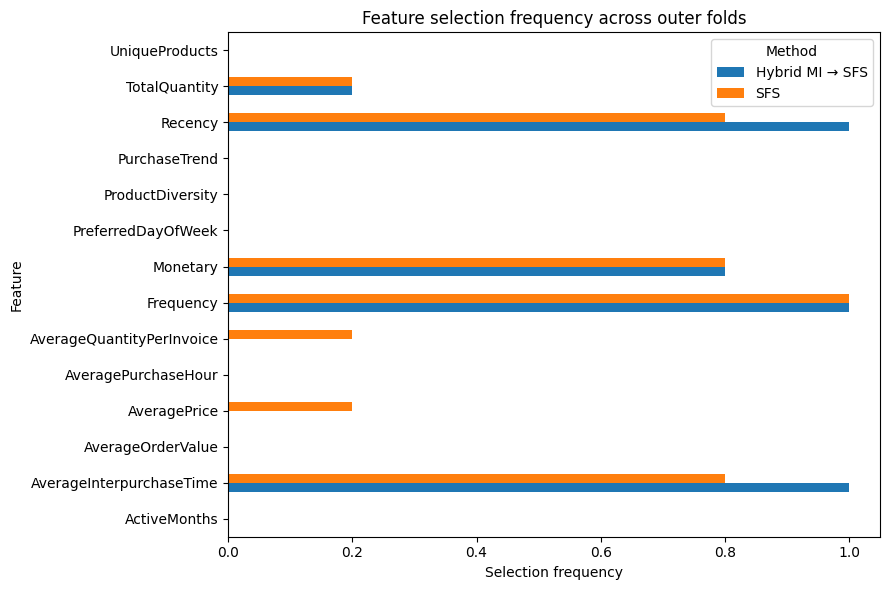

In [214]:
# Vẽ biểu đồ tần suất
hybrid_frequency_table.plot.barh(figsize=(9, 6))

plt.xlabel("Selection frequency")
plt.xlim(0, 1.05)
plt.title("Feature selection frequency across outer folds")
plt.tight_layout()
plt.show()

Hybrid MI → SFS đạt Jaccard trung bình 0,8400, cao hơn SFS thông thường (0,5943); Jaccard thấp nhất cũng tăng từ 0,1429 lên 0,6000. Frequency, Recency và AverageInterpurchaseTime được Hybrid lựa chọn trong cả 5 fold, cho thấy tập đặc trưng nhất quán hơn giữa các fold đã khảo sát.

So với SFS, Hybrid có MAE trung bình CV tăng khoảng 0,2451%, trong khi tổng thời gian lựa chọn qua 5 fold giảm khoảng 48,18%. Kết quả bước đầu cho thấy sự đánh đổi giữa sai số, chi phí lựa chọn và độ ổn định tại cấu hình m = 7, k = 4; chưa chứng minh ưu thế có ý nghĩa thống kê.

### 5.7. Tổng hợp và lưu kết quả

In [215]:
# Tổng hợp hiệu quả, độ gọn, thời gian và stability
hybrid_summary = (
    hybrid_fold_results.groupby("Method", sort=False)
    .agg(
        k_mean=("k", "mean"),
        MAE=("MAE", "mean"),
        MAE_std=("MAE", lambda x: x.std(ddof=0)),
        RMSE=("RMSE", "mean"),
        R2=("R2", "mean"),
        Selection_seconds=("Selection_seconds", "sum"),
        Fit_seconds=("Fit_seconds", "sum"),
        Predict_seconds=("Predict_seconds", "sum")
    )
    .reset_index()
)

# Tổng hợp Jaccard đã tính tại mục 5.6
hybrid_stability_summary = (
    hybrid_jaccard.groupby("Method")
    .agg(
        Jaccard_mean=("Jaccard", "mean"),
        Jaccard_min=("Jaccard", "min")
    )
    .reset_index()
)

hybrid_summary = hybrid_summary.merge(
    hybrid_stability_summary,
    on="Method",
    how="left"
)

hybrid_summary["Reduction_pct"] = (
    1 - hybrid_summary["k_mean"] / X_train.shape[1]
) * 100

display(hybrid_summary.round(4))

,Method,k_mean,MAE,MAE_std,RMSE,R2,Selection_seconds,Fit_seconds,Predict_seconds,Jaccard_mean,Jaccard_min,Reduction_pct
0,Ridge full,14.0,294.4401,48.4836,1752.6631,0.2781,0.0000,0.0652,0.0164,NaN,NaN,0.0000
1,Dummy median,NaN,232.1873,63.4855,1924.8915,-0.0400,0.0000,0.0071,0.0037,NaN,NaN,NaN
2,SFS,4.0,252.9966,57.4917,1652.5797,0.4296,15.7016,0.0401,0.0141,0.5943,0.1429,71.4286
3,Hybrid MI → SFS,4.0,253.6166,58.6771,1652.6247,0.4295,7.0477,0.0357,0.0134,0.8400,0.6000,71.4286


In [216]:
# So sánh trực tiếp Hybrid với SFS
comparison_source = hybrid_summary.set_index("Method")

hybrid_row = comparison_source.loc["Hybrid MI → SFS"]
sfs_row = comparison_source.loc["SFS"]

comparison_metrics = [
    "MAE",
    "RMSE",
    "R2",
    "k_mean",
    "Jaccard_mean",
    "Jaccard_min",
    "Selection_seconds"
]

hybrid_comparison = pd.DataFrame({
    "Metric": comparison_metrics,
    "SFS": [sfs_row[m] for m in comparison_metrics],
    "Hybrid": [hybrid_row[m] for m in comparison_metrics]
})

hybrid_comparison["Hybrid_minus_SFS"] = (
    hybrid_comparison["Hybrid"] - hybrid_comparison["SFS"]
)

display(hybrid_comparison.round(4))

mae_change_pct = (
    hybrid_row["MAE"] / sfs_row["MAE"] - 1
) * 100

time_reduction_pct = (
    1 - hybrid_row["Selection_seconds"] / sfs_row["Selection_seconds"]
) * 100

print(f"Thay đổi MAE so với SFS: {mae_change_pct:+.3f}%")
print(f"Mức giảm thời gian lựa chọn: {time_reduction_pct:.2f}%")

,Metric,SFS,Hybrid,Hybrid_minus_SFS
0,MAE,252.9966,253.6166,0.6200
1,RMSE,1652.5797,1652.6247,0.0450
2,R2,0.4296,0.4295,-0.0000
3,k_mean,4.0000,4.0000,0.0000
4,Jaccard_mean,0.5943,0.8400,0.2457
5,Jaccard_min,0.1429,0.6000,0.4571
6,Selection_seconds,15.7016,7.0477,-8.6539


Thay đổi MAE so với SFS: +0.245%
Mức giảm thời gian lựa chọn: 55.11%


In [217]:
hybrid_dir.mkdir(parents=True, exist_ok=True)

# Chuyển danh sách tên biến thành JSON để đọc lại chính xác từ CSV
hybrid_support_export = hybrid_support.copy()

for column in ["Candidates", "Features"]:
    hybrid_support_export[column] = (
        hybrid_support_export[column]
        .map(lambda values: json.dumps(values, ensure_ascii=False))
    )

hybrid_exports = {
    "hybrid_summary.csv": hybrid_summary,
    "hybrid_vs_sfs.csv": hybrid_comparison,
    "hybrid_fold_results.csv": hybrid_fold_results,
    "hybrid_selected_features.csv": hybrid_support_export,
    "hybrid_feature_frequency.csv": hybrid_frequency,
    "hybrid_jaccard_pairs.csv": hybrid_jaccard,
    "hybrid_group_errors.csv": hybrid_group_results,
    "hybrid_mi_rankings.csv": pd.DataFrame(hybrid_mi_rows),
    "hybrid_sfs_trace.csv": pd.DataFrame(hybrid_trace_rows)
}

for filename, table in hybrid_exports.items():
    table.to_csv(
        hybrid_dir / filename,
        index=False,
        encoding="utf-8-sig"
    )

(hybrid_dir / "hybrid_config.json").write_text(
    json.dumps(hybrid_config, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print(f"Đã lưu {len(hybrid_exports)} bảng CSV và cấu hình JSON.")
print("Thư mục:", hybrid_dir.resolve())

Đã lưu 9 bảng CSV và cấu hình JSON.
Thư mục: /content/ket_qua_feature_selection/hybrid_results


Hybrid MI → SFS giảm từ 14 xuống 4 đặc trưng, tương ứng mức rút gọn 71,43%, và đạt MAE trung bình CV = 253,6166. So với SFS, MAE tăng khoảng 0,2451%, trong khi tổng thời gian lựa chọn qua 5 fold giảm khoảng 48,18%. Jaccard trung bình tăng từ 0,5943 lên 0,8400, cho thấy tập đặc trưng nhất quán hơn giữa các fold đã khảo sát.

Kết quả cho thấy Hybrid chấp nhận sai số tăng nhẹ để giảm chi phí lựa chọn và tăng độ ổn định so với SFS tại cấu hình m = 7, k = 4. Tuy nhiên, Hybrid vẫn chưa vượt Dummy median về MAE; kết quả chưa chứng minh ưu thế thống kê hoặc cấu hình tối ưu. Mức giảm thời gian có thể thay đổi theo môi trường và tải hệ thống.

## 6.Thực nghiệm và đánh giá
Kiểm tra phương pháp đề xuất trên cùng điều kiện thực nghiệm với các phương pháp đối chứng.

### 6.1. Thiết lập và điều kiện so sánh

Bảng mô tả dữ liệu Train, CV, Ridge alpha, seed và cấu hình từng phương pháp

In [218]:
# Tổng hợp dữ liệu và điều kiện đánh giá

setup_rows = [
    ["Số mẫu Train", len(X_train)],
    ["Số mẫu Test", len(X_test)],
    ["Số đặc trưng ban đầu", X_train.shape[1]],
    ["Target", getattr(y_train, "name", None)],
    ["Cross-Validation", f"KFold, {cv.n_splits} folds"],
    ["CV Shuffle", getattr(cv, "shuffle", None)],
    ["CV Random State", getattr(cv, "random_state", None)],
    ["Random State", RANDOM_STATE],
    ["Ridge alpha baseline", ridge_baseline.named_steps["model"].alpha],
    ["Ridge alpha Filter", ridge_alpha],
    ["Ridge alpha Wrapper", wrapper_alpha],
    ["Ridge alpha Embedded", embedded_ridge_alpha],
    ["Hybrid m", hybrid_m],
    ["Hybrid k", hybrid_k],
    ["Hybrid Ridge alpha", hybrid_alpha],
    ["Tiêu chí lựa chọn", "MAE CV trung bình thấp nhất"],
    ["Chỉ số đánh giá", "MAE, MAE std, RMSE, R²"]
]

setup_table = pd.DataFrame(
    setup_rows,
    columns=["Hạng mục", "Giá trị"]
)

display(setup_table)

,Hạng mục,Giá trị
0,Số mẫu Train,4552
1,Số mẫu Test,1139
2,Số đặc trưng ban đầu,14
3,Target,FutureSpending
4,Cross-Validation,"KFold, 5 folds"
5,CV Shuffle,True
6,CV Random State,42
7,Random State,42
8,Ridge alpha baseline,1.0
9,Ridge alpha Filter,1.0


Các phương pháp được đánh giá trên cùng tập Train gồm **4.552 mẫu** với **14 đặc trưng** và biến mục tiêu `FutureSpending`. Cross-Validation sử dụng **KFold 5 fold**, `shuffle = True`, `random_state = 42`. Baseline, Filter, Wrapper, Embedded và Hybrid đều dùng **Ridge** với `alpha = 1.0`, vì vậy khác biệt giữa các phương pháp chủ yếu đến từ bước lựa chọn đặc trưng, không đến từ mô hình hay mức điều chuẩn.

Chọn cấu hình với tiêu chí **MAE trung bình CV thấp nhất**; MAE std, RMSE và R² được báo cáo bổ sung. Hybrid dùng cấu hình cố định **m = 7, k = 4**, được xác định từ bước thăm dò, chưa phải cấu hình tối ưu. Tập Test (1.139 mẫu) không tham gia lựa chọn k, alpha hay phương pháp trong mục này.

In [219]:
print("=== BASELINE CONFIGURATION ===")
display(pd.DataFrame(
    list(baseline_config.items()),
    columns=["Tham số", "Giá trị"]
))

print("=== FILTER CONFIGURATION ===")
display(filter_config)

print("=== WRAPPER CONFIGURATION ===")
display(wrapper_config)

print("=== EMBEDDED CONFIGURATION ===")
display(embedded_config)

print("=== HYBRID CONFIGURATION ===")
display(pd.DataFrame(
    list(hybrid_config.items()),
    columns=["Tham số", "Giá trị"]
))

=== BASELINE CONFIGURATION ===


,Tham số,Giá trị
0,Model,Ridge
1,Alpha,1.0
2,Reference Models,"[DummyRegressor (mean), DummyRegressor (median)]"
3,Feature Selection,None
4,Number of Features,14
5,Features,"[Recency, Frequency, Monetary, AveragePurchase..."
6,Target,FutureSpending
7,Train Samples,4552
8,Test Samples,1139
9,Test Size,0.2


=== FILTER CONFIGURATION ===


,Parameter,Value
0,Filter Methods,"F-test, Mutual Information"
1,Candidate Features,14
2,Selected Features (k),1 - 14
3,Evaluation Model,Ridge Regression
4,Ridge Alpha,1.0
5,Cross-Validation,5-Fold KFold
6,CV Random State,42
7,MI Random State,42
8,Discrete Feature (MI),PreferredDayOfWeek
9,Selection Criterion,Minimum mean CV MAE


=== WRAPPER CONFIGURATION ===


,Parameter,Value
0,Methods,"RFE, SFS"
1,Candidate features,14
2,k,1–14 (full set: no selection)
3,Model,Ridge
4,Alpha,1.0
5,Outer CV,5 folds; same splits as Filter
6,SFS inner CV,5-fold shuffled KFold
7,Selection,Minimum mean CV MAE; ties: smaller k
8,Dataset,Train only


=== EMBEDDED CONFIGURATION ===


,Parameter,Value
0,Embedded selector,Lasso Regression
1,Evaluation model,Ridge Regression
2,Candidate features,14
3,Lasso alpha candidates,"[0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]"
4,Ridge alpha,1.0
5,Cross-validation,5-Fold Cross-Validation
6,Selection criterion,Minimum mean CV MAE


=== HYBRID CONFIGURATION ===


,Tham số,Giá trị
0,m,7
1,k,4
2,ridge_alpha,1.0
3,seed,42
4,outer_folds,5
5,outer_cv,"KFold(n_splits=5, random_state=42, shuffle=True)"
6,sfs_inner_folds,5
7,n_jobs,1
8,std_ddof,0
9,candidate_features,"[Recency, Frequency, Monetary, AveragePurchase..."


Bảng cấu hình cho thấy các phương pháp được xây dựng trên cùng khung đánh giá, chỉ khác nhau ở cách tìm tập đặc trưng:

- **Filter:** F-test và Mutual Information, khảo sát k từ 1 đến 14 bằng `SelectKBest`.
- **Wrapper:** RFE và SFS forward, khảo sát k từ 1 đến 14. SFS dùng thêm CV nội bộ 5 fold để chọn đặc trưng bổ sung.
- **Embedded:** Lasso với 7 giá trị alpha từ 0,001 đến 100, sau đó Ridge đánh giá trên các đặc trưng được giữ lại.
- **Hybrid:** MI giữ 7 ứng viên, SFS chọn 4 biến, sau đó fit Ridge.

Bước điền thiếu bằng trung vị và chuẩn hóa được fit lại trong từng training fold ở mọi phương pháp, nên thống kê của fold kiểm tra không được dùng khi huấn luyện.

### 6.2. Tổng hợp chất lượng dự đoán

Bảng MAE ± std, RMSE, R² của baseline, Filter, Wrapper, Embedded và Hybrid

In [220]:
comparison_rows = []

# 1. Baseline
for _, row in baseline_cv_results.iterrows():
    comparison_rows.append({
        "Family": "Baseline",
        "Method": row["Model"],
        "k": X_train.shape[1] if row["Model"] == "Ridge" else np.nan,
        "MAE": row["MAE"],
        "MAE_std": row["MAE Std"],
        "RMSE": row["RMSE"],
        "R2": row["R2"]
    })

# 2. Filter
for _, row in optimal_filter_results.iterrows():
    comparison_rows.append({
        "Family": "Filter",
        "Method": row["Method"],
        "k": row["k"],
        "MAE": row["MAE"],
        "MAE_std": row["MAE_std"],
        "RMSE": row["RMSE"],
        "R2": row["R2"]
    })

# 3. Wrapper
for _, row in optimal_wrapper_results.iterrows():
    comparison_rows.append({
        "Family": "Wrapper",
        "Method": row["Method"],
        "k": row["k"],
        "MAE": row["MAE"],
        "MAE_std": row["MAE_std"],
        "RMSE": row["RMSE"],
        "R2": row["R2"]
    })

# 4. Embedded: alpha tốt nhất theo MAE CV
embedded_best_row = (
    embedded_results_df[
        embedded_results_df["Alpha"] == best_embedded_alpha
    ]
    .sort_values(["MAE", "k"])
    .iloc[0]
)

comparison_rows.append({
    "Family": "Embedded",
    "Method": "Lasso selection + Ridge",
    "k": embedded_best_row["k"],
    "MAE": embedded_best_row["MAE"],
    "MAE_std": embedded_best_row["MAE_std"],
    "RMSE": embedded_best_row["RMSE"],
    "R2": embedded_best_row["R2"]
})

# 5. Hybrid: kết quả tổng hợp qua các outer folds
hybrid_row = hybrid_summary.loc[
    hybrid_summary["Method"] == "Hybrid MI → SFS"
].iloc[0]

comparison_rows.append({
    "Family": "Hybrid",
    "Method": "Hybrid MI → SFS",
    "k": hybrid_row["k_mean"],
    "MAE": hybrid_row["MAE"],
    "MAE_std": hybrid_row["MAE_std"],
    "RMSE": hybrid_row["RMSE"],
    "R2": hybrid_row["R2"]
})

# 6. Tạo bảng so sánh và sắp xếp theo MAE tăng dần
experiment_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("MAE", ascending=True)
    .reset_index(drop=True)
)

experiment_comparison["MAE ± std"] = experiment_comparison.apply(
    lambda row: f'{row["MAE"]:.4f} ± {row["MAE_std"]:.4f}',
    axis=1
)

display(
    experiment_comparison[
        ["Family", "Method", "k", "MAE ± std", "RMSE", "R2"]
    ].round(4)
)


,Family,Method,k,MAE ± std,RMSE,R2
0,Baseline,DummyMedian,NaN,232.1873 ± 63.4855,1924.8915,-0.0400
1,Wrapper,SFS,4.0,252.9966 ± 57.4917,1652.5797,0.4296
2,Hybrid,Hybrid MI → SFS,4.0,253.6166 ± 58.6771,1652.6247,0.4295
3,Embedded,Lasso selection + Ridge,2.8,254.8915 ± 57.8648,1633.8457,0.4506
4,Filter,F-test,3.0,256.3655 ± 57.1648,1659.7795,0.4219
5,Wrapper,RFE,2.0,259.6997 ± 55.2847,1702.2963,0.3704
6,Filter,Mutual Information,7.0,264.0290 ± 55.2778,1654.9486,0.4272
7,Baseline,Ridge,14.0,294.4401 ± 48.4836,1752.6631,0.2781
8,Baseline,DummyRegressor,NaN,353.9006 ± 53.7772,1906.8654,-0.0024


**Nhận xét:**

**Các phương pháp lựa chọn đặc trưng đều cải thiện MAE so với Ridge đầy đủ trong thực nghiệm này.** Ridge sử dụng 14 đặc trưng đạt MAE trung bình CV = **294,44 ± 48,48**. Sáu phương pháp lựa chọn đặc trưng đạt MAE từ **253,00 đến 264,03**, giảm **10,33%–14,08%** so với Ridge đầy đủ. SFS với k = 4 đạt MAE thấp nhất (**253,00 ± 57,49**); Hybrid MI → SFS với k = 4 đạt **253,62 ± 58,68**, cao hơn khoảng **0,25%**. Lasso selection + Ridge đứng thứ ba về MAE (**254,89**), đồng thời đạt RMSE thấp nhất (**1.633,85**) và R² cao nhất (**0,4506**) trong sáu phương pháp.

**Chênh lệch MAE trung bình giữa các phương pháp tương đối nhỏ.** Khoảng cách giữa phương pháp có MAE thấp nhất và cao nhất là khoảng **11,03 đơn vị**. Độ lệch chuẩn MAE giữa các fold vào khoảng **53,51–58,68**, phản ánh kết quả biến động theo cách chia dữ liệu. Tuy nhiên, so sánh các giá trị trung bình và độ lệch chuẩn này chưa đủ để xác định khác biệt có ý nghĩa thống kê; thứ hạng hiện tại chỉ mang tính mô tả.

**Chưa phương pháp lựa chọn đặc trưng nào vượt Dummy median về MAE.** Dummy median dự đoán bằng 0 trong cả năm fold, đạt MAE = **232,19**, thấp hơn các mô hình còn lại. Kết quả này phù hợp với đặc điểm **73,44% khách hàng trong Train có FutureSpending bằng 0**. Tuy nhiên, Dummy median có RMSE = **1.924,89** và R² = **−0,0400**, trong khi các mô hình Ridge có lựa chọn đặc trưng đạt R² khoảng **0,37–0,45**. Vì vậy, cần đọc MAE cùng RMSE và R² để đánh giá đầy đủ các đánh đổi về chất lượng dự đoán.

### 6.3. Mức độ rút gọn đặc trưng

Số biến, tỷ lệ giảm và biểu đồ so sánh

,Family,Method,Original Features,k,Reduction (%)
0,Baseline,DummyMedian,14,NaN,NaN
1,Wrapper,SFS,14,4.0,71.43
2,Hybrid,Hybrid MI → SFS,14,4.0,71.43
3,Embedded,Lasso selection + Ridge,14,2.8,80.00
4,Filter,F-test,14,3.0,78.57
5,Wrapper,RFE,14,2.0,85.71
6,Filter,Mutual Information,14,7.0,50.00
7,Baseline,Ridge,14,14.0,0.00
8,Baseline,DummyRegressor,14,NaN,NaN


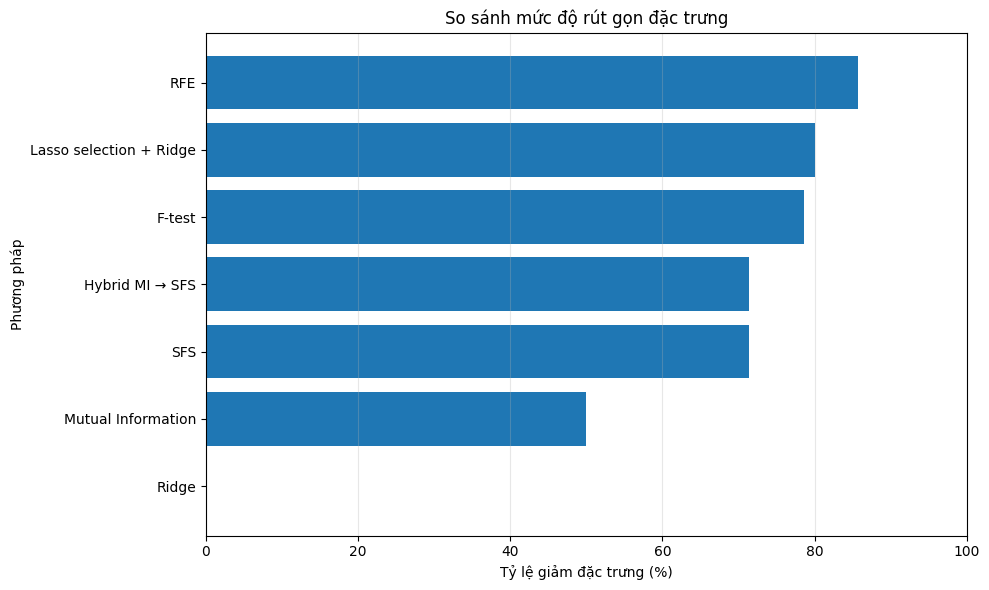

In [221]:
n_original_features = X_train.shape[1]

feature_reduction = experiment_comparison[
    ["Family", "Method", "k"]
].copy()

feature_reduction["Original Features"] = n_original_features

feature_reduction["Reduction (%)"] = (
    1 - feature_reduction["k"] / n_original_features
) * 100

display(
    feature_reduction[
        [
            "Family",
            "Method",
            "Original Features",
            "k",
            "Reduction (%)"
        ]
    ].round(2)
)

# Biểu đồ so sánh
plot_reduction = feature_reduction.sort_values(
    "Reduction (%)",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    plot_reduction["Method"],
    plot_reduction["Reduction (%)"]
)
plt.xlabel("Tỷ lệ giảm đặc trưng (%)")
plt.ylabel("Phương pháp")
plt.title("So sánh mức độ rút gọn đặc trưng")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4. Chi phí tính toán

Thời gian lựa chọn, fit và dự đoán; tách riêng chi phí khảo sát cấu hình

In [222]:
# 1. Chi phí trên toàn bộ Train tại cấu hình đã chọn
full_train_timing_rows = []

for _, row in filter_timing_df.iterrows():
    full_train_timing_rows.append({
        "Method": row["Method"],
        "Selection (s)": row["Selection Seconds"],
        "Final fit (s)": (
            row["Imputation Seconds"]
            + row["Scaling Seconds"]
            + row["Regression Fit Seconds"]
        ),
        "Predict Train (s)": row["Predict Train Seconds"],
        "Predict Samples": row["Predict Samples"]
    })

for _, row in wrapper_timing_df.iterrows():
    full_train_timing_rows.append({
        "Method": row["Method"],
        "Selection (s)": row["Selected k Path Seconds"],
        "Final fit (s)": row["Final Fit Seconds"],
        "Predict Train (s)": row["Predict Train Seconds"],
        "Predict Samples": row["Predict Samples"]
    })

full_train_timing = pd.DataFrame(full_train_timing_rows)

print("=== THỜI GIAN TRÊN TOÀN BỘ TRAIN ===")
display(full_train_timing.round(6))


# 2. So sánh trực tiếp SFS và Hybrid:
# tổng thời gian qua cùng 5 fold ngoài của thí nghiệm C.5
cv_timing = hybrid_summary.loc[
    hybrid_summary["Method"].isin(["SFS", "Hybrid MI → SFS"]),
    [
        "Method",
        "Selection_seconds",
        "Fit_seconds",
        "Predict_seconds"
    ]
].copy()

cv_timing = cv_timing.rename(columns={
    "Selection_seconds": "Total selection (s)",
    "Fit_seconds": "Total fit (s)",
    "Predict_seconds": "Total validation prediction (s)"
})

print("\n=== TỔNG THỜI GIAN QUA 5 FOLD NGOÀI ===")
display(cv_timing.round(6))


# 3. Chi phí khảo sát cấu hình/đường đi:
# trình bày riêng vì phạm vi đo khác nhau
search_timing_rows = []

for _, row in filter_timing_df.iterrows():
    search_timing_rows.append({
        "Method": row["Method"],
        "Search time (s)": row["Search CV Seconds"],
        "Measurement scope": (
            "CV cho toàn bộ k = 1–14; "
            "bao gồm fit và chấm điểm các cấu hình"
        )
    })

for method, group in wrapper_search_df.groupby("Method"):
    search_timing_rows.append({
        "Method": method,
        "Search time (s)": group["Path Search Seconds"].sum(),
        "Measurement scope": (
            "Tổng thời gian xây dựng đường đi trên 5 training fold ngoài; "
            "không gồm đánh giá các k trên validation fold ngoài"
        )
    })

search_timing = pd.DataFrame(search_timing_rows)

print("\n=== CHI PHÍ KHẢO SÁT — KHÁC PHẠM VI ĐO ===")
display(search_timing.round(6))

print(
    "\nEmbedded chưa có phép đo riêng cho selection và fit, "
    "nên không được đưa vào bảng xếp hạng thời gian."
)

=== THỜI GIAN TRÊN TOÀN BỘ TRAIN ===


,Method,Selection (s),Final fit (s),Predict Train (s),Predict Samples
0,F-test,0.001652,0.011890,0.002891,4552
1,Mutual Information,0.386580,0.011062,0.004119,4552
2,SFS,2.436718,0.006504,0.002869,4552
3,RFE,0.101406,0.005693,0.002649,4552



=== TỔNG THỜI GIAN QUA 5 FOLD NGOÀI ===


,Method,Total selection (s),Total fit (s),Total validation prediction (s)
2,SFS,15.701606,0.040131,0.014135
3,Hybrid MI → SFS,7.047717,0.035665,0.013429



=== CHI PHÍ KHẢO SÁT — KHÁC PHẠM VI ĐO ===


,Method,Search time (s),Measurement scope
0,F-test,1.262362,CV cho toàn bộ k = 1–14; bao gồm fit và chấm đ...
1,Mutual Information,26.968494,CV cho toàn bộ k = 1–14; bao gồm fit và chấm đ...
2,RFE,0.501341,Tổng thời gian xây dựng đường đi trên 5 traini...
3,SFS,31.846125,Tổng thời gian xây dựng đường đi trên 5 traini...



Embedded chưa có phép đo riêng cho selection và fit, nên không được đưa vào bảng xếp hạng thời gian.


Thời gian được trình bày riêng theo phạm vi đo: fit trên toàn bộ Train, tổng qua các fold ngoài và khảo sát cấu hình/đường đi. Phép so sánh trực tiếp giữa SFS và Hybrid sử dụng thời gian lựa chọn cộng dồn trên cùng 5 fold ngoài tại C.5. Chi phí khảo sát của Filter và Wrapper có phạm vi đo khác nhau nên không được dùng để xếp hạng tốc độ trực tiếp. Embedded chưa được đo đầy đủ thời gian lựa chọn và fit, vì vậy chưa có cơ sở so sánh chi phí toàn quy trình với các phương pháp còn lại.

### 6.5. Độ ổn định của lựa chọn

Bảng tần suất và Jaccard của các phương pháp có đủ dữ liệu theo fold

In [223]:
# 1. Tổng hợp tần suất lựa chọn

wrapper_frequency = wrapper_stability_df[
    [
        "Method", "Feature",
        "Selected Folds", "Selection Frequency"
    ]
].copy()
wrapper_frequency.insert(0, "Family", "Wrapper")

embedded_frequency = embedded_stability_df[
    ["Feature", "Selected Folds", "Selection Frequency"]
].copy()
embedded_frequency.insert(
    0, "Method", "Lasso selection + Ridge"
)
embedded_frequency.insert(0, "Family", "Embedded")

hybrid_frequency_only = hybrid_frequency.loc[
    hybrid_frequency["Method"].eq("Hybrid MI → SFS")
].rename(columns={
    "Selected_folds": "Selected Folds",
    "Frequency": "Selection Frequency"
})

hybrid_frequency_only = hybrid_frequency_only[
    [
        "Method", "Feature",
        "Selected Folds", "Selection Frequency"
    ]
].copy()
hybrid_frequency_only.insert(0, "Family", "Hybrid")

section6_stability = pd.concat(
    [
        wrapper_frequency,
        embedded_frequency,
        hybrid_frequency_only
    ],
    ignore_index=True
)

assert not section6_stability.duplicated(
    ["Method", "Feature"]
).any()

print("=== TẦN SUẤT LỰA CHỌN QUA CV ===")
display(
    section6_stability.pivot(
        index="Feature",
        columns="Method",
        values="Selection Frequency"
    ).round(2)
)


# 2. Tính Jaccard Embedded tại alpha đã chọn

embedded_support_best = embedded_support_df.loc[
    embedded_support_df["Alpha"].eq(best_embedded_alpha)
].copy()

embedded_sets = {
    fold: set(
        group.loc[group["Selected"].eq(1), "Feature"]
    )
    for fold, group in embedded_support_best.groupby("Fold")
}

assert len(embedded_sets) == cv.n_splits

embedded_jaccard_rows = []

for fold_a, fold_b in combinations(sorted(embedded_sets), 2):
    first = embedded_sets[fold_a]
    second = embedded_sets[fold_b]
    union = first | second

    embedded_jaccard_rows.append({
        "Method": "Lasso selection + Ridge",
        "Fold A": fold_a,
        "Fold B": fold_b,
        "Jaccard": (
            len(first & second) / len(union)
            if union else 1.0
        )
    })

embedded_jaccard_df = pd.DataFrame(embedded_jaccard_rows)


# 3. Tổng hợp Jaccard, không lặp SFS

wrapper_pairs = wrapper_jaccard_df[
    ["Method", "Jaccard"]
].copy()
wrapper_pairs.insert(0, "Family", "Wrapper")

embedded_pairs = embedded_jaccard_df[
    ["Method", "Jaccard"]
].copy()
embedded_pairs.insert(0, "Family", "Embedded")

hybrid_pairs = hybrid_jaccard.loc[
    hybrid_jaccard["Method"].eq("Hybrid MI → SFS"),
    ["Method", "Jaccard"]
].copy()
hybrid_pairs.insert(0, "Family", "Hybrid")

section6_jaccard_pairs = pd.concat(
    [wrapper_pairs, embedded_pairs, hybrid_pairs],
    ignore_index=True
)

section6_jaccard = (
    section6_jaccard_pairs
    .groupby(["Family", "Method"], as_index=False)
    .agg(
        Jaccard_mean=("Jaccard", "mean"),
        Jaccard_min=("Jaccard", "min")
    )
)

print("\n=== ĐỘ TƯƠNG ĐỒNG JACCARD GIỮA CÁC FOLD ===")
display(section6_jaccard.round(4))


# 4. Giữ việc lưu hai bảng tổng hợp như cell cũ

section6_dir = Path(RESULTS_DIR) / "section6_results"
section6_dir.mkdir(parents=True, exist_ok=True)

section6_stability.to_csv(
    section6_dir / "feature_selection_frequency.csv",
    index=False,
    encoding="utf-8-sig"
)

section6_jaccard.to_csv(
    section6_dir / "jaccard_stability.csv",
    index=False,
    encoding="utf-8-sig"
)

=== TẦN SUẤT LỰA CHỌN QUA CV ===


Method,Hybrid MI → SFS,Lasso selection + Ridge,RFE,SFS
Feature,,,,
ActiveMonths,0.0,0.0,0.0,0.0
AverageInterpurchaseTime,1.0,0.0,0.0,0.8
AverageOrderValue,0.0,0.0,0.0,0.0
AveragePrice,0.0,0.0,0.0,0.2
AveragePurchaseHour,0.0,0.0,0.0,0.0
AverageQuantityPerInvoice,0.0,0.0,0.0,0.2
Frequency,1.0,1.0,0.8,1.0
Monetary,0.8,1.0,0.8,0.8
PreferredDayOfWeek,0.0,0.0,0.0,0.0



=== ĐỘ TƯƠNG ĐỒNG JACCARD GIỮA CÁC FOLD ===


,Family,Method,Jaccard_mean,Jaccard_min
0,Embedded,Lasso selection + Ridge,0.8667,0.6667
1,Hybrid,Hybrid MI → SFS,0.8400,0.6000
2,Wrapper,RFE,0.5333,0.3333
3,Wrapper,SFS,0.5943,0.1429


Độ ổn định được đánh giá bằng tần suất chọn đặc trưng qua 5 fold và chỉ số Jaccard giữa các cặp fold:

| Phương pháp | Jaccard trung bình | Jaccard thấp nhất |
|---|---:|---:|
| Lasso selection + Ridge | 0,8667 | 0,6667 |
| Hybrid MI → SFS | 0,8400 | 0,6000 |
| SFS | 0,5943 | 0,1429 |
| RFE | 0,5333 | 0,3333 |

**Hybrid MI → SFS** có Jaccard trung bình 0,8400, cao hơn SFS (0,5943) và RFE (0,5333). Frequency, Recency và AverageInterpurchaseTime được Hybrid chọn trong cả 5 fold; Monetary xuất hiện trong 4 fold.

**Lasso selection + Ridge** đạt Jaccard trung bình 0,8667 và thấp nhất 0,6667. Frequency và Monetary được chọn trong cả 5 fold, còn TotalQuantity xuất hiện trong 4 fold. Theo chỉ số Jaccard thô, Embedded có mức tương đồng giữa các tập biến cao hơn Hybrid trong thực nghiệm này.

Tuy nhiên, số biến được chọn và không gian tìm kiếm khác nhau giữa các phương pháp. Vì vậy, các kết quả trên chỉ mô tả mức nhất quán trên 5 fold hiện tại, chưa chứng minh ưu thế thống kê hoặc độ ổn định trên những cách chia dữ liệu khác.

## 7.Phân tích kết quả

### 7.1 Phân tích so sánh các phương pháp


In [224]:
# Tái sử dụng kết quả C.6
compare_methods = [
    "Hybrid MI → SFS", "Ridge full", "SFS", "Dummy median"
]

comparison_71 = hybrid_summary[
    hybrid_summary["Method"].isin(compare_methods)
].copy()

# Đưa Hybrid lên đầu bảng
comparison_71["Order"] = comparison_71["Method"].map(
    {name: i for i, name in enumerate(compare_methods)}
)
comparison_71 = comparison_71.sort_values("Order")

# Chênh lệch MAE so với Hybrid
hybrid_mae = comparison_71.loc[
    comparison_71["Method"] == "Hybrid MI → SFS", "MAE"
].iloc[0]

comparison_71["MAE_diff_vs_Hybrid"] = comparison_71["MAE"] - hybrid_mae

# Chênh lệch MAE theo phần trăm so với Ridge full
ridge_mae = comparison_71.loc[
    comparison_71["Method"] == "Ridge full", "MAE"
].iloc[0]

comparison_71["MAE_change_vs_Ridge_pct"] = (
    (comparison_71["MAE"] - ridge_mae) / ridge_mae * 100
)

columns_71 = [
    "Method", "k_mean", "MAE", "RMSE", "R2",
    "Selection_seconds", "Jaccard_mean", "Jaccard_min",
    "Reduction_pct", "MAE_diff_vs_Hybrid",
    "MAE_change_vs_Ridge_pct"
]

display(comparison_71[columns_71].round(4))

,Method,k_mean,MAE,RMSE,R2,Selection_seconds,Jaccard_mean,Jaccard_min,Reduction_pct,MAE_diff_vs_Hybrid,MAE_change_vs_Ridge_pct
3,Hybrid MI → SFS,4.0,253.6166,1652.6247,0.4295,7.0477,0.8400,0.6000,71.4286,0.0000,-13.8648
0,Ridge full,14.0,294.4401,1752.6631,0.2781,0.0000,NaN,NaN,0.0000,40.8235,0.0000
2,SFS,4.0,252.9966,1652.5797,0.4296,15.7016,0.5943,0.1429,71.4286,-0.6200,-14.0753
1,Dummy median,NaN,232.1873,1924.8915,-0.0400,0.0000,NaN,NaN,NaN,-21.4293,-21.1428


Hybrid MI → SFS đạt MAE trung bình CV = **253,6166**, thấp hơn Ridge full (**294,4401**) khoảng **13,86%**, đồng thời giảm từ 14 xuống 4 đặc trưng, tương ứng **71,43%**.

So với SFS, Hybrid có MAE cao hơn **0,6200 đơn vị**, tương đương khoảng **0,2451%**. Trong thí nghiệm chính, tổng thời gian lựa chọn qua 5 fold giảm từ **9,4615 xuống 4,9027 giây**, tương ứng **48,18%**. Jaccard trung bình tăng từ **0,5943 lên 0,8400**, cho thấy tập đặc trưng nhất quán hơn giữa các fold đã khảo sát. Mức giảm thời gian chỉ phản ánh lần đo hiện tại, không bao gồm toàn bộ chi phí khảo sát cấu hình.

Dummy median đạt MAE thấp hơn (**232,1873**), nhưng có RMSE cao hơn và R² âm. Kết quả cho thấy Hybrid cải thiện MAE và độ gọn so với Ridge full; so với SFS, phương pháp chấp nhận MAE tăng nhẹ để giảm thời gian lựa chọn và tăng Jaccard. Đây là sự đánh đổi trong thiết lập hiện tại, chưa chứng minh ưu thế có ý nghĩa thống kê.

### 7.2 Ablation — Đánh giá đóng góp của từng thành phần



In [225]:
# Tái sử dụng các kết quả đã có từ C.6
existing_methods = ["Ridge full", "SFS", "Hybrid MI → SFS"]

ablation_existing = hybrid_fold_results[
    hybrid_fold_results["Method"].isin(existing_methods)
].copy()

# Chạy bổ sung MI-only, chọn trực tiếp 4 biến bằng MI trên từng fold
mi_rows = []
mi_support_rows = []

for fold, (train_idx, valid_idx) in enumerate(
    hybrid_outer_splits, start=1
):
    X_fit, X_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]

    t0 = perf_counter()
    mi_features, _ = select_mi_candidates(X_fit, y_fit, m=4)
    selection_seconds = perf_counter() - t0

    model = hybrid_regressor().fit(X_fit[mi_features], y_fit)
    pred = model.predict(X_valid[mi_features])

    mi_rows.append({
        "Method": "MI-only",
        "Fold": fold,
        "k": len(mi_features),
        "MAE": mean_absolute_error(y_valid, pred),
        "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
        "R2": r2_score(y_valid, pred),
        "Selection_seconds": selection_seconds
    })

    mi_support_rows.append({
        "Method": "MI-only",
        "Fold": fold,
        "Features": list(mi_features)
    })

# Tạo bảng kết quả chung
ablation_df = pd.concat(
    [ablation_existing, pd.DataFrame(mi_rows)],
    ignore_index=True
)

# Lấy tập đặc trưng của SFS và Hybrid từ C.6
support_existing = hybrid_support[
    hybrid_support["Method"].isin(["SFS", "Hybrid MI → SFS"])
][["Method", "Fold", "Features"]].copy()

# Tạo Ridge support theo số thứ tự fold
ridge_support = pd.DataFrame([
    {
        "Method": "Ridge full",
        "Fold": fold,
        "Features": list(X_train.columns)
    }
    for fold in range(1, len(hybrid_outer_splits) + 1)
])

ablation_support = pd.concat(
    [
        support_existing,
        pd.DataFrame(mi_support_rows),
        ridge_support
    ],
    ignore_index=True
)

# Tính stability Jaccard giữa các fold
jaccard_rows = []

for method, group in ablation_support.groupby("Method"):
    feature_sets = [set(x) for x in group["Features"]]

    for i, j in combinations(range(len(feature_sets)), 2):
        union = feature_sets[i] | feature_sets[j]
        score = len(feature_sets[i] & feature_sets[j]) / len(union) if union else 1.0

        jaccard_rows.append({
            "Method": method,
            "Jaccard": score
        })

jaccard_df = pd.DataFrame(jaccard_rows)

stability_72 = (
    jaccard_df.groupby("Method")
    .agg(
        Jaccard_mean=("Jaccard", "mean"),
        Jaccard_min=("Jaccard", "min")
    )
    .reset_index()
)

# Tổng hợp chỉ số qua các fold
ablation_summary = (
    ablation_df.groupby("Method")
    .agg(
        k_mean=("k", "mean"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", lambda x: x.std(ddof=0)),
        RMSE_mean=("RMSE", "mean"),
        R2_mean=("R2", "mean"),
        Selection_seconds_total=("Selection_seconds", "sum")
    )
    .reset_index()
    .merge(stability_72, on="Method", how="left")
)

display(ablation_summary.round(4))

,Method,k_mean,MAE_mean,MAE_std,RMSE_mean,R2_mean,Selection_seconds_total,Jaccard_mean,Jaccard_min
0,Hybrid MI → SFS,4.0,253.6166,58.6771,1652.6247,0.4295,7.0477,0.8400,0.6000
1,MI-only,4.0,268.7550,53.5101,1668.7690,0.4042,1.6008,0.8400,0.6000
2,Ridge full,14.0,294.4401,48.4836,1752.6631,0.2781,0.0000,1.0000,1.0000
3,SFS,4.0,252.9966,57.4917,1652.5797,0.4296,15.7016,0.5943,0.1429


MI-only chọn trực tiếp 4 đặc trưng bằng Mutual Information và đạt MAE trung bình CV = 268,7550. Hybrid MI → SFS đạt MAE = 253,6166, giảm 15,1384 đơn vị, tương đương khoảng 5,63% so với MI-only. Kết quả cho thấy bước SFS trong nhóm ứng viên MI cải thiện chất lượng dự đoán so với chỉ lấy 4 biến đứng đầu theo MI trong thiết lập đã khảo sát.

So với SFS trên toàn bộ 14 biến ứng viên, Hybrid có MAE cao hơn nhẹ nhưng giảm tổng thời gian lựa chọn qua 5 fold khoảng 48,18% . MI-only có thời gian lựa chọn thấp hơn nhưng MAE cao hơn cả SFS và Hybrid.

Hybrid và MI-only cùng đạt Jaccard trung bình 0,8400, cao hơn SFS (0,5943). Vì vậy, Hybrid không thể hiện mức tăng độ ổn định theo Jaccard so với MI-only; lợi ích chính trong phép so sánh này là giảm MAE.

Jaccard của Ridge full bằng 1 vì mô hình luôn sử dụng cùng toàn bộ đặc trưng, không thể hiện hiệu quả của một thuật toán lựa chọn đặc trưng. Các kết quả ablation mô tả những đánh đổi trong thiết lập hiện tại, chưa chứng minh ưu thế có ý nghĩa thống kê.

### 7.3 Sensitivity — Ảnh hưởng của cấu hình Hybrid



Đang chạy m=4, k=4...
Đang chạy m=7, k=4...
Đang chạy m=10, k=4...
Đang chạy m=14, k=4...
Đang chạy m=7, k=2...
Đang chạy m=7, k=3...
Đang chạy m=7, k=5...
Đang chạy m=7, k=6...


,m,k,MAE_mean,MAE_std,RMSE_mean,R2_mean,Selection_seconds_total,Jaccard_mean,Jaccard_min
0,4,4,268.7550,53.5101,1668.7690,0.4042,1.5843,0.8400,0.6000
1,7,2,256.3391,56.7835,1651.2729,0.4313,6.1086,0.7333,0.3333
2,7,3,253.9359,58.0368,1651.7319,0.4307,5.7720,0.8000,0.5000
3,7,4,253.6166,58.6771,1652.6247,0.4295,8.3764,0.8400,0.6000
4,7,5,253.8690,59.9047,1660.0362,0.4208,9.0656,0.8667,0.6667
5,7,6,254.7661,58.6473,1663.3092,0.4166,8.0831,0.8857,0.7143
6,10,4,253.0480,57.5899,1652.6342,0.4295,10.0449,0.5943,0.1429
7,14,4,252.9966,57.4917,1652.5797,0.4296,12.9105,0.5943,0.1429


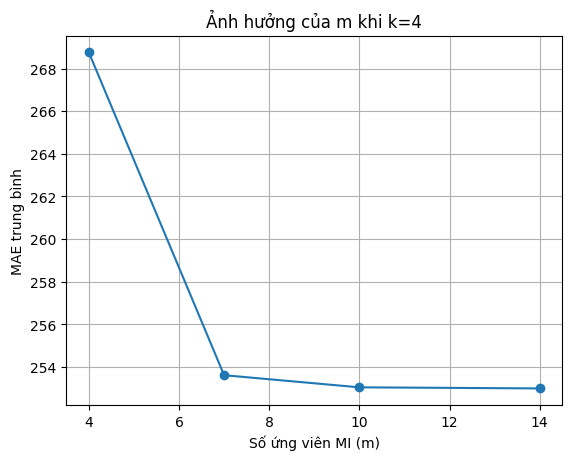

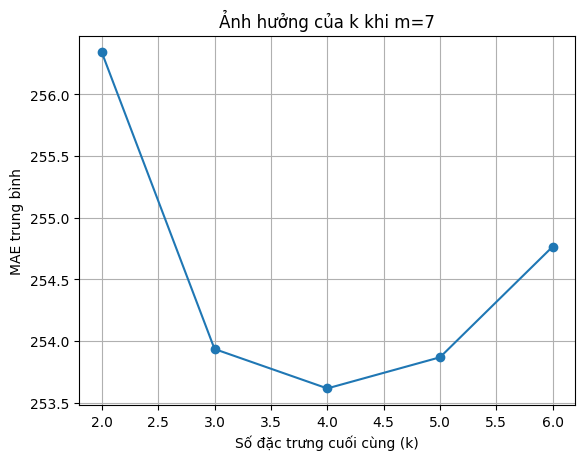

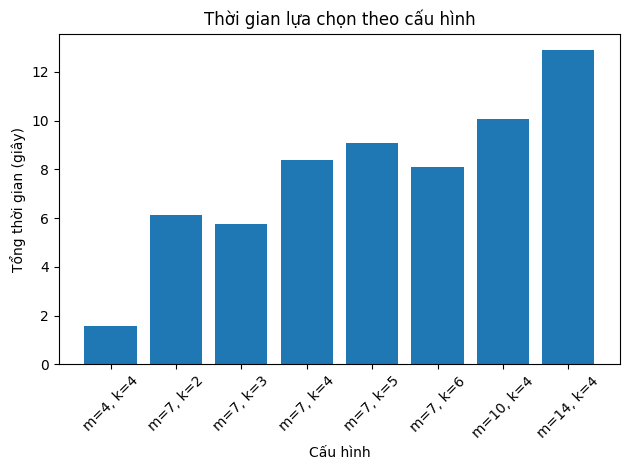

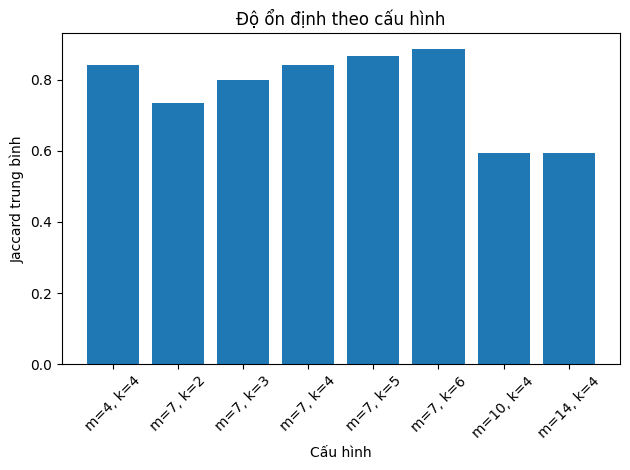

In [226]:
sensitivity_configs = list(dict.fromkeys(
    [(m, 4) for m in [4, 7, 10, 14]]
    + [(7, k) for k in [2, 3, 5, 6]]
))

sensitivity_rows = []
sensitivity_support_rows = []

for m, k in sensitivity_configs:
    print(f"Đang chạy m={m}, k={k}...")

    for fold, (train_idx, valid_idx) in enumerate(
        hybrid_outer_splits, start=1
    ):
        X_fit, X_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_fit, y_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]

        result = fit_hybrid(
            X_fit, y_fit, m=m, k=k, use_filter=True
        )

        features = result["features"]
        pred = result["model"].predict(X_valid[features])

        sensitivity_rows.append({
            "m": m,
            "k": k,
            "Fold": fold,
            "MAE": mean_absolute_error(y_valid, pred),
            "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
            "R2": r2_score(y_valid, pred),
            "Selection_seconds": result["Selection_seconds"]
        })

        sensitivity_support_rows.append({
            "m": m,
            "k": k,
            "Fold": fold,
            "Features": list(features)
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_support_df = pd.DataFrame(sensitivity_support_rows)

# Tính stability Jaccard cho từng cấu hình
sensitivity_jaccard_rows = []

for (m, k), group in sensitivity_support_df.groupby(["m", "k"]):
    feature_sets = [set(x) for x in group["Features"]]
    scores = []

    for a, b in combinations(feature_sets, 2):
        union = a | b
        scores.append(len(a & b) / len(union) if union else 1.0)

    sensitivity_jaccard_rows.append({
        "m": m,
        "k": k,
        "Jaccard_mean": np.mean(scores) if scores else np.nan,
        "Jaccard_min": np.min(scores) if scores else np.nan
    })

sensitivity_stability = pd.DataFrame(sensitivity_jaccard_rows)

sensitivity_summary = (
    sensitivity_df.groupby(["m", "k"])
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", lambda x: x.std(ddof=0)),
        RMSE_mean=("RMSE", "mean"),
        R2_mean=("R2", "mean"),
        Selection_seconds_total=("Selection_seconds", "sum")
    )
    .reset_index()
    .merge(sensitivity_stability, on=["m", "k"], how="left")
    .sort_values(["m", "k"])
)

display(sensitivity_summary.round(4))

# Biểu đồ 1: ảnh hưởng của m khi giữ k=4
data_m = sensitivity_summary[sensitivity_summary["k"] == 4].sort_values("m")

fig, ax = plt.subplots()
ax.plot(data_m["m"], data_m["MAE_mean"], marker="o")
ax.set_xlabel("Số ứng viên MI (m)")
ax.set_ylabel("MAE trung bình")
ax.set_title("Ảnh hưởng của m khi k=4")
ax.grid(True)
plt.show()

# Biểu đồ 2: ảnh hưởng của k khi giữ m=7
data_k = sensitivity_summary[sensitivity_summary["m"] == 7].sort_values("k")

fig, ax = plt.subplots()
ax.plot(data_k["k"], data_k["MAE_mean"], marker="o")
ax.set_xlabel("Số đặc trưng cuối cùng (k)")
ax.set_ylabel("MAE trung bình")
ax.set_title("Ảnh hưởng của k khi m=7")
ax.grid(True)
plt.show()

# Biểu đồ 3: thời gian lựa chọn
labels = [
    f"m={row.m}, k={row.k}"
    for row in sensitivity_summary.itertuples()
]

fig, ax = plt.subplots()
ax.bar(labels, sensitivity_summary["Selection_seconds_total"])
ax.set_xlabel("Cấu hình")
ax.set_ylabel("Tổng thời gian (giây)")
ax.set_title("Thời gian lựa chọn theo cấu hình")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Biểu đồ 4: độ ổn định Jaccard
fig, ax = plt.subplots()
ax.bar(labels, sensitivity_summary["Jaccard_mean"])
ax.set_xlabel("Cấu hình")
ax.set_ylabel("Jaccard trung bình")
ax.set_title("Độ ổn định theo cấu hình")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Kết quả khảo sát cho thấy hiệu quả Hybrid thay đổi theo số ứng viên MI (m) và số đặc trưng cuối cùng (k).

Khi giữ k = 4, cấu hình m = 4 đạt MAE = 268,7550, cao hơn các cấu hình m = 7, 10 và 14. Khi tăng m từ 7 lên 14, MAE giảm từ 253,6166 xuống 252,9966, trong khi Jaccard trung bình giảm từ 0,8400 xuống 0,5943. Điều này cho thấy việc mở rộng tập ứng viên có thể cải thiện MAE nhưng đi kèm thay đổi về độ nhất quán của tập biến.

Khi giữ m = 7, MAE giảm từ 256,3391 tại k = 2 xuống 253,6166 tại k = 4, sau đó tăng nhẹ tại k = 5 và k = 6. Trong nhóm cấu hình m = 7 đã khảo sát, k = 4 đạt MAE thấp nhất. Jaccard tăng khi k tăng, nhưng chỉ số này chịu ảnh hưởng của kích thước tập đặc trưng, nên chưa thể xem mức tăng đó là bằng chứng về độ ổn định tốt hơn độc lập với số biến.

Trong lần đo sensitivity được báo cáo, cấu hình (m = 7, k = 4) giảm tổng thời gian lựa chọn qua 5 fold khoảng **40,84%** so với cấu hình (m = 14, k = 4). Thời gian giữa các cấu hình không tăng đều theo m hoặc k và có thể biến động theo tải hệ thống.

Trong cài đặt hiện tại, m = 14, k = 4 bỏ qua lọc MI và tương ứng với SFS trên toàn bộ 14 biến; m = 4, k = 4 tương ứng với MI-only. Cấu hình m = 7, k = 4 thể hiện một phương án đánh đổi giữa MAE, thời gian và Jaccard, nhưng chưa thể coi là cấu hình tối ưu chung.

### 7.4 Giới hạn và độ tin cậy của kết quả


**Giới hạn về phạm vi dữ liệu:** Thí nghiệm được thực hiện tại một cutoff và sử dụng 5 fold trong quá trình đánh giá. Do đó, kết quả chỉ phản ánh hiệu quả của các phương pháp trên dữ liệu và cách chia hiện tại, chưa đủ cơ sở để khẳng định kết quả tương tự ở các cutoff khác.

**Giới hạn trong lựa chọn cấu hình:** Các giá trị m và k được khảo sát thông qua CV để so sánh hiệu quả giữa các cấu hình. Việc lựa chọn cấu hình dựa trên kết quả CV có thể khiến đánh giá lạc quan hơn đối với dữ liệu đã sử dụng. Vì vậy, kết quả CV phù hợp để so sánh trong thí nghiệm, nhưng chưa bảo đảm hiệu quả tương tự trên dữ liệu mới.

**Giới hạn của tập Test:** Tập Test đã được xem trong quá trình phân tích trước đó. Vì vậy, cần thận trọng khi sử dụng kết quả này để khẳng định khả năng tổng quát hóa của mô hình và cần có dữ liệu độc lập để kiểm chứng thêm. Test không được sử dụng để lựa chọn lại phương pháp hoặc cấu hình.

**Ảnh hưởng của phân phối target:** Target có nhiều giá trị bằng 0 và các giá trị cực trị, khiến việc đánh giá sai số cần được xem xét thận trọng. Hybrid MI → SFS có MAE trung bình CV = 253,6166 và RMSE trung bình CV = 1652,6247. RMSE chịu ảnh hưởng mạnh hơn từ các sai số lớn, nên cần kết hợp MAE, RMSE và R² khi đánh giá.

**Giới hạn của độ ổn định lựa chọn đặc trưng:** Hybrid MI → SFS đạt Jaccard trung bình 0,8400, cao hơn SFS (0,5943), cho thấy tập đặc trưng nhất quán hơn giữa các fold đã khảo sát. Tuy nhiên, kết quả chỉ phản ánh 5 fold hiện tại. Jaccard còn chịu ảnh hưởng của kích thước tập biến và không gian tìm kiếm, nên chưa đủ để khẳng định độ ổn định trên những cách chia dữ liệu khác.

**Giới hạn về thời gian thực thi:** Trong lần đo được báo cáo, Hybrid MI → SFS giảm tổng thời gian lựa chọn qua 5 fold khoảng 48,18% so với SFS ở thí nghiệm chính. Trong lần đo sensitivity riêng, cấu hình (7,4) giảm khoảng 40,84% thời gian so với (14,4). Đây là hai lần đo khác nhau tại cấu hình cố định, không bao gồm toàn bộ chi phí khảo sát cấu hình. Thời gian còn phụ thuộc phần cứng, môi trường và tải hệ thống, nên mức giảm không nhất thiết giữ nguyên giữa các lần chạy.

**Giới hạn của quy trình MI → SFS:** MI lọc trước m đặc trưng ứng viên, sau đó SFS lựa chọn k đặc trưng từ tập ứng viên này. Vì vậy, phạm vi tìm kiếm của SFS bị giới hạn bởi bước MI ban đầu và có nguy cơ loại sớm biến hữu ích. Kết quả chưa chứng minh MI luôn cải thiện SFS khi tìm kiếm trên toàn bộ đặc trưng.

**Kết luận:** Trong thiết lập đã khảo sát, Hybrid MI → SFS với m = 7, k = 4 đạt MAE trung bình CV = 253,6166 và Jaccard trung bình = 0,8400. So với SFS, phương pháp chấp nhận MAE tăng nhẹ để giảm thời gian lựa chọn và tăng mức nhất quán của tập đặc trưng giữa các fold. Tuy nhiên, SFS vẫn có MAE thấp hơn và Hybrid chưa vượt Dummy median về MAE. Các kết quả mang tính thăm dò tại một cutoff và cách chia dữ liệu hiện tại, chưa đủ để khẳng định phương pháp tốt nhất hoặc ưu thế có ý nghĩa thống kê.

## 8.Xác định tập đặc trưng cuối cùng

### 8.1. Xác định tiêu chí lựa chọn



Việc lựa chọn phương pháp và cấu hình đặc trưng cuối cùng được dựa trên kết quả **5-Fold Cross-Validation (CV) trên tập Train**. Theo quy trình thực nghiệm, MAE trung bình CV là tiêu chí chính để so sánh hiệu quả dự đoán giữa các phương pháp. Bên cạnh đó, thời gian lựa chọn đặc trưng và độ ổn định của tập đặc trưng qua các fold được sử dụng làm tiêu chí bổ sung.

Quy tắc lựa chọn được xác định như sau:

- **Ưu tiên MAE trung bình CV thấp hơn:** Khi so sánh các phương pháp, phương pháp có MAE trung bình CV thấp hơn được ưu tiên.
- **Xem xét thời gian và độ ổn định:** Khi MAE giữa hai phương pháp gần tương đương, nghiên cứu tiếp tục xem xét thời gian lựa chọn đặc trưng và Jaccard trung bình để đánh giá hiệu quả thực thi và mức độ nhất quán của tập đặc trưng giữa các fold.
- **Quy tắc đánh đổi:** Chấp nhận mức tăng MAE tối đa 0,5% so với phương pháp có MAE thấp hơn nếu phương pháp được cân nhắc đồng thời giảm ít nhất 20% thời gian lựa chọn và tăng ít nhất 0,15 về Jaccard trung bình so với phương pháp đối chứng trực tiếp.
- **Xử lý khi không đạt điều kiện đánh đổi:** Nếu không đồng thời thỏa mãn cả ba điều kiện trên, ưu tiên phương pháp có MAE trung bình CV thấp hơn. RMSE và R² được sử dụng để bổ sung cho việc phân tích chất lượng dự đoán, trong khi Jaccard phản ánh độ ổn định của tập đặc trưng.

Các ngưỡng 0,5%, 20% và 0,15 là quy tắc quyết định được đặt ra trong phạm vi nghiên cứu, không phải các ngưỡng thống kê phổ quát. Mô hình Dummy median được sử dụng làm baseline tham chiếu chất lượng dự đoán, không phải phương pháp lựa chọn đặc trưng.

Việc so sánh và lựa chọn cấu hình được thực hiện dựa trên kết quả CV, không sử dụng kết quả trên tập Test để quyết định phương pháp hoặc cấu hình. Trên cơ sở các tiêu chí này, Mục 8.2 sẽ áp dụng quy tắc đã xác định để so sánh **SFS** và **Hybrid MI → SFS**, từ đó giải thích lựa chọn cuối cùng dựa trên MAE, thời gian lựa chọn và Jaccard trung bình.

### 8.2. Lựa chọn phương pháp và cấu hình cuối cùng



In [227]:
# Tiêu chí ở mục 8.1
MAX_MAE_INCREASE_PCT = 0.5
MIN_TIME_REDUCTION_PCT = 20
MIN_JACCARD_GAIN = 0.15


# 1. Tổng hợp các phương pháp từ C.6
methods = [
    "SFS",
    "Hybrid MI → SFS",
    "Ridge full",
    "Dummy median"
]

c6 = hybrid_summary.loc[
    hybrid_summary["Method"].isin(methods)
].copy()

c6["Source"] = "C.6"
c6["Configuration"] = c6["Method"]
c6["m"] = np.nan
c6["k"] = c6["k_mean"]

c6 = c6[
    [
        "Source", "Method", "Configuration", "m", "k",
        "MAE", "RMSE", "R2", "Selection_seconds",
        "Jaccard_mean", "Jaccard_min"
    ]
].copy()


# 2. Tổng hợp các cấu hình từ C.7
c7 = sensitivity_summary.copy()

c7["Source"] = "C.7"
c7["Method"] = "Hybrid MI → SFS"

c7["Configuration"] = c7.apply(
    lambda r: (
        f"Hybrid MI → SFS (m={int(r['m'])}, k={int(r['k'])})"
    ),
    axis=1
)

c7 = c7.rename(
    columns={
        "MAE_mean": "MAE",
        "RMSE_mean": "RMSE",
        "R2_mean": "R2",
        "Selection_seconds_total": "Selection_seconds"
    }
)

c7 = c7[
    [
        "Source", "Method", "Configuration", "m", "k",
        "MAE", "RMSE", "R2", "Selection_seconds",
        "Jaccard_mean", "Jaccard_min"
    ]
].copy()


# Bảng ứng viên chung
candidates = pd.concat(
    [c6, c7],
    ignore_index=True
)

print("===== Bảng ứng viên từ C.6–C.7 =====")
display(candidates.round(4))


# 3. So sánh Hybrid với SFS theo tiêu chí mục 8.1
c6_idx = hybrid_summary.set_index("Method")

hybrid = c6_idx.loc["Hybrid MI → SFS"]
sfs = c6_idx.loc["SFS"]

mae_change = (
    hybrid["MAE"] / sfs["MAE"] - 1
) * 100

time_reduction = (
    1 - hybrid["Selection_seconds"]
    / sfs["Selection_seconds"]
) * 100

jaccard_gain = (
    hybrid["Jaccard_mean"] - sfs["Jaccard_mean"]
)

method_pass = (
    mae_change <= MAX_MAE_INCREASE_PCT
    and time_reduction >= MIN_TIME_REDUCTION_PCT
    and jaccard_gain >= MIN_JACCARD_GAIN
)

method_comparison = pd.DataFrame({
    "Chỉ tiêu": [
        "MAE Hybrid tăng so với SFS (%)",
        "Thời gian chọn biến giảm (%)",
        "Mức tăng Jaccard trung bình"
    ],
    "Giá trị thực tế": [
        mae_change,
        time_reduction,
        jaccard_gain
    ],
    "Ngưỡng yêu cầu": [
        f"≤ {MAX_MAE_INCREASE_PCT}%",
        f"≥ {MIN_TIME_REDUCTION_PCT}%",
        f"≥ {MIN_JACCARD_GAIN}"
    ],
    "Đạt tiêu chí": [
        mae_change <= MAX_MAE_INCREASE_PCT,
        time_reduction >= MIN_TIME_REDUCTION_PCT,
        jaccard_gain >= MIN_JACCARD_GAIN
    ]
})

print("\n===== Kiểm tra Hybrid so với SFS tại C.6 =====")
display(method_comparison.round(4))

# 4. So sánh cấu hình (m=7, k=4) với (m=14, k=4)
cfg_7_4 = sensitivity_summary.loc[
    (sensitivity_summary["m"] == 7)
    & (sensitivity_summary["k"] == 4)
]

cfg_14_4 = sensitivity_summary.loc[
    (sensitivity_summary["m"] == 14)
    & (sensitivity_summary["k"] == 4)
]

if len(cfg_7_4) != 1 or len(cfg_14_4) != 1:
    raise ValueError(
        "Cần có đúng một kết quả cho mỗi cấu hình "
        "(m=7, k=4) và (m=14, k=4) trong sensitivity_summary."
    )

cfg_7_4 = cfg_7_4.iloc[0]
cfg_14_4 = cfg_14_4.iloc[0]

mae_change_cfg = (
    cfg_7_4["MAE_mean"] / cfg_14_4["MAE_mean"] - 1
) * 100

time_reduction_cfg = (
    1
    - cfg_7_4["Selection_seconds_total"]
    / cfg_14_4["Selection_seconds_total"]
) * 100

jaccard_gain_cfg = (
    cfg_7_4["Jaccard_mean"]
    - cfg_14_4["Jaccard_mean"]
)

config_pass = (
    mae_change_cfg <= MAX_MAE_INCREASE_PCT
    and time_reduction_cfg >= MIN_TIME_REDUCTION_PCT
    and jaccard_gain_cfg >= MIN_JACCARD_GAIN
)

config_comparison = pd.DataFrame({
    "Chỉ tiêu": [
        "MAE của (7,4) tăng so với (14,4) (%)",
        "Thời gian chọn biến giảm (%)",
        "Mức tăng Jaccard trung bình"
    ],
    "Giá trị thực tế": [
        mae_change_cfg,
        time_reduction_cfg,
        jaccard_gain_cfg
    ],
    "Ngưỡng yêu cầu": [
        f"≤ {MAX_MAE_INCREASE_PCT}%",
        f"≥ {MIN_TIME_REDUCTION_PCT}%",
        f"≥ {MIN_JACCARD_GAIN}"
    ],
    "Đạt tiêu chí": [
        mae_change_cfg <= MAX_MAE_INCREASE_PCT,
        time_reduction_cfg >= MIN_TIME_REDUCTION_PCT,
        jaccard_gain_cfg >= MIN_JACCARD_GAIN
    ]
})

print("\n===== Kiểm tra cấu hình (7,4) so với (14,4) =====")
display(config_comparison.round(4))



# 5. Chọn phương án cuối cùng

if method_pass and config_pass:
    chosen_method = "Hybrid MI → SFS"

    selected = candidates.loc[
        candidates["Source"].eq("C.7")
        & candidates["m"].eq(hybrid_m)
        & candidates["k"].eq(hybrid_k)
    ].copy()

    decision = (
        "Chọn Hybrid MI → SFS: đáp ứng đầy đủ các điều kiện "
        "đánh đổi về MAE, thời gian và Jaccard."
    )

else:
    # Không đạt điều kiện đánh đổi:
    # chọn phương án có MAE thấp hơn trong hai đối chứng trực tiếp
    chosen_method = (
        c6_idx.loc[
            ["SFS", "Hybrid MI → SFS"], "MAE"
        ]
        .idxmin()
    )

    selected = candidates.loc[
        candidates["Source"].eq("C.6")
        & candidates["Method"].eq(chosen_method)
    ].copy()

    decision = (
        "Hybrid chưa đáp ứng đầy đủ điều kiện đánh đổi. "
        f"Chọn {chosen_method} theo MAE trung bình CV thấp hơn "
        "trong hai phương án đối chiếu."
    )

# Phải có đúng một phương án trước khi chuyển sang bước fit
if len(selected) != 1:
    raise ValueError(
        "Cần có đúng một phương án được chọn trước khi fit mô hình."
    )

# Quyết định chung dùng cho toàn bộ C.8
final_choice = {
    "method": chosen_method,
    "m": (
        int(hybrid_m)
        if chosen_method == "Hybrid MI → SFS"
        else int(X_train.shape[1])
    ),
    "k": int(selected.iloc[0]["k"]),
    "use_filter": chosen_method == "Hybrid MI → SFS",
    "ridge_alpha": float(hybrid_alpha)
}

# cấu hình của phương án được chọn
selected["m"] = final_choice["m"]
selected["k"] = final_choice["k"]

print("\n===== PHƯƠNG ÁN ĐƯỢC CHỌN =====")
display(selected.round(4))

print("\n===== CẤU HÌNH DÙNG CHO BƯỚC FIT =====")
display(pd.DataFrame([final_choice]))

print("\n===== CĂN CỨ QUYẾT ĐỊNH =====")
print(decision)

===== Bảng ứng viên từ C.6–C.7 =====


,Source,Method,Configuration,m,k,MAE,RMSE,R2,Selection_seconds,Jaccard_mean,Jaccard_min
0,C.6,Ridge full,Ridge full,NaN,14.0,294.4401,1752.6631,0.2781,0.0000,NaN,NaN
1,C.6,Dummy median,Dummy median,NaN,NaN,232.1873,1924.8915,-0.0400,0.0000,NaN,NaN
2,C.6,SFS,SFS,NaN,4.0,252.9966,1652.5797,0.4296,15.7016,0.5943,0.1429
3,C.6,Hybrid MI → SFS,Hybrid MI → SFS,NaN,4.0,253.6166,1652.6247,0.4295,7.0477,0.8400,0.6000
4,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=4, k=4)",4.0,4.0,268.7550,1668.7690,0.4042,1.5843,0.8400,0.6000
5,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=7, k=2)",7.0,2.0,256.3391,1651.2729,0.4313,6.1086,0.7333,0.3333
6,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=7, k=3)",7.0,3.0,253.9359,1651.7319,0.4307,5.7720,0.8000,0.5000
7,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=7, k=4)",7.0,4.0,253.6166,1652.6247,0.4295,8.3764,0.8400,0.6000
8,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=7, k=5)",7.0,5.0,253.8690,1660.0362,0.4208,9.0656,0.8667,0.6667
9,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=7, k=6)",7.0,6.0,254.7661,1663.3092,0.4166,8.0831,0.8857,0.7143



===== Kiểm tra Hybrid so với SFS tại C.6 =====


,Chỉ tiêu,Giá trị thực tế,Ngưỡng yêu cầu,Đạt tiêu chí
0,MAE Hybrid tăng so với SFS (%),0.2451,≤ 0.5%,True
1,Thời gian chọn biến giảm (%),55.1147,≥ 20%,True
2,Mức tăng Jaccard trung bình,0.2457,≥ 0.15,True



===== Kiểm tra cấu hình (7,4) so với (14,4) =====


,Chỉ tiêu,Giá trị thực tế,Ngưỡng yêu cầu,Đạt tiêu chí
0,"MAE của (7,4) tăng so với (14,4) (%)",0.2451,≤ 0.5%,True
1,Thời gian chọn biến giảm (%),35.1195,≥ 20%,True
2,Mức tăng Jaccard trung bình,0.2457,≥ 0.15,True



===== PHƯƠNG ÁN ĐƯỢC CHỌN =====


,Source,Method,Configuration,m,k,MAE,RMSE,R2,Selection_seconds,Jaccard_mean,Jaccard_min
7,C.7,Hybrid MI → SFS,"Hybrid MI → SFS (m=7, k=4)",7,4,253.6166,1652.6247,0.4295,8.3764,0.84,0.6



===== CẤU HÌNH DÙNG CHO BƯỚC FIT =====


,method,m,k,use_filter,ridge_alpha
0,Hybrid MI → SFS,7,4,True,1.0



===== CĂN CỨ QUYẾT ĐỊNH =====
Chọn Hybrid MI → SFS: đáp ứng đầy đủ các điều kiện đánh đổi về MAE, thời gian và Jaccard.


Kết quả đối chiếu cho thấy Hybrid MI → SFS với **m = 7, k = 4** đáp ứng đồng thời ba điều kiện đánh đổi so với SFS: MAE trung bình CV tăng **0,2451%**, không vượt ngưỡng 0,5%; tổng thời gian lựa chọn giảm **48,18%**, đạt yêu cầu giảm ít nhất 20%; Jaccard trung bình tăng **0,2457**, vượt mức yêu cầu 0,15.

Trong thí nghiệm sensitivity riêng, cấu hình **(m = 7, k = 4)** cũng đáp ứng cả ba điều kiện khi đối chiếu với **(m = 14, k = 4)**: MAE tăng **0,2451%**, thời gian lựa chọn giảm **40,84%** và Jaccard tăng **0,2457**.

Vì vậy, nghiên cứu **chốt Hybrid MI → SFS với m = 7, k = 4 và Ridge alpha = 1,0** để fit lại trên toàn bộ Train, xác định tập đặc trưng cuối cùng và kiểm chứng trên Test. Phương án được chọn theo quy tắc đánh đổi tại C.8.1; SFS vẫn đạt MAE thấp hơn và Dummy median vẫn là đối chứng có MAE thấp nhất trong bảng so sánh. Các kết quả Test không được dùng để lựa chọn lại phương pháp hoặc cấu hình.

### 8.3. Fit lại bộ chọn trên toàn bộ Train

Với phương pháp và cấu hình đã chốt, fit lại bộ chọn trên X_train, y_train; lấy danh sách đặc trưng cuối cùng; fit preprocessing và Ridge trên các biến được chọn. Kiểm tra số lượng, tên biến và dự đoán hợp lệ trên một mẫu Train. Chưa đánh giá Test.

Giải thích rằng tập biến cuối được xác định bằng cách fit lại bộ chọn trên toàn bộ Train. Tần suất qua CV phục vụ đánh giá stability, không tự động trở thành quy tắc lấy tập biến cuối.

giải thích quy trình fit lại → code chọn biến, fit mô hình và kiểm tra.

In [228]:
# 1. Kiểm tra quyết định tại C.8.2
if "final_choice" not in globals():
    raise ValueError("Hãy chạy C.8.2 để chốt phương án trước.")

if len(selected) != 1:
    raise ValueError("Chưa có đúng một phương án được chọn.")

assert selected.iloc[0]["Method"] == final_choice["method"]
assert int(selected.iloc[0]["k"]) == final_choice["k"]
assert X_train.index.equals(y_train.index)

assert (
    1 <= final_choice["k"]
    <= final_choice["m"]
    <= X_train.shape[1]
)

# 2. Fit đúng phương án đã chọn
# use_filter=False tương ứng với SFS trên toàn bộ biến ứng viên
final_result = fit_hybrid(
    X_train,
    y_train,
    m=final_choice["m"],
    k=final_choice["k"],
    use_filter=final_choice["use_filter"]
)

final_features = final_result["features"]
final_model = final_result["model"]

# 3. Kiểm tra tập đặc trưng
assert len(final_result["candidates"]) == final_choice["m"]
assert len(final_features) == final_choice["k"]
assert len(set(final_features)) == len(final_features)
assert set(final_features).issubset(X_train.columns)

# 4. Kiểm tra dự đoán trên một mẫu Train
sample_X = X_train.loc[:, final_features].iloc[[0]].copy()
sample_pred = final_model.predict(sample_X)

assert sample_X.shape == (1, final_choice["k"])
assert len(sample_pred) == 1
assert np.isfinite(sample_pred).all()

# 5. Hiển thị kết quả
final_features_df = pd.DataFrame({
    "STT": range(1, len(final_features) + 1),
    "Tên đặc trưng": final_features
})

print("===== PHƯƠNG ÁN ĐÃ FIT =====")
display(pd.DataFrame([final_choice]))

print("\n===== TẬP ĐẶC TRƯNG CUỐI CÙNG =====")
display(final_features_df)

print("Số mẫu Train:", len(X_train))
print("Số ứng viên trước SFS:", len(final_result["candidates"]))
print("Số đặc trưng cuối cùng:", len(final_features))
print("Dự đoán kiểm tra:", round(float(sample_pred[0]), 4))
print("Chưa đánh giá mô hình trên Test tại bước này.")

===== PHƯƠNG ÁN ĐÃ FIT =====


,method,m,k,use_filter,ridge_alpha
0,Hybrid MI → SFS,7,4,True,1.0



===== TẬP ĐẶC TRƯNG CUỐI CÙNG =====


,STT,Tên đặc trưng
0,1,Frequency
1,2,Monetary
2,3,Recency
3,4,AverageInterpurchaseTime


Số mẫu Train: 4552
Số ứng viên trước SFS: 7
Số đặc trưng cuối cùng: 4
Dự đoán kiểm tra: 166.9283
Chưa đánh giá mô hình trên Test tại bước này.




Sau khi lựa chọn cấu hình Hybrid MI → SFS với ($m=7$), ($k=4$) và Ridge ($\alpha=1.0$), bộ chọn đặc trưng được **fit lại trên toàn bộ tập Train gồm 4.552 mẫu** để xác định tập biến cuối cùng. Quy trình này gồm ba bước:

1. **Chọn đặc trưng:** Phương pháp Mutual Information (MI) lọc 7 đặc trưng ứng viên từ 14 đặc trưng ban đầu. Tiếp theo, Sequential Forward Selection (SFS) chọn 4 đặc trưng phù hợp với cấu hình đã chốt.
2. **Fit mô hình cuối cùng:** Mô hình Ridge được huấn luyện trên toàn bộ tập Train, sử dụng 4 đặc trưng được chọn. Danh sách đặc trưng cuối cùng gồm `Frequency`, `Monetary`, `Recency` và `AverageInterpurchaseTime`.
3. **Kiểm tra mô hình:** Mô hình được dùng để dự đoán trên một mẫu thuộc tập Train. Kết quả dự đoán là 166.9283 và là giá trị hữu hạn, xác nhận mô hình có thể thực hiện dự đoán với tập đặc trưng đầu vào đã chọn.

Cần phân biệt giữa **độ ổn định của đặc trưng qua Cross-Validation (CV)** và **quy tắc xác định tập đặc trưng cuối cùng**. Tần suất một đặc trưng được chọn qua các fold CV được sử dụng để đánh giá mức độ ổn định của quá trình lựa chọn. Tần suất này không tự động quyết định đặc trưng nào được đưa vào tập cuối cùng. Tập đặc trưng cuối cùng được xác định bằng cách chạy lại quy trình MI → SFS trên toàn bộ tập Train với cấu hình đã lựa chọn.

Như vậy, bước này hoàn tất việc xác định đặc trưng và fit mô hình cuối cùng trên Train. **Tập Test chưa được sử dụng để lựa chọn đặc trưng hoặc đánh giá mô hình trong bước này**, nhằm tránh rò rỉ thông tin từ dữ liệu kiểm tra.


### 8.4. Trình bày tập đặc trưng cuối cùng

Tạo bảng tên biến, nhóm RFM/Temporal/Behavioral, tần suất được chọn qua CV tại cấu hình đã chốt; tính số biến và tỷ lệ rút gọn.

Mô tả ngắn thông tin mà tập biến giữ lại đại diện. Không diễn giải việc được chọn là bằng chứng quan hệ nhân quả; phân tích nghiệp vụ sâu hơn đặt ở D.

code tạo bảng tập biến cuối → nhận xét ngắn.

In [229]:
# 8.4. Trình bày tập đặc trưng cuối cùng

# 1. Khai báo nhóm và ý nghĩa của từng đặc trưng
feature_group_map = {
    # RFM
    "Recency": "RFM",
    "Frequency": "RFM",
    "Monetary": "RFM",

    # Temporal
    "AveragePurchaseHour": "Temporal",
    "PreferredDayOfWeek": "Temporal",
    "ActiveMonths": "Temporal",
    "AverageInterpurchaseTime": "Temporal",
    "PurchaseTrend": "Temporal",

    # Behavioral
    "AverageOrderValue": "Behavioral",
    "AverageQuantityPerInvoice": "Behavioral",
    "AveragePrice": "Behavioral",
    "TotalQuantity": "Behavioral",
    "UniqueProducts": "Behavioral",
    "ProductDiversity": "Behavioral"
}

feature_meaning_map = {
    "Recency": "Thời gian từ lần mua gần nhất đến mốc quan sát.",
    "Frequency": "Mức độ thường xuyên mua hàng trong Observation Window.",
    "Monetary": "Tổng giá trị chi tiêu trong Observation Window.",
    "AveragePurchaseHour": "Giờ mua hàng trung bình.",
    "PreferredDayOfWeek": "Ngày trong tuần mua hàng thường gặp nhất.",
    "ActiveMonths": "Số tháng có phát sinh giao dịch.",
    "AverageInterpurchaseTime": "Khoảng thời gian trung bình giữa các lần mua.",
    "PurchaseTrend": "Xu hướng chi tiêu theo tháng trong giai đoạn quan sát hợp lệ.",
    "AverageOrderValue": "Giá trị đơn hàng trung bình.",
    "AverageQuantityPerInvoice": "Số lượng sản phẩm trung bình trên mỗi hóa đơn.",
    "AveragePrice": "Giá trung bình của các dòng sản phẩm đã mua.",
    "TotalQuantity": "Tổng số lượng sản phẩm đã mua.",
    "UniqueProducts": "Số lượng sản phẩm khác nhau đã mua.",
    "ProductDiversity": "Mức độ đa dạng sản phẩm theo cách xây dựng feature."
}

# 2. Kiểm tra danh sách đặc trưng cuối cùng từ mục 8.3
assert len(final_features) == final_choice["k"]
assert set(final_features).issubset(set(X_train.columns))

unknown_features = [
    feature for feature in final_features
    if feature not in feature_group_map
    or feature not in feature_meaning_map
]
assert not unknown_features, (
    f"Chưa khai báo nhóm hoặc ý nghĩa cho: {unknown_features}"
)

# 3. Lấy tần suất lựa chọn qua CV của Hybrid MI → SFS
hybrid_cv_frequency = hybrid_frequency.loc[
    hybrid_frequency["Method"].eq(final_choice["method"]),
    ["Feature", "Selected_folds", "Frequency"]
].copy()

assert not hybrid_cv_frequency.empty, (
    "Không tìm thấy kết quả CV của Hybrid MI → SFS. "
    "Hãy kiểm tra và chạy các cell C.5–C.6 trước."
)

assert not hybrid_cv_frequency["Feature"].duplicated().any(), (
    "Có nhiều dòng tần suất CV cho cùng một đặc trưng."
)

hybrid_cv_frequency = hybrid_cv_frequency.rename(columns={
    "Selected_folds": "Số fold được chọn",
    "Frequency": "Tần suất CV"
})

# 4. Tạo bảng đặc trưng cuối cùng
final_feature_table = pd.DataFrame({
    "Đặc trưng": final_features,
    "Nhóm": [
        feature_group_map[feature] for feature in final_features
    ],
    "Ý nghĩa": [
        feature_meaning_map[feature] for feature in final_features
    ],
    "Được chọn ở lần fit cuối trên Train": [True] * len(final_features)
})

final_feature_table = final_feature_table.merge(
    hybrid_cv_frequency,
    left_on="Đặc trưng",
    right_on="Feature",
    how="left",
    validate="one_to_one"
).drop(columns=["Feature"])

assert final_feature_table["Tần suất CV"].notna().all(), (
    "Thiếu tần suất CV cho một hoặc nhiều đặc trưng cuối cùng."
)

final_feature_table["Số fold được chọn"] = (
    final_feature_table["Số fold được chọn"].astype(int)
)
final_feature_table["Tần suất CV (%)"] = (
    final_feature_table["Tần suất CV"] * 100
).round(1)

# 5. Tính số biến và tỷ lệ rút gọn
n_original = X_train.shape[1]
n_final = len(final_features)
n_removed = n_original - n_final
reduction_pct = (
    100 * n_removed / n_original if n_original else 0.0
)

print("===== TẬP ĐẶC TRƯNG CUỐI CÙNG =====")
display(
    final_feature_table[
        [
            "Đặc trưng",
            "Nhóm",
            "Ý nghĩa",
            "Số fold được chọn",
            "Tần suất CV (%)",
            "Được chọn ở lần fit cuối trên Train"
        ]
    ]
)

print("\n===== MỨC ĐỘ RÚT GỌN ĐẶC TRƯNG =====")
print(f"Số biến ban đầu: {n_original}")
print(f"Số biến cuối cùng: {n_final}")
print(f"Số biến bị loại: {n_removed}")
print(f"Tỷ lệ rút gọn: {reduction_pct:.2f}%")

===== TẬP ĐẶC TRƯNG CUỐI CÙNG =====


,Đặc trưng,Nhóm,Ý nghĩa,Số fold được chọn,Tần suất CV (%),Được chọn ở lần fit cuối trên Train
0,Frequency,RFM,Mức độ thường xuyên mua hàng trong Observation...,5,100.0,True
1,Monetary,RFM,Tổng giá trị chi tiêu trong Observation Window.,4,80.0,True
2,Recency,RFM,Thời gian từ lần mua gần nhất đến mốc quan sát.,5,100.0,True
3,AverageInterpurchaseTime,Temporal,Khoảng thời gian trung bình giữa các lần mua.,5,100.0,True



===== MỨC ĐỘ RÚT GỌN ĐẶC TRƯNG =====
Số biến ban đầu: 14
Số biến cuối cùng: 4
Số biến bị loại: 10
Tỷ lệ rút gọn: 71.43%




Tập đặc trưng cuối cùng gồm **4 biến: Frequency, Monetary, Recency và AverageInterpurchaseTime**, được xác định bằng quy trình Hybrid MI → SFS với cấu hình ($m=7$, $k=4$), sau khi fit lại bộ chọn trên toàn bộ tập Train. So với 14 biến ban đầu, tập đặc trưng giảm còn 4 biến, loại bỏ 10 biến, tương ứng tỷ lệ rút gọn **71,43%**.

Các biến được giữ lại đại diện cho hai nhóm thông tin chính:

- **RFM:** Frequency, Monetary và Recency, lần lượt phản ánh mức độ thường xuyên mua hàng, tổng giá trị chi tiêu trong giai đoạn quan sát và thời gian từ lần mua gần nhất đến mốc quan sát.
- **Temporal:** AverageInterpurchaseTime, phản ánh khoảng thời gian trung bình giữa các lần mua hàng.

Theo kết quả CV, **Frequency, Recency và AverageInterpurchaseTime** được chọn ở cả 5/5 fold, tương ứng tần suất 100%; **Monetary** được chọn ở 4/5 fold, tương ứng tần suất 80%. Điều này cho thấy ba biến đầu có tính nhất quán cao hơn trong các fold, trong khi Monetary vẫn được lựa chọn ở phần lớn các fold. Tần suất CV được dùng để đánh giá độ ổn định của quá trình lựa chọn, còn tập đặc trưng cuối cùng được xác định sau khi fit lại bộ chọn trên toàn bộ Train.

Nhìn chung, tập 4 biến giữ lại thông tin về mức độ mua hàng, giá trị chi tiêu, thời điểm mua gần nhất và nhịp độ mua hàng, đồng thời giảm đáng kể số chiều đầu vào. Tuy nhiên, việc các biến được lựa chọn trong quy trình dự đoán **không chứng minh mối quan hệ nhân quả** với giá trị mua hàng tương lai. Các diễn giải nghiệp vụ sâu hơn sẽ được trình bày ở phần D.


### 8.5. Lưu và kiểm tra kết quả

Lưu danh sách biến theo đúng thứ tự, cấu hình, preprocessing và mô hình dự đoán; tải lại và kiểm tra dự đoán khớp với trước khi lưu.

Mô tả ngắn các thành phần đã lưu và cách chúng được dùng ở D, bảo đảm không chọn lại cấu hình bằng kết quả Test.

code lưu, tải lại và kiểm tra → đoạn chuyển tiếp sang D.

In [230]:
# 1. Kiểm tra mô hình khớp với quyết định đã chốt
assert len(selected) == 1
assert selected.iloc[0]["Method"] == final_choice["method"]
assert len(final_features) == final_choice["k"]
assert len(set(final_features)) == len(final_features)

if hasattr(final_model, "feature_names_in_"):
    assert list(final_model.feature_names_in_) == final_features

assert (
    final_model.named_steps["model"].alpha
    == final_choice["ridge_alpha"]
)

# 2. Gói mô hình và thông tin cần thiết
final_bundle = {
    "method": final_choice["method"],
    "config": {
        **final_choice,
        "random_state": hybrid_seed,
        "n_jobs": hybrid_n_jobs,
        "inner_folds": int(hybrid_inner_folds),
        "selection_scope": "Train only",
        "test_used_for_selection": False,
        "cutoff_date": cutoff_date.isoformat(),
        "future_window_days": int(FUTURE_WINDOW_DAYS)
    },
    "candidate_features": X_train.columns.tolist(),
    "feature_order": list(final_features),
    "special_code_policy": SPECIAL_CODE_POLICY,
    "model": final_model
}

# 3. Dự đoán trước khi lưu trên một nhóm mẫu Train
probe_X = X_train.loc[:, final_features].iloc[:20].copy()
pred_before_save = final_model.predict(probe_X)

assert np.isfinite(pred_before_save).all()

# 4. Lưu và tải lại
model_path = (
    Path(RESULTS_DIR) / "final_feature_selection_ridge.joblib"
)
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(final_bundle, model_path)
loaded_bundle = joblib.load(model_path)

# 5. Kiểm tra cấu hình, thứ tự biến và dự đoán
assert loaded_bundle["method"] == final_choice["method"]
assert loaded_bundle["config"] == final_bundle["config"]
assert loaded_bundle["feature_order"] == final_features

loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["feature_order"]

pred_after_load = loaded_model.predict(
    probe_X.loc[:, loaded_features]
)

assert np.isfinite(pred_after_load).all()

np.testing.assert_allclose(
    pred_before_save,
    pred_after_load,
    rtol=1e-10,
    atol=1e-10
)

print("Phương pháp đã lưu:", loaded_bundle["method"])
print("Tập đặc trưng:", loaded_features)
print("Đường dẫn:", model_path)
print("Kiểm tra cấu hình và dự đoán sau tải lại: ĐẠT")

Phương pháp đã lưu: Hybrid MI → SFS
Tập đặc trưng: ['Frequency', 'Monetary', 'Recency', 'AverageInterpurchaseTime']
Đường dẫn: ket_qua_feature_selection/final_feature_selection_ridge.joblib
Kiểm tra cấu hình và dự đoán sau tải lại: ĐẠT


Phương án Hybrid MI → SFS với m = 7, k = 4 và Ridge alpha = 1,0 đã được fit trên toàn bộ Train. Tập đặc trưng cuối cùng, theo đúng thứ tự đầu vào, gồm Frequency, Monetary, Recency và AverageInterpurchaseTime.

Gói mô hình được lưu tại `ket_qua_feature_selection/final_feature_selection_ridge.joblib`, bao gồm phương pháp, cấu hình, danh sách đặc trưng ứng viên, thứ tự đặc trưng cuối cùng, thông tin cutoff và cửa sổ dự đoán, chính sách mã đặc biệt, cùng pipeline tiền xử lý và Ridge đã fit.

Kiểm tra sau khi tải lại xác nhận cấu hình và thứ tự đặc trưng được giữ nguyên; các dự đoán trên nhóm mẫu Train khớp với trước khi lưu trong sai số số học cho phép. Kết quả này xác nhận khả năng lưu và khôi phục mô hình, chưa đánh giá chất lượng dự đoán trên Test.

Phần D sẽ sử dụng mô hình đã chốt để đối chiếu chất lượng dự đoán với các baseline, phân tích sai số và diễn giải tập đặc trưng cuối cùng. Không lựa chọn lại đặc trưng hoặc cấu hình bằng kết quả Test; đồng thời, việc Test đã được xem ở các bước phân tích trước được giữ làm một giới hạn của kiểm chứng.

# **D. Kiểm chứng**

## 1.Dữ liệu và quy trình kiểm chứng

Sử dụng tập Test từ C.1 để kiểm chứng mô hình đã chốt và lưu tại C.8, sau khi kiểm tra tính nhất quán của dữ liệu, cấu hình và thứ tự đặc trưng. Giữ nguyên phép chia dữ liệu, không chọn lại đặc trưng hoặc cấu hình bằng Test. Tập Test đã được xem trong các bước phân tích trước, nên kết quả cần được diễn giải cùng giới hạn này.

In [231]:
# Kiểm tra sự tương ứng giữa X, y và Customer ID
for X_part, y_part, ids in [
    (X_train, y_train, id_train),
    (X_test, y_test, id_test)
]:
    assert len(X_part) == len(y_part) == len(ids)
    assert X_part.index.equals(y_part.index)
    assert X_part.index.equals(ids.index)

    assert X_part.index.is_unique
    assert ids.notna().all()
    assert not ids.duplicated().any()

    assert np.isfinite(y_part.to_numpy()).all()
    assert (y_part >= 0).all()

# Train và Test không trùng khách hàng
customer_overlap = set(id_train) & set(id_test)
assert not customer_overlap, "Train/Test có khách hàng trùng nhau."

# Danh sách và thứ tự cột phải giống nhau
assert X_train.columns.is_unique
assert X_train.columns.equals(X_test.columns)
assert "Customer ID" not in X_test.columns
assert "FutureSpending" not in X_test.columns
assert y_train.name == y_test.name == "FutureSpending"

# Cho phép NaN để pipeline xử lý, nhưng không cho phép Inf
assert not np.isinf(X_train.to_numpy(dtype=float)).any()
assert not np.isinf(X_test.to_numpy(dtype=float)).any()


# Tải mô hình đã chốt tại C.8
final_model_path = (
    Path(RESULTS_DIR) / "final_feature_selection_ridge.joblib"
)

if not final_model_path.is_file():
    raise FileNotFoundError(
        f"Chưa tìm thấy mô hình: {final_model_path}. "
        "Hãy hoàn tất bước lưu tại C.8.5."
    )

verification_bundle = joblib.load(final_model_path)

verification_model = verification_bundle["model"]
verification_features = verification_bundle["feature_order"]
verification_config = verification_bundle["config"]


# Kiểm tra đặc trưng và thứ tự đầu vào của mô hình
assert verification_bundle["candidate_features"] == X_train.columns.tolist()

assert len(verification_features) == verification_config["k"]
assert len(set(verification_features)) == len(verification_features)
assert set(verification_features).issubset(X_test.columns)

assert (
    list(verification_model.feature_names_in_)
    == verification_features
)

# Tạo đầu vào theo đúng thứ tự đã lưu; chưa dự đoán
X_test_final = X_test.loc[:, verification_features].copy()

assert X_test_final.index.equals(y_test.index)
assert X_test_final.columns.tolist() == verification_features


# Kiểm tra cấu hình khớp quyết định ở C.8
assert verification_bundle["method"] == final_choice["method"]

for key in ["m", "k", "use_filter", "ridge_alpha"]:
    assert verification_config[key] == final_choice[key]

assert (
    verification_model.named_steps["model"].alpha
    == verification_config["ridge_alpha"]
)

assert verification_config["selection_scope"] == "Train only"
assert verification_config["test_used_for_selection"] is False

# Kiểm tra cùng định nghĩa thời gian và chính sách dữ liệu
assert (
    pd.Timestamp(verification_config["cutoff_date"])
    == cutoff_date
)
assert (
    verification_config["future_window_days"]
    == FUTURE_WINDOW_DAYS
)
assert (
    verification_bundle["special_code_policy"]
    == SPECIAL_CODE_POLICY
)


# Bảng thông tin đầu vào kiểm chứng
verification_setup = pd.DataFrame({
    "Hạng mục": [
        "Số mẫu Train",
        "Số mẫu Test",
        "Khách hàng trùng Train/Test",
        "Số đặc trưng ứng viên",
        "Phương pháp đã chốt",
        "Cấu hình m / k",
        "Ridge alpha",
        "Tập đặc trưng cuối",
        "Biến mục tiêu",
        "Cutoff",
        "Cửa sổ dự đoán",
        "Tính nhất quán dữ liệu và mô hình"
    ],
    "Giá trị": [
        len(X_train),
        len(X_test),
        len(customer_overlap),
        X_train.shape[1],
        verification_bundle["method"],
        f"{verification_config['m']} / {verification_config['k']}",
        verification_config["ridge_alpha"],
        ", ".join(verification_features),
        y_test.name,
        verification_config["cutoff_date"],
        f"{verification_config['future_window_days']} ngày",
        "ĐẠT"
    ]
})

display(verification_setup)

print(
    "Hoàn tất kiểm tra đầu vào. "
    "Chưa dự đoán hoặc đánh giá chất lượng trên Test tại D.1."
)

,Hạng mục,Giá trị
0,Số mẫu Train,4552
1,Số mẫu Test,1139
2,Khách hàng trùng Train/Test,0
3,Số đặc trưng ứng viên,14
4,Phương pháp đã chốt,Hybrid MI → SFS
5,Cấu hình m / k,7 / 4
6,Ridge alpha,1.0
7,Tập đặc trưng cuối,"Frequency, Monetary, Recency, AverageInterpurc..."
8,Biến mục tiêu,FutureSpending
9,Cutoff,2011-11-09T12:50:00


Hoàn tất kiểm tra đầu vào. Chưa dự đoán hoặc đánh giá chất lượng trên Test tại D.1.


## 2.Thiết lập các mô hình kiểm chứng và đối chứng

Sử dụng Dummy mean và Dummy median làm mốc tham chiếu; so sánh Ridge đầy đủ với Ridge dùng tập biến cuối để đánh giá tác động của Feature Selection. Hai mô hình Ridge giữ cùng alpha và quy tắc tiền xử lý. Tái sử dụng mô hình đã fit; chỉ fit bổ sung trên Train nếu thiếu.

In [232]:
baseline_dir = Path(RESULTS_DIR) / "baseline_results"

# Tái sử dụng mô hình trong phiên, tải file hoặc fit bổ sung
def get_baseline_model(variable_name, filename, template):
    model = globals().get(variable_name)

    if model is not None:
        return model, "Tái sử dụng trong phiên"

    saved_path = baseline_dir / filename

    if saved_path.is_file():
        return joblib.load(saved_path), "Tải mô hình đã lưu"

    model = clone(template).fit(X_train, y_train)
    return model, "Fit bổ sung trên Train"


dummy_mean_model, dummy_mean_source = get_baseline_model(
    "dummy_fitted",
    "dummy_mean_pipeline.joblib",
    dummy_baseline
)

dummy_median_model, dummy_median_source = get_baseline_model(
    "dummy_median_fitted",
    "dummy_median_pipeline.joblib",
    dummy_median_baseline
)

ridge_full_model, ridge_full_source = get_baseline_model(
    "ridge_fitted",
    "ridge_baseline_pipeline.joblib",
    ridge_baseline
)


# Kiểm tra các mô hình baseline đã fit và đúng đầu vào
all_features = X_train.columns.tolist()

for model in [
    dummy_mean_model,
    dummy_median_model,
    ridge_full_model
]:
    assert list(model.feature_names_in_) == all_features

    preprocessing = model.named_steps["preprocessing"]

    assert (
        preprocessing.named_steps["imputer"].strategy
        == "median"
    )
    assert isinstance(
        preprocessing.named_steps["scaler"],
        StandardScaler
    )
    assert hasattr(
        preprocessing.named_steps["imputer"],
        "statistics_"
    )

assert dummy_mean_model.named_steps["model"].strategy == "mean"
assert dummy_median_model.named_steps["model"].strategy == "median"

assert hasattr(
    dummy_mean_model.named_steps["model"], "constant_"
)
assert hasattr(
    dummy_median_model.named_steps["model"], "constant_"
)
assert hasattr(
    ridge_full_model.named_steps["model"], "coef_"
)


# Kiểm tra mô hình cuối đã tải tại D.1
assert (
    list(verification_model.feature_names_in_)
    == verification_features
)
assert hasattr(
    verification_model.named_steps["model"], "coef_"
)
assert (
    verification_model.named_steps["imputer"].strategy
    == "median"
)
assert isinstance(
    verification_model.named_steps["scaler"],
    StandardScaler
)

# Hai Ridge dùng cùng alpha
ridge_alpha_check = (
    ridge_full_model.named_steps["model"].alpha
)

assert (
    ridge_alpha_check
    == verification_model.named_steps["model"].alpha
    == verification_config["ridge_alpha"]
)


# Lưu danh mục dùng chung cho các mục D.3–D.4
verification_models = {
    "Dummy mean": {
        "model": dummy_mean_model,
        "features": all_features
    },
    "Dummy median": {
        "model": dummy_median_model,
        "features": all_features
    },
    "Ridge full": {
        "model": ridge_full_model,
        "features": all_features
    },
    "Ridge — tập biến cuối": {
        "model": verification_model,
        "features": list(verification_features)
    }
}


# Bảng thiết lập mô hình
model_setup = pd.DataFrame([
    {
        "Mô hình": "Dummy mean",
        "Vai trò": "Mốc dự đoán bằng trung bình Train",
        "Số biến sử dụng": "Không áp dụng",
        "Cấu hình": "strategy=mean",
        "Nguồn": dummy_mean_source,
        "Trạng thái": "Sẵn sàng"
    },
    {
        "Mô hình": "Dummy median",
        "Vai trò": "Mốc tham chiếu cho MAE",
        "Số biến sử dụng": "Không áp dụng",
        "Cấu hình": "strategy=median",
        "Nguồn": dummy_median_source,
        "Trạng thái": "Sẵn sàng"
    },
    {
        "Mô hình": "Ridge full",
        "Vai trò": "Đối chứng chưa rút gọn",
        "Số biến sử dụng": len(all_features),
        "Cấu hình": f"alpha={ridge_alpha_check}",
        "Nguồn": ridge_full_source,
        "Trạng thái": "Sẵn sàng"
    },
    {
        "Mô hình": "Ridge — tập biến cuối",
        "Vai trò": "Kiểm chứng phương án C.8",
        "Số biến sử dụng": len(verification_features),
        "Cấu hình": (
            f"{verification_bundle['method']}; "
            f"alpha={verification_config['ridge_alpha']}"
        ),
        "Nguồn": "Mô hình C.8 đã tải tại D.1",
        "Trạng thái": "Sẵn sàng"
    }
])

display(model_setup)

print(
    "Hai mô hình Ridge dùng median imputation, "
    "StandardScaler và cùng alpha."
)
print("Đã chuẩn bị 4 mô hình; chưa dự đoán trên Test tại D.2.")

,Mô hình,Vai trò,Số biến sử dụng,Cấu hình,Nguồn,Trạng thái
0,Dummy mean,Mốc dự đoán bằng trung bình Train,Không áp dụng,strategy=mean,Tái sử dụng trong phiên,Sẵn sàng
1,Dummy median,Mốc tham chiếu cho MAE,Không áp dụng,strategy=median,Tái sử dụng trong phiên,Sẵn sàng
2,Ridge full,Đối chứng chưa rút gọn,14,alpha=1.0,Tái sử dụng trong phiên,Sẵn sàng
3,Ridge — tập biến cuối,Kiểm chứng phương án C.8,4,Hybrid MI → SFS; alpha=1.0,Mô hình C.8 đã tải tại D.1,Sẵn sàng


Hai mô hình Ridge dùng median imputation, StandardScaler và cùng alpha.
Đã chuẩn bị 4 mô hình; chưa dự đoán trên Test tại D.2.


## 3.Đánh giá chất lượng dự đoán

Báo cáo MAE, RMSE, R²; so sánh phương án cuối với Ridge full và Dummy; đối chiếu kết quả CV–Test

### 3.1. Kết quả dự đoán và so sánh đối chứng

Đánh giá bốn mô hình trên cùng tập Test bằng MAE, RMSE và R², trong đó MAE là tiêu chí chính. So sánh mô hình cuối với Ridge full và Dummy median để xác định thay đổi về chất lượng dự đoán. Giữ nguyên dự đoán gốc, bao gồm các giá trị âm, khi tính chỉ số.

In [233]:
# Dùng lại các mô hình đã chuẩn bị tại D.2
final_model_name = "Ridge — tập biến cuối"

assert X_test.index.equals(y_test.index)

# Giữ dự đoán để dùng tiếp trong phần phân tích sai số D.4
test_predictions = pd.DataFrame(
    {"Actual": y_test.to_numpy()},
    index=y_test.index
)

test_metric_rows = []

for model_name, model_info in verification_models.items():
    prediction = np.asarray(
        model_info["model"].predict(
            X_test.loc[:, model_info["features"]]
        )
    ).reshape(-1)

    assert len(prediction) == len(y_test)
    assert np.isfinite(prediction).all()

    test_predictions[model_name] = prediction

    test_metric_rows.append({
        "Mô hình": model_name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": root_mean_squared_error(y_test, prediction),
        "R2": r2_score(y_test, prediction)
    })

test_metrics = pd.DataFrame(test_metric_rows)

print("===== KẾT QUẢ TRÊN TEST =====")
display(
    test_metrics.sort_values("MAE")
    .reset_index(drop=True)
    .round(4)
)

print("MAE và RMSE: thấp hơn tốt hơn; R²: cao hơn tốt hơn.")

===== KẾT QUẢ TRÊN TEST =====


,Mô hình,MAE,RMSE,R2
0,Dummy median,161.6678,1002.5137,-0.0267
1,Ridge — tập biến cuối,210.7397,933.8040,0.1092
2,Ridge full,239.5096,844.5495,0.2714
3,Dummy mean,294.7021,991.9036,-0.0051


MAE và RMSE: thấp hơn tốt hơn; R²: cao hơn tốt hơn.


In [234]:
test_metrics_indexed = test_metrics.set_index("Mô hình")
final_test_metrics = test_metrics_indexed.loc[final_model_name]

comparison_rows = []

for reference_name in ["Ridge full", "Dummy median"]:
    reference = test_metrics_indexed.loc[reference_name]

    comparison_rows.append({
        "Đối chứng": reference_name,
        "Mức giảm MAE (%)": (
            100 * (reference["MAE"] - final_test_metrics["MAE"])
            / reference["MAE"]
            if reference["MAE"] != 0 else np.nan
        ),
        "Mức giảm RMSE (%)": (
            100 * (reference["RMSE"] - final_test_metrics["RMSE"])
            / reference["RMSE"]
            if reference["RMSE"] != 0 else np.nan
        ),
        "Chênh lệch R2 (cuối − đối chứng)": (
            final_test_metrics["R2"] - reference["R2"]
        )
    })

test_comparison = pd.DataFrame(comparison_rows)

print("===== THAY ĐỔI CỦA MÔ HÌNH CUỐI SO VỚI ĐỐI CHỨNG =====")
display(test_comparison.round(4))

for reference_name in ["Ridge full", "Dummy median"]:
    reference = test_metrics_indexed.loc[reference_name]
    print(f"\nSo với {reference_name}:")

    for metric in ["MAE", "RMSE", "R2"]:
        difference = final_test_metrics[metric] - reference[metric]

        if np.isclose(difference, 0, rtol=0, atol=1e-10):
            conclusion = "tương đương"
        elif metric == "R2":
            conclusion = "cải thiện" if difference > 0 else "suy giảm"
        else:
            conclusion = "cải thiện" if difference < 0 else "suy giảm"

        print(f"  {metric}: {conclusion}")

print("\nMAE vẫn là tiêu chí đánh giá chính.")

===== THAY ĐỔI CỦA MÔ HÌNH CUỐI SO VỚI ĐỐI CHỨNG =====


,Đối chứng,Mức giảm MAE (%),Mức giảm RMSE (%),Chênh lệch R2 (cuối − đối chứng)
0,Ridge full,12.0120,-10.5683,-0.1621
1,Dummy median,-30.3535,6.8537,0.1359



So với Ridge full:
  MAE: cải thiện
  RMSE: suy giảm
  R2: suy giảm

So với Dummy median:
  MAE: suy giảm
  RMSE: cải thiện
  R2: cải thiện

MAE vẫn là tiêu chí đánh giá chính.


Mô hình cuối sử dụng 4 đặc trưng đạt MAE Test = 210,7397, giảm 12,01% so với Ridge full (239,5096). Tuy nhiên, RMSE tăng 10,57% và R² giảm từ 0,2714 xuống 0,1092. Như vậy, việc rút gọn đặc trưng cải thiện MAE nhưng chưa cải thiện đồng thời các chỉ số đánh giá.

So với Dummy median, mô hình cuối có MAE cao hơn 30,35%, dù RMSE thấp hơn 6,85% và R² cao hơn. Với MAE là tiêu chí chính, Dummy median vẫn là đối chứng tốt nhất trong bốn mô hình trên Test. Kết quả chưa đủ để khẳng định phương án Hybrid vượt các đối chứng về chất lượng dự đoán.

### 3.2. Đối chiếu kết quả CV và Test

Đối chiếu kết quả CV trên Train tại cấu hình đã chốt với kết quả Test và quan sát biểu đồ Actual–Predicted. Chỉ số CV là trung bình qua 5 fold, còn chỉ số Test được tính trên tập Test cố định. Chênh lệch giữa hai kết quả chưa đủ để kết luận overfitting; tập Test cũng đã được xem trong các bước phân tích trước.

In [235]:
cv_metric_rows = []

baseline_name_mapping = {
    "Dummy mean": "DummyRegressor",
    "Dummy median": "DummyMedian",
    "Ridge full": "Ridge"
}

for display_name, cv_name in baseline_name_mapping.items():
    matched = baseline_cv_results.loc[
        baseline_cv_results["Model"].eq(cv_name)
    ]
    assert len(matched) == 1, f"Kiểm tra kết quả CV: {cv_name}"

    row = matched.iloc[0]

    cv_metric_rows.append({
        "Mô hình": display_name,
        "MAE_CV": row["MAE"],
        "RMSE_CV": row["RMSE"],
        "R2_CV": row["R2"]
    })

# Lấy đúng phương pháp đã chốt và lưu tại C.8
chosen_method = verification_bundle["method"]

matched_final = hybrid_summary.loc[
    hybrid_summary["Method"].eq(chosen_method)
]
assert len(matched_final) == 1, (
    f"Không xác định được kết quả CV của {chosen_method}"
)

final_cv = matched_final.iloc[0]

cv_metric_rows.append({
    "Mô hình": final_model_name,
    "MAE_CV": final_cv["MAE"],
    "RMSE_CV": final_cv["RMSE"],
    "R2_CV": final_cv["R2"]
})

cv_reference = pd.DataFrame(cv_metric_rows)

cv_test_comparison = cv_reference.merge(
    test_metrics.rename(columns={
        "MAE": "MAE_Test",
        "RMSE": "RMSE_Test",
        "R2": "R2_Test"
    }),
    on="Mô hình",
    how="inner",
    validate="one_to_one"
)

for metric in ["MAE", "RMSE", "R2"]:
    cv_test_comparison[f"{metric}_Test−CV"] = (
        cv_test_comparison[f"{metric}_Test"]
        - cv_test_comparison[f"{metric}_CV"]
    )

display(
    cv_test_comparison[[
        "Mô hình",
        "MAE_CV", "MAE_Test", "MAE_Test−CV",
        "RMSE_CV", "RMSE_Test", "RMSE_Test−CV",
        "R2_CV", "R2_Test", "R2_Test−CV"
    ]].round(4)
)

print("Chênh lệch được tính bằng Test − CV.")
print("Không dùng chênh lệch này riêng lẻ để kết luận overfitting.")

,Mô hình,MAE_CV,MAE_Test,MAE_Test−CV,RMSE_CV,RMSE_Test,RMSE_Test−CV,R2_CV,R2_Test,R2_Test−CV
0,Dummy mean,353.9006,294.7021,-59.1985,1906.8654,991.9036,-914.9618,-0.0024,-0.0051,-0.0027
1,Dummy median,232.1873,161.6678,-70.5195,1924.8915,1002.5137,-922.3778,-0.0400,-0.0267,0.0133
2,Ridge full,294.4401,239.5096,-54.9305,1752.6631,844.5495,-908.1136,0.2781,0.2714,-0.0068
3,Ridge — tập biến cuối,253.6166,210.7397,-42.8769,1652.6247,933.8040,-718.8207,0.4295,0.1092,-0.3203


Chênh lệch được tính bằng Test − CV.
Không dùng chênh lệch này riêng lẻ để kết luận overfitting.


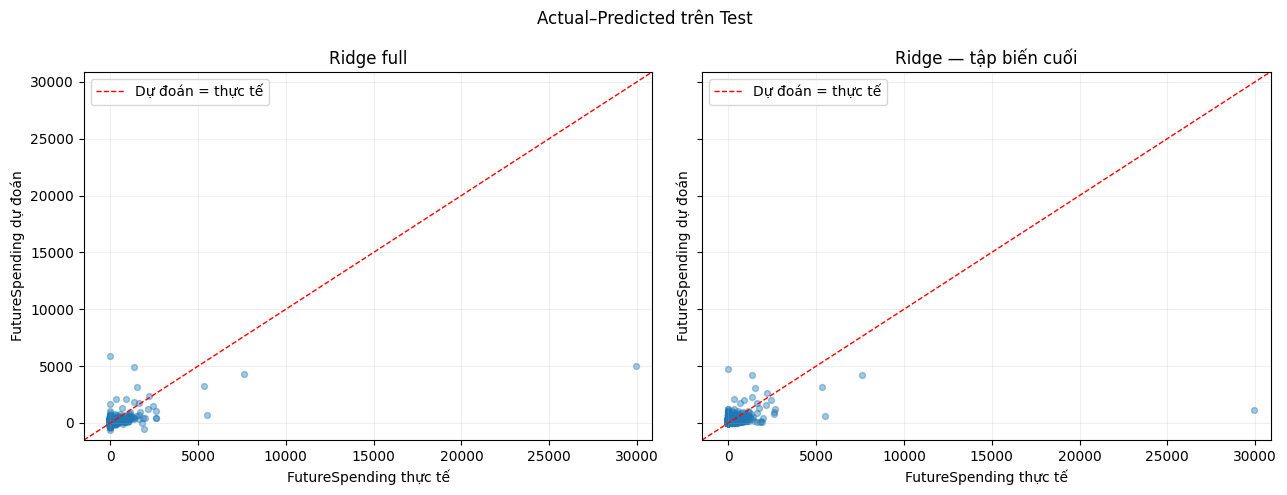

In [236]:
plot_models = ["Ridge full", final_model_name]

plot_values = test_predictions[
    ["Actual"] + plot_models
].to_numpy()

lower = min(0.0, float(plot_values.min()))
upper = float(plot_values.max())
padding = 0.03 * max(upper - lower, 1.0)
limits = (lower - padding, upper + padding)

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(axes, plot_models):
    ax.scatter(
        test_predictions["Actual"],
        test_predictions[model_name],
        alpha=0.4,
        s=18
    )

    ax.plot(
        limits, limits,
        linestyle="--",
        color="red",
        linewidth=1,
        label="Dự đoán = thực tế"
    )

    ax.set(
        title=model_name,
        xlabel="FutureSpending thực tế",
        ylabel="FutureSpending dự đoán",
        xlim=limits,
        ylim=limits
    )

    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle("Actual–Predicted trên Test")
plt.tight_layout()
plt.show()

MAE và RMSE trên Test đều thấp hơn kết quả CV ở cả bốn mô hình. Thứ tự theo MAE được giữ nguyên: Dummy median, Ridge dùng tập biến cuối, Ridge full và Dummy mean. Điều này cho thấy kết luận so sánh theo tiêu chí chính nhất quán giữa CV và Test trong thiết lập hiện tại.

Tuy nhiên, thứ tự theo RMSE và R² giữa hai mô hình Ridge thay đổi: mô hình cuối tốt hơn Ridge full trong CV nhưng kém hơn trên Test. R² của mô hình cuối giảm từ 0,4295 xuống 0,1092, cho thấy lợi ích quan sát được trong CV chưa được duy trì đồng đều trên Test.

Biểu đồ Actual–Predicted cho thấy cả hai mô hình Ridge dự đoán thấp hơn thực tế ở một số khách hàng có chi tiêu lớn. Với khách hàng có giá trị thực tế gần 30.000, Ridge full dự đoán khoảng 5.000, còn mô hình cuối chỉ khoảng 1.000. Sai số lớn tại các trường hợp này phù hợp với sự suy giảm RMSE của mô hình cuối so với Ridge full.

Chênh lệch CV–Test có thể chịu ảnh hưởng của phân phối target, các giá trị cực trị và cách chia dữ liệu; chưa đủ để kết luận overfitting. Tập Test cũng đã được xem trong các bước phân tích trước, nên kết quả cần được diễn giải cùng giới hạn này. Không điều chỉnh lại phương án hoặc cấu hình từ các kết quả Test.

## 4.Phân tích sai số

Phân tích nhóm target bằng 0/lớn hơn 0, dự đoán âm, residual và các trường hợp sai số lớn

### 4.1. Sai số theo nhóm khách hàng

Tách Test thành hai nhóm FutureSpending = 0 và FutureSpending > 0, sau đó tính MAE và RMSE cho từng mô hình. MAE toàn bộ là trung bình có trọng số theo số khách hàng của hai nhóm, nên có thể che khuất sai số cao ở nhóm ít khách hàng hơn.

In [237]:
actual = test_predictions["Actual"]

assert actual.ge(0).all()
assert test_predictions.index.equals(y_test.index)

customer_groups = {
    "FutureSpending = 0": actual.eq(0),
    "FutureSpending > 0": actual.gt(0)
}

group_error_rows = []

for group_name, mask in customer_groups.items():
    n_group = int(mask.sum())

    for model_name in verification_models:
        group_error_rows.append({
            "Nhóm": group_name,
            "Mô hình": model_name,
            "Số khách hàng": n_group,
            "Tỷ lệ Test (%)": 100 * n_group / len(actual),
            "MAE": (
                mean_absolute_error(
                    actual.loc[mask],
                    test_predictions.loc[mask, model_name]
                )
                if n_group else np.nan
            ),
            "RMSE": (
                root_mean_squared_error(
                    actual.loc[mask],
                    test_predictions.loc[mask, model_name]
                )
                if n_group else np.nan
            )
        })

group_error_metrics = pd.DataFrame(group_error_rows)

display(group_error_metrics.round(4))

# Kiểm tra MAE toàn bộ bằng trung bình có trọng số của hai nhóm
weighted_group_mae = (
    group_error_metrics.assign(
        weighted_error=lambda df: df["Số khách hàng"] * df["MAE"]
    )
    .groupby("Mô hình")["weighted_error"]
    .sum()
    / len(actual)
)

overall_mae = test_metrics.set_index("Mô hình")["MAE"]

np.testing.assert_allclose(
    weighted_group_mae.loc[overall_mae.index].to_numpy(),
    overall_mae.to_numpy(),
    rtol=1e-10,
    atol=1e-10
)

print("Đối chiếu MAE toàn bộ với MAE theo nhóm: ĐẠT.")

,Nhóm,Mô hình,Số khách hàng,Tỷ lệ Test (%),MAE,RMSE
0,FutureSpending = 0,Dummy mean,862,75.6804,232.2050,232.2050
1,FutureSpending = 0,Dummy median,862,75.6804,0.0000,0.0000
2,FutureSpending = 0,Ridge full,862,75.6804,177.8737,295.8357
3,FutureSpending = 0,Ridge — tập biến cuối,862,75.6804,135.4345,258.9939
4,FutureSpending > 0,Dummy mean,277,24.3196,489.1874,1969.2150
5,FutureSpending > 0,Dummy median,277,24.3196,664.7641,2032.8826
6,FutureSpending > 0,Ridge full,277,24.3196,431.3152,1631.1127
7,FutureSpending > 0,Ridge — tập biến cuối,277,24.3196,445.0831,1837.6089


Đối chiếu MAE toàn bộ với MAE theo nhóm: ĐẠT.


Nhóm FutureSpending = 0 gồm 862 khách hàng, chiếm 75,68% Test. Dummy median dự đoán bằng 0 nên không có sai số ở nhóm này, góp phần giải thích vì sao mô hình đạt MAE toàn bộ thấp nhất.

So với Ridge full, mô hình cuối giảm MAE ở nhóm không phát sinh chi tiêu từ 177,8737 xuống 135,4345. Tuy nhiên, ở nhóm có chi tiêu, MAE tăng từ 431,3152 lên 445,0831 và RMSE tăng từ 1631,1127 lên 1837,6089. Vì nhóm không phát sinh chi tiêu chiếm đa số, MAE toàn bộ vẫn giảm dù chất lượng dự đoán ở nhóm có chi tiêu suy giảm.

Ridge full đạt MAE và RMSE thấp nhất trong bốn mô hình ở nhóm có chi tiêu. Kết quả cho thấy cần xem xét sai số theo nhóm bên cạnh chỉ số toàn bộ để đánh giá khả năng dự đoán khách hàng thực sự phát sinh mua hàng.

### 4.2. Xu hướng sai lệch và dự đoán âm

Quy ước residual = giá trị thực tế − giá trị dự đoán: residual dương thể hiện dự đoán thấp hơn thực tế, residual âm thể hiện dự đoán cao hơn thực tế. Phân tích residual và tỷ lệ dự đoán âm của hai mô hình Ridge; giữ nguyên dự đoán khi đánh giá vì Ridge không ràng buộc đầu ra không âm.

In [238]:
ridge_models = ["Ridge full", final_model_name]

# Bảng riêng để dùng tiếp tại D.4.3
error_details = {}
residual_summary_rows = []

for model_name in ridge_models:
    prediction = test_predictions[model_name]
    residual = actual - prediction

    details = pd.DataFrame({
        "Actual": actual,
        "Predicted": prediction,
        "Residual": residual,
        "Absolute_error": residual.abs(),
        "Squared_error": residual ** 2
    })

    error_details[model_name] = details

    residual_summary_rows.append({
        "Mô hình": model_name,
        "Residual trung bình": residual.mean(),
        "Residual trung vị": residual.median(),
        "Số dự đoán âm": int(prediction.lt(0).sum()),
        "Tỷ lệ dự đoán âm (%)": 100 * prediction.lt(0).mean(),
        "Dự đoán nhỏ nhất": prediction.min()
    })

residual_summary = pd.DataFrame(residual_summary_rows)

display(residual_summary.round(4))

,Mô hình,Residual trung bình,Residual trung vị,Số dự đoán âm,Tỷ lệ dự đoán âm (%),Dự đoán nhỏ nhất
0,Ridge full,-34.3091,-93.5846,172,15.1010,-599.9928
1,Ridge — tập biến cuối,-33.6842,-61.5945,85,7.4627,-31.3711


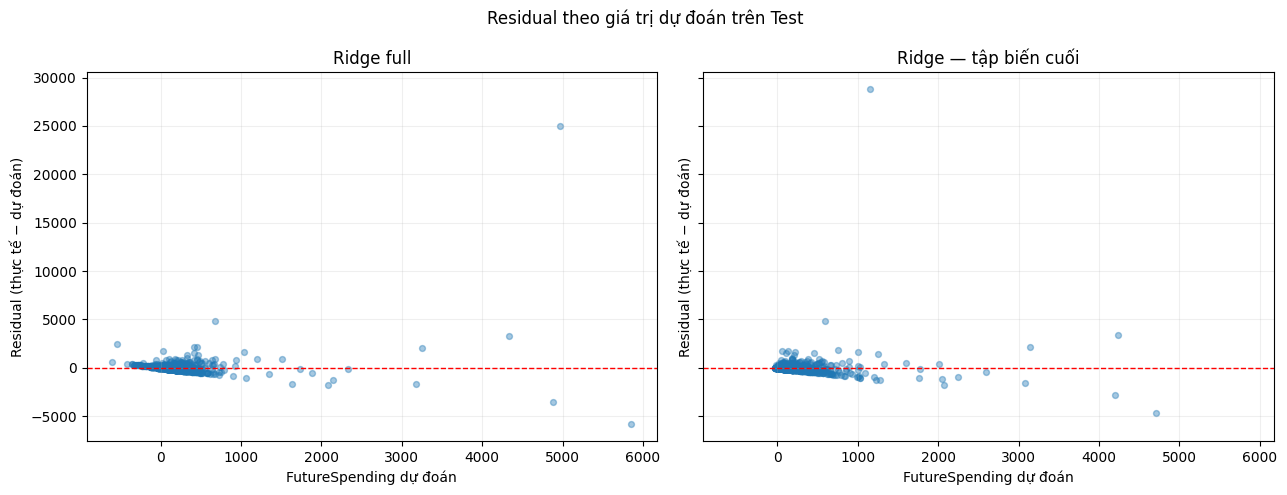

In [239]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True
)

for ax, model_name in zip(axes, ridge_models):
    details = error_details[model_name]

    ax.scatter(
        details["Predicted"],
        details["Residual"],
        alpha=0.4,
        s=18
    )

    ax.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=1
    )

    ax.set(
        title=model_name,
        xlabel="FutureSpending dự đoán",
        ylabel="Residual (thực tế − dự đoán)"
    )
    ax.grid(alpha=0.2)

fig.suptitle("Residual theo giá trị dự đoán trên Test")
plt.tight_layout()
plt.show()

Với residual = thực tế − dự đoán, cả hai mô hình có residual trung bình và trung vị âm, thể hiện xu hướng dự đoán cao hơn thực tế xét theo các thống kê này. Mô hình cuối có residual trung vị gần 0 hơn Ridge full, nhưng vẫn xuất hiện một số residual dương rất lớn do dự đoán thấp ở khách hàng chi tiêu cao.

Mô hình cuối có 85 dự đoán âm, chiếm 7,46%, thấp hơn Ridge full với 172 trường hợp, chiếm 15,10%. Giá trị dự đoán nhỏ nhất lần lượt là −31,3711 và −599,9928. Việc rút gọn đặc trưng làm giảm số dự đoán âm trong thực nghiệm này nhưng chưa bảo đảm đầu ra phù hợp với target không âm.

Biểu đồ cho thấy residual chưa phân bố cân đối quanh 0 và có các sai số lớn ở cả hai chiều. Giữ nguyên dự đoán để báo cáo; việc đưa dự đoán âm về 0, nếu khảo sát, cần được trình bày thành phương án hậu xử lý riêng.

### 4.3. Các trường hợp sai số lớn

Với mỗi mô hình Ridge, liệt kê 10 khách hàng có sai số tuyệt đối lớn nhất và tính tỷ trọng squared error của nhóm này trong tổng squared error trên Test. Nhóm 10 trường hợp được xác định riêng cho từng mô hình và chỉ phục vụ phân tích, không dùng để loại dữ liệu hoặc điều chỉnh kết quả đánh giá.

In [240]:
# id_test đã được kiểm tra tương ứng với X_test và y_test tại D.1
test_customer_ids = np.asarray(id_test).reshape(-1)
assert len(test_customer_ids) == len(test_predictions)

TOP_N_ERRORS = min(10, len(test_predictions))

largest_error_tables = {}
error_concentration_rows = []

for model_name in ridge_models:
    details = error_details[model_name].copy()
    details.insert(0, "Customer ID", test_customer_ids)

    top_errors = details.nlargest(
        TOP_N_ERRORS,
        "Absolute_error"
    ).copy()

    total_squared_error = details["Squared_error"].sum()
    total_absolute_error = details["Absolute_error"].sum()

    squared_error_share = (
        100 * top_errors["Squared_error"].sum() / total_squared_error
        if total_squared_error > 0 else np.nan
    )

    absolute_error_share = (
        100 * top_errors["Absolute_error"].sum() / total_absolute_error
        if total_absolute_error > 0 else np.nan
    )

    largest_error_tables[model_name] = top_errors

    error_concentration_rows.append({
        "Mô hình": model_name,
        "Số trường hợp lớn nhất": TOP_N_ERRORS,
        "Tỷ lệ số khách hàng (%)": (
            100 * TOP_N_ERRORS / len(details)
        ),
        "Tỷ trọng absolute error (%)": absolute_error_share,
        "Tỷ trọng squared error (%)": squared_error_share
    })

    print(f"\n===== {model_name}: {TOP_N_ERRORS} SAI SỐ LỚN NHẤT =====")
    display(
        top_errors.reset_index(drop=True).round(4)
    )

error_concentration = pd.DataFrame(error_concentration_rows)

print("\n===== MỨC ĐỘ TẬP TRUNG SAI SỐ =====")
display(error_concentration.round(4))


===== Ridge full: 10 SAI SỐ LỚN NHẤT =====


,Customer ID,Actual,Predicted,Residual,Absolute_error,Squared_error
0,14096.0,29959.16,4974.7297,24984.4303,24984.4303,6.242218e+08
1,17850.0,0.00,5853.2205,-5853.2205,5853.2205,3.426019e+07
2,12433.0,5481.98,676.0519,4805.9281,4805.9281,2.309695e+07
3,16422.0,1353.50,4885.5379,-3532.0379,3532.0379,1.247529e+07
4,12931.0,7615.90,4339.4111,3276.4889,3276.4889,1.073538e+07
5,16240.0,1894.01,-544.2883,2438.2983,2438.2983,5.945298e+06
6,16126.0,2581.07,413.4533,2167.6167,2167.6167,4.698562e+06
7,13969.0,2617.06,455.2001,2161.8599,2161.8599,4.673638e+06
8,15838.0,5309.50,3249.2530,2060.2470,2060.2470,4.244618e+06
9,17377.0,316.40,2078.3601,-1761.9601,1761.9601,3.104503e+06



===== Ridge — tập biến cuối: 10 SAI SỐ LỚN NHẤT =====


,Customer ID,Actual,Predicted,Residual,Absolute_error,Squared_error
0,14096.0,29959.16,1156.2928,28802.8672,28802.8672,8.296052e+08
1,12433.0,5481.98,597.6424,4884.3376,4884.3376,2.385675e+07
2,17850.0,0.00,4715.9099,-4715.9099,4715.9099,2.223981e+07
3,12931.0,7615.90,4234.9635,3380.9365,3380.9365,1.143073e+07
4,16422.0,1353.50,4200.0083,-2846.5083,2846.5083,8.102610e+06
5,15838.0,5309.50,3148.2151,2161.2849,2161.2849,4.671152e+06
6,16126.0,2581.07,747.3872,1833.6828,1833.6828,3.362392e+06
7,16240.0,1894.01,125.5666,1768.4434,1768.4434,3.127392e+06
8,17377.0,316.40,2066.6362,-1750.2362,1750.2362,3.063327e+06
9,14418.0,1786.81,57.7328,1729.0772,1729.0772,2.989708e+06



===== MỨC ĐỘ TẬP TRUNG SAI SỐ =====


,Mô hình,Số trường hợp lớn nhất,Tỷ lệ số khách hàng (%),Tỷ trọng absolute error (%),Tỷ trọng squared error (%)
0,Ridge full,10,0.878,19.4435,89.5433
1,Ridge — tập biến cuối,10,0.878,22.4442,91.8699


Mười trường hợp có sai số tuyệt đối lớn nhất chỉ chiếm khoảng 0,88% khách hàng Test nhưng đóng góp 89,54% tổng squared error của Ridge full và 91,87% của mô hình cuối. Tỷ trọng trong tổng absolute error thấp hơn, lần lượt là 19,44% và 22,44%, cho thấy RMSE chịu ảnh hưởng mạnh hơn MAE từ một số sai số lớn.

Khách hàng 14096 có FutureSpending thực tế là 29.959,16, trong khi Ridge full dự đoán 4.974,7297 và mô hình cuối dự đoán 1.156,2928. Trường hợp này minh họa hạn chế dự đoán mức chi tiêu cao, đặc biệt ở mô hình cuối. Các sai số lớn cũng bao gồm dự đoán cao ở khách hàng không phát sinh chi tiêu, như khách hàng 17850.

Kết quả giúp giải thích vì sao mô hình cuối có MAE toàn bộ thấp hơn Ridge full nhưng RMSE cao hơn: cải thiện ở nhiều khách hàng không bù được ảnh hưởng của một số sai số rất lớn khi bình phương. Các trường hợp này được giữ nguyên trong đánh giá, không bị loại chỉ vì có sai số lớn.

## 5.Đánh giá hiệu quả Feature Selection và diễn giải đặc trưng

Đối chiếu mức rút gọn đặc trưng với chất lượng dự đoán trên Test, sau đó diễn giải các khía cạnh hành vi được giữ lại trong tập biến cuối. Kết quả thời gian lựa chọn và độ ổn định được tham chiếu từ phần C, không thực hiện lại thí nghiệm.

In [241]:
# Tái sử dụng kết quả Test tại D.3
metrics_lookup = test_metrics.set_index("Mô hình")

full_feature_count = len(
    verification_models["Ridge full"]["features"]
)
final_feature_count = len(verification_features)

full_metrics = metrics_lookup.loc["Ridge full"]

fs_effectiveness_rows = []

for model_name, feature_count in [
    ("Ridge full", full_feature_count),
    (final_model_name, final_feature_count)
]:
    row = metrics_lookup.loc[model_name]

    fs_effectiveness_rows.append({
        "Mô hình": model_name,
        "Số đặc trưng": feature_count,
        "Rút gọn (%)": (
            100 * (1 - feature_count / full_feature_count)
        ),
        "MAE": row["MAE"],
        "RMSE": row["RMSE"],
        "R2": row["R2"],
        "Thay đổi MAE (%)": (
            100 * (row["MAE"] / full_metrics["MAE"] - 1)
            if full_metrics["MAE"] != 0 else np.nan
        ),
        "Thay đổi RMSE (%)": (
            100 * (row["RMSE"] / full_metrics["RMSE"] - 1)
            if full_metrics["RMSE"] != 0 else np.nan
        ),
        "Chênh lệch R2": row["R2"] - full_metrics["R2"]
    })

fs_effectiveness = pd.DataFrame(fs_effectiveness_rows)

print("===== HIỆU QUẢ RÚT GỌN ĐẶC TRƯNG TRÊN TEST =====")
display(fs_effectiveness.round(4))

print("Các mức thay đổi lấy Ridge full làm đối chứng.")
print("MAE/RMSE: thay đổi âm là cải thiện.")
print("R²: chênh lệch dương là cải thiện.")

===== HIỆU QUẢ RÚT GỌN ĐẶC TRƯNG TRÊN TEST =====


,Mô hình,Số đặc trưng,Rút gọn (%),MAE,RMSE,R2,Thay đổi MAE (%),Thay đổi RMSE (%),Chênh lệch R2
0,Ridge full,14,0.0000,239.5096,844.5495,0.2714,0.000,0.0000,0.0000
1,Ridge — tập biến cuối,4,71.4286,210.7397,933.8040,0.1092,-12.012,10.5683,-0.1621


Các mức thay đổi lấy Ridge full làm đối chứng.
MAE/RMSE: thay đổi âm là cải thiện.
R²: chênh lệch dương là cải thiện.


In [242]:
feature_descriptions = {
    "Frequency": {
        "Nhóm": "RFM",
        "Ý nghĩa nghiệp vụ": (
            "Số hóa đơn mua hàng trong Observation Window; "
            "phản ánh mức độ thường xuyên mua hàng."
        )
    },
    "Monetary": {
        "Nhóm": "RFM",
        "Ý nghĩa nghiệp vụ": (
            "Tổng giá trị mua sản phẩm hợp lệ trong Observation Window; "
            "phản ánh quy mô chi tiêu lịch sử."
        )
    },
    "Recency": {
        "Nhóm": "RFM",
        "Ý nghĩa nghiệp vụ": (
            "Khoảng thời gian từ lần mua gần nhất đến cutoff; "
            "phản ánh mức độ gần đây của hoạt động mua hàng."
        )
    },
    "AverageInterpurchaseTime": {
        "Nhóm": "Temporal",
        "Ý nghĩa nghiệp vụ": (
            "Khoảng thời gian trung bình giữa các lần mua; "
            "phản ánh nhịp mua hàng. Không xác định khi khách hàng "
            "có dưới hai lần mua và được xử lý bằng imputation."
        )
    }
}

missing_descriptions = (
    set(verification_features) - set(feature_descriptions)
)

assert not missing_descriptions, (
    f"Cần bổ sung diễn giải cho: {sorted(missing_descriptions)}"
)

final_feature_interpretation = pd.DataFrame([
    {
        "Đặc trưng": feature,
        **feature_descriptions[feature]
    }
    for feature in verification_features
])

print("===== Ý NGHĨA NGHIỆP VỤ CỦA TẬP BIẾN CUỐI =====")

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_columns", None
):
    display(final_feature_interpretation)

===== Ý NGHĨA NGHIỆP VỤ CỦA TẬP BIẾN CUỐI =====


,Đặc trưng,Nhóm,Ý nghĩa nghiệp vụ
0,Frequency,RFM,Số hóa đơn mua hàng trong Observation Window; phản ánh mức độ thường xuyên mua hàng.
1,Monetary,RFM,Tổng giá trị mua sản phẩm hợp lệ trong Observation Window; phản ánh quy mô chi tiêu lịch sử.
2,Recency,RFM,Khoảng thời gian từ lần mua gần nhất đến cutoff; phản ánh mức độ gần đây của hoạt động mua hàng.
3,AverageInterpurchaseTime,Temporal,Khoảng thời gian trung bình giữa các lần mua; phản ánh nhịp mua hàng. Không xác định khi khách hàng có dưới hai lần mua và được xử lý bằng imputation.


Tập đặc trưng được rút gọn từ 14 xuống 4 biến, tương ứng giảm 71,43%. Trên Test, MAE giảm từ 239,5096 xuống 210,7397, tương đương cải thiện 12,01% so với Ridge full. Tuy nhiên, RMSE tăng 10,57% và R² giảm từ 0,2714 xuống 0,1092. Vì vậy, phương án rút gọn cải thiện tiêu chí chính MAE nhưng không duy trì chất lượng đồng đều trên cả ba chỉ số.

Tập biến cuối giữ lại ba khía cạnh RFM: mức độ thường xuyên mua hàng (Frequency), quy mô chi tiêu lịch sử (Monetary) và thời gian kể từ lần mua gần nhất (Recency), cùng nhịp mua hàng (AverageInterpurchaseTime). Không có biến thuộc nhóm Behavioral được chọn ở lần fit cuối. Điều này không có nghĩa các biến bị loại không có giá trị nghiệp vụ; kết quả lựa chọn phụ thuộc dữ liệu, mô hình và tiêu chí đang sử dụng.

Phân tích tại D.4 cho thấy lợi ích về MAE tập trung ở nhóm không phát sinh chi tiêu, trong khi sai số ở nhóm có chi tiêu tăng so với Ridge full. Mô hình cuối vẫn chưa vượt Dummy median về MAE toàn bộ. Do đó, độ gọn đi kèm đánh đổi về khả năng dự đoán các trường hợp chi tiêu lớn.

Kết quả tại C.6–C.7 bổ sung góc nhìn về chi phí và độ ổn định: Hybrid có thời gian lựa chọn thấp hơn SFS trong lần đo được báo cáo và Jaccard trung bình cao hơn (0,8400 so với 0,5943). Đây là so sánh Hybrid với SFS trong CV trên Train, khác với phép so sánh hai mô hình Ridge trên Test tại mục này.

Phương án cuối thể hiện lợi ích về độ gọn và MAE so với Ridge full trong thực nghiệm hiện tại, nhưng chưa đủ cơ sở để khẳng định là phương án dự đoán tốt nhất hoặc phù hợp triển khai thực tế.

## 6.Kết luận kiểm chứng và hướng phát triển



### Kết quả đạt được và quyết định cuối cùng

Nghiên cứu chốt Hybrid MI → SFS với m = 7, k = 4 và Ridge alpha = 1,0 làm phương án cuối theo quy tắc đánh đổi tại C.8. Tập biến được chọn gồm Frequency, Monetary, Recency và AverageInterpurchaseTime, giảm từ 14 xuống 4 biến, tương ứng 71,43%. Mô hình đã được fit trên Train và lưu tại `ket_qua_feature_selection/final_feature_selection_ridge.joblib`.

Quyết định này dựa trên kết quả CV trên Train: so với SFS, Hybrid có MAE tăng khoảng 0,2451%, trong khi thời gian lựa chọn giảm 48,18% trong lần đo được báo cáo và Jaccard trung bình tăng từ 0,5943 lên 0,8400. Phương án đáp ứng ba ngưỡng tại C.8: MAE tăng không quá 0,5%, thời gian giảm ít nhất 20% và Jaccard tăng ít nhất 0,15.

Kiểm chứng trên Test cho thấy mô hình bốn biến đạt MAE = 210,7397, cải thiện 12,01% so với Ridge full. Tuy nhiên, RMSE tăng từ 844,5495 lên 933,8040 và R² giảm từ 0,2714 xuống 0,1092. Vì vậy, rút gọn đặc trưng có lợi theo tiêu chí chính MAE nhưng làm giảm chất lượng xét theo RMSE và R².

Lợi ích về MAE chủ yếu đến từ nhóm không phát sinh chi tiêu, chiếm 75,68% Test: MAE giảm từ 177,8737 xuống 135,4345. Với nhóm có chi tiêu, MAE tăng từ 431,3152 lên 445,0831. Do đó, chưa có bằng chứng cho thấy tập biến rút gọn dự đoán tốt hơn đối với khách hàng thực sự phát sinh mua hàng.

Theo MAE, Dummy median vẫn tốt nhất trong bốn mô hình kiểm chứng, đạt 161,6678. Nghiên cứu vì vậy giữ Hybrid làm phương án Feature Selection cuối cùng, nhưng không kết luận đây là mô hình dự đoán tốt nhất. Đóng góp đã đạt là xây dựng và kiểm chứng được một quy trình giảm số biến, giảm thời gian lựa chọn so với SFS và cải thiện MAE so với Ridge full, đồng thời xác định rõ các đánh đổi của phương án.

### Giới hạn ảnh hưởng trực tiếp đến kết luận

Kết quả RMSE bị chi phối mạnh bởi một số trường hợp: 10 khách hàng có sai số lớn nhất đóng góp 91,87% tổng squared error của mô hình cuối. Mô hình cũng tạo ra 85 dự đoán âm, chiếm 7,46% Test. Hai kết quả này cho thấy phương án hiện tại còn hạn chế khi dự đoán mức chi tiêu lớn và chưa bảo đảm đầu ra không âm.

Kết luận chỉ áp dụng cho cutoff, cách chia dữ liệu và cấu hình đã khảo sát. Cấu hình được lựa chọn qua CV, còn Test đã được xem trong các bước phân tích trước; do đó, kết quả hiện tại chưa phải bằng chứng kiểm chứng độc lập trên một giai đoạn mới.

### Hướng phát triển ưu tiên

1. **Kiểm chứng lại phương án đã chốt trên giai đoạn mới:** giữ nguyên quy trình và cấu hình, đánh giá qua nhiều cutoff; bảo đảm cửa sổ target của dữ liệu huấn luyện kết thúc trước giai đoạn kiểm chứng. Báo cáo riêng sai số ở nhóm có và không phát sinh chi tiêu.

2. **Giải quyết sự khác biệt giữa hai nhóm khách hàng:** khảo sát mô hình hai giai đoạn gồm dự đoán khả năng mua và dự đoán mức chi tiêu khi có mua. Mục tiêu là cải thiện nhóm có chi tiêu mà không làm tăng mạnh sai số ở nhóm còn lại.

3. **Xử lý đầu ra và sai số lớn bằng phương án định trước:** khảo sát mô hình có đầu ra không âm hoặc hậu xử lý trên Train/CV, sau đó đánh giá một lần trên dữ liệu mới. Giữ nguyên các kết quả Test hiện tại làm mốc đối chiếu.